# Bank Marketing: Data Preparation, Evidence and Model Behaviour
## CA6003 独立完成 · 2026-10-16

**研究问题：** 在本次营销联系前，现有客户背景及联系历史能在多大程度上帮助预测定期存款订购？数据准备能否让同一种简单模型表现更可靠？

**核心发现：** 系统处理初版 B 并未优于最少处理 A；标准化 A 的验证表现略有改善，但跨期表现仍弱。
后续发现，联系历史比单独个人背景更有预测价值；重采样、提高历史特征权重、概率校准和温和时间加权均未带来一致的全面提升。
删除贷款两项只有小幅开发集收益。工作重点是解释这些结果，以及保留失败对照，而非追逐最高准确率。

**阅读路线：** 1 问题与数据 → 2 划分与质量 → 3 关键 EDA → 4 编码决策 → 5 A/B 核心实验 →
6 已完成原测试 → 7 后续实验演变 → 8 联系版解释 → 9 不平衡与校准 → 10 最后对照 → 11 结论与声明。
扩展算法只在附录记录，不作为课程“基本可解释模型”主证据。

**只需本 Notebook 和原始 `bank-additional-full.csv`。** 不需要 JSON、历史结果CSV、模型文件或外部Python脚本。
本地已完成的扩展实验在相应章节以正文表格保存；这些表格是已核验的历史结果，不冒充本次Run All重新拟合。

### 依赖与运行方式

推荐64位Python 3.11，在用于Jupyter的同一个环境安装：

```bash
python -m pip install numpy pandas scipy scikit-learn matplotlib ipython threadpoolctl jupyterlab
python -m jupyterlab
```

把 `bank-additional-full.csv` 与本文件放在一起，然后选择内核并 **Restart Kernel → Run All**。
也兼容原来的 `bank-additional/bank-additional-full.csv` 相对路径。已验证的环境版本会在首个代码单元输出；跨版本可能有浮点差异。

- **可运行部分：** 从CSV读取前35,009行，重新完成train/val EDA、7个A/B候选及1个联系版LR、关键图和完整分类指标。
- **已完成扩展实验：** 利用本地已有预测补算后写入正文。所有候选、窗口、种子及原阈值规则可展开查看；不需要读外部结果文件。
- **历史test：** 只保存此前测试预测复算的结果；本Notebook不新增test预测，不用test选择阈值。
- 所有数据驱动预处理只fit train；模型输入排除duration。打开 `SHOW_ALL_20_FIELDS` 可从原始CSV重画全部20字段的分组图。


In [1]:
from pathlib import Path
import warnings, platform
import numpy as np
import pandas as pd
import scipy, sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning

# Place the original CSV beside this notebook, or keep its bank-additional/ folder.
DATA_PATH = next((p for p in [Path('bank-additional-full.csv'),
                             Path('bank-additional/bank-additional-full.csv')] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('请将原始 bank-additional-full.csv 与 Notebook 放在一起。')
SHOW_ALL_20_FIELDS = False

def show(frame, digits=4):
    renamed = frame.rename(columns={'roc_auc':'ROC-AUC','average_precision':'AP',
        'log_loss':'Log loss','brier':'Brier','accuracy':'Accuracy',
        'precision':'Precision','recall':'Recall','f1':'F1'})
    display(renamed.style.format(precision=digits, na_rep='—').hide(axis='index'))

plt.rcParams.update({'figure.dpi':105, 'savefig.dpi':120, 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
COLORS = {'train':'#3478A8', 'val':'#D27837'}
FIGURES = []
def finish(fig, name):
    fig.tight_layout(); FIGURES.append((name, fig)); plt.show(); plt.close(fig)

print('Python',platform.python_version(),'| NumPy',np.__version__,
      '| pandas',pd.__version__,'| SciPy',scipy.__version__,'| sklearn',sklearn.__version__)


Python 3.11.9 | NumPy 2.4.4 | pandas 3.0.5 | SciPy 1.17.1 | sklearn 1.9.0


## 1. Problem, provenance and governance / 问题与治理

数据来自 [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)，
Moro, Rita & Cortez，DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306)，使用其中
`bank-additional-full.csv`：41,188条记录、20个输入字段和二分类目标 `y`。
字段语义依据UCI原始数据字典；使用许可按 UCI 的 CC BY 4.0 标注来源。

**预测时点与单位。** 一条记录对应一次营销记录，并非已验证独立的唯一客户。
`duration` 只有通话结束后可知，排除于所有拨号前模型。`campaign` 包含本次联系，
联系版假设当前尝试次数及计划渠道在决策时可获得。没有客户ID、完整日期和标签成熟时间，
不能验证客户级隔离或真实部署可用性；宏观值的发布日期亦未核实。

| 信息块 | 字段 | 解释或边界 |
|---|---|---|
| 个人背景 | age, job, marital, education | student≠低学历；retired≠所有60岁以上；illiterate为文盲/不识字类别 |
| 信贷记录 | default, housing, loan | default指信贷违约状态；unknown是信息未知，不等于no |
| 本次联系 | contact, month, day_of_week, campaign | 渠道、日历和本轮尝试次数；可能编码活动阶段 |
| 历史联系 | pdays, previous, poutcome | 间隔特殊编码、此前活动联系次数、此前活动结果 |
| 宏观背景 | emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed | 就业变动、消费者价格指数、消费者信心、3个月Euribor、就业人数 |
| 事后信息 | duration | 仅可描述，禁止进入拨号前预测 |

原文件不修改；训练词表、尺度、样条节点只从对应训练前缀学习。保留 unknown、异常标记和重复行的处理理由。
人口属性只能支持关联预测，不能据此推断个体意愿或营销的因果收益。

## 2. Split and quality checks / 划分与质量检查

按原始行序固定70/15/15；字典说明数据按时间排列，因此该设计近似“过去预测未来”。
行号不是日期，month没有年份。**不通过重采样验证集或测试集来消除基础率差异。**
早期探索曾查看全量输入分布和三段正类率，现如实披露；下方 EDA 重新计算于 train/val。
后续模型选择依据 train/val，但已见旧test后的研究方向仍可能受其影响，不能宣称整个研究完全未受test影响。

In [2]:
# Read only the original train/validation prefix; test features are not loaded.
dev = pd.read_csv(DATA_PATH, sep=';', nrows=35009)
assert dev.shape == (35009, 21) and set(dev.y) == {'no', 'yes'}
train, val = dev.iloc[:28831].copy(), dev.iloc[28831:35009].copy()
y_train = train.y.eq('yes').astype('int8')
y_val = val.y.eq('yes').astype('int8')
X_train = train.drop(columns=['y', 'duration'])
X_val = val.drop(columns=['y', 'duration'])
split_summary = pd.DataFrame([
    ['train', '0–28830', len(train), int(y_train.sum()), y_train.mean(), 'raw development rows'],
    ['val', '28831–35008', len(val), int(y_val.sum()), y_val.mean(), 'raw development rows'],
    ['test', '35009–41187', 6179, 2376, 2376/6179, 'historically disclosed counts only']],
    columns=['split', 'row range', 'n', 'yes', 'yes rate', 'source'])
show(split_summary)
quality = pd.DataFrame({'field': dev.columns, 'dtype': dev.dtypes.astype(str).values,
    'train unique': train.nunique().values, 'train NaN': train.isna().sum().values,
    'train unknown': train.eq('unknown').sum().values})
show(quality)
print('Extra exact duplicates: train =', train.duplicated().sum(),
      '; val =', val.duplicated().sum())
print('Non-999 pdays in train:', train.pdays.ne(999).sum())

split,row range,n,yes,yes rate,source
train,0–28830,28831,1606,0.0557,raw development rows
val,28831–35008,6178,658,0.1065,raw development rows
test,35009–41187,6179,2376,0.3845,historically disclosed counts only


field,dtype,train unique,train NaN,train unknown
age,int64,63,0,0
job,str,12,0,249
marital,str,4,0,49
education,str,8,0,1183
default,str,3,0,7302
housing,str,3,0,694
loan,str,3,0,694
contact,str,2,0,0
month,str,9,0,0
day_of_week,str,5,0,0


Extra exact duplicates: train = 9 ; val = 1
Non-999 pdays in train: 53


**质量决策。** 没有NaN不等于没有缺失；字符串unknown及999需按语义处理。
当前train、val分别有9、1条额外完全重复行，缺少客户ID，不能确认它们是重复录入，因此主比较保留，
也不能据此声称客户独立。异常标记只是调查线索；高龄、零膨胀计数和跨期宏观变化可能有实际含义。
不强求每个输入正态：LR不要求输入服从正态分布；log1p用于缓和右长尾并表达递减变化，是否有用需验证。

field,eligible n,skewness,IQR low,IQR high,flagged n,flagged yes rate
age,28831,0.4058,12.0000,68.0000,41,0.4390
campaign,28831,4.5023,-2.0000,6.0000,2073,0.0405
previous,28831,5.5507,0.0000,0.0000,1002,0.0629
pdays,53,0.3041,-1.5000,10.5000,1,0.0000
euribor3m,28831,-3.7449,4.6995,5.1195,4757,0.0956


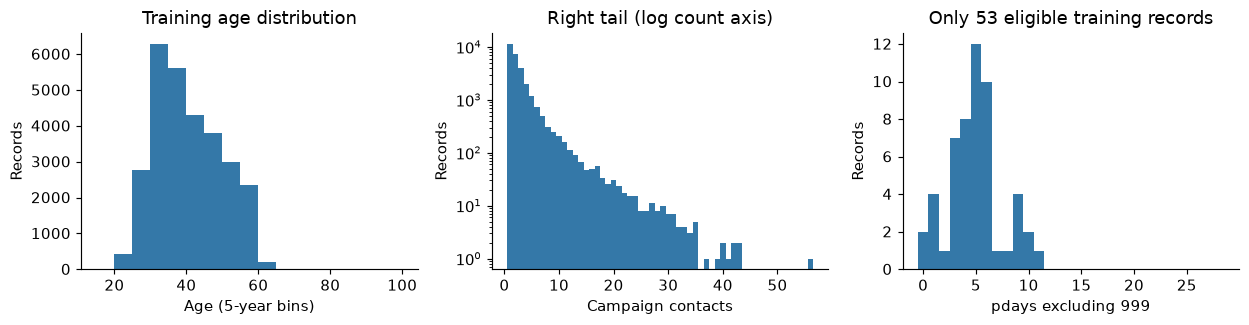

In [3]:
outliers = []
for field in ['age', 'campaign', 'previous', 'pdays', 'euribor3m']:
    x = train.loc[train.pdays.ne(999), field] if field == 'pdays' else train[field]
    q1, q3 = x.quantile([.25, .75]); lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    marked = (x < lo) | (x > hi)
    outliers.append([field, len(x), x.skew(), lo, hi, int(marked.sum()),
                     train.loc[x.index[marked], 'y'].eq('yes').mean()])
show(pd.DataFrame(outliers, columns=['field', 'eligible n', 'skewness', 'IQR low',
    'IQR high', 'flagged n', 'flagged yes rate']))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(train.age, bins=np.arange(15, 105, 5), color=COLORS['train'])
axes[0].set(xlabel='Age (5-year bins)', ylabel='Records', title='Training age distribution')
axes[1].hist(train.campaign, bins=np.arange(.5, train.campaign.max()+1.5), color=COLORS['train'])
axes[1].set(xlabel='Campaign contacts', ylabel='Records', yscale='log', title='Right tail (log count axis)')
axes[2].hist(train.loc[train.pdays.ne(999), 'pdays'], bins=np.arange(-.5, 29.5), color=COLORS['train'])
axes[2].set(xlabel='pdays excluding 999', ylabel='Records', title='Only 53 eligible training records')
finish(fig, '01_distributions')

## 3. Focused EDA / 有证据的非显然发现
### 3.1 Shared missingness can inflate association / 共同缺失改变关联

housing和loan的unknown出现在同一批记录中。下面同时计算全部类别和双已知子集的Cramér’s V，
并列出各自分母。剔除unknown会改变人群和类别维度；后一个V不能称为“校正后的真实总体关联”。

In [4]:
from scipy.stats import chi2_contingency
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    denominator = ct.to_numpy().sum() * min(ct.shape[0]-1, ct.shape[1]-1)
    return np.sqrt(chi2_contingency(ct, correction=False)[0]/denominator) if denominator else np.nan
assert train.housing.eq('unknown').equals(train.loan.eq('unknown'))
known = train.housing.ne('unknown') & train.loan.ne('unknown')
association = pd.DataFrame([
    ['housing × loan: all', len(train), cramers_v(train.housing, train.loan)],
    ['housing × loan: both known', int(known.sum()), cramers_v(train.loc[known,'housing'], train.loc[known,'loan'])]],
    columns=['comparison', 'n', 'Cramers V'])
show(association)
show(pd.crosstab(train.poutcome, train.pdays.eq(999)).rename(columns={False:'pdays != 999', True:'pdays = 999'}).reset_index())
print('previous=0 and poutcome=nonexistent agree:',
      bool(train.previous.eq(0).equals(train.poutcome.eq('nonexistent'))))

comparison,n,Cramers V
housing × loan: all,28831,0.7079
housing × loan: both known,28137,0.0486


poutcome,pdays != 999,pdays = 999
failure,3,949
nonexistent,0,27829
success,50,0


previous=0 and poutcome=nonexistent agree: True


**历史字段不能机械互换。** train中previous=0与nonexistent重合；但failure中也有大量pdays=999。
这提示这些字段的记录范围或编码语义可能不同，未证实其产生机制。
因此衍生变量命名为“pdays是否999/是否有效”，避免无依据命名为“从未联系”。

### 3.2 Rates, denominators and coverage / 比例、人数与覆盖

组内订购率回答“该组多容易订购”，组人数回答“规模多大”，yes覆盖回答“全部订购者中有多少来自该组”。
总体比例已经是各组比例按人数加权的均值，无须再对组内比例乘一次占比。
下图train/val各用自己的基线；小样本只作为线索，不能由高比例直接指定模型权重。

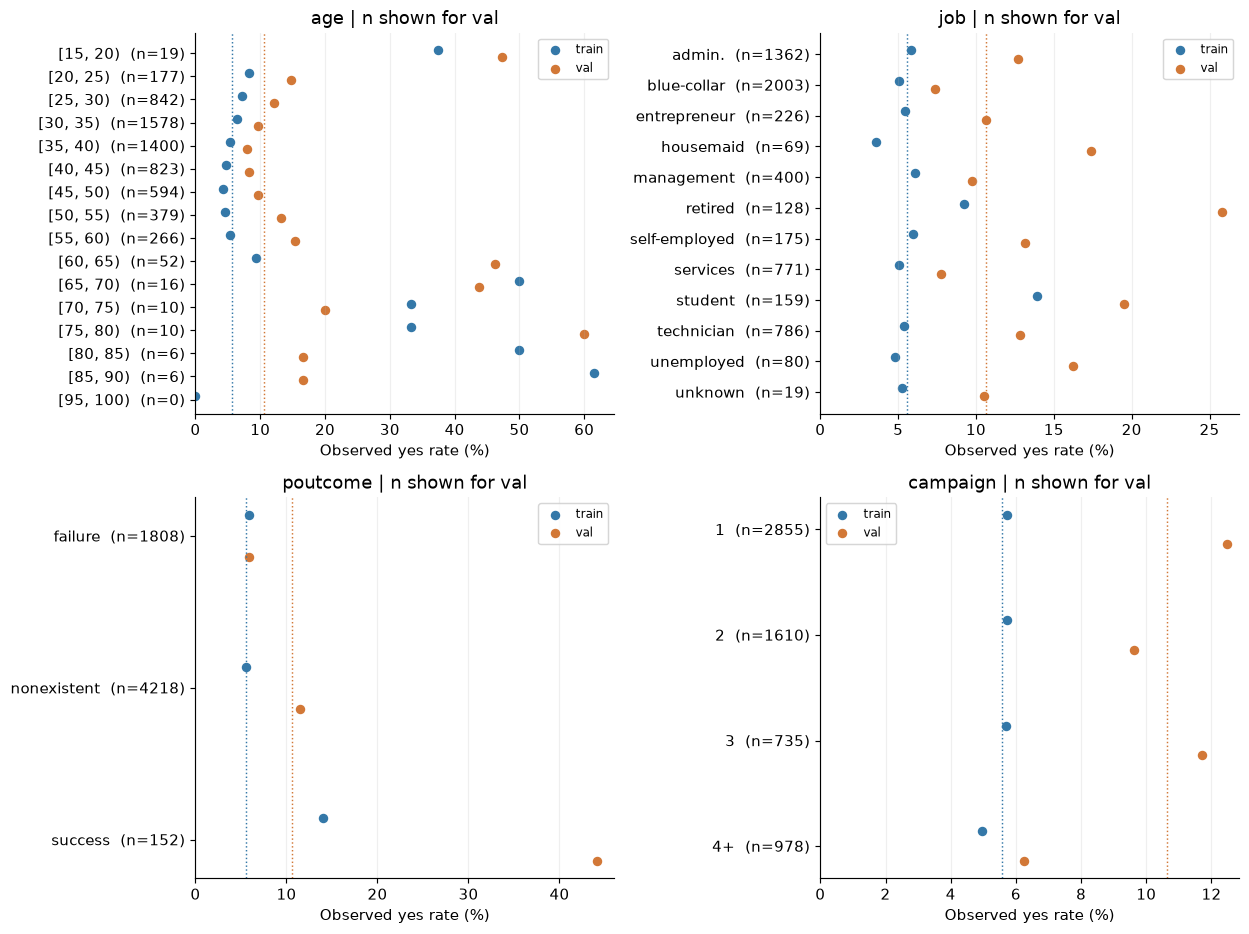

level,n,yes,rate,population share,yes coverage
failure,1808,106,0.0586,0.2927,0.1611
nonexistent,4218,485,0.1150,0.6827,0.7371
success,152,67,0.4408,0.0246,0.1018


In [5]:
def group_label(frame, field):
    if field == 'age': return pd.cut(frame.age, bins=np.arange(15, 105, 5), right=False).astype(str)
    if field == 'campaign': return frame.campaign.map(lambda x: str(x) if x < 4 else '4+')
    return frame[field].astype(str)
def grouped(frame, field):
    g = pd.DataFrame({'level': group_label(frame, field), 'yes': frame.y.eq('yes').astype(int)})
    out = g.groupby('level', sort=True).yes.agg(['size','sum','mean'])
    out.columns = ['n','yes','rate']
    out['population share'] = out.n/len(frame)
    out['yes coverage'] = out.yes/out.yes.sum()
    assert np.isclose((out.rate*out['population share']).sum(), frame.y.eq('yes').mean())
    return out
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, field in zip(axes.flat, ['age','job','poutcome','campaign']):
    gt, gv = grouped(train,field), grouped(val,field)
    levels = list(dict.fromkeys(gt.index.tolist()+gv.index.tolist()))
    if field == 'age': levels = sorted(levels, key=lambda s: int(s.split(',')[0][1:]))
    pos = np.arange(len(levels))
    for delta, label, tab in [(-.14,'train',gt),(.14,'val',gv)]:
        tmp = tab.reindex(levels)
        ax.scatter(tmp.rate*100, pos+delta, label=label, color=COLORS[label], s=30)
        ax.axvline((y_train if label=='train' else y_val).mean()*100, color=COLORS[label], ls=':', lw=1)
    labels=[f'{level}  (n={int(gv.loc[level,"n"]) if level in gv.index else 0})' for level in levels]
    ax.set(yticks=pos, yticklabels=labels, xlabel='Observed yes rate (%)', title=field+' | n shown for val')
    ax.invert_yaxis(); ax.set_xlim(left=0); ax.grid(axis='x', alpha=.2)
    ax.legend(fontsize=8, loc='best')
finish(fig, '02_group_rates')
show(grouped(val, 'poutcome').reset_index())

学生、退休及部分青年/高龄组的比例较高，但不是同一群体，不能把重叠特征当独立证据相加。
val历史success组订购率44.08%，却仅覆盖全部yes的10.18%；nonexistent组比例11.50%，覆盖73.71%。
只关注“最容易买”的小群体会限制召回。campaign的4+组两段均较低，但1/2/3并非严格单调，
只能说“联系次数较多者观察到较低订购率”，不能说多联系导致拒绝。

housing/loan单变量差异较小；default的no/unknown有差异，真实yes样本极少。
month和weekday与阶段、客户选择混在一起：train星期峰值与val不同，不能推荐某个星期打电话来保证效果。

### 3.3 Macro structure and shift / 宏观结构与跨期变化

CPI是价格指数水平，不是通胀率；CCI是消费者信心指标，不是概率。数据字典未给出基期、精确系列代码及发布时点。
train中CPI与CCI **线性相关性弱**（Pearson r≈0.0577），但不能推出统计独立或二者均无预测作用。
其他宏观列存在多重共线性；L2可稳定参数，却不消除相关或保证未来有效。

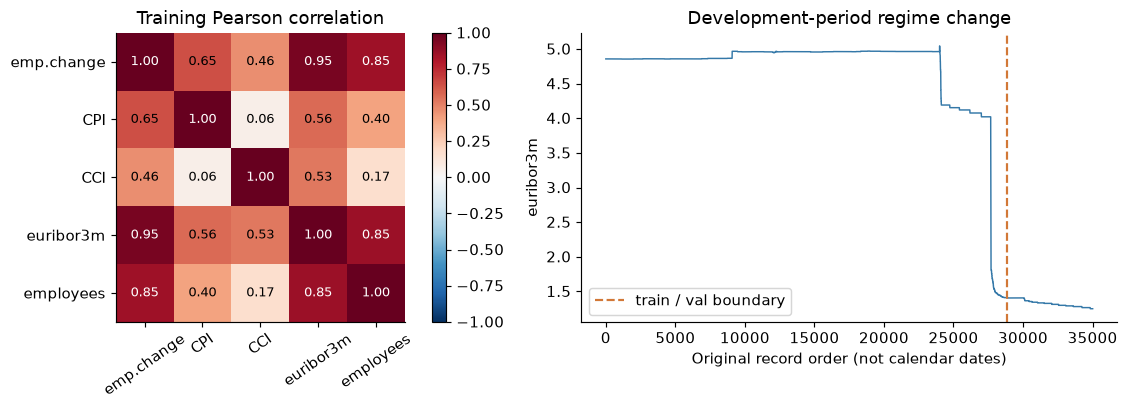

CPI–CCI Pearson r: 0.0576927123923388
Validation euribor outside train range: 6129 / 6178


In [6]:
MACRO = ['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
corr = train[MACRO].corr()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im=axes[0].imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
short=['emp.change','CPI','CCI','euribor3m','employees']
axes[0].set(xticks=range(5), xticklabels=short, yticks=range(5), yticklabels=short, title='Training Pearson correlation')
axes[0].tick_params(axis='x', rotation=35)
for i in range(5):
    for j in range(5): axes[0].text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if abs(corr.iloc[i,j])>.7 else 'black')
fig.colorbar(im, ax=axes[0], fraction=.045)
axes[1].plot(dev.index, dev.euribor3m, lw=1, color='#3478A8')
axes[1].axvline(28831, color='#D27837', ls='--', label='train / val boundary')
axes[1].set(xlabel='Original record order (not calendar dates)', ylabel='euribor3m', title='Development-period regime change')
axes[1].legend()
finish(fig, '03_macro_structure')
print('CPI–CCI Pearson r:', corr.loc['cons.price.idx','cons.conf.idx'])
print('Validation euribor outside train range:',
      (~val.euribor3m.between(train.euribor3m.min(),train.euribor3m.max())).sum(), '/', len(val))

## 4. Preparation decisions and mappings / 编码与处理决策

下表保留最初A/B设计，不因后续结果倒改理由。两个方案均排除duration，使用同一种L2逻辑回归。
B同时改变多项，只能解释总处理效果；其后单因素恢复对照负责拆解。

| 项目 | A：最少处理 | B：系统处理初版 | 理由、损失及对照 |
|---|---|---|---|
| 类别 | 完整one-hot，unknown保留 | 一般类别同A | 不给名义类别任意大小顺序 |
| 数值 | 原值 | train标准化 | 影响L2的有效惩罚；A_scaled单独检验缩放 |
| housing/loan | 分别完整one-hot | 两个yes指示+共享unknown | 必须验证两列unknown同步；不是unknown→no |
| default | no/yes/unknown | 仅unknown指示 | yes与no合并，有信息损失；B_default3恢复三类 |
| pdays | 原值含999 | 删除 | train有效记录53条；B_pdays恢复哨兵+中心化有效天数 |
| month | 保留 | 删除 | 季节与时期难分离；B_month恢复 |
| 宏观 | 五列全部保留 | CPI、CCI、euribor3m | 共线性驱动候选删减；B_macro_all恢复五列 |
| 重复/异常 | 保留 | 保留 | 未确认数据错误，不自动删除 |
| 不平衡 | 不加权 | 不加权 | 先固定基线；之后进行独立配对实验 |

**映射示例。** `(housing,loan)=(no,no)/(yes,no)/(no,yes)/(yes,yes)/(unknown,unknown)`
分别映射为`(0,0,0)/(1,0,0)/(0,1,0)/(1,1,0)/(0,0,1)`。
任一列单独unknown时报错。`default_unknown=0`表示“已知”，不是“无违约”。
B_pdays使用`is999`与`d−m_train`；999位置天数置0，指标保留差异；train无有效天数则禁用天数列。
未见类别预设为全零one-hot，不从val学习新词表。

## 5. Core experiment: same logistic model / 同模型比较

$$p_i=\sigma(\beta_0+\phi(x_i)^T\beta),\qquad
L=\sum_i[-y_i\log p_i-(1-y_i)\log(1-p_i)]+\frac{\|\beta\|_2^2}{2C}.$$

$\phi$是各方案的编码；原始变量允许经确定性转换，线性作用发生在变换后的logit空间。
本节C=1、lbfgs、tol=1e-4、L2、无类别权重、截距不惩罚；全部候选统一迭代上限，
若任一达到5000上限则全部以20000重试。截距不简单等于训练基础率的logit。

原规则以val ROC-AUC优先、AP次之、维度/名称破平局；原选择为A_scaled。
所有候选统一报告0.5及val最大F1阈值，F1平局取高阈值。
阈值只改变判类，不改变AUC/AP；同一val优化出的F1含选择乐观性。

下方代码保留完整映射与Pipeline；唯一数据驱动拟合均发生在train。

### 5.1 七个模型究竟哪里不同？

下面都是同一种L2逻辑回归，差别主要在输入表示。`features` 是**预处理后的设计矩阵列数**，不包含截距，不是原始字段数或重要因素个数。

| Model | 相对基线的建模变化 | 本次train编码后features |
|---|---|---:|
| A | 19个原始输入字段；10个类别列完整one-hot，9个数值列原尺度 | 61 |
| A_scaled | 相对A，仅把9个数值列用train均值/标准差缩放 | 61 |
| B | 以4节方案处理unknown；删除month和pdays；宏观只留CPI/CCI/euribor；数值缩放 | 44 |
| B_macro_all | 相对B，恢复emp.var.rate和nr.employed两列 | 46 |
| B_month | 相对B，恢复month；train中9个水平扩展成9列 | 53 |
| B_pdays | 相对B，增加pdays是否999和有效天数中心化两列 | 46 |
| B_default3 | 相对B，将1列default_unknown恢复为default的3列one-hot | 46 |

例如，A的10个类别字段变成52列，加9个数值列得到61；B是34个类别哑变量＋6个连续列＋4个二元列＝44。
`A_scaled` 只改变数值尺度，因此列数不变；删字段、合并编码、恢复类别或把年龄换成多列样条都会改变列数。
不同时间窗若见到的类别不同，列数也可能不同。类别和样条结点仅从各自train学习，不能用val/test补齐类别。

**公平性解释：** 同C固定了超参数，但缩放、维度和特征相关性会改变L2的有效约束，不代表各表示受到完全相同的惩罚。更多features也不等于更强的预测能力。


In [7]:
"""Bank Marketing: explicit feature mappings and reproducible train/validation experiments.
No training or test evaluation occurs at import. Notebook Section 7 owns the protocol.
"""
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning
from scipy.special import expit
from threadpoolctl import threadpool_limits

# 编码与显式列组：不拟合分类器；所有数据驱动参数只能来自train。
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

A_CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
A_NUMERIC = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
B_CATEGORICAL = ["job", "marital", "education", "contact", "day_of_week", "poutcome"]
B_CONTINUOUS = ["age", "campaign", "previous", "cons.price.idx", "cons.conf.idx", "euribor3m"]
B_BINARY = ["housing_yes", "loan_yes", "housing_loan_unknown", "default_unknown"]

def encode_target(y):
    if not y.isin(["yes", "no"]).all():
        raise ValueError("Target must contain only yes/no")
    return y.map({"no": 0, "yes": 1}).astype("int8").rename("y_binary")

def valid_pdays(d):
    days = pd.to_numeric(d["pdays"], errors="raise")
    if not np.isfinite(days.to_numpy(dtype=float)).all() or (days < 0).any():
        raise ValueError("pdays must be finite and nonnegative; 999 is the sentinel")
    return days

def learn_pdays_center(train_data):
    days = valid_pdays(train_data)
    valid = days[days.ne(999)]
    return {"center": float(valid.median()) if len(valid) else 0.0,
            "days_enabled": bool(len(valid)), "valid_count": int(len(valid)),
            "scaling": "none_after_train_median_centering"}

def encode_pdays(d, train_non999_median, days_enabled=True):
    if not np.isscalar(train_non999_median):
        raise ValueError("pdays center must be a finite scalar")
    try:
        center = float(train_non999_median)
    except (TypeError, ValueError):
        raise ValueError("pdays center must be a finite scalar") from None
    if not np.isfinite(center):
        raise ValueError("pdays center must be finite")
    days = valid_pdays(d)
    is999 = days.eq(999)
    centered = (days - center).where(~is999, 0.0)
    if not days_enabled:
        centered = pd.Series(0.0, index=d.index)
    return pd.DataFrame({"pdays_is_999": is999.astype("int8"),
                         "pdays_days_centered": centered}, index=d.index)

def prepare_b_features(d, pdays_mode="drop", pdays_center=None, days_enabled=True,
                       keep_month=False, macro_all=False, default_three=False):
    """B默认方案及明确的单因素开关；保持行索引，不修改输入，不使用y。"""
    if pdays_mode not in {"drop", "split"}:
        raise ValueError("pdays_mode must be drop or split")
    x = d.drop(columns=["y", "duration"], errors="ignore").copy()
    for col in ["housing", "loan", "default"]:
        if not x[col].isin(["yes", "no", "unknown"]).all():
            raise ValueError(f"Unexpected category in {col}")
    hu, lu = x["housing"].eq("unknown"), x["loan"].eq("unknown")
    if not hu.equals(lu):
        raise ValueError("housing/loan unknown mismatch: revise encoding explicitly")
    x["housing_yes"] = x["housing"].eq("yes").astype("int8")
    x["loan_yes"] = x["loan"].eq("yes").astype("int8")
    x["housing_loan_unknown"] = hu.astype("int8")
    drop = ["housing", "loan", "pdays"]
    if not default_three:
        x["default_unknown"] = x["default"].eq("unknown").astype("int8")
        drop.append("default")
    if not keep_month:
        drop.append("month")
    if not macro_all:
        drop.extend(["emp.var.rate", "nr.employed"])
    if pdays_mode == "split":
        x = x.join(encode_pdays(d, pdays_center, days_enabled))
    return x.drop(columns=drop)

def make_preprocessor(arm="B", pdays_mode="drop", keep_month=False, macro_all=False, default_three=False):
    """仅构造预处理器；fit时只传train。显式分组，不依赖dtype。"""
    if arm == "A":
        if pdays_mode != "drop" or keep_month or macro_all or default_three:
            raise ValueError("A uses original columns; B-only flags are invalid")
        return ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", drop=None), A_CATEGORICAL),
            ("num", "passthrough", A_NUMERIC)], remainder="drop")
    if arm != "B" or pdays_mode not in {"drop", "split"}:
        raise ValueError("Invalid arm or pdays_mode")
    categorical = B_CATEGORICAL + (["month"] if keep_month else []) + (["default"] if default_three else [])
    continuous = B_CONTINUOUS + (["emp.var.rate", "nr.employed"] if macro_all else [])
    binary = [c for c in B_BINARY if not (default_three and c == "default_unknown")]
    if pdays_mode == "split":
        binary = binary + ["pdays_is_999"]
    groups = [("cat", OneHotEncoder(handle_unknown="ignore", drop=None), categorical),
              ("num", StandardScaler(), continuous), ("binary", "passthrough", binary)]
    if pdays_mode == "split":
        groups.append(("pdays_days", "passthrough", ["pdays_days_centered"]))
    return ColumnTransformer(groups, remainder="drop")


CANDIDATES = {
    "A": {"arm": "A"},
    "A_scaled": {"arm": "A", "scale_a": True},
    "B": {"arm": "B"},
    "B_macro_all": {"arm": "B", "macro_all": True},
    "B_month": {"arm": "B", "keep_month": True},
    "B_pdays": {"arm": "B", "pdays_mode": "split"},
    "B_default3": {"arm": "B", "default_three": True},
}

class MarketingFeatures(TransformerMixin, BaseEstimator):
    """Train-only data-dependent mapping inside the saved Pipeline."""
    def __init__(self, arm="B", pdays_mode="drop", keep_month=False, macro_all=False, default_three=False):
        self.arm=arm; self.pdays_mode=pdays_mode; self.keep_month=keep_month
        self.macro_all=macro_all; self.default_three=default_three
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame) or "y" in X or "duration" in X:
            raise ValueError("Pass raw feature DataFrame without target/duration")
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.n_features_in_=X.shape[1]
        self.training_rows_=len(X)
        self.pdays_params_=learn_pdays_center(X) if self.pdays_mode=="split" else None
        self.output_columns_=self._transform(X).columns.tolist()
        return self
    def _transform(self, X):
        if self.arm=="A":
            return X.loc[:,A_CATEGORICAL+A_NUMERIC].copy()
        params=self.pdays_params_ or {"center":None,"days_enabled":True}
        return prepare_b_features(X,pdays_mode=self.pdays_mode,pdays_center=params["center"],
            days_enabled=params["days_enabled"],keep_month=self.keep_month,
            macro_all=self.macro_all,default_three=self.default_three)
    def transform(self, X):
        if not hasattr(self,"output_columns_"):
            raise ValueError("Feature builder is not fitted")
        if "y" in X or "duration" in X:
            raise ValueError("Target/duration must not enter pipeline")
        result=self._transform(X)
        if result.columns.tolist()!=self.output_columns_:
            raise ValueError("Feature order changed")
        return result
    def get_feature_names_out(self,input_features=None):
        return np.asarray(self.output_columns_,dtype=object)

def build_pipeline(spec,max_iter=5000):
    options={k:v for k,v in spec.items() if k!="scale_a"}
    pre=make_preprocessor(**options)
    if spec.get("scale_a",False):
        pre.set_params(transformers=[("cat",OneHotEncoder(handle_unknown="ignore",drop=None),A_CATEGORICAL),
                                    ("num",StandardScaler(),A_NUMERIC)])
    pre.set_params(sparse_threshold=1.0)  # same numerical design, sparse storage for serial CPU fitting
    kwargs=dict(C=1.0,solver="lbfgs",max_iter=max_iter,tol=1e-4,class_weight=None,fit_intercept=True)
    import sklearn
    version=tuple(int(v) for v in sklearn.__version__.split('.')[:2])
    kwargs.update({"l1_ratio":0.0} if version>=(1,8) else {"penalty":"l2"})
    return Pipeline([("features",MarketingFeatures(**options)),("preprocess",pre),
                     ("classifier",LogisticRegression(**kwargs))])

def probabilities(pipe, X):
    classes=pipe.named_steps["classifier"].classes_
    positive=int(np.flatnonzero(classes==1)[0])
    p=pipe.predict_proba(X)[:,positive]
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError("Invalid probabilities")
    return p

def metric_row(y,p,threshold=0.5):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    if len(y)!=len(p) or not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError("Invalid metric inputs")
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    both=len(np.unique(y))==2
    return {"n":len(y),"positive_rate":float(y.mean()),"mean_probability":float(p.mean()),
      "roc_auc":float(roc_auc_score(y,p)) if both else None,
      "average_precision":float(average_precision_score(y,p)) if both else None,
      "brier":float(brier_score_loss(y,p)),"log_loss":float(log_loss(y,p,labels=[0,1])),
      "threshold":float(threshold),"accuracy":float(accuracy_score(y,pred)),
      "precision":float(tp/(tp+fp)) if tp+fp else np.nan,
      "recall":float(recall_score(y,pred,zero_division=0)),"f1":float(f1_score(y,pred,zero_division=0)),
      "predicted_positive_rate":float(pred.mean()),"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp),
      "majority_accuracy_reference":float(max(y.mean(),1-y.mean()))}

def choose_f1_threshold(y,p):
    if len(np.unique(y))!=2:
        raise ValueError("Threshold selection requires both classes in validation")
    precision,recall,thresholds=precision_recall_curve(y,p,drop_intermediate=False)
    score=np.divide(2*precision[:-1]*recall[:-1],precision[:-1]+recall[:-1],
                    out=np.zeros_like(thresholds),where=(precision[:-1]+recall[:-1])>0)
    # Numerical equality tolerance only; not a practical-improvement threshold.
    best=np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-12))
    return float(thresholds[best[-1]])  # ascending thresholds: prefer higher among tied F1

In [8]:
# All preprocessing and fits use train only. No saved model/results are loaded.
core_models, fit_rows = {}, []
for cap in [5000, 20000]:
    core_models, fit_rows = {}, []
    for name, spec in CANDIDATES.items():
        pipe = build_pipeline(spec, max_iter=cap)
        with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); pipe.fit(X_train, y_train)
        it = int(pipe.named_steps['classifier'].n_iter_[0])
        ok = it < cap and not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        core_models[name] = pipe
        fit_rows.append({'model':name,'iterations':it,'converged':ok,
                         'features':len(pipe.named_steps['classifier'].coef_[0])})
    if all(r['converged'] for r in fit_rows): break
assert all(r['converged'] for r in fit_rows), 'Inspect convergence before interpreting results.'
show(pd.DataFrame(fit_rows))
val_prob = {name:probabilities(pipe,X_val) for name,pipe in core_models.items()}
core_rows=[]
for name, pipe in core_models.items():
    for split,xx,yy in [('train',X_train,y_train),('val',X_val,y_val)]:
        core_rows.append({'model':name,'split':split,**metric_row(yy,probabilities(pipe,xx))})
for split,yy in [('train',y_train),('val',y_val)]:
    core_rows.append({'model':'train_prior_dummy','split':split,
                     **metric_row(yy,np.full(len(yy),y_train.mean()))})
core_reference=pd.DataFrame(core_rows)
METRIC_COLUMNS=['model','roc_auc','average_precision','accuracy','precision','recall','f1',
                'log_loss','brier','tp','fp','fn','tn']
show(core_reference[core_reference.split=='val'][METRIC_COLUMNS])


model,iterations,converged,features
A,3853,True,61
A_scaled,36,True,61
B,37,True,44
B_macro_all,34,True,46
B_month,35,True,53
B_pdays,24,True,46
B_default3,27,True,46


model,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
A,0.6633,0.2015,0.8935,—,0.0000,0.0000,0.3262,0.0923,0,0,658,5520
A_scaled,0.6650,0.2094,0.8935,—,0.0000,0.0000,0.3226,0.0916,0,0,658,5520
B,0.6206,0.1591,0.8935,—,0.0000,0.0000,0.3546,0.1001,0,0,658,5520
B_macro_all,0.6231,0.1599,0.8935,—,0.0000,0.0000,0.3480,0.0980,0,0,658,5520
B_month,0.6533,0.1919,0.8935,—,0.0000,0.0000,0.3286,0.0928,0,0,658,5520
B_pdays,0.5982,0.1601,0.8907,0.2821,0.0167,0.0316,0.3583,0.1011,11,28,647,5492
B_default3,0.6055,0.1489,0.8935,—,0.0000,0.0000,0.3563,0.1005,0,0,658,5520
train_prior_dummy,0.5000,0.1065,0.8935,—,0.0000,0.0000,0.3588,0.0977,0,0,658,5520


**结果。** A的val AUC/AP为0.6633/0.2015，A_scaled为0.6650/0.2094，B为0.6206/0.1591。
A_scaled的优势很小，不声称稳定胜出；B比A更差，说明合理的清理理由不保证预测收益。
B恢复月份改善最大，但val仅包含apr/may，不能外推为月份在所有时期都有效。
同C控制超参数，不代表不同缩放、维度和参数化的有效正则强度完全等价。

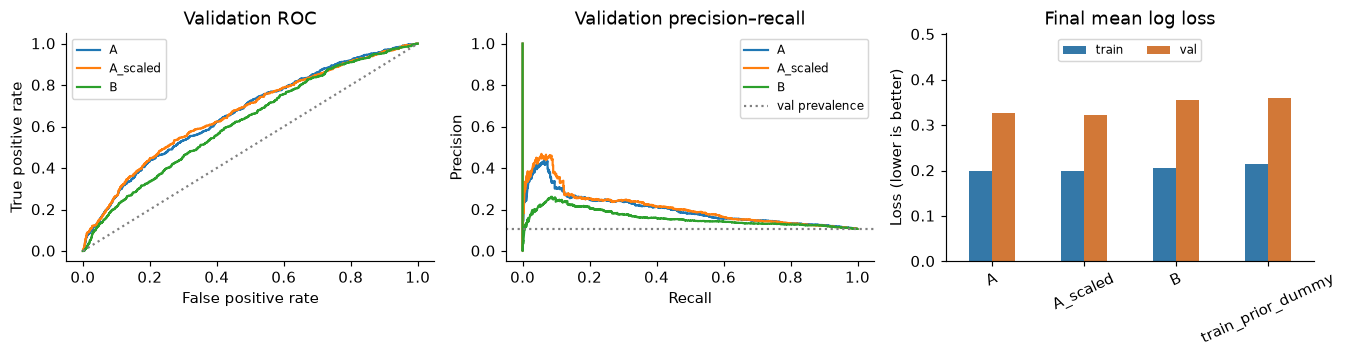

model,rule,threshold,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
A,fixed_0.5,0.5000,0.6633,0.2015,0.8935,—,0.0000,0.0000,0.3262,0.0923,0,0,658,5520
A,val_F1_selection_only,0.1510,0.6633,0.2015,0.7601,0.2061,0.4392,0.2806,0.3262,0.0923,289,1113,369,4407
A_scaled,fixed_0.5,0.5000,0.6650,0.2094,0.8935,—,0.0000,0.0000,0.3226,0.0916,0,0,658,5520
A_scaled,val_F1_selection_only,0.1284,0.6650,0.2094,0.7621,0.2104,0.4483,0.2864,0.3226,0.0916,295,1107,363,4413
B,fixed_0.5,0.5000,0.6206,0.1591,0.8935,—,0.0000,0.0000,0.3546,0.1001,0,0,658,5520
B,val_F1_selection_only,0.2161,0.6206,0.1591,0.6727,0.1542,0.4620,0.2312,0.3546,0.1001,304,1668,354,3852
B_macro_all,fixed_0.5,0.5000,0.6231,0.1599,0.8935,—,0.0000,0.0000,0.3480,0.0980,0,0,658,5520
B_macro_all,val_F1_selection_only,0.1919,0.6231,0.1599,0.6186,0.1506,0.5562,0.2370,0.3480,0.0980,366,2064,292,3456
B_month,fixed_0.5,0.5000,0.6533,0.1919,0.8935,—,0.0000,0.0000,0.3286,0.0928,0,0,658,5520
B_month,val_F1_selection_only,0.1526,0.6533,0.1919,0.7569,0.2032,0.4392,0.2779,0.3286,0.0928,289,1133,369,4387


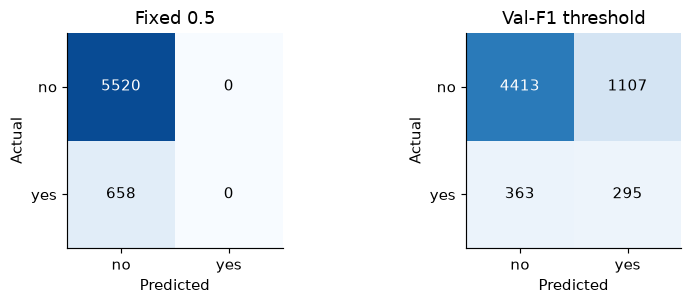

In [9]:
focus = ['A','A_scaled','B']
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for name in focus:
    p = val_prob[name]
    fpr,tpr,_=roc_curve(y_val,p); axes[0].plot(fpr,tpr,label=name)
    pp,rr,_=precision_recall_curve(y_val,p); axes[1].plot(rr,pp,label=name)
axes[0].plot([0,1],[0,1],':',color='grey')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Validation ROC')
axes[1].axhline(y_val.mean(),ls=':',color='grey',label='val prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Validation precision–recall')
loss=core_reference[core_reference.model.isin(focus+['train_prior_dummy'])].pivot(index='model',columns='split',values='log_loss').reindex(focus+['train_prior_dummy'])
loss.plot.bar(ax=axes[2],rot=25,color=[COLORS['train'],COLORS['val']])
axes[2].set(title='Final mean log loss',ylabel='Loss (lower is better)',xlabel='',ylim=(0,float(loss.max().max())*1.4))
axes[2].legend(fontsize=8,ncol=2,loc='upper center')
for ax in axes[:2]: ax.legend(fontsize=8)
finish(fig,'04_core_validation')
thresholds={name:choose_f1_threshold(y_val,p) for name,p in val_prob.items()}
selected='A_scaled'
for name in CANDIDATES:
    assert np.isclose(choose_f1_threshold(y_val,val_prob[name]),thresholds[name],atol=1e-12,rtol=0)
val_thresholds=pd.DataFrame([
    {'model':name,'rule':rule,**metric_row(y_val,p,t)}
    for name,p in val_prob.items() for rule,t in [('fixed_0.5',.5),('val_F1_selection_only',thresholds[name])]])
show(val_thresholds[['model','rule','threshold']+METRIC_COLUMNS[1:]])
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,t,title in zip(axes,[.5,thresholds[selected]],['Fixed 0.5','Val-F1 threshold']):
    cm=confusion_matrix(y_val,val_prob[selected]>=t,labels=[0,1])
    ax.imshow(cm,cmap='Blues',vmin=0,vmax=len(val));ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['no','yes'],yticklabels=['no','yes'],xlabel='Predicted',ylabel='Actual',title=title)
    for (i,j),value in np.ndenumerate(cm): ax.text(j,i,str(value),ha='center',va='center',color='white' if value>len(val)/2 else 'black')
finish(fig,'05_validation_confusion')

0.5下几乎全判no，Accuracy≈89.35%并不代表找到订购者；A_scaled在val-F1阈值下Recall≈44.83%、Precision≈21.04%。
增加检出伴随误报。损失图显示的是**拟合结束后的train/val平均log loss**，不是逐迭代训练曲线，
两段差异不能只归为过拟合，还可能包含基础率及输入变化。

**系数解释。** 完整one-hot加截距在无惩罚下冗余；L2提供特定参数化下的稳定解。
同一字段类别a对b的条件几率比为exp(βa−βb)，不是exp(βa)。
相关历史字段的条件对比可能缺少实际数据支持；系数、相关性和预测贡献均不是因果效应。

In [10]:
# Full one-hot needs coefficient differences between two levels.
contrast_rows=[]
for name in ['A','A_scaled','B']:
    pipe=core_models[name]
    coef=pd.Series(pipe.named_steps['classifier'].coef_[0],
                   index=pipe.named_steps['preprocess'].get_feature_names_out())
    for reference in ['failure','nonexistent']:
        delta=coef['cat__poutcome_success']-coef['cat__poutcome_'+reference]
        contrast_rows.append({'model':name,'comparison':'success vs '+reference,
                             'conditional_log_odds_difference':delta,'conditional_odds_ratio':np.exp(delta)})
show(pd.DataFrame(contrast_rows))


model,comparison,conditional_log_odds_difference,conditional_odds_ratio
A,success vs failure,0.1673,1.1821
A,success vs nonexistent,-0.1985,0.8199
A_scaled,success vs failure,0.1074,1.1134
A_scaled,success vs nonexistent,0.4446,1.5599
B,success vs failure,1.0815,2.9490
B,success vs nonexistent,0.7675,2.1543


### A/B核心模型原运行：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|val|top10|6178|0.1065|—|0.6633|0.2015|0.8423|0.2443|0.2295|0.2367|0.3262|0.0923|151|467|507|5053|
|A_scaled|val|top10|6178|0.1065|—|0.6650|0.2094|0.8423|0.2443|0.2295|0.2367|0.3226|0.0916|151|467|507|5053|
|B|val|top10|6178|0.1065|—|0.6206|0.1591|0.8359|0.2120|0.1991|0.2053|0.3546|0.1001|131|487|527|5033|
|B_macro_all|val|top10|6178|0.1065|—|0.6231|0.1599|0.8343|0.2039|0.1915|0.1975|0.3480|0.0980|126|492|532|5028|
|B_month|val|top10|6178|0.1065|—|0.6533|0.1919|0.8410|0.2379|0.2234|0.2304|0.3286|0.0928|147|471|511|5049|
|B_pdays|val|top10|6178|0.1065|—|0.5982|0.1601|0.8343|0.2039|0.1915|0.1975|0.3583|0.1011|126|492|532|5028|
|B_default3|val|top10|6178|0.1065|—|0.6055|0.1489|0.8310|0.1877|0.1763|0.1818|0.3563|0.1005|116|502|542|5018|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（15行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|val|fixed_0.5|6178|0.1065|0.5|0.6633|0.2015|0.8935|—|0.0000|0.0000|0.3262|0.0923|0|0|658|5520|
|A_scaled|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2094|0.8935|—|0.0000|0.0000|0.3226|0.0916|0|0|658|5520|
|B|val|fixed_0.5|6178|0.1065|0.5|0.6206|0.1591|0.8935|—|0.0000|0.0000|0.3546|0.1001|0|0|658|5520|
|B_macro_all|val|fixed_0.5|6178|0.1065|0.5|0.6231|0.1599|0.8935|—|0.0000|0.0000|0.3480|0.0980|0|0|658|5520|
|B_month|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.1919|0.8935|—|0.0000|0.0000|0.3286|0.0928|0|0|658|5520|
|B_pdays|val|fixed_0.5|6178|0.1065|0.5|0.5982|0.1601|0.8907|0.2821|0.0167|0.0316|0.3583|0.1011|11|28|647|5492|
|B_default3|val|fixed_0.5|6178|0.1065|0.5|0.6055|0.1489|0.8935|—|0.0000|0.0000|0.3563|0.1005|0|0|658|5520|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|
|A|val|val_f1|6178|0.1065|0.15103434|0.6633|0.2015|0.7601|0.2061|0.4392|0.2806|0.3262|0.0923|289|1113|369|4407|
|A_scaled|val|val_f1|6178|0.1065|0.1283533|0.6650|0.2094|0.7621|0.2104|0.4483|0.2864|0.3226|0.0916|295|1107|363|4413|
|B|val|val_f1|6178|0.1065|0.21610865|0.6206|0.1591|0.6727|0.1542|0.4620|0.2312|0.3546|0.1001|304|1668|354|3852|
|B_macro_all|val|val_f1|6178|0.1065|0.19193474|0.6231|0.1599|0.6186|0.1506|0.5562|0.2370|0.3480|0.0980|366|2064|292|3456|
|B_month|val|val_f1|6178|0.1065|0.15256322|0.6533|0.1919|0.7569|0.2032|0.4392|0.2779|0.3286|0.0928|289|1133|369|4387|
|B_pdays|val|val_f1|6178|0.1065|0.20304083|0.5982|0.1601|0.5887|0.1397|0.5547|0.2232|0.3583|0.1011|365|2248|293|3272|
|B_default3|val|val_f1|6178|0.1065|0.2023331|0.6055|0.1489|0.5838|0.1411|0.5714|0.2263|0.3563|0.1005|376|2289|282|3231|

</details>


### A/B核心模型原运行：完整性能

下表为每个模型在各前向评价窗的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|train|top10|28831|0.0557|—|0.6586|0.1744|0.8756|0.1567|0.2814|0.2013|0.1999|0.0495|452|2432|1154|24793|
|A_scaled|train|top10|28831|0.0557|—|0.6583|0.1740|0.8760|0.1585|0.2846|0.2036|0.1999|0.0495|457|2427|1149|24798|
|B|train|top10|28831|0.0557|—|0.6366|0.1433|0.8714|0.1356|0.2435|0.1742|0.2046|0.0507|391|2493|1215|24732|
|B_macro_all|train|top10|28831|0.0557|—|0.6328|0.1465|0.8724|0.1408|0.2528|0.1808|0.2044|0.0506|406|2478|1200|24747|
|B_month|train|top10|28831|0.0557|—|0.6582|0.1739|0.8756|0.1567|0.2814|0.2013|0.2000|0.0495|452|2432|1154|24793|
|B_pdays|train|top10|28831|0.0557|—|0.6364|0.1428|0.8715|0.1359|0.2441|0.1746|0.2046|0.0507|392|2492|1214|24733|
|B_default3|train|top10|28831|0.0557|—|0.6365|0.1438|0.8715|0.1363|0.2447|0.1751|0.2047|0.0507|393|2491|1213|24734|
|train_prior_dummy|train|top10|28831|0.0557|—|0.5000|0.0557|0.8491|0.0243|0.0436|0.0312|0.2150|0.0526|70|2814|1536|24411|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（8行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|train|fixed_0.5|28831|0.0557|0.5|0.6586|0.1744|0.9452|0.6000|0.0486|0.0899|0.1999|0.0495|78|52|1528|27173|
|A_scaled|train|fixed_0.5|28831|0.0557|0.5|0.6583|0.1740|0.9448|0.5620|0.0423|0.0787|0.1999|0.0495|68|53|1538|27172|
|B|train|fixed_0.5|28831|0.0557|0.5|0.6366|0.1433|0.9443|—|0.0000|0.0000|0.2046|0.0507|0|0|1606|27225|
|B_macro_all|train|fixed_0.5|28831|0.0557|0.5|0.6328|0.1465|0.9443|—|0.0000|0.0000|0.2044|0.0506|0|0|1606|27225|
|B_month|train|fixed_0.5|28831|0.0557|0.5|0.6582|0.1739|0.9449|0.5739|0.0411|0.0767|0.2000|0.0495|66|49|1540|27176|
|B_pdays|train|fixed_0.5|28831|0.0557|0.5|0.6364|0.1428|0.9443|1.0000|0.0006|0.0012|0.2046|0.0507|1|0|1605|27225|
|B_default3|train|fixed_0.5|28831|0.0557|0.5|0.6365|0.1438|0.9443|—|0.0000|0.0000|0.2047|0.0507|0|0|1606|27225|
|train_prior_dummy|train|fixed_0.5|28831|0.0557|0.5|0.5000|0.0557|0.9443|—|0.0000|0.0000|0.2150|0.0526|0|0|1606|27225|

</details>


## 6. Original frozen test / 原冻结实验的测试结果

原运行20261014_200642_059600先按val冻结A_scaled，再于2026-10-15评估A/B/A_scaled。
下表已由保存预测复算并写入正文；运行Notebook不会新增test预测；使用原完整精度阈值，不合并train+val重训。
这一次评估的历史身份与后续反复查看/补测分开记录，不能把后续所有探索都称为一次盲测。

### A/B核心模型原运行：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|test|top10|6179|0.3845|—|0.5632|0.4398|0.6038|0.4417|0.1149|0.1824|0.8366|0.2843|273|345|2103|3458|
|B|test|top10|6179|0.3845|—|0.4690|0.3542|0.5757|0.3010|0.0783|0.1242|0.9728|0.3145|186|432|2190|3371|
|A_scaled|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|train_prior_dummy|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|1.1457|0.3448|63|555|2313|3248|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（7行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|test|fixed_0.5|6179|0.3845|0.5|0.5632|0.4398|0.6126|0.4751|0.0724|0.1256|0.8366|0.2843|172|190|2204|3613|
|B|test|fixed_0.5|6179|0.3845|0.5|0.4690|0.3542|0.6155|—|0.0000|0.0000|0.9728|0.3145|0|0|2376|3803|
|A_scaled|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|train_prior_dummy|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|1.1457|0.3448|0|0|2376|3803|
|A|test|val_f1|6179|0.3845|0.15103434|0.5632|0.4398|0.5676|0.4454|0.5080|0.4746|0.8366|0.2843|1207|1503|1169|2300|
|B|test|val_f1|6179|0.3845|0.21610865|0.4690|0.3542|0.5661|0.2891|0.0880|0.1349|0.9728|0.3145|209|514|2167|3289|
|A_scaled|test|val_f1|6179|0.3845|0.1283533|0.5773|0.4466|0.5480|0.4435|0.6894|0.5398|0.8151|0.2752|1638|2055|738|1748|

</details>


A_scaled原test AUC≈0.577，跨期区分弱。test正类率约38.45%，全no准确率仍有61.55%。
Precision/AP等随评价人群基础率改变；固定阈值的Recall也可能随条件分布改变，但不能说仅基础率变化就必然改变Recall。
数据支持存在迁移问题，尚不能识别它完全来自标签先验、客户构成还是条件关系变化。

## 7. Development trajectory / 后续试错为何发生

**以下属于看过原test后的开发探索。** 拟合、调参和阈值选择仍限于train/val；已重复使用val，
重叠的时间前缀不是独立重复。好结果、无收益和退化都保留，不把后续方案冒充最初预注册方案。

| 实验阶段 | 为什么做 | 实际对照与结论 | 取舍 |
|---|---|---|---|
| diagnosis | 弱表现来自求解还是信息？ | 检查C、严格tol、log计数、早期年龄样条、近期12000条及时间窗；未有一致大幅提升 | 后续统一严格求解；早期5节点样条不与后期4节点混称 |
| macro | 宏观指标是否主导？ | 全5列/全删/仅3列；val接近，跨窗与事后test不稳定 | 不把宏观判为全部无用 |
| personal_macro | 肉眼发现青年/退休/历史成功较高 | 30候选：年龄表示、联系历史、宏观惩罚、单字段删除 | 职业类别由损失拟合，不手工抬高学生权重 |
| weights | 类别权重与年龄×职业交互能否改善？ | 正类权重1/2/5/balanced及有限交互 | 固定0.5的Recall提升不等于排序提升 |
| early_calibration | 能否修复概率迁移？ | 前80%拟合、后20%校准；缩短训练后历史类别覆盖受损 | 保留失败；与后来的完整train基模型校准分开 |
| scope | 个人背景本身是否足够？ | 七项个人背景 vs 加渠道/联系历史，两者均删日历和宏观 | 联系版更适合已有营销历史的人群 |
| precision | 想提高推荐名单的Precision | 16个LR：两信息范围×两年龄表示×四C；12浅树；Precision目标且人数≥30 | 保存不可达规则；不能只选很少人制造高Precision |
| boosting（附录） | 高分误报是否能被非线性修复？ | 误报群体核查＋8个HGB；没有稳定超过联系LR | 超出课程简单模型主线，不作为主模型 |
| closeout | 结束候选评估并补Accuracy | 111个预测器版本、3参考规则、225行事后测试结果 | 已见test，仅描述，不选test冠军 |
| binning / audit | 检查同学分箱及编码、异常问题 | 8个分箱拟合；早期C=1时pdays分箱AP上升而AUC略降；编码/批次不变性核查 | 不仅凭单一指标替换编码，不删除全部异常 |
| imbalance | 正例过少是否主要瓶颈？ | 395次开发拟合：5个LR各自配对，加3类RF；后授权79模型事后test | 无稳定全面改进，详见9节 |
| calibration | 历史成功概率低，是否应加权/校准？ | 历史列尺度0.5/1/2；4模型×3窗口×2映射×4前向折 | 校准不创造新排序，未加入默认流程 |
| refinement | 最后检查编码、简化、时间权重 | 4版本×5窗共20次拟合；只train/val | 删除贷款项仅小幅收益，其他两项不默认采用 |

开发窗共同定义：D1训练0:12000→评价12000:16000；D2为0:16000→16000:20000；
D3为0:20000→20000:24000；D4为0:24000→24000:28831；val为0:28831→28831:35009。
Python切片右端不含。各轮已有预测已在本地重新核对指标，下方按阶段保留全部候选；不是重新搜索，也不按test成绩挑选展示。

**统一读表规则。** ROC-AUC和AP评价概率排序；Brier和log loss评价概率误差；Accuracy、Precision、Recall、F1及混淆计数必须对应选人规则。
下方为所有保存预测补齐`fixed_0.5`与`top10`两种口径，并保留原阈值规则。Top10按分数取前ceil(0.1N)人，同分按原始行号，完全不看标签选人；它是联系预算，不是新的概率阈值优化。
同val选择的F1/Precision阈值标为selection only；previous-window/fit阈值按原来更早的数据确定。历史test只应用已经保存的规则。
`—`表示无人预测为yes时Precision未定义（分母0），或Top10不存在单一含并列处理的概率阈值；不是漏算。F1仍按2TP/(2TP+FP+FN)计算。
全部比例用0–1表示，不同窗口、样本量和基础率分开报告；不能混成一个总体排名。


### 7.1 覆盖清单

|stage|predictor_windows|models|windows|
|---|---|---|---|
|core|20|8|3|
|diagnosis|40|8|5|
|macro|20|4|5|
|personal_macro|155|31|5|
|weights|80|16|5|
|early_calibration|45|9|5|
|scope|10|2|5|
|precision|150|30|5|
|boosting|40|8|5|
|binning|8|8|1|
|closeout_test|114|114|1|
|macro_test|3|3|1|
|personal_macro_test|10|10|1|
|diagnosis_followup|2|2|2|
|imbalance|395|79|5|
|imbalance_test|79|79|1|
|refinement|20|4|5|
|history_scale|15|3|5|
|history_diagnostic|8|8|1|
|calibration|240|60|4|

`predictor_windows`是“模型配置×评价窗口/种子”的保存预测份数，不等于独立算法数量。每份均有0.5与Top10完整指标。

### 求解、正则与早期特征诊断：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|val|top10|6178|0.1065|—|0.6650|0.2094|0.8423|0.2443|0.2295|0.2367|0.3226|0.0916|151|467|507|5053|
|C_0.1|val|top10|6178|0.1065|—|0.6691|0.2077|0.8433|0.2492|0.2340|0.2414|0.3238|0.0918|154|464|504|5056|
|C_10|val|top10|6178|0.1065|—|0.6649|0.2092|0.8427|0.2460|0.2310|0.2382|0.3225|0.0916|152|466|506|5054|
|log_counts|val|top10|6178|0.1065|—|0.6649|0.2063|0.8423|0.2443|0.2295|0.2367|0.3227|0.0917|151|467|507|5053|
|age_spline|val|top10|6178|0.1065|—|0.6687|0.2119|0.8423|0.2443|0.2295|0.2367|0.3219|0.0915|151|467|507|5053|
|log_counts_age_spline|val|top10|6178|0.1065|—|0.6689|0.2092|0.8407|0.2362|0.2219|0.2288|0.3219|0.0915|146|472|512|5048|
|recent_12000|val|top10|6178|0.1065|—|0.5833|0.1317|0.8216|0.1408|0.1322|0.1364|0.3496|0.0985|87|531|571|4989|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（72行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|D1|fixed_0.5|4000|0.0655|0.5|0.5637|0.0770|0.9345|—|0.0000|0.0000|0.2422|0.0615|0|0|262|3738|
|baseline|D1|top10|4000|0.0655|—|0.5637|0.0770|0.8520|0.0875|0.1336|0.1057|0.2422|0.0615|35|365|227|3373|
|C_0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5112|0.0703|0.9345|—|0.0000|0.0000|0.2501|0.0619|0|0|262|3738|
|C_0.1|D1|top10|4000|0.0655|—|0.5112|0.0703|0.8505|0.0800|0.1221|0.0967|0.2501|0.0619|32|368|230|3370|
|C_10|D1|fixed_0.5|4000|0.0655|0.5|0.5633|0.0767|0.9345|—|0.0000|0.0000|0.2429|0.0616|0|0|262|3738|
|C_10|D1|top10|4000|0.0655|—|0.5633|0.0767|0.8520|0.0875|0.1336|0.1057|0.2429|0.0616|35|365|227|3373|
|log_counts|D1|fixed_0.5|4000|0.0655|0.5|0.5624|0.0768|0.9345|—|0.0000|0.0000|0.2422|0.0614|0|0|262|3738|
|log_counts|D1|top10|4000|0.0655|—|0.5624|0.0768|0.8520|0.0875|0.1336|0.1057|0.2422|0.0614|35|365|227|3373|
|age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5622|0.0771|0.9345|—|0.0000|0.0000|0.2425|0.0615|0|0|262|3738|
|age_spline|D1|top10|4000|0.0655|—|0.5622|0.0771|0.8510|0.0825|0.1260|0.0997|0.2425|0.0615|33|367|229|3371|
|log_counts_age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5623|0.0771|0.9345|—|0.0000|0.0000|0.2423|0.0615|0|0|262|3738|
|log_counts_age_spline|D1|top10|4000|0.0655|—|0.5623|0.0771|0.8520|0.0875|0.1336|0.1057|0.2423|0.0615|35|365|227|3373|
|recent_12000|D1|fixed_0.5|4000|0.0655|0.5|0.5637|0.0770|0.9345|—|0.0000|0.0000|0.2422|0.0615|0|0|262|3738|
|recent_12000|D1|top10|4000|0.0655|—|0.5637|0.0770|0.8520|0.0875|0.1336|0.1057|0.2422|0.0615|35|365|227|3373|
|baseline|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0624|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|baseline|D2|top10|4000|0.0580|—|0.5197|0.0624|0.8555|0.0675|0.1164|0.0854|0.2246|0.0550|27|373|205|3395|
|C_0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5192|0.0617|0.9420|—|0.0000|0.0000|0.2233|0.0548|0|0|232|3768|
|C_0.1|D2|top10|4000|0.0580|—|0.5192|0.0617|0.8535|0.0575|0.0991|0.0728|0.2233|0.0548|23|377|209|3391|
|C_10|D2|fixed_0.5|4000|0.0580|0.5|0.5167|0.0615|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|C_10|D2|top10|4000|0.0580|—|0.5167|0.0615|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|log_counts|D2|fixed_0.5|4000|0.0580|0.5|0.5120|0.0632|0.9420|—|0.0000|0.0000|0.2249|0.0550|0|0|232|3768|
|log_counts|D2|top10|4000|0.0580|—|0.5120|0.0632|0.8545|0.0625|0.1078|0.0791|0.2249|0.0550|25|375|207|3393|
|age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5247|0.0633|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|age_spline|D2|top10|4000|0.0580|—|0.5247|0.0633|0.8540|0.0600|0.1034|0.0759|0.2246|0.0550|24|376|208|3392|
|log_counts_age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5153|0.0641|0.9420|—|0.0000|0.0000|0.2250|0.0550|0|0|232|3768|
|log_counts_age_spline|D2|top10|4000|0.0580|—|0.5153|0.0641|0.8540|0.0600|0.1034|0.0759|0.2250|0.0550|24|376|208|3392|
|recent_12000|D2|fixed_0.5|4000|0.0580|0.5|0.5228|0.0627|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|recent_12000|D2|top10|4000|0.0580|—|0.5228|0.0627|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|baseline|D3|fixed_0.5|4000|0.0485|0.5|0.4640|0.0470|0.9515|—|0.0000|0.0000|0.1993|0.0467|0|0|194|3806|
|baseline|D3|top10|4000|0.0485|—|0.4640|0.0470|0.8600|0.0425|0.0876|0.0572|0.1993|0.0467|17|383|177|3423|
|C_0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4606|0.0461|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|C_0.1|D3|top10|4000|0.0485|—|0.4606|0.0461|0.8590|0.0375|0.0773|0.0505|0.1992|0.0467|15|385|179|3421|
|C_10|D3|fixed_0.5|4000|0.0485|0.5|0.4632|0.0463|0.9515|—|0.0000|0.0000|0.1994|0.0467|0|0|194|3806|
|C_10|D3|top10|4000|0.0485|—|0.4632|0.0463|0.8600|0.0425|0.0876|0.0572|0.1994|0.0467|17|383|177|3423|
|log_counts|D3|fixed_0.5|4000|0.0485|0.5|0.4673|0.0464|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|log_counts|D3|top10|4000|0.0485|—|0.4673|0.0464|0.8595|0.0400|0.0825|0.0539|0.1996|0.0468|16|384|178|3422|
|age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4616|0.0465|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|age_spline|D3|top10|4000|0.0485|—|0.4616|0.0465|0.8595|0.0400|0.0825|0.0539|0.1996|0.0468|16|384|178|3422|
|log_counts_age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4655|0.0465|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|log_counts_age_spline|D3|top10|4000|0.0485|—|0.4655|0.0465|0.8590|0.0375|0.0773|0.0505|0.1999|0.0468|15|385|179|3421|
|recent_12000|D3|fixed_0.5|4000|0.0485|0.5|0.4748|0.0489|0.9515|—|0.0000|0.0000|0.1992|0.0468|0|0|194|3806|
|recent_12000|D3|top10|4000|0.0485|—|0.4748|0.0489|0.8610|0.0475|0.0979|0.0640|0.1992|0.0468|19|381|175|3425|
|baseline|D4|fixed_0.5|4831|0.1031|0.5|0.6287|0.1780|0.1031|0.1031|1.0000|0.1869|2.9309|0.7360|498|4333|0|0|
|baseline|D4|top10|4831|0.1031|—|0.6287|0.1780|0.8419|0.2252|0.2189|0.2220|2.9309|0.7360|109|375|389|3958|
|C_0.1|D4|fixed_0.5|4831|0.1031|0.5|0.6562|0.2373|0.1664|0.0996|0.8815|0.1790|1.2451|0.4187|439|3968|59|365|
|C_0.1|D4|top10|4831|0.1031|—|0.6562|0.2373|0.8559|0.2955|0.2871|0.2912|1.2451|0.4187|143|341|355|3992|
|C_10|D4|fixed_0.5|4831|0.1031|0.5|0.6274|0.1766|0.1031|0.1031|1.0000|0.1869|3.2589|0.7681|498|4333|0|0|
|C_10|D4|top10|4831|0.1031|—|0.6274|0.1766|0.8414|0.2231|0.2169|0.2200|3.2589|0.7681|108|376|390|3957|
|log_counts|D4|fixed_0.5|4831|0.1031|0.5|0.6272|0.1795|0.1031|0.1031|1.0000|0.1869|2.8501|0.7258|498|4333|0|0|
|log_counts|D4|top10|4831|0.1031|—|0.6272|0.1795|0.8448|0.2397|0.2329|0.2363|2.8501|0.7258|116|368|382|3965|
|age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.6314|0.1940|0.1031|0.1031|1.0000|0.1869|3.1930|0.7619|498|4333|0|0|
|age_spline|D4|top10|4831|0.1031|—|0.6314|0.1940|0.8431|0.2314|0.2249|0.2281|3.1930|0.7619|112|372|386|3961|
|log_counts_age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.6297|0.1942|0.1031|0.1031|1.0000|0.1869|3.2253|0.7630|498|4333|0|0|
|log_counts_age_spline|D4|top10|4831|0.1031|—|0.6297|0.1942|0.8439|0.2355|0.2289|0.2322|3.2253|0.7630|114|370|384|3963|
|recent_12000|D4|fixed_0.5|4831|0.1031|0.5|0.6103|0.1607|0.1031|0.1031|1.0000|0.1869|4.2542|0.7731|498|4333|0|0|
|recent_12000|D4|top10|4831|0.1031|—|0.6103|0.1607|0.8303|0.1674|0.1627|0.1650|4.2542|0.7731|81|403|417|3930|
|baseline|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2094|0.8935|—|0.0000|0.0000|0.3226|0.0916|0|0|658|5520|
|C_0.1|val|fixed_0.5|6178|0.1065|0.5|0.6691|0.2077|0.8935|—|0.0000|0.0000|0.3238|0.0918|0|0|658|5520|
|C_10|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2092|0.8935|—|0.0000|0.0000|0.3225|0.0916|0|0|658|5520|
|log_counts|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2063|0.8935|—|0.0000|0.0000|0.3227|0.0917|0|0|658|5520|
|age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2119|0.8935|—|0.0000|0.0000|0.3219|0.0915|0|0|658|5520|
|log_counts_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6689|0.2092|0.8935|—|0.0000|0.0000|0.3219|0.0915|0|0|658|5520|
|recent_12000|val|fixed_0.5|6178|0.1065|0.5|0.5833|0.1317|0.8935|—|0.0000|0.0000|0.3496|0.0985|0|0|658|5520|
|train_prior_dummy|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior_dummy|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior_dummy|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior_dummy|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior_dummy|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior_dummy|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior_dummy|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior_dummy|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


### 严格求解复核：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（3行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline_strict|D4|fixed_0.5|4831|0.1031|0.5|0.6497|0.2196|0.1033|0.1031|1.0000|0.1869|2.4676|0.6703|498|4332|0|1|
|baseline_strict|D4|top10|4831|0.1031|—|0.6497|0.2196|0.8526|0.2789|0.2711|0.2749|2.4676|0.6703|135|349|363|3984|
|age_spline_strict|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|

</details>


### 宏观字段消融：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|val|top10|6178|0.1065|—|0.6688|0.2066|0.8449|0.2573|0.2416|0.2492|0.3222|0.0917|159|459|499|5061|
|M2_no_macro|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|M3_three_macro|val|top10|6178|0.1065|—|0.6702|0.2094|0.8436|0.2508|0.2356|0.2429|0.3220|0.0915|155|463|503|5057|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（36行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5128|0.0685|0.9345|—|0.0000|0.0000|0.2518|0.0620|0|0|262|3738|
|M1_all_macro|D1|top10|4000|0.0655|—|0.5128|0.0685|0.8490|0.0725|0.1107|0.0876|0.2518|0.0620|29|371|233|3367|
|M2_no_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0682|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|M2_no_macro|D1|top10|4000|0.0655|—|0.5117|0.0682|0.8495|0.0750|0.1145|0.0906|0.2524|0.0621|30|370|232|3368|
|M3_three_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0684|0.9345|—|0.0000|0.0000|0.2546|0.0622|0|0|262|3738|
|M3_three_macro|D1|top10|4000|0.0655|—|0.5120|0.0684|0.8490|0.0725|0.1107|0.0876|0.2546|0.0622|29|371|233|3367|
|M1_all_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5120|0.0608|0.9420|—|0.0000|0.0000|0.2249|0.0550|0|0|232|3768|
|M1_all_macro|D2|top10|4000|0.0580|—|0.5120|0.0608|0.8540|0.0600|0.1034|0.0759|0.2249|0.0550|24|376|208|3392|
|M2_no_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5272|0.0629|0.9420|—|0.0000|0.0000|0.2258|0.0553|0|0|232|3768|
|M2_no_macro|D2|top10|4000|0.0580|—|0.5272|0.0629|0.8550|0.0650|0.1121|0.0823|0.2258|0.0553|26|374|206|3394|
|M3_three_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5106|0.0607|0.9420|—|0.0000|0.0000|0.2250|0.0550|0|0|232|3768|
|M3_three_macro|D2|top10|4000|0.0580|—|0.5106|0.0607|0.8540|0.0600|0.1034|0.0759|0.2250|0.0550|24|376|208|3392|
|M1_all_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4633|0.0502|0.9515|—|0.0000|0.0000|0.1995|0.0467|0|0|194|3806|
|M1_all_macro|D3|top10|4000|0.0485|—|0.4633|0.0502|0.8600|0.0425|0.0876|0.0572|0.1995|0.0467|17|383|177|3423|
|M2_no_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4654|0.0506|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M2_no_macro|D3|top10|4000|0.0485|—|0.4654|0.0506|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M3_three_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4638|0.0502|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|M3_three_macro|D3|top10|4000|0.0485|—|0.4638|0.0502|0.8600|0.0425|0.0876|0.0572|0.1991|0.0467|17|383|177|3423|
|M1_all_macro|D4|fixed_0.5|4831|0.1031|0.5|0.6497|0.2196|0.1033|0.1031|1.0000|0.1869|2.4676|0.6703|498|4332|0|1|
|M1_all_macro|D4|top10|4831|0.1031|—|0.6497|0.2196|0.8526|0.2789|0.2711|0.2749|2.4676|0.6703|135|349|363|3984|
|M2_no_macro|D4|fixed_0.5|4831|0.1031|0.5|0.5746|0.1833|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|M2_no_macro|D4|top10|4831|0.1031|—|0.5746|0.1833|0.8348|0.1901|0.1847|0.1874|0.3281|0.0914|92|392|406|3941|
|M3_three_macro|D4|fixed_0.5|4831|0.1031|0.5|0.7016|0.2735|0.8586|0.3265|0.3494|0.3375|0.3892|0.1145|174|359|324|3974|
|M3_three_macro|D4|top10|4831|0.1031|—|0.7016|0.2735|0.8646|0.3388|0.3293|0.3340|0.3892|0.1145|164|320|334|4013|
|M1_all_macro|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2066|0.8935|—|0.0000|0.0000|0.3222|0.0917|0|0|658|5520|
|M2_no_macro|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|M3_three_macro|val|fixed_0.5|6178|0.1065|0.5|0.6702|0.2094|0.8935|—|0.0000|0.0000|0.3220|0.0915|0|0|658|5520|
|train_prior_dummy|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior_dummy|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior_dummy|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior_dummy|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior_dummy|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior_dummy|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior_dummy|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior_dummy|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


### 个人、联系历史与宏观联合设计：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|val|top10|6178|0.1065|—|0.6641|0.2060|0.8449|0.2573|0.2416|0.2492|0.3358|0.0929|159|459|499|5061|
|P1_age_spline|val|top10|6178|0.1065|—|0.6675|0.2098|0.8456|0.2605|0.2447|0.2524|0.3347|0.0927|161|457|497|5063|
|P2_previous|val|top10|6178|0.1065|—|0.6671|0.2094|0.8453|0.2589|0.2432|0.2508|0.3348|0.0927|160|458|498|5062|
|P3_pdays_flag|val|top10|6178|0.1065|—|0.6685|0.2115|0.8459|0.2621|0.2462|0.2539|0.3344|0.0927|162|456|496|5064|
|P_full|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|M_penalty1|val|top10|6178|0.1065|—|0.6687|0.2027|0.8401|0.2330|0.2188|0.2257|0.3224|0.0917|144|474|514|5046|
|M_penalty10|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|M_penalty100|val|top10|6178|0.1065|—|0.6691|0.2070|0.8423|0.2443|0.2295|0.2367|0.3222|0.0916|151|467|507|5053|
|P_drop_age|val|top10|6178|0.1065|—|0.6671|0.2047|0.8449|0.2573|0.2416|0.2492|0.3350|0.0928|159|459|499|5061|
|P_drop_job|val|top10|6178|0.1065|—|0.6712|0.2084|0.8436|0.2508|0.2356|0.2429|0.3343|0.0928|155|463|503|5057|
|P_drop_education|val|top10|6178|0.1065|—|0.6656|0.2044|0.8401|0.2330|0.2188|0.2257|0.3349|0.0929|144|474|514|5046|
|P_drop_marital|val|top10|6178|0.1065|—|0.6667|0.2070|0.8420|0.2427|0.2280|0.2351|0.3345|0.0928|150|468|508|5052|
|P_drop_default|val|top10|6178|0.1065|—|0.6640|0.2038|0.8407|0.2362|0.2219|0.2288|0.3355|0.0929|146|472|512|5048|
|P_drop_loans|val|top10|6178|0.1065|—|0.6665|0.2075|0.8427|0.2460|0.2310|0.2382|0.3343|0.0927|152|466|506|5054|
|P_drop_contact|val|top10|6178|0.1065|—|0.6623|0.2044|0.8433|0.2492|0.2340|0.2414|0.3439|0.0935|154|464|504|5056|
|P_drop_month|val|top10|6178|0.1065|—|0.6345|0.1832|0.8430|0.2476|0.2325|0.2398|0.3360|0.0943|153|465|505|5055|
|P_drop_weekday|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|P_drop_history|val|top10|6178|0.1065|—|0.6326|0.1871|0.8388|0.2265|0.2128|0.2194|0.3374|0.0935|140|478|518|5042|
|P_drop_campaign|val|top10|6178|0.1065|—|0.6650|0.2039|0.8417|0.2411|0.2264|0.2335|0.3348|0.0929|149|469|509|5051|
|M_drop_age|val|top10|6178|0.1065|—|0.6697|0.2035|0.8446|0.2557|0.2401|0.2476|0.3220|0.0916|158|460|500|5060|
|M_drop_job|val|top10|6178|0.1065|—|0.6747|0.2092|0.8433|0.2492|0.2340|0.2414|0.3217|0.0915|154|464|504|5056|
|M_drop_education|val|top10|6178|0.1065|—|0.6676|0.2045|0.8427|0.2460|0.2310|0.2382|0.3224|0.0916|152|466|506|5054|
|M_drop_marital|val|top10|6178|0.1065|—|0.6688|0.2066|0.8417|0.2411|0.2264|0.2335|0.3222|0.0916|149|469|509|5051|
|M_drop_default|val|top10|6178|0.1065|—|0.6651|0.2029|0.8410|0.2379|0.2234|0.2304|0.3229|0.0917|147|471|511|5049|
|M_drop_loans|val|top10|6178|0.1065|—|0.6694|0.2076|0.8436|0.2508|0.2356|0.2429|0.3220|0.0915|155|463|503|5057|
|M_drop_contact|val|top10|6178|0.1065|—|0.6645|0.2044|0.8427|0.2460|0.2310|0.2382|0.3224|0.0916|152|466|506|5054|
|M_drop_month|val|top10|6178|0.1065|—|0.6203|0.1657|0.8368|0.2168|0.2036|0.2100|0.3476|0.0979|134|484|524|5036|
|M_drop_weekday|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|M_drop_history|val|top10|6178|0.1065|—|0.6277|0.1818|0.8375|0.2201|0.2067|0.2132|0.3290|0.0930|136|482|522|5038|
|M_drop_campaign|val|top10|6178|0.1065|—|0.6663|0.2024|0.8417|0.2411|0.2264|0.2335|0.3227|0.0917|149|469|509|5051|
|train_prior|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（279行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0680|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|P0_linear|D1|top10|4000|0.0655|—|0.5099|0.0680|0.8480|0.0675|0.1031|0.0816|0.2526|0.0621|27|373|235|3365|
|P1_age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5101|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P1_age_spline|D1|top10|4000|0.0655|—|0.5101|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P2_previous|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P2_previous|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P3_pdays_flag|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P3_pdays_flag|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_full|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_full|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|M_penalty1|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0686|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|M_penalty1|D1|top10|4000|0.0655|—|0.5111|0.0686|0.8485|0.0700|0.1069|0.0846|0.2520|0.0620|28|372|234|3366|
|M_penalty10|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M_penalty10|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M_penalty100|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0684|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|M_penalty100|D1|top10|4000|0.0655|—|0.5104|0.0684|0.8480|0.0675|0.1031|0.0816|0.2536|0.0621|27|373|235|3365|
|P_drop_age|D1|fixed_0.5|4000|0.0655|0.5|0.5119|0.0685|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|P_drop_age|D1|top10|4000|0.0655|—|0.5119|0.0685|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|P_drop_job|D1|fixed_0.5|4000|0.0655|0.5|0.5108|0.0729|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_job|D1|top10|4000|0.0655|—|0.5108|0.0729|0.8525|0.0900|0.1374|0.1088|0.2517|0.0620|36|364|226|3374|
|P_drop_education|D1|fixed_0.5|4000|0.0655|0.5|0.5101|0.0679|0.9345|—|0.0000|0.0000|0.2522|0.0621|0|0|262|3738|
|P_drop_education|D1|top10|4000|0.0655|—|0.5101|0.0679|0.8490|0.0725|0.1107|0.0876|0.2522|0.0621|29|371|233|3367|
|P_drop_marital|D1|fixed_0.5|4000|0.0655|0.5|0.5207|0.0688|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|P_drop_marital|D1|top10|4000|0.0655|—|0.5207|0.0688|0.8505|0.0800|0.1221|0.0967|0.2523|0.0621|32|368|230|3370|
|P_drop_default|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_default|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.5046|0.0673|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|P_drop_loans|D1|top10|4000|0.0655|—|0.5046|0.0673|0.8495|0.0750|0.1145|0.0906|0.2529|0.0621|30|370|232|3368|
|P_drop_contact|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_contact|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_month|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0681|0.9345|—|0.0000|0.0000|0.2537|0.0621|0|0|262|3738|
|P_drop_month|D1|top10|4000|0.0655|—|0.5102|0.0681|0.8495|0.0750|0.1145|0.0906|0.2537|0.0621|30|370|232|3368|
|P_drop_weekday|D1|fixed_0.5|4000|0.0655|0.5|0.5092|0.0662|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_weekday|D1|top10|4000|0.0655|—|0.5092|0.0662|0.8475|0.0650|0.0992|0.0785|0.2517|0.0620|26|374|236|3364|
|P_drop_history|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_history|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_campaign|D1|fixed_0.5|4000|0.0655|0.5|0.5127|0.0689|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|P_drop_campaign|D1|top10|4000|0.0655|—|0.5127|0.0689|0.8505|0.0800|0.1221|0.0967|0.2524|0.0621|32|368|230|3370|
|M_drop_age|D1|fixed_0.5|4000|0.0655|0.5|0.5122|0.0687|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|M_drop_age|D1|top10|4000|0.0655|—|0.5122|0.0687|0.8485|0.0700|0.1069|0.0846|0.2529|0.0621|28|372|234|3366|
|M_drop_job|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0737|0.9345|—|0.0000|0.0000|0.2524|0.0620|0|0|262|3738|
|M_drop_job|D1|top10|4000|0.0655|—|0.5117|0.0737|0.8530|0.0925|0.1412|0.1118|0.2524|0.0620|37|363|225|3375|
|M_drop_education|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0681|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|M_drop_education|D1|top10|4000|0.0655|—|0.5111|0.0681|0.8505|0.0800|0.1221|0.0967|0.2529|0.0621|32|368|230|3370|
|M_drop_marital|D1|fixed_0.5|4000|0.0655|0.5|0.5214|0.0689|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|M_drop_marital|D1|top10|4000|0.0655|—|0.5214|0.0689|0.8520|0.0875|0.1336|0.1057|0.2530|0.0621|35|365|227|3373|
|M_drop_default|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0685|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_default|D1|top10|4000|0.0655|—|0.5107|0.0685|0.8485|0.0700|0.1069|0.0846|0.2531|0.0621|28|372|234|3366|
|M_drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.5056|0.0676|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|M_drop_loans|D1|top10|4000|0.0655|—|0.5056|0.0676|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|M_drop_contact|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_contact|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2531|0.0621|28|372|234|3366|
|M_drop_month|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0685|0.9345|—|0.0000|0.0000|0.2516|0.0620|0|0|262|3738|
|M_drop_month|D1|top10|4000|0.0655|—|0.5111|0.0685|0.8485|0.0700|0.1069|0.0846|0.2516|0.0620|28|372|234|3366|
|M_drop_weekday|D1|fixed_0.5|4000|0.0655|0.5|0.5096|0.0663|0.9345|—|0.0000|0.0000|0.2508|0.0620|0|0|262|3738|
|M_drop_weekday|D1|top10|4000|0.0655|—|0.5096|0.0663|0.8470|0.0625|0.0954|0.0755|0.2508|0.0620|25|375|237|3363|
|M_drop_history|D1|fixed_0.5|4000|0.0655|0.5|0.5105|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M_drop_history|D1|top10|4000|0.0655|—|0.5105|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M_drop_campaign|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0691|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_campaign|D1|top10|4000|0.0655|—|0.5133|0.0691|0.8500|0.0775|0.1183|0.0937|0.2531|0.0621|31|369|231|3369|
|P0_linear|D2|fixed_0.5|4000|0.0580|0.5|0.5211|0.0640|0.9420|—|0.0000|0.0000|0.2262|0.0553|0|0|232|3768|
|P0_linear|D2|top10|4000|0.0580|—|0.5211|0.0640|0.8560|0.0700|0.1207|0.0886|0.2262|0.0553|28|372|204|3396|
|P1_age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P1_age_spline|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P2_previous|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P2_previous|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P3_pdays_flag|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P3_pdays_flag|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_full|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_full|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|M_penalty1|D2|fixed_0.5|4000|0.0580|0.5|0.5066|0.0620|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|M_penalty1|D2|top10|4000|0.0580|—|0.5066|0.0620|0.8545|0.0625|0.1078|0.0791|0.2251|0.0550|25|375|207|3393|
|M_penalty10|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_penalty10|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_penalty100|D2|fixed_0.5|4000|0.0580|0.5|0.5235|0.0646|0.9420|—|0.0000|0.0000|0.2256|0.0552|0|0|232|3768|
|M_penalty100|D2|top10|4000|0.0580|—|0.5235|0.0646|0.8560|0.0700|0.1207|0.0886|0.2256|0.0552|28|372|204|3396|
|P_drop_age|D2|fixed_0.5|4000|0.0580|0.5|0.5193|0.0635|0.9420|—|0.0000|0.0000|0.2263|0.0553|0|0|232|3768|
|P_drop_age|D2|top10|4000|0.0580|—|0.5193|0.0635|0.8565|0.0725|0.1250|0.0918|0.2263|0.0553|29|371|203|3397|
|P_drop_job|D2|fixed_0.5|4000|0.0580|0.5|0.5361|0.0698|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|P_drop_job|D2|top10|4000|0.0580|—|0.5361|0.0698|0.8560|0.0700|0.1207|0.0886|0.2250|0.0551|28|372|204|3396|
|P_drop_education|D2|fixed_0.5|4000|0.0580|0.5|0.5315|0.0658|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|P_drop_education|D2|top10|4000|0.0580|—|0.5315|0.0658|0.8580|0.0800|0.1379|0.1013|0.2254|0.0552|32|368|200|3400|
|P_drop_marital|D2|fixed_0.5|4000|0.0580|0.5|0.5342|0.0674|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|P_drop_marital|D2|top10|4000|0.0580|—|0.5342|0.0674|0.8585|0.0825|0.1422|0.1044|0.2254|0.0552|33|367|199|3401|
|P_drop_default|D2|fixed_0.5|4000|0.0580|0.5|0.5236|0.0636|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_default|D2|top10|4000|0.0580|—|0.5236|0.0636|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5246|0.0633|0.9420|—|0.0000|0.0000|0.2256|0.0552|0|0|232|3768|
|P_drop_loans|D2|top10|4000|0.0580|—|0.5246|0.0633|0.8555|0.0675|0.1164|0.0854|0.2256|0.0552|27|373|205|3395|
|P_drop_contact|D2|fixed_0.5|4000|0.0580|0.5|0.4809|0.0579|0.9420|—|0.0000|0.0000|0.2253|0.0550|0|0|232|3768|
|P_drop_contact|D2|top10|4000|0.0580|—|0.4809|0.0579|0.8545|0.0625|0.1078|0.0791|0.2253|0.0550|25|375|207|3393|
|P_drop_month|D2|fixed_0.5|4000|0.0580|0.5|0.5137|0.0631|0.9420|—|0.0000|0.0000|0.2246|0.0551|0|0|232|3768|
|P_drop_month|D2|top10|4000|0.0580|—|0.5137|0.0631|0.8540|0.0600|0.1034|0.0759|0.2246|0.0551|24|376|208|3392|
|P_drop_weekday|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0619|0.9420|—|0.0000|0.0000|0.2258|0.0552|0|0|232|3768|
|P_drop_weekday|D2|top10|4000|0.0580|—|0.5173|0.0619|0.8570|0.0750|0.1293|0.0949|0.2258|0.0552|30|370|202|3398|
|P_drop_history|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_history|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_drop_campaign|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0646|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_campaign|D2|top10|4000|0.0580|—|0.5248|0.0646|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|M_drop_age|D2|fixed_0.5|4000|0.0580|0.5|0.5122|0.0621|0.9420|—|0.0000|0.0000|0.2252|0.0551|0|0|232|3768|
|M_drop_age|D2|top10|4000|0.0580|—|0.5122|0.0621|0.8560|0.0700|0.1207|0.0886|0.2252|0.0551|28|372|204|3396|
|M_drop_job|D2|fixed_0.5|4000|0.0580|0.5|0.5313|0.0675|0.9420|—|0.0000|0.0000|0.2239|0.0549|0|0|232|3768|
|M_drop_job|D2|top10|4000|0.0580|—|0.5313|0.0675|0.8570|0.0750|0.1293|0.0949|0.2239|0.0549|30|370|202|3398|
|M_drop_education|D2|fixed_0.5|4000|0.0580|0.5|0.5268|0.0650|0.9420|—|0.0000|0.0000|0.2244|0.0550|0|0|232|3768|
|M_drop_education|D2|top10|4000|0.0580|—|0.5268|0.0650|0.8565|0.0725|0.1250|0.0918|0.2244|0.0550|29|371|203|3397|
|M_drop_marital|D2|fixed_0.5|4000|0.0580|0.5|0.5290|0.0676|0.9420|—|0.0000|0.0000|0.2244|0.0550|0|0|232|3768|
|M_drop_marital|D2|top10|4000|0.0580|—|0.5290|0.0676|0.8575|0.0775|0.1336|0.0981|0.2244|0.0550|31|369|201|3399|
|M_drop_default|D2|fixed_0.5|4000|0.0580|0.5|0.5175|0.0633|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_default|D2|top10|4000|0.0580|—|0.5175|0.0633|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5155|0.0632|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|M_drop_loans|D2|top10|4000|0.0580|—|0.5155|0.0632|0.8565|0.0725|0.1250|0.0918|0.2246|0.0550|29|371|203|3397|
|M_drop_contact|D2|fixed_0.5|4000|0.0580|0.5|0.4817|0.0582|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|M_drop_contact|D2|top10|4000|0.0580|—|0.4817|0.0582|0.8545|0.0625|0.1078|0.0791|0.2251|0.0550|25|375|207|3393|
|M_drop_month|D2|fixed_0.5|4000|0.0580|0.5|0.5040|0.0617|0.9420|—|0.0000|0.0000|0.2255|0.0551|0|0|232|3768|
|M_drop_month|D2|top10|4000|0.0580|—|0.5040|0.0617|0.8550|0.0650|0.1121|0.0823|0.2255|0.0551|26|374|206|3394|
|M_drop_weekday|D2|fixed_0.5|4000|0.0580|0.5|0.5130|0.0605|0.9420|—|0.0000|0.0000|0.2251|0.0551|0|0|232|3768|
|M_drop_weekday|D2|top10|4000|0.0580|—|0.5130|0.0605|0.8550|0.0650|0.1121|0.0823|0.2251|0.0551|26|374|206|3394|
|M_drop_history|D2|fixed_0.5|4000|0.0580|0.5|0.5187|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_history|D2|top10|4000|0.0580|—|0.5187|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_drop_campaign|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_campaign|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|P0_linear|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0508|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|P0_linear|D3|top10|4000|0.0485|—|0.4695|0.0508|0.8595|0.0400|0.0825|0.0539|0.1991|0.0467|16|384|178|3422|
|P1_age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P1_age_spline|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P2_previous|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P2_previous|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P3_pdays_flag|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P3_pdays_flag|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_full|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_full|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|M_penalty1|D3|fixed_0.5|4000|0.0485|0.5|0.4664|0.0496|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|M_penalty1|D3|top10|4000|0.0485|—|0.4664|0.0496|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|M_penalty10|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_penalty10|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M_penalty100|D3|fixed_0.5|4000|0.0485|0.5|0.4675|0.0498|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|M_penalty100|D3|top10|4000|0.0485|—|0.4675|0.0498|0.8595|0.0400|0.0825|0.0539|0.1995|0.0468|16|384|178|3422|
|P_drop_age|D3|fixed_0.5|4000|0.0485|0.5|0.4674|0.0511|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|P_drop_age|D3|top10|4000|0.0485|—|0.4674|0.0511|0.8610|0.0475|0.0979|0.0640|0.1991|0.0467|19|381|175|3425|
|P_drop_job|D3|fixed_0.5|4000|0.0485|0.5|0.4644|0.0476|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|P_drop_job|D3|top10|4000|0.0485|—|0.4644|0.0476|0.8590|0.0375|0.0773|0.0505|0.1995|0.0468|15|385|179|3421|
|P_drop_education|D3|fixed_0.5|4000|0.0485|0.5|0.4649|0.0486|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_education|D3|top10|4000|0.0485|—|0.4649|0.0486|0.8605|0.0450|0.0928|0.0606|0.1994|0.0468|18|382|176|3424|
|P_drop_marital|D3|fixed_0.5|4000|0.0485|0.5|0.4638|0.0457|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|P_drop_marital|D3|top10|4000|0.0485|—|0.4638|0.0457|0.8585|0.0350|0.0722|0.0471|0.1995|0.0468|14|386|180|3420|
|P_drop_default|D3|fixed_0.5|4000|0.0485|0.5|0.4677|0.0507|0.9515|—|0.0000|0.0000|0.1993|0.0467|0|0|194|3806|
|P_drop_default|D3|top10|4000|0.0485|—|0.4677|0.0507|0.8600|0.0425|0.0876|0.0572|0.1993|0.0467|17|383|177|3423|
|P_drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.4844|0.0512|0.9515|—|0.0000|0.0000|0.1984|0.0466|0|0|194|3806|
|P_drop_loans|D3|top10|4000|0.0485|—|0.4844|0.0512|0.8620|0.0525|0.1082|0.0707|0.1984|0.0466|21|379|173|3427|
|P_drop_contact|D3|fixed_0.5|4000|0.0485|0.5|0.4765|0.0513|0.9515|—|0.0000|0.0000|0.1983|0.0466|0|0|194|3806|
|P_drop_contact|D3|top10|4000|0.0485|—|0.4765|0.0513|0.8600|0.0425|0.0876|0.0572|0.1983|0.0466|17|383|177|3423|
|P_drop_month|D3|fixed_0.5|4000|0.0485|0.5|0.4691|0.0497|0.9515|—|0.0000|0.0000|0.1985|0.0466|0|0|194|3806|
|P_drop_month|D3|top10|4000|0.0485|—|0.4691|0.0497|0.8595|0.0400|0.0825|0.0539|0.1985|0.0466|16|384|178|3422|
|P_drop_weekday|D3|fixed_0.5|4000|0.0485|0.5|0.4837|0.0546|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|P_drop_weekday|D3|top10|4000|0.0485|—|0.4837|0.0546|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|P_drop_history|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_history|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_drop_campaign|D3|fixed_0.5|4000|0.0485|0.5|0.4699|0.0502|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_campaign|D3|top10|4000|0.0485|—|0.4699|0.0502|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|M_drop_age|D3|fixed_0.5|4000|0.0485|0.5|0.4659|0.0507|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|M_drop_age|D3|top10|4000|0.0485|—|0.4659|0.0507|0.8610|0.0475|0.0979|0.0640|0.1995|0.0468|19|381|175|3425|
|M_drop_job|D3|fixed_0.5|4000|0.0485|0.5|0.4626|0.0473|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|M_drop_job|D3|top10|4000|0.0485|—|0.4626|0.0473|0.8605|0.0450|0.0928|0.0606|0.1999|0.0468|18|382|176|3424|
|M_drop_education|D3|fixed_0.5|4000|0.0485|0.5|0.4632|0.0483|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_education|D3|top10|4000|0.0485|—|0.4632|0.0483|0.8605|0.0450|0.0928|0.0606|0.1997|0.0468|18|382|176|3424|
|M_drop_marital|D3|fixed_0.5|4000|0.0485|0.5|0.4621|0.0453|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|M_drop_marital|D3|top10|4000|0.0485|—|0.4621|0.0453|0.8595|0.0400|0.0825|0.0539|0.1999|0.0468|16|384|178|3422|
|M_drop_default|D3|fixed_0.5|4000|0.0485|0.5|0.4658|0.0504|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_default|D3|top10|4000|0.0485|—|0.4658|0.0504|0.8600|0.0425|0.0876|0.0572|0.1997|0.0468|17|383|177|3423|
|M_drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.4820|0.0508|0.9515|—|0.0000|0.0000|0.1987|0.0467|0|0|194|3806|
|M_drop_loans|D3|top10|4000|0.0485|—|0.4820|0.0508|0.8615|0.0500|0.1031|0.0673|0.1987|0.0467|20|380|174|3426|
|M_drop_contact|D3|fixed_0.5|4000|0.0485|0.5|0.4713|0.0508|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M_drop_contact|D3|top10|4000|0.0485|—|0.4713|0.0508|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M_drop_month|D3|fixed_0.5|4000|0.0485|0.5|0.4664|0.0496|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|M_drop_month|D3|top10|4000|0.0485|—|0.4664|0.0496|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|M_drop_weekday|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0548|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|M_drop_weekday|D3|top10|4000|0.0485|—|0.4829|0.0548|0.8630|0.0575|0.1186|0.0774|0.1992|0.0467|23|377|171|3429|
|M_drop_history|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_history|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M_drop_campaign|D3|fixed_0.5|4000|0.0485|0.5|0.4679|0.0498|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_campaign|D3|top10|4000|0.0485|—|0.4679|0.0498|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|P0_linear|D4|fixed_0.5|4831|0.1031|0.5|0.5736|0.1824|0.8969|—|0.0000|0.0000|0.3286|0.0915|0|0|498|4333|
|P0_linear|D4|top10|4831|0.1031|—|0.5736|0.1824|0.8352|0.1921|0.1867|0.1894|0.3286|0.0915|93|391|405|3942|
|P1_age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.5844|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P1_age_spline|D4|top10|4831|0.1031|—|0.5844|0.1897|0.8410|0.2211|0.2149|0.2179|0.3278|0.0914|107|377|391|3956|
|P2_previous|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P2_previous|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P3_pdays_flag|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P3_pdays_flag|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_full|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_full|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|M_penalty1|D4|fixed_0.5|4831|0.1031|0.5|0.6502|0.2251|0.1033|0.1031|1.0000|0.1869|2.6208|0.6899|498|4332|0|1|
|M_penalty1|D4|top10|4831|0.1031|—|0.6502|0.2251|0.8534|0.2831|0.2751|0.2790|2.6208|0.6899|137|347|361|3986|
|M_penalty10|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2184|0.1165|0.1011|0.9598|0.1830|1.7948|0.5046|478|4248|20|85|
|M_penalty10|D4|top10|4831|0.1031|—|0.6513|0.2184|0.8514|0.2727|0.2651|0.2688|1.7948|0.5046|132|352|366|3981|
|M_penalty100|D4|fixed_0.5|4831|0.1031|0.5|0.7046|0.2302|0.7762|0.2352|0.5201|0.3240|0.4568|0.1440|259|842|239|3491|
|M_penalty100|D4|top10|4831|0.1031|—|0.7046|0.2302|0.8505|0.2686|0.2610|0.2648|0.4568|0.1440|130|354|368|3979|
|P_drop_age|D4|fixed_0.5|4831|0.1031|0.5|0.5680|0.1837|0.8969|—|0.0000|0.0000|0.3288|0.0915|0|0|498|4333|
|P_drop_age|D4|top10|4831|0.1031|—|0.5680|0.1837|0.8390|0.2107|0.2048|0.2077|0.3288|0.0915|102|382|396|3951|
|P_drop_job|D4|fixed_0.5|4831|0.1031|0.5|0.5788|0.1715|0.8969|—|0.0000|0.0000|0.3287|0.0916|0|0|498|4333|
|P_drop_job|D4|top10|4831|0.1031|—|0.5788|0.1715|0.8315|0.1736|0.1687|0.1711|0.3287|0.0916|84|400|414|3933|
|P_drop_education|D4|fixed_0.5|4831|0.1031|0.5|0.5953|0.2009|0.8969|—|0.0000|0.0000|0.3269|0.0912|0|0|498|4333|
|P_drop_education|D4|top10|4831|0.1031|—|0.5953|0.2009|0.8410|0.2211|0.2149|0.2179|0.3269|0.0912|107|377|391|3956|
|P_drop_marital|D4|fixed_0.5|4831|0.1031|0.5|0.5870|0.1990|0.8969|—|0.0000|0.0000|0.3274|0.0913|0|0|498|4333|
|P_drop_marital|D4|top10|4831|0.1031|—|0.5870|0.1990|0.8398|0.2149|0.2088|0.2118|0.3274|0.0913|104|380|394|3953|
|P_drop_default|D4|fixed_0.5|4831|0.1031|0.5|0.5829|0.1875|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|P_drop_default|D4|top10|4831|0.1031|—|0.5829|0.1875|0.8398|0.2149|0.2088|0.2118|0.3281|0.0914|104|380|394|3953|
|P_drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.5828|0.1914|0.8969|—|0.0000|0.0000|0.3277|0.0914|0|0|498|4333|
|P_drop_loans|D4|top10|4831|0.1031|—|0.5828|0.1914|0.8402|0.2169|0.2108|0.2138|0.3277|0.0914|105|379|393|3954|
|P_drop_contact|D4|fixed_0.5|4831|0.1031|0.5|0.5922|0.1987|0.8969|—|0.0000|0.0000|0.3320|0.0918|0|0|498|4333|
|P_drop_contact|D4|top10|4831|0.1031|—|0.5922|0.1987|0.8402|0.2169|0.2108|0.2138|0.3320|0.0918|105|379|393|3954|
|P_drop_month|D4|fixed_0.5|4831|0.1031|0.5|0.5119|0.1216|0.8969|—|0.0000|0.0000|0.3498|0.0945|0|0|498|4333|
|P_drop_month|D4|top10|4831|0.1031|—|0.5119|0.1216|0.8245|0.1384|0.1345|0.1365|0.3498|0.0945|67|417|431|3916|
|P_drop_weekday|D4|fixed_0.5|4831|0.1031|0.5|0.5779|0.1860|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_weekday|D4|top10|4831|0.1031|—|0.5779|0.1860|0.8385|0.2087|0.2028|0.2057|0.3278|0.0914|101|383|397|3950|
|P_drop_history|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1898|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_history|D4|top10|4831|0.1031|—|0.5845|0.1898|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_drop_campaign|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1899|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_campaign|D4|top10|4831|0.1031|—|0.5845|0.1899|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|M_drop_age|D4|fixed_0.5|4831|0.1031|0.5|0.6460|0.2117|0.1124|0.1005|0.9578|0.1820|1.8212|0.5092|477|4267|21|66|
|M_drop_age|D4|top10|4831|0.1031|—|0.6460|0.2117|0.8468|0.2500|0.2430|0.2464|1.8212|0.5092|121|363|377|3970|
|M_drop_job|D4|fixed_0.5|4831|0.1031|0.5|0.6498|0.2037|0.1186|0.1012|0.9578|0.1830|1.7646|0.4972|477|4237|21|96|
|M_drop_job|D4|top10|4831|0.1031|—|0.6498|0.2037|0.8493|0.2624|0.2550|0.2587|1.7646|0.4972|127|357|371|3976|
|M_drop_education|D4|fixed_0.5|4831|0.1031|0.5|0.6554|0.2293|0.1134|0.1013|0.9659|0.1834|1.8055|0.5069|481|4266|17|67|
|M_drop_education|D4|top10|4831|0.1031|—|0.6554|0.2293|0.8518|0.2748|0.2671|0.2709|1.8055|0.5069|133|351|365|3982|
|M_drop_marital|D4|fixed_0.5|4831|0.1031|0.5|0.6538|0.2239|0.1188|0.1012|0.9578|0.1831|1.7576|0.4983|477|4236|21|97|
|M_drop_marital|D4|top10|4831|0.1031|—|0.6538|0.2239|0.8497|0.2645|0.2570|0.2607|1.7576|0.4983|128|356|370|3977|
|M_drop_default|D4|fixed_0.5|4831|0.1031|0.5|0.6515|0.2167|0.1174|0.1012|0.9598|0.1831|1.7934|0.5042|478|4244|20|89|
|M_drop_default|D4|top10|4831|0.1031|—|0.6515|0.2167|0.8510|0.2707|0.2631|0.2668|1.7934|0.5042|131|353|367|3980|
|M_drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.6486|0.2177|0.1130|0.1008|0.9598|0.1824|1.8369|0.5118|478|4265|20|68|
|M_drop_loans|D4|top10|4831|0.1031|—|0.6486|0.2177|0.8477|0.2541|0.2470|0.2505|1.8369|0.5118|123|361|375|3972|
|M_drop_contact|D4|fixed_0.5|4831|0.1031|0.5|0.6806|0.2354|0.2091|0.1075|0.9137|0.1923|1.3380|0.3974|455|3778|43|555|
|M_drop_contact|D4|top10|4831|0.1031|—|0.6806|0.2354|0.8534|0.2831|0.2751|0.2790|1.3380|0.3974|137|347|361|3986|
|M_drop_month|D4|fixed_0.5|4831|0.1031|0.5|0.6539|0.2184|0.5831|0.1504|0.6546|0.2446|0.8172|0.2957|326|1842|172|2491|
|M_drop_month|D4|top10|4831|0.1031|—|0.6539|0.2184|0.8518|0.2748|0.2671|0.2709|0.8172|0.2957|133|351|365|3982|
|M_drop_weekday|D4|fixed_0.5|4831|0.1031|0.5|0.6557|0.2242|0.1704|0.1058|0.9458|0.1903|1.3998|0.4346|471|3981|27|352|
|M_drop_weekday|D4|top10|4831|0.1031|—|0.6557|0.2242|0.8539|0.2851|0.2771|0.2811|1.3998|0.4346|138|346|360|3987|
|M_drop_history|D4|fixed_0.5|4831|0.1031|0.5|0.6514|0.2184|0.1167|0.1012|0.9598|0.1830|1.7943|0.5044|478|4247|20|86|
|M_drop_history|D4|top10|4831|0.1031|—|0.6514|0.2184|0.8514|0.2727|0.2651|0.2688|1.7943|0.5044|132|352|366|3981|
|M_drop_campaign|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2185|0.1167|0.1012|0.9598|0.1830|1.7952|0.5046|478|4247|20|86|
|M_drop_campaign|D4|top10|4831|0.1031|—|0.6513|0.2185|0.8514|0.2727|0.2651|0.2688|1.7952|0.5046|132|352|366|3981|
|P0_linear|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.2060|0.8935|—|0.0000|0.0000|0.3358|0.0929|0|0|658|5520|
|P1_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2098|0.8935|—|0.0000|0.0000|0.3347|0.0927|0|0|658|5520|
|P2_previous|val|fixed_0.5|6178|0.1065|0.5|0.6671|0.2094|0.8935|—|0.0000|0.0000|0.3348|0.0927|0|0|658|5520|
|P3_pdays_flag|val|fixed_0.5|6178|0.1065|0.5|0.6685|0.2115|0.8935|—|0.0000|0.0000|0.3344|0.0927|0|0|658|5520|
|P_full|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|M_penalty1|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2027|0.8935|—|0.0000|0.0000|0.3224|0.0917|0|0|658|5520|
|M_penalty10|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M_penalty100|val|fixed_0.5|6178|0.1065|0.5|0.6691|0.2070|0.8935|—|0.0000|0.0000|0.3222|0.0916|0|0|658|5520|
|P_drop_age|val|fixed_0.5|6178|0.1065|0.5|0.6671|0.2047|0.8935|—|0.0000|0.0000|0.3350|0.0928|0|0|658|5520|
|P_drop_job|val|fixed_0.5|6178|0.1065|0.5|0.6712|0.2084|0.8935|—|0.0000|0.0000|0.3343|0.0928|0|0|658|5520|
|P_drop_education|val|fixed_0.5|6178|0.1065|0.5|0.6656|0.2044|0.8935|—|0.0000|0.0000|0.3349|0.0929|0|0|658|5520|
|P_drop_marital|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2070|0.8935|—|0.0000|0.0000|0.3345|0.0928|0|0|658|5520|
|P_drop_default|val|fixed_0.5|6178|0.1065|0.5|0.6640|0.2038|0.8935|—|0.0000|0.0000|0.3355|0.0929|0|0|658|5520|
|P_drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6665|0.2075|0.8935|—|0.0000|0.0000|0.3343|0.0927|0|0|658|5520|
|P_drop_contact|val|fixed_0.5|6178|0.1065|0.5|0.6623|0.2044|0.8935|—|0.0000|0.0000|0.3439|0.0935|0|0|658|5520|
|P_drop_month|val|fixed_0.5|6178|0.1065|0.5|0.6345|0.1832|0.8935|—|0.0000|0.0000|0.3360|0.0943|0|0|658|5520|
|P_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|P_drop_history|val|fixed_0.5|6178|0.1065|0.5|0.6326|0.1871|0.8935|—|0.0000|0.0000|0.3374|0.0935|0|0|658|5520|
|P_drop_campaign|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2039|0.8935|—|0.0000|0.0000|0.3348|0.0929|0|0|658|5520|
|M_drop_age|val|fixed_0.5|6178|0.1065|0.5|0.6697|0.2035|0.8935|—|0.0000|0.0000|0.3220|0.0916|0|0|658|5520|
|M_drop_job|val|fixed_0.5|6178|0.1065|0.5|0.6747|0.2092|0.8935|—|0.0000|0.0000|0.3217|0.0915|0|0|658|5520|
|M_drop_education|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.2045|0.8935|—|0.0000|0.0000|0.3224|0.0916|0|0|658|5520|
|M_drop_marital|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2066|0.8935|—|0.0000|0.0000|0.3222|0.0916|0|0|658|5520|
|M_drop_default|val|fixed_0.5|6178|0.1065|0.5|0.6651|0.2029|0.8935|—|0.0000|0.0000|0.3229|0.0917|0|0|658|5520|
|M_drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6694|0.2076|0.8935|—|0.0000|0.0000|0.3220|0.0915|0|0|658|5520|
|M_drop_contact|val|fixed_0.5|6178|0.1065|0.5|0.6645|0.2044|0.8935|—|0.0000|0.0000|0.3224|0.0916|0|0|658|5520|
|M_drop_month|val|fixed_0.5|6178|0.1065|0.5|0.6203|0.1657|0.8935|—|0.0000|0.0000|0.3476|0.0979|0|0|658|5520|
|M_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_history|val|fixed_0.5|6178|0.1065|0.5|0.6277|0.1818|0.8935|—|0.0000|0.0000|0.3290|0.0930|0|0|658|5520|
|M_drop_campaign|val|fixed_0.5|6178|0.1065|0.5|0.6663|0.2024|0.8935|—|0.0000|0.0000|0.3227|0.0917|0|0|658|5520|
|train_prior|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


### 类别权重与年龄×职业交互：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|P_w1_i1|val|top10|6178|0.1065|—|0.6638|0.2024|0.8417|0.2411|0.2264|0.2335|0.3350|0.0929|149|469|509|5051|
|P_w2_i0|val|top10|6178|0.1065|—|0.6648|0.2023|0.8414|0.2395|0.2249|0.2320|0.3264|0.0931|148|470|510|5050|
|P_w2_i1|val|top10|6178|0.1065|—|0.6615|0.1996|0.8410|0.2379|0.2234|0.2304|0.3270|0.0933|147|471|511|5049|
|P_w5_i0|val|top10|6178|0.1065|—|0.6620|0.1982|0.8407|0.2362|0.2219|0.2288|0.3918|0.1183|146|472|512|5048|
|P_w5_i1|val|top10|6178|0.1065|—|0.6583|0.1963|0.8391|0.2282|0.2143|0.2210|0.3925|0.1184|141|477|517|5043|
|P_wbalanced_i0|val|top10|6178|0.1065|—|0.6575|0.1936|0.8398|0.2314|0.2173|0.2241|0.6909|0.2432|143|475|515|5045|
|P_wbalanced_i1|val|top10|6178|0.1065|—|0.6536|0.1923|0.8388|0.2265|0.2128|0.2194|0.6919|0.2433|140|478|518|5042|
|M10_w1_i0|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|M10_w1_i1|val|top10|6178|0.1065|—|0.6647|0.2013|0.8410|0.2379|0.2234|0.2304|0.3226|0.0917|147|471|511|5049|
|M10_w2_i0|val|top10|6178|0.1065|—|0.6667|0.2014|0.8404|0.2346|0.2204|0.2273|0.3390|0.0957|145|473|513|5047|
|M10_w2_i1|val|top10|6178|0.1065|—|0.6626|0.1982|0.8398|0.2314|0.2173|0.2241|0.3392|0.0958|143|475|515|5045|
|M10_w5_i0|val|top10|6178|0.1065|—|0.6625|0.1956|0.8388|0.2265|0.2128|0.2194|0.4339|0.1317|140|478|518|5042|
|M10_w5_i1|val|top10|6178|0.1065|—|0.6585|0.1939|0.8381|0.2233|0.2097|0.2163|0.4345|0.1319|138|480|520|5040|
|M10_wbalanced_i0|val|top10|6178|0.1065|—|0.6574|0.1909|0.8378|0.2217|0.2082|0.2147|0.8028|0.2975|137|481|521|5039|
|M10_wbalanced_i1|val|top10|6178|0.1065|—|0.6529|0.1902|0.8378|0.2217|0.2082|0.2147|0.8069|0.2992|137|481|521|5039|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（288行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_w1_i0|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_w1_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0704|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_w1_i1|D1|top10|4000|0.0655|—|0.5120|0.0704|0.8510|0.0825|0.1260|0.0997|0.2525|0.0621|33|367|229|3371|
|P_w2_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5108|0.0683|0.9345|—|0.0000|0.0000|0.2436|0.0615|0|0|262|3738|
|P_w2_i0|D1|top10|4000|0.0655|—|0.5108|0.0683|0.8485|0.0700|0.1069|0.0846|0.2436|0.0615|28|372|234|3366|
|P_w2_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5134|0.0710|0.9345|—|0.0000|0.0000|0.2434|0.0615|0|0|262|3738|
|P_w2_i1|D1|top10|4000|0.0655|—|0.5134|0.0710|0.8500|0.0775|0.1183|0.0937|0.2434|0.0615|31|369|231|3369|
|P_w5_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5113|0.0683|0.9345|—|0.0000|0.0000|0.2852|0.0716|0|0|262|3738|
|P_w5_i0|D1|top10|4000|0.0655|—|0.5113|0.0683|0.8485|0.0700|0.1069|0.0846|0.2852|0.0716|28|372|234|3366|
|P_w5_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5144|0.0713|0.9345|—|0.0000|0.0000|0.2844|0.0713|0|0|262|3738|
|P_w5_i1|D1|top10|4000|0.0655|—|0.5144|0.0713|0.8500|0.0775|0.1183|0.0937|0.2844|0.0713|31|369|231|3369|
|P_wbalanced_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5121|0.0681|0.4728|0.0654|0.5305|0.1165|0.7140|0.2602|139|1986|123|1752|
|P_wbalanced_i0|D1|top10|4000|0.0655|—|0.5121|0.0681|0.8500|0.0775|0.1183|0.0937|0.7140|0.2602|31|369|231|3369|
|P_wbalanced_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5154|0.0712|0.4768|0.0651|0.5229|0.1158|0.7098|0.2583|137|1968|125|1770|
|P_wbalanced_i1|D1|top10|4000|0.0655|—|0.5154|0.0712|0.8520|0.0875|0.1336|0.1057|0.7098|0.2583|35|365|227|3373|
|M10_w1_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M10_w1_i0|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M10_w1_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5124|0.0706|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M10_w1_i1|D1|top10|4000|0.0655|—|0.5124|0.0706|0.8505|0.0800|0.1221|0.0967|0.2532|0.0621|32|368|230|3370|
|M10_w2_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5115|0.0685|0.9345|—|0.0000|0.0000|0.2435|0.0615|0|0|262|3738|
|M10_w2_i0|D1|top10|4000|0.0655|—|0.5115|0.0685|0.8480|0.0675|0.1031|0.0816|0.2435|0.0615|27|373|235|3365|
|M10_w2_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5138|0.0711|0.9345|—|0.0000|0.0000|0.2433|0.0614|0|0|262|3738|
|M10_w2_i1|D1|top10|4000|0.0655|—|0.5138|0.0711|0.8505|0.0800|0.1221|0.0967|0.2433|0.0614|32|368|230|3370|
|M10_w5_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0685|0.9345|—|0.0000|0.0000|0.2834|0.0711|0|0|262|3738|
|M10_w5_i0|D1|top10|4000|0.0655|—|0.5120|0.0685|0.8490|0.0725|0.1107|0.0876|0.2834|0.0711|29|371|233|3367|
|M10_w5_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5146|0.0714|0.9345|—|0.0000|0.0000|0.2827|0.0708|0|0|262|3738|
|M10_w5_i1|D1|top10|4000|0.0655|—|0.5146|0.0714|0.8500|0.0775|0.1183|0.0937|0.2827|0.0708|31|369|231|3369|
|M10_wbalanced_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5123|0.0682|0.4750|0.0653|0.5267|0.1162|0.7136|0.2600|138|1976|124|1762|
|M10_wbalanced_i0|D1|top10|4000|0.0655|—|0.5123|0.0682|0.8505|0.0800|0.1221|0.0967|0.7136|0.2600|32|368|230|3370|
|M10_wbalanced_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5157|0.0712|0.4755|0.0645|0.5191|0.1148|0.7101|0.2585|136|1972|126|1766|
|M10_wbalanced_i1|D1|top10|4000|0.0655|—|0.5157|0.0712|0.8520|0.0875|0.1336|0.1057|0.7101|0.2585|35|365|227|3373|
|P_w1_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_w1_i0|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_w1_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5315|0.0664|0.9420|—|0.0000|0.0000|0.2259|0.0553|0|0|232|3768|
|P_w1_i1|D2|top10|4000|0.0580|—|0.5315|0.0664|0.8570|0.0750|0.1293|0.0949|0.2259|0.0553|30|370|202|3398|
|P_w2_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0643|0.9420|—|0.0000|0.0000|0.2578|0.0626|0|0|232|3768|
|P_w2_i0|D2|top10|4000|0.0580|—|0.5251|0.0643|0.8570|0.0750|0.1293|0.0949|0.2578|0.0626|30|370|202|3398|
|P_w2_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5320|0.0667|0.9415|0.0000|0.0000|0.0000|0.2585|0.0630|0|2|232|3766|
|P_w2_i1|D2|top10|4000|0.0580|—|0.5320|0.0667|0.8580|0.0800|0.1379|0.1013|0.2585|0.0630|32|368|200|3400|
|P_w5_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5250|0.0642|0.9420|—|0.0000|0.0000|0.3916|0.1103|0|0|232|3768|
|P_w5_i0|D2|top10|4000|0.0580|—|0.5250|0.0642|0.8570|0.0750|0.1293|0.0949|0.3916|0.1103|30|370|202|3398|
|P_w5_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5318|0.0670|0.9367|0.0435|0.0043|0.0078|0.3938|0.1114|1|22|231|3746|
|P_w5_i1|D2|top10|4000|0.0580|—|0.5318|0.0670|0.8580|0.0800|0.1379|0.1013|0.3938|0.1114|32|368|200|3400|
|P_wbalanced_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5232|0.0637|0.1730|0.0593|0.8922|0.1112|0.9772|0.3840|207|3283|25|485|
|P_wbalanced_i0|D2|top10|4000|0.0580|—|0.5232|0.0637|0.8570|0.0750|0.1293|0.0949|0.9772|0.3840|30|370|202|3398|
|P_wbalanced_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5301|0.0669|0.1722|0.0598|0.9009|0.1121|0.9817|0.3852|209|3288|23|480|
|P_wbalanced_i1|D2|top10|4000|0.0580|—|0.5301|0.0669|0.8575|0.0775|0.1336|0.0981|0.9817|0.3852|31|369|201|3399|
|M10_w1_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M10_w1_i0|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M10_w1_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5264|0.0656|0.9420|—|0.0000|0.0000|0.2249|0.0551|0|0|232|3768|
|M10_w1_i1|D2|top10|4000|0.0580|—|0.5264|0.0656|0.8570|0.0750|0.1293|0.0949|0.2249|0.0551|30|370|202|3398|
|M10_w2_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5189|0.0635|0.9420|—|0.0000|0.0000|0.2524|0.0611|0|0|232|3768|
|M10_w2_i0|D2|top10|4000|0.0580|—|0.5189|0.0635|0.8555|0.0675|0.1164|0.0854|0.2524|0.0611|27|373|205|3395|
|M10_w2_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5270|0.0659|0.9415|0.0000|0.0000|0.0000|0.2530|0.0614|0|2|232|3766|
|M10_w2_i1|D2|top10|4000|0.0580|—|0.5270|0.0659|0.8570|0.0750|0.1293|0.0949|0.2530|0.0614|30|370|202|3398|
|M10_w5_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5190|0.0636|0.9420|—|0.0000|0.0000|0.3763|0.1036|0|0|232|3768|
|M10_w5_i0|D2|top10|4000|0.0580|—|0.5190|0.0636|0.8560|0.0700|0.1207|0.0886|0.3763|0.1036|28|372|204|3396|
|M10_w5_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5266|0.0660|0.9383|0.0588|0.0043|0.0080|0.3788|0.1048|1|16|231|3752|
|M10_w5_i1|D2|top10|4000|0.0580|—|0.5266|0.0660|0.8570|0.0750|0.1293|0.0949|0.3788|0.1048|30|370|202|3398|
|M10_wbalanced_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0631|0.1780|0.0597|0.8922|0.1118|0.9427|0.3691|207|3263|25|505|
|M10_wbalanced_i0|D2|top10|4000|0.0580|—|0.5179|0.0631|0.8560|0.0700|0.1207|0.0886|0.9427|0.3691|28|372|204|3396|
|M10_wbalanced_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0665|0.1762|0.0600|0.9009|0.1126|0.9478|0.3706|209|3272|23|496|
|M10_wbalanced_i1|D2|top10|4000|0.0580|—|0.5251|0.0665|0.8575|0.0775|0.1336|0.0981|0.9478|0.3706|31|369|201|3399|
|P_w1_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_w1_i0|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_w1_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4711|0.0510|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|P_w1_i1|D3|top10|4000|0.0485|—|0.4711|0.0510|0.8600|0.0425|0.0876|0.0572|0.1992|0.0467|17|383|177|3423|
|P_w2_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4682|0.0505|0.9515|—|0.0000|0.0000|0.2292|0.0525|0|0|194|3806|
|P_w2_i0|D3|top10|4000|0.0485|—|0.4682|0.0505|0.8595|0.0400|0.0825|0.0539|0.2292|0.0525|16|384|178|3422|
|P_w2_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4710|0.0513|0.9515|—|0.0000|0.0000|0.2288|0.0524|0|0|194|3806|
|P_w2_i1|D3|top10|4000|0.0485|—|0.4710|0.0513|0.8605|0.0450|0.0928|0.0606|0.2288|0.0524|18|382|176|3424|
|P_w5_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4677|0.0503|0.9515|—|0.0000|0.0000|0.3542|0.0927|0|0|194|3806|
|P_w5_i0|D3|top10|4000|0.0485|—|0.4677|0.0503|0.8595|0.0400|0.0825|0.0539|0.3542|0.0927|16|384|178|3422|
|P_w5_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4711|0.0513|0.9515|—|0.0000|0.0000|0.3532|0.0924|0|0|194|3806|
|P_w5_i1|D3|top10|4000|0.0485|—|0.4711|0.0513|0.8605|0.0450|0.0928|0.0606|0.3532|0.0924|18|382|176|3424|
|P_wbalanced_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4675|0.0500|0.1148|0.0473|0.9021|0.0900|0.8882|0.3452|175|3522|19|284|
|P_wbalanced_i0|D3|top10|4000|0.0485|—|0.4675|0.0500|0.8595|0.0400|0.0825|0.0539|0.8882|0.3452|16|384|178|3422|
|P_wbalanced_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4720|0.0509|0.1158|0.0471|0.8969|0.0896|0.8866|0.3443|174|3517|20|289|
|P_wbalanced_i1|D3|top10|4000|0.0485|—|0.4720|0.0509|0.8605|0.0450|0.0928|0.0606|0.8866|0.3443|18|382|176|3424|
|M10_w1_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M10_w1_i0|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M10_w1_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4696|0.0506|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|M10_w1_i1|D3|top10|4000|0.0485|—|0.4696|0.0506|0.8600|0.0425|0.0876|0.0572|0.1996|0.0468|17|383|177|3423|
|M10_w2_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4665|0.0502|0.9515|—|0.0000|0.0000|0.2298|0.0526|0|0|194|3806|
|M10_w2_i0|D3|top10|4000|0.0485|—|0.4665|0.0502|0.8595|0.0400|0.0825|0.0539|0.2298|0.0526|16|384|178|3422|
|M10_w2_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0509|0.9515|—|0.0000|0.0000|0.2293|0.0525|0|0|194|3806|
|M10_w2_i1|D3|top10|4000|0.0485|—|0.4695|0.0509|0.8600|0.0425|0.0876|0.0572|0.2293|0.0525|17|383|177|3423|
|M10_w5_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4663|0.0500|0.9515|—|0.0000|0.0000|0.3552|0.0931|0|0|194|3806|
|M10_w5_i0|D3|top10|4000|0.0485|—|0.4663|0.0500|0.8595|0.0400|0.0825|0.0539|0.3552|0.0931|16|384|178|3422|
|M10_w5_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0510|0.9515|—|0.0000|0.0000|0.3541|0.0928|0|0|194|3806|
|M10_w5_i1|D3|top10|4000|0.0485|—|0.4695|0.0510|0.8605|0.0450|0.0928|0.0606|0.3541|0.0928|18|382|176|3424|
|M10_wbalanced_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4661|0.0499|0.1140|0.0471|0.8969|0.0894|0.8898|0.3459|174|3524|20|282|
|M10_wbalanced_i0|D3|top10|4000|0.0485|—|0.4661|0.0499|0.8595|0.0400|0.0825|0.0539|0.8898|0.3459|16|384|178|3422|
|M10_wbalanced_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4708|0.0507|0.1145|0.0468|0.8918|0.0890|0.8881|0.3450|173|3521|21|285|
|M10_wbalanced_i1|D3|top10|4000|0.0485|—|0.4708|0.0507|0.8615|0.0500|0.1031|0.0673|0.8881|0.3450|20|380|174|3426|
|P_w1_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_w1_i0|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_w1_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5762|0.1946|0.8969|—|0.0000|0.0000|0.3259|0.0907|0|0|498|4333|
|P_w1_i1|D4|top10|4831|0.1031|—|0.5762|0.1946|0.8381|0.2066|0.2008|0.2037|0.3259|0.0907|100|384|398|3949|
|P_w2_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5846|0.1948|0.8969|0.5000|0.0020|0.0040|0.3414|0.0943|1|1|497|4332|
|P_w2_i0|D4|top10|4831|0.1031|—|0.5846|0.1948|0.8406|0.2190|0.2129|0.2159|0.3414|0.0943|106|378|392|3955|
|P_w2_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5731|0.1976|0.8969|0.5000|0.0181|0.0349|0.3409|0.0939|9|9|489|4324|
|P_w2_i1|D4|top10|4831|0.1031|—|0.5731|0.1976|0.8381|0.2066|0.2008|0.2037|0.3409|0.0939|100|384|398|3949|
|P_w5_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1982|0.8988|0.5634|0.0803|0.1406|0.4808|0.1480|40|31|458|4302|
|P_w5_i0|D4|top10|4831|0.1031|—|0.5845|0.1982|0.8406|0.2190|0.2129|0.2159|0.4808|0.1480|106|378|392|3955|
|P_w5_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5699|0.1984|0.8971|0.5038|0.1325|0.2099|0.4832|0.1491|66|65|432|4268|
|P_w5_i1|D4|top10|4831|0.1031|—|0.5699|0.1984|0.8381|0.2066|0.2008|0.2037|0.4832|0.1491|100|384|398|3949|
|P_wbalanced_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5816|0.1980|0.1157|0.1026|0.9779|0.1857|1.0385|0.4124|487|4261|11|72|
|P_wbalanced_i0|D4|top10|4831|0.1031|—|0.5816|0.1980|0.8414|0.2231|0.2169|0.2200|1.0385|0.4124|108|376|390|3957|
|P_wbalanced_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5657|0.1977|0.1188|0.1019|0.9659|0.1843|1.0439|0.4138|481|4240|17|93|
|P_wbalanced_i1|D4|top10|4831|0.1031|—|0.5657|0.1977|0.8385|0.2087|0.2028|0.2057|1.0439|0.4138|101|383|397|3950|
|M10_w1_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2184|0.1165|0.1011|0.9598|0.1830|1.7948|0.5046|478|4248|20|85|
|M10_w1_i0|D4|top10|4831|0.1031|—|0.6513|0.2184|0.8514|0.2727|0.2651|0.2688|1.7948|0.5046|132|352|366|3981|
|M10_w1_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6510|0.2242|0.1199|0.1013|0.9578|0.1833|1.7705|0.4993|477|4231|21|102|
|M10_w1_i1|D4|top10|4831|0.1031|—|0.6510|0.2242|0.8477|0.2541|0.2470|0.2505|1.7705|0.4993|123|361|375|3972|
|M10_w2_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6502|0.2166|0.1031|0.1031|1.0000|0.1869|2.4561|0.6661|498|4333|0|0|
|M10_w2_i0|D4|top10|4831|0.1031|—|0.6502|0.2166|0.8493|0.2624|0.2550|0.2587|2.4561|0.6661|127|357|371|3976|
|M10_w2_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6491|0.2210|0.1033|0.1031|1.0000|0.1869|2.4223|0.6610|498|4332|0|1|
|M10_w2_i1|D4|top10|4831|0.1031|—|0.6491|0.2210|0.8464|0.2479|0.2410|0.2444|2.4223|0.6610|120|364|378|3969|
|M10_w5_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6501|0.2167|0.1031|0.1031|1.0000|0.1869|3.2135|0.7880|498|4333|0|0|
|M10_w5_i0|D4|top10|4831|0.1031|—|0.6501|0.2167|0.8485|0.2583|0.2510|0.2546|3.2135|0.7880|125|359|373|3974|
|M10_w5_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6482|0.2196|0.1031|0.1031|1.0000|0.1869|3.1768|0.7850|498|4333|0|0|
|M10_w5_i1|D4|top10|4831|0.1031|—|0.6482|0.2196|0.8464|0.2479|0.2410|0.2444|3.1768|0.7850|120|364|378|3969|
|M10_wbalanced_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6508|0.2178|0.1031|0.1031|1.0000|0.1869|4.1340|0.8599|498|4333|0|0|
|M10_wbalanced_i0|D4|top10|4831|0.1031|—|0.6508|0.2178|0.8468|0.2500|0.2430|0.2464|4.1340|0.8599|121|363|377|3970|
|M10_wbalanced_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6487|0.2203|0.1031|0.1031|1.0000|0.1869|4.0973|0.8588|498|4333|0|0|
|M10_wbalanced_i1|D4|top10|4831|0.1031|—|0.6487|0.2203|0.8468|0.2500|0.2430|0.2464|4.0973|0.8588|121|363|377|3970|
|P_w1_i0|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|P_w1_i1|val|fixed_0.5|6178|0.1065|0.5|0.6638|0.2024|0.8935|—|0.0000|0.0000|0.3350|0.0929|0|0|658|5520|
|P_w2_i0|val|fixed_0.5|6178|0.1065|0.5|0.6648|0.2023|0.8932|0.0000|0.0000|0.0000|0.3264|0.0931|0|2|658|5518|
|P_w2_i1|val|fixed_0.5|6178|0.1065|0.5|0.6615|0.1996|0.8924|0.2308|0.0046|0.0089|0.3270|0.0933|3|10|655|5510|
|P_w5_i0|val|fixed_0.5|6178|0.1065|0.5|0.6620|0.1982|0.8325|0.2256|0.2356|0.2305|0.3918|0.1183|155|532|503|4988|
|P_w5_i1|val|fixed_0.5|6178|0.1065|0.5|0.6583|0.1963|0.8347|0.2279|0.2310|0.2294|0.3925|0.1184|152|515|506|5005|
|P_wbalanced_i0|val|fixed_0.5|6178|0.1065|0.5|0.6575|0.1936|0.7133|0.1861|0.5015|0.2715|0.6909|0.2432|330|1443|328|4077|
|P_wbalanced_i1|val|fixed_0.5|6178|0.1065|0.5|0.6536|0.1923|0.7145|0.1872|0.5030|0.2729|0.6919|0.2433|331|1437|327|4083|
|M10_w1_i0|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M10_w1_i1|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.2013|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M10_w2_i0|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2014|0.8932|0.0000|0.0000|0.0000|0.3390|0.0957|0|2|658|5518|
|M10_w2_i1|val|fixed_0.5|6178|0.1065|0.5|0.6626|0.1982|0.8924|0.2308|0.0046|0.0089|0.3392|0.0958|3|10|655|5510|
|M10_w5_i0|val|fixed_0.5|6178|0.1065|0.5|0.6625|0.1956|0.8393|0.2276|0.2128|0.2200|0.4339|0.1317|140|475|518|5045|
|M10_w5_i1|val|fixed_0.5|6178|0.1065|0.5|0.6585|0.1939|0.8423|0.2276|0.2006|0.2132|0.4345|0.1319|132|448|526|5072|
|M10_wbalanced_i0|val|fixed_0.5|6178|0.1065|0.5|0.6574|0.1909|0.4367|0.1337|0.7827|0.2284|0.8028|0.2975|515|3337|143|2183|
|M10_wbalanced_i1|val|fixed_0.5|6178|0.1065|0.5|0.6529|0.1902|0.4246|0.1308|0.7796|0.2240|0.8069|0.2992|513|3410|145|2110|
|P_w1_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029983556|0.5102|0.0683|0.2853|0.0690|0.7939|0.1270|0.2525|0.0621|208|2805|54|933|
|P_w1_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.030118256|0.5120|0.0704|0.2930|0.0692|0.7863|0.1272|0.2525|0.0621|206|2772|56|966|
|P_w2_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.058705067|0.5108|0.0683|0.2960|0.0692|0.7824|0.1271|0.2436|0.0615|205|2759|57|979|
|P_w2_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.058341|0.5134|0.0710|0.2958|0.0694|0.7863|0.1276|0.2434|0.0615|206|2761|56|977|
|P_w5_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13268593|0.5113|0.0683|0.2835|0.0692|0.7977|0.1273|0.2852|0.0716|209|2813|53|925|
|P_w5_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13349986|0.5144|0.0713|0.2945|0.0693|0.7863|0.1274|0.2844|0.0713|206|2766|56|972|
|P_wbalanced_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.46079555|0.5121|0.0681|0.2970|0.0693|0.7824|0.1273|0.7140|0.2602|205|2755|57|983|
|P_wbalanced_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.45195358|0.5154|0.0712|0.2680|0.0686|0.8092|0.1265|0.7098|0.2583|212|2878|50|860|
|M10_w1_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029187614|0.5106|0.0685|0.2848|0.0696|0.8015|0.1280|0.2532|0.0621|210|2809|52|929|
|M10_w1_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029294143|0.5124|0.0706|0.2900|0.0692|0.7901|0.1272|0.2532|0.0621|207|2785|55|953|
|M10_w2_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.056750882|0.5115|0.0685|0.2883|0.0696|0.7977|0.1280|0.2435|0.0615|209|2794|53|944|
|M10_w2_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.056807805|0.5138|0.0711|0.2933|0.0695|0.7901|0.1277|0.2433|0.0614|207|2772|55|966|
|M10_w5_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13057933|0.5120|0.0685|0.2863|0.0697|0.8015|0.1282|0.2834|0.0711|210|2803|52|935|
|M10_w5_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13088474|0.5146|0.0714|0.2938|0.0695|0.7901|0.1278|0.2827|0.0708|207|2770|55|968|
|M10_wbalanced_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.4604739|0.5123|0.0682|0.2970|0.0693|0.7824|0.1273|0.7136|0.2600|205|2755|57|983|
|M10_wbalanced_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.42144644|0.5157|0.0712|0.1770|0.0679|0.9084|0.1263|0.7101|0.2585|238|3268|24|470|
|P_w1_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.085983111|0.5248|0.0645|0.6633|0.0682|0.3793|0.1156|0.2260|0.0553|88|1203|144|2565|
|P_w1_i0|D2|previous_window_F1|4000|0.0580|0.029983556|0.5248|0.0645|0.1280|0.0590|0.9397|0.1111|0.2260|0.0553|218|3474|14|294|
|P_w1_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.078878702|0.5315|0.0664|0.5370|0.0655|0.5259|0.1164|0.2259|0.0553|122|1742|110|2026|
|P_w1_i1|D2|previous_window_F1|4000|0.0580|0.030118256|0.5315|0.0664|0.1290|0.0593|0.9440|0.1117|0.2259|0.0553|219|3471|13|297|
|P_w2_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15993902|0.5251|0.0643|0.6697|0.0682|0.3707|0.1152|0.2578|0.0626|86|1175|146|2593|
|P_w2_i0|D2|previous_window_F1|4000|0.0580|0.058705067|0.5251|0.0643|0.1310|0.0590|0.9353|0.1110|0.2578|0.0626|217|3461|15|307|
|P_w2_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.16085724|0.5320|0.0667|0.6737|0.0698|0.3750|0.1176|0.2585|0.0630|87|1160|145|2608|
|P_w2_i1|D2|previous_window_F1|4000|0.0580|0.058341|0.5320|0.0667|0.1315|0.0595|0.9440|0.1120|0.2585|0.0630|219|3461|13|307|
|P_w5_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.30342617|0.5250|0.0642|0.5550|0.0647|0.4957|0.1144|0.3916|0.1103|115|1663|117|2105|
|P_w5_i0|D2|previous_window_F1|4000|0.0580|0.13268593|0.5250|0.0642|0.1310|0.0592|0.9397|0.1115|0.3916|0.1103|218|3462|14|306|
|P_w5_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.30336185|0.5318|0.0670|0.5537|0.0660|0.5086|0.1168|0.3938|0.1114|118|1671|114|2097|
|P_w5_i1|D2|previous_window_F1|4000|0.0580|0.13349986|0.5318|0.0670|0.1325|0.0593|0.9397|0.1116|0.3938|0.1114|218|3456|14|312|
|P_wbalanced_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67831996|0.5232|0.0637|0.6450|0.0671|0.3966|0.1147|0.9772|0.3840|92|1280|140|2488|
|P_wbalanced_i0|D2|previous_window_F1|4000|0.0580|0.46079555|0.5232|0.0637|0.1568|0.0602|0.9267|0.1131|0.9772|0.3840|215|3356|17|412|
|P_wbalanced_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67046332|0.5301|0.0669|0.6045|0.0679|0.4569|0.1182|0.9817|0.3852|106|1456|126|2312|
|P_wbalanced_i1|D2|previous_window_F1|4000|0.0580|0.45195358|0.5301|0.0669|0.1540|0.0608|0.9397|0.1141|0.9817|0.3852|218|3370|14|398|
|M10_w1_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.055721891|0.5186|0.0637|0.2532|0.0609|0.8233|0.1134|0.2250|0.0551|191|2946|41|822|
|M10_w1_i0|D2|previous_window_F1|4000|0.0580|0.029187614|0.5186|0.0637|0.1255|0.0589|0.9397|0.1108|0.2250|0.0551|218|3484|14|284|
|M10_w1_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.081874284|0.5264|0.0656|0.6807|0.0700|0.3664|0.1175|0.2249|0.0551|85|1130|147|2638|
|M10_w1_i1|D2|previous_window_F1|4000|0.0580|0.029294143|0.5264|0.0656|0.1258|0.0591|0.9440|0.1113|0.2249|0.0551|219|3484|13|284|
|M10_w2_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15298388|0.5189|0.0635|0.6923|0.0690|0.3448|0.1150|0.2524|0.0611|80|1079|152|2689|
|M10_w2_i0|D2|previous_window_F1|4000|0.0580|0.056750882|0.5189|0.0635|0.1285|0.0591|0.9397|0.1112|0.2524|0.0611|218|3472|14|296|
|M10_w2_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15307117|0.5270|0.0659|0.6937|0.0716|0.3578|0.1193|0.2530|0.0614|83|1076|149|2692|
|M10_w2_i1|D2|previous_window_F1|4000|0.0580|0.056807805|0.5270|0.0659|0.1290|0.0593|0.9440|0.1117|0.2530|0.0614|219|3471|13|297|
|M10_w5_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.31358666|0.5190|0.0636|0.7060|0.0686|0.3233|0.1131|0.3763|0.1036|75|1019|157|2749|
|M10_w5_i0|D2|previous_window_F1|4000|0.0580|0.13057933|0.5190|0.0636|0.1305|0.0592|0.9397|0.1114|0.3763|0.1036|218|3464|14|304|
|M10_w5_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.31369629|0.5266|0.0660|0.7063|0.0710|0.3362|0.1172|0.3788|0.1048|78|1021|154|2747|
|M10_w5_i1|D2|previous_window_F1|4000|0.0580|0.13088474|0.5266|0.0660|0.1315|0.0595|0.9440|0.1120|0.3788|0.1048|219|3461|13|307|
|M10_wbalanced_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67740666|0.5179|0.0631|0.7262|0.0706|0.3060|0.1148|0.9427|0.3691|71|934|161|2834|
|M10_wbalanced_i0|D2|previous_window_F1|4000|0.0580|0.4604739|0.5179|0.0631|0.1580|0.0600|0.9224|0.1128|0.9427|0.3691|214|3350|18|418|
|M10_wbalanced_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67058116|0.5251|0.0665|0.6820|0.0695|0.3621|0.1167|0.9478|0.3706|84|1124|148|2644|
|M10_wbalanced_i1|D2|previous_window_F1|4000|0.0580|0.42144644|0.5251|0.0665|0.1430|0.0598|0.9353|0.1124|0.9478|0.3706|217|3413|15|355|
|P_w1_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.03585854|0.4685|0.0501|0.0885|0.0486|0.9588|0.0926|0.1994|0.0468|186|3638|8|168|
|P_w1_i0|D3|previous_window_F1|4000|0.0485|0.085983111|0.4685|0.0501|0.8948|0.0549|0.0722|0.0624|0.1994|0.0468|14|241|180|3565|
|P_w1_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.035613612|0.4711|0.0510|0.0887|0.0487|0.9588|0.0926|0.1992|0.0467|186|3637|8|169|
|P_w1_i1|D3|previous_window_F1|4000|0.0485|0.078878702|0.4711|0.0510|0.8170|0.0394|0.1186|0.0591|0.1992|0.0467|23|561|171|3245|
|P_w2_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.06880817|0.4682|0.0505|0.0890|0.0487|0.9588|0.0926|0.2292|0.0525|186|3636|8|170|
|P_w2_i0|D3|previous_window_F1|4000|0.0485|0.15993902|0.4682|0.0505|0.9050|0.0571|0.0619|0.0594|0.2292|0.0525|12|198|182|3608|
|P_w2_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.068252986|0.4710|0.0513|0.0890|0.0487|0.9588|0.0926|0.2288|0.0524|186|3636|8|170|
|P_w2_i1|D3|previous_window_F1|4000|0.0485|0.16085724|0.4710|0.0513|0.9052|0.0574|0.0619|0.0596|0.2288|0.0524|12|197|182|3609|
|P_w5_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.15611863|0.4677|0.0503|0.0892|0.0487|0.9588|0.0927|0.3542|0.0927|186|3635|8|171|
|P_w5_i0|D3|previous_window_F1|4000|0.0485|0.30342617|0.4677|0.0503|0.8223|0.0409|0.1186|0.0608|0.3542|0.0927|23|540|171|3266|
|P_w5_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.15398629|0.4711|0.0513|0.0885|0.0486|0.9588|0.0926|0.3532|0.0924|186|3638|8|168|
|P_w5_i1|D3|previous_window_F1|4000|0.0485|0.30336185|0.4711|0.0513|0.8277|0.0425|0.1186|0.0626|0.3532|0.0924|23|518|171|3288|
|P_wbalanced_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.22102078|0.4675|0.0500|0.0488|0.0485|1.0000|0.0925|0.8882|0.3452|194|3805|0|1|
|P_wbalanced_i0|D3|previous_window_F1|4000|0.0485|0.67831996|0.4675|0.0500|0.9210|0.0448|0.0309|0.0366|0.8882|0.3452|6|128|188|3678|
|P_wbalanced_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.21912402|0.4720|0.0509|0.0488|0.0485|1.0000|0.0925|0.8866|0.3443|194|3805|0|1|
|P_wbalanced_i1|D3|previous_window_F1|4000|0.0485|0.67046332|0.4720|0.0509|0.9040|0.0476|0.0515|0.0495|0.8866|0.3443|10|200|184|3606|
|M10_w1_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.014342593|0.4667|0.0496|0.0490|0.0485|1.0000|0.0926|0.1997|0.0468|194|3804|0|2|
|M10_w1_i0|D3|previous_window_F1|4000|0.0485|0.055721891|0.4667|0.0496|0.2105|0.0468|0.7887|0.0883|0.1997|0.0468|153|3117|41|689|
|M10_w1_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.01435753|0.4696|0.0506|0.0490|0.0485|1.0000|0.0926|0.1996|0.0468|194|3804|0|2|
|M10_w1_i1|D3|previous_window_F1|4000|0.0485|0.081874284|0.4696|0.0506|0.8495|0.0405|0.0928|0.0564|0.1996|0.0468|18|426|176|3380|
|M10_w2_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.027722699|0.4665|0.0502|0.0490|0.0485|1.0000|0.0926|0.2298|0.0526|194|3804|0|2|
|M10_w2_i0|D3|previous_window_F1|4000|0.0485|0.15298388|0.4665|0.0502|0.8568|0.0389|0.0825|0.0529|0.2298|0.0526|16|395|178|3411|
|M10_w2_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.027677561|0.4695|0.0509|0.0490|0.0485|1.0000|0.0926|0.2293|0.0525|194|3804|0|2|
|M10_w2_i1|D3|previous_window_F1|4000|0.0485|0.15307117|0.4695|0.0509|0.8585|0.0441|0.0928|0.0598|0.2293|0.0525|18|390|176|3416|
|M10_w5_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.065551202|0.4663|0.0500|0.0488|0.0485|1.0000|0.0925|0.3552|0.0931|194|3805|0|1|
|M10_w5_i0|D3|previous_window_F1|4000|0.0485|0.31358666|0.4663|0.0500|0.8602|0.0403|0.0825|0.0541|0.3552|0.0931|16|381|178|3425|
|M10_w5_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.065112014|0.4695|0.0510|0.0490|0.0485|1.0000|0.0926|0.3541|0.0928|194|3804|0|2|
|M10_w5_i1|D3|previous_window_F1|4000|0.0485|0.31369629|0.4695|0.0510|0.8615|0.0455|0.0928|0.0610|0.3541|0.0928|18|378|176|3428|
|M10_wbalanced_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.22158702|0.4661|0.0499|0.0488|0.0485|1.0000|0.0925|0.8898|0.3459|194|3805|0|1|
|M10_wbalanced_i0|D3|previous_window_F1|4000|0.0485|0.67740666|0.4661|0.0499|0.9157|0.0387|0.0309|0.0344|0.8898|0.3459|6|149|188|3657|
|M10_wbalanced_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.21965769|0.4708|0.0507|0.0488|0.0485|1.0000|0.0925|0.8881|0.3450|194|3805|0|1|
|M10_wbalanced_i1|D3|previous_window_F1|4000|0.0485|0.67058116|0.4708|0.0507|0.9025|0.0463|0.0515|0.0488|0.8881|0.3450|10|206|184|3600|
|P_w1_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.10719753|0.5845|0.1897|0.8466|0.2318|0.2108|0.2208|0.3278|0.0914|105|348|393|3985|
|P_w1_i0|D4|previous_window_F1|4831|0.1031|0.03585854|0.5845|0.1897|0.1045|0.1027|0.9940|0.1862|0.3278|0.0914|495|4323|3|10|
|P_w1_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.11572329|0.5762|0.1946|0.8851|0.3674|0.1586|0.2216|0.3259|0.0907|79|136|419|4197|
|P_w1_i1|D4|previous_window_F1|4831|0.1031|0.035613612|0.5762|0.1946|0.1056|0.1030|0.9960|0.1867|0.3259|0.0907|496|4319|2|14|
|P_w2_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.20837875|0.5846|0.1948|0.8450|0.2289|0.2129|0.2206|0.3414|0.0943|106|357|392|3976|
|P_w2_i0|D4|previous_window_F1|4831|0.1031|0.06880817|0.5846|0.1948|0.1039|0.1030|0.9980|0.1867|0.3414|0.0943|497|4328|1|5|
|P_w2_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.22393517|0.5731|0.1976|0.8855|0.3709|0.1586|0.2222|0.3409|0.0939|79|134|419|4199|
|P_w2_i1|D4|previous_window_F1|4831|0.1031|0.068252986|0.5731|0.1976|0.1049|0.1031|0.9980|0.1869|0.3409|0.0939|497|4323|1|10|
|P_w5_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.41140881|0.5845|0.1982|0.8580|0.2565|0.1988|0.2240|0.4808|0.1480|99|287|399|4046|
|P_w5_i0|D4|previous_window_F1|4831|0.1031|0.15611863|0.5845|0.1982|0.1035|0.1030|0.9980|0.1867|0.4808|0.1480|497|4330|1|3|
|P_w5_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.43108041|0.5699|0.1984|0.8862|0.3762|0.1586|0.2232|0.4832|0.1491|79|131|419|4202|
|P_w5_i1|D4|previous_window_F1|4831|0.1031|0.15398629|0.5699|0.1984|0.1045|0.1027|0.9940|0.1862|0.4832|0.1491|495|4323|3|10|
|P_wbalanced_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.73393141|0.5816|0.1980|0.8545|0.2494|0.2048|0.2249|1.0385|0.4124|102|307|396|4026|
|P_wbalanced_i0|D4|previous_window_F1|4831|0.1031|0.22102078|0.5816|0.1980|0.1031|0.1031|1.0000|0.1869|1.0385|0.4124|498|4333|0|0|
|P_wbalanced_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.75174843|0.5657|0.1977|0.8874|0.3894|0.1627|0.2295|1.0439|0.4138|81|127|417|4206|
|P_wbalanced_i1|D4|previous_window_F1|4831|0.1031|0.21912402|0.5657|0.1977|0.1033|0.1031|1.0000|0.1869|1.0439|0.4138|498|4332|0|1|
|M10_w1_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99081989|0.6513|0.2184|0.7725|0.2352|0.5361|0.3270|1.7948|0.5046|267|868|231|3465|
|M10_w1_i0|D4|previous_window_F1|4831|0.1031|0.014342593|0.6513|0.2184|0.1031|0.1031|1.0000|0.1869|1.7948|0.5046|498|4333|0|0|
|M10_w1_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.98986062|0.6510|0.2242|0.7729|0.2357|0.5361|0.3274|1.7705|0.4993|267|866|231|3467|
|M10_w1_i1|D4|previous_window_F1|4831|0.1031|0.01435753|0.6510|0.2242|0.1031|0.1031|1.0000|0.1869|1.7705|0.4993|498|4333|0|0|
|M10_w2_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99714884|0.6502|0.2166|0.7725|0.2352|0.5361|0.3270|2.4561|0.6661|267|868|231|3465|
|M10_w2_i0|D4|previous_window_F1|4831|0.1031|0.027722699|0.6502|0.2166|0.1031|0.1031|1.0000|0.1869|2.4561|0.6661|498|4333|0|0|
|M10_w2_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99624832|0.6491|0.2210|0.7717|0.2344|0.5361|0.3262|2.4223|0.6610|267|872|231|3461|
|M10_w2_i1|D4|previous_window_F1|4831|0.1031|0.027677561|0.6491|0.2210|0.1031|0.1031|1.0000|0.1869|2.4223|0.6610|498|4333|0|0|
|M10_w5_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99893451|0.6501|0.2167|0.7725|0.2348|0.5341|0.3262|3.2135|0.7880|266|867|232|3466|
|M10_w5_i0|D4|previous_window_F1|4831|0.1031|0.065551202|0.6501|0.2167|0.1031|0.1031|1.0000|0.1869|3.2135|0.7880|498|4333|0|0|
|M10_w5_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.9748222|0.6482|0.2196|0.7711|0.2343|0.5382|0.3264|3.1768|0.7850|268|876|230|3457|
|M10_w5_i1|D4|previous_window_F1|4831|0.1031|0.065112014|0.6482|0.2196|0.1031|0.1031|1.0000|0.1869|3.1768|0.7850|498|4333|0|0|
|M10_wbalanced_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99955905|0.6508|0.2178|0.7769|0.2368|0.5241|0.3262|4.1340|0.8599|261|841|237|3492|
|M10_wbalanced_i0|D4|previous_window_F1|4831|0.1031|0.22158702|0.6508|0.2178|0.1031|0.1031|1.0000|0.1869|4.1340|0.8599|498|4333|0|0|
|M10_wbalanced_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99481609|0.6487|0.2203|0.7713|0.2345|0.5382|0.3266|4.0973|0.8588|268|875|230|3458|
|M10_wbalanced_i1|D4|previous_window_F1|4831|0.1031|0.21965769|0.6487|0.2203|0.1031|0.1031|1.0000|0.1869|4.0973|0.8588|498|4333|0|0|
|P_w1_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13651082|0.6667|0.2058|0.7915|0.2237|0.3875|0.2836|0.3346|0.0928|255|885|403|4635|
|P_w1_i0|val|previous_window_F1|6178|0.1065|0.10719753|0.6667|0.2058|0.7577|0.2027|0.4347|0.2765|0.3346|0.0928|286|1125|372|4395|
|P_w1_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13790203|0.6638|0.2024|0.7928|0.2228|0.3799|0.2809|0.3350|0.0929|250|872|408|4648|
|P_w1_i1|val|previous_window_F1|6178|0.1065|0.11572329|0.6638|0.2024|0.7693|0.2084|0.4164|0.2777|0.3350|0.0929|274|1041|384|4479|
|P_w2_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.21364318|0.6648|0.2023|0.7731|0.2112|0.4134|0.2795|0.3264|0.0931|272|1016|386|4504|
|P_w2_i0|val|previous_window_F1|6178|0.1065|0.20837875|0.6648|0.2023|0.7689|0.2079|0.4164|0.2773|0.3264|0.0931|274|1044|384|4476|
|P_w2_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.11883388|0.6615|0.1996|0.7239|0.1921|0.4970|0.2771|0.3270|0.0933|327|1375|331|4145|
|P_w2_i1|val|previous_window_F1|6178|0.1065|0.22393517|0.6615|0.1996|0.7799|0.2113|0.3906|0.2743|0.3270|0.0933|257|959|401|4561|
|P_w5_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.24943149|0.6620|0.1982|0.7230|0.1916|0.4970|0.2765|0.3918|0.1183|327|1380|331|4140|
|P_w5_i0|val|previous_window_F1|6178|0.1065|0.41140881|0.6620|0.1982|0.7744|0.2065|0.3936|0.2709|0.3918|0.1183|259|995|399|4525|
|P_w5_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.25033188|0.6583|0.1963|0.7247|0.1931|0.4985|0.2783|0.3925|0.1184|328|1371|330|4149|
|P_w5_i1|val|previous_window_F1|6178|0.1065|0.43108041|0.6583|0.1963|0.7841|0.2091|0.3693|0.2670|0.3925|0.1184|243|919|415|4601|
|P_wbalanced_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.58201287|0.6575|0.1936|0.7303|0.1934|0.4833|0.2763|0.6909|0.2432|318|1326|340|4194|
|P_wbalanced_i0|val|previous_window_F1|6178|0.1065|0.73393141|0.6575|0.1936|0.7905|0.2114|0.3541|0.2648|0.6909|0.2432|233|869|425|4651|
|P_wbalanced_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.49374791|0.6536|0.1923|0.7111|0.1888|0.5198|0.2770|0.6919|0.2433|342|1469|316|4051|
|P_wbalanced_i1|val|previous_window_F1|6178|0.1065|0.75174843|0.6536|0.1923|0.8100|0.2177|0.3024|0.2532|0.6919|0.2433|199|715|459|4805|
|M10_w1_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.14480563|0.6687|0.2049|0.7941|0.2278|0.3906|0.2878|0.3223|0.0916|257|871|401|4649|
|M10_w1_i0|val|previous_window_F1|6178|0.1065|0.99081989|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M10_w1_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13673283|0.6647|0.2013|0.7771|0.2167|0.4179|0.2854|0.3226|0.0917|275|994|383|4526|
|M10_w1_i1|val|previous_window_F1|6178|0.1065|0.98986062|0.6647|0.2013|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M10_w2_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.20724758|0.6667|0.2014|0.7551|0.2074|0.4605|0.2860|0.3390|0.0957|303|1158|355|4362|
|M10_w2_i0|val|previous_window_F1|6178|0.1065|0.99714884|0.6667|0.2014|0.8935|—|0.0000|0.0000|0.3390|0.0957|0|0|658|5520|
|M10_w2_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.20379695|0.6626|0.1982|0.7525|0.2055|0.4620|0.2845|0.3392|0.0958|304|1175|354|4345|
|M10_w2_i1|val|previous_window_F1|6178|0.1065|0.99624832|0.6626|0.1982|0.8935|—|0.0000|0.0000|0.3392|0.0958|0|0|658|5520|
|M10_w5_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.38484171|0.6625|0.1956|0.7603|0.2071|0.4422|0.2821|0.4339|0.1317|291|1114|367|4406|
|M10_w5_i0|val|previous_window_F1|6178|0.1065|0.99893451|0.6625|0.1956|0.8935|—|0.0000|0.0000|0.4339|0.1317|0|0|658|5520|
|M10_w5_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.37983555|0.6585|0.1939|0.7598|0.2063|0.4407|0.2810|0.4345|0.1319|290|1116|368|4404|
|M10_w5_i1|val|previous_window_F1|6178|0.1065|0.9748222|0.6585|0.1939|0.8935|—|0.0000|0.0000|0.4345|0.1319|0|0|658|5520|
|M10_wbalanced_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.65235665|0.6574|0.1909|0.7460|0.1985|0.4559|0.2766|0.8028|0.2975|300|1211|358|4309|
|M10_wbalanced_i0|val|previous_window_F1|6178|0.1065|0.99955905|0.6574|0.1909|0.8935|—|0.0000|0.0000|0.8028|0.2975|0|0|658|5520|
|M10_wbalanced_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.63483262|0.6529|0.1902|0.7407|0.1963|0.4635|0.2758|0.8069|0.2992|305|1249|353|4271|
|M10_wbalanced_i1|val|previous_window_F1|6178|0.1065|0.99481609|0.6529|0.1902|0.8935|—|0.0000|0.0000|0.8069|0.2992|0|0|658|5520|

</details>


### 早期时间校准：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3581|0.0976|76|542|582|4978|
|P__intercept_only|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3419|0.0956|76|542|582|4978|
|P__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3581|0.0976|76|542|582|4978|
|M10__raw|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.6996|0.2533|64|554|594|4966|
|M10__intercept_only|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.4560|0.1374|64|554|594|4966|
|M10__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.3791|0.1069|64|554|594|4966|
|M100__raw|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.4644|0.1411|72|546|586|4974|
|M100__intercept_only|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.3880|0.1104|72|546|586|4974|
|M100__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.3691|0.1037|72|546|586|4974|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（126行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|P__raw|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|P__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P__intercept_only|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2525|0.0621|30|370|232|3368|
|P__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|P__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|M10__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2636|0.0627|0|0|262|3738|
|M10__raw|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2636|0.0627|29|371|233|3367|
|M10__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M10__intercept_only|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2531|0.0621|29|371|233|3367|
|M10__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2636|0.0627|0|0|262|3738|
|M10__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2636|0.0627|29|371|233|3367|
|M100__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2613|0.0626|0|0|262|3738|
|M100__raw|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2613|0.0626|27|373|235|3365|
|M100__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2538|0.0621|0|0|262|3738|
|M100__intercept_only|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2538|0.0621|27|373|235|3365|
|M100__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2613|0.0626|0|0|262|3738|
|M100__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2613|0.0626|27|373|235|3365|
|P__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2236|0.0549|0|0|232|3768|
|P__raw|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2236|0.0549|26|374|206|3394|
|P__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2259|0.0553|0|0|232|3768|
|P__intercept_only|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2259|0.0553|26|374|206|3394|
|P__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2232|0.0549|0|0|232|3768|
|P__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2232|0.0549|26|374|206|3394|
|M10__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2234|0.0548|0|0|232|3768|
|M10__raw|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2234|0.0548|22|378|210|3390|
|M10__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2248|0.0551|0|0|232|3768|
|M10__intercept_only|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2248|0.0551|22|378|210|3390|
|M10__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2229|0.0548|0|0|232|3768|
|M10__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2229|0.0548|22|378|210|3390|
|M100__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2235|0.0549|0|0|232|3768|
|M100__raw|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2235|0.0549|26|374|206|3394|
|M100__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2255|0.0553|0|0|232|3768|
|M100__intercept_only|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2255|0.0553|26|374|206|3394|
|M100__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2231|0.0549|0|0|232|3768|
|M100__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2231|0.0549|26|374|206|3394|
|P__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.2098|0.0484|0|0|194|3806|
|P__raw|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.2098|0.0484|11|389|183|3417|
|P__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.2018|0.0471|0|0|194|3806|
|P__intercept_only|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.2018|0.0471|11|389|183|3417|
|P__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.1960|0.0464|0|0|194|3806|
|P__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.1960|0.0464|11|389|183|3417|
|M10__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.2036|0.0473|0|0|194|3806|
|M10__raw|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.2036|0.0473|11|389|183|3417|
|M10__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.1999|0.0467|0|0|194|3806|
|M10__intercept_only|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.1999|0.0467|11|389|183|3417|
|M10__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.1956|0.0463|0|0|194|3806|
|M10__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.1956|0.0463|11|389|183|3417|
|M100__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.2080|0.0481|0|0|194|3806|
|M100__raw|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.2080|0.0481|11|389|183|3417|
|M100__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.2013|0.0470|0|0|194|3806|
|M100__intercept_only|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.2013|0.0470|11|389|183|3417|
|M100__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.1959|0.0463|0|0|194|3806|
|M100__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.1959|0.0463|11|389|183|3417|
|P__raw|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3426|0.0936|0|0|498|4333|
|P__raw|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3426|0.0936|75|409|423|3924|
|P__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3601|0.0954|0|0|498|4333|
|P__intercept_only|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3601|0.0954|75|409|423|3924|
|P__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3426|0.0936|0|0|498|4333|
|P__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3426|0.0936|75|409|423|3924|
|M10__raw|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7713|0.2340|0.5361|0.3258|0.5294|0.1711|267|874|231|3459|
|M10__raw|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.5294|0.1711|112|372|386|3961|
|M10__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7735|0.2353|0.5321|0.3264|0.4599|0.1484|265|861|233|3472|
|M10__intercept_only|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.4599|0.1484|112|372|386|3961|
|M10__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7713|0.2340|0.5361|0.3258|0.5294|0.1711|267|874|231|3459|
|M10__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.5294|0.1711|112|372|386|3961|
|M100__raw|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.7884|0.2299|0.4478|0.3038|0.3909|0.1181|223|747|275|3586|
|M100__raw|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3909|0.1181|125|359|373|3974|
|M100__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.8686|0.2797|0.1747|0.2151|0.3510|0.1017|87|224|411|4109|
|M100__intercept_only|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3510|0.1017|125|359|373|3974|
|M100__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.7884|0.2299|0.4478|0.3038|0.3909|0.1181|223|747|275|3586|
|M100__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3909|0.1181|125|359|373|3974|
|P__raw|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3581|0.0976|0|0|658|5520|
|P__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3419|0.0956|0|0|658|5520|
|P__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3581|0.0976|0|0|658|5520|
|M10__raw|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.4544|0.1067|0.5593|0.1792|0.6996|0.2533|368|3081|290|2439|
|M10__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.8919|0.0000|0.0000|0.0000|0.4560|0.1374|0|10|658|5510|
|M10__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.8935|—|0.0000|0.0000|0.3791|0.1069|0|0|658|5520|
|M100__raw|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8919|0.0000|0.0000|0.0000|0.4644|0.1411|0|10|658|5510|
|M100__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8933|0.0000|0.0000|0.0000|0.3880|0.1104|0|1|658|5519|
|M100__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8935|—|0.0000|0.0000|0.3691|0.1037|0|0|658|5520|
|P__raw|D1|calibration_F1|4000|0.0655|0.023618388|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2536|0.0621|242|3374|20|364|
|P__intercept_only|D1|calibration_F1|4000|0.0655|0.024494235|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2525|0.0621|242|3374|20|364|
|P__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.023618388|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2536|0.0621|242|3374|20|364|
|M10__raw|D1|calibration_F1|4000|0.0655|0.017386758|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2636|0.0627|242|3376|20|362|
|M10__intercept_only|D1|calibration_F1|4000|0.0655|0.023759365|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2531|0.0621|242|3376|20|362|
|M10__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.017386758|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2636|0.0627|242|3376|20|362|
|M100__raw|D1|calibration_F1|4000|0.0655|0.025053888|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2613|0.0626|167|2298|95|1440|
|M100__intercept_only|D1|calibration_F1|4000|0.0655|0.031321102|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2538|0.0621|167|2298|95|1440|
|M100__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.025053888|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2613|0.0626|167|2298|95|1440|
|P__raw|D2|calibration_F1|4000|0.0580|0.053456613|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2236|0.0549|163|2542|69|1226|
|P__intercept_only|D2|calibration_F1|4000|0.0580|0.065664493|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2259|0.0553|163|2542|69|1226|
|P__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069192257|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2232|0.0549|163|2542|69|1226|
|M10__raw|D2|calibration_F1|4000|0.0580|0.053210166|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2234|0.0548|150|2400|82|1368|
|M10__intercept_only|D2|calibration_F1|4000|0.0580|0.065307929|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2248|0.0551|150|2400|82|1368|
|M10__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069006626|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2229|0.0548|150|2400|82|1368|
|M100__raw|D2|calibration_F1|4000|0.0580|0.05333125|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2235|0.0549|162|2533|70|1235|
|M100__intercept_only|D2|calibration_F1|4000|0.0580|0.065461317|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2255|0.0553|162|2533|70|1235|
|M100__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069084532|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2231|0.0549|162|2533|70|1235|
|P__raw|D3|calibration_F1|4000|0.0485|0.085983111|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.2098|0.0484|105|2166|89|1640|
|P__intercept_only|D3|calibration_F1|4000|0.0485|0.06702817|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.2018|0.0471|105|2166|89|1640|
|P__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.06050411|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.1960|0.0464|105|2166|89|1640|
|M10__raw|D3|calibration_F1|4000|0.0485|0.055721891|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.2036|0.0473|158|3325|36|481|
|M10__intercept_only|D3|calibration_F1|4000|0.0485|0.046094116|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.1999|0.0467|158|3325|36|481|
|M10__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.056144253|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.1956|0.0463|158|3325|36|481|
|M100__raw|D3|calibration_F1|4000|0.0485|0.082836161|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.2080|0.0481|102|2112|92|1694|
|M100__intercept_only|D3|calibration_F1|4000|0.0485|0.065673446|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.2013|0.0470|102|2112|92|1694|
|M100__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.060193589|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.1959|0.0463|102|2112|92|1694|
|P__raw|D4|calibration_F1|4831|0.1031|0.014883403|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3426|0.0936|498|4331|0|2|
|P__intercept_only|D4|calibration_F1|4831|0.1031|0.010005349|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3601|0.0954|498|4331|0|2|
|P__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014883403|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3426|0.0936|498|4331|0|2|
|M10__raw|D4|calibration_F1|4831|0.1031|0.014951257|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.5294|0.1711|497|4332|1|1|
|M10__intercept_only|D4|calibration_F1|4831|0.1031|0.009955733|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.4599|0.1484|497|4332|1|1|
|M10__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014951257|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.5294|0.1711|497|4332|1|1|
|M100__raw|D4|calibration_F1|4831|0.1031|0.014909426|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3909|0.1181|498|4332|0|1|
|M100__intercept_only|D4|calibration_F1|4831|0.1031|0.0099686109|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3510|0.1017|498|4332|0|1|
|M100__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014909426|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3909|0.1181|498|4332|0|1|
|P__raw|val|calibration_F1|6178|0.1065|0.066517332|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3581|0.0976|142|1037|516|4483|
|P__intercept_only|val|calibration_F1|6178|0.1065|0.098967439|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3419|0.0956|142|1037|516|4483|
|P__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.066517332|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3581|0.0976|142|1037|516|4483|
|M10__raw|val|calibration_F1|6178|0.1065|0.32416079|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.6996|0.2533|653|5454|5|66|
|M10__intercept_only|val|calibration_F1|6178|0.1065|0.17325834|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.4560|0.1374|653|5454|5|66|
|M10__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.14805538|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.3791|0.1069|653|5454|5|66|
|M100__raw|val|calibration_F1|6178|0.1065|0.19686556|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.4644|0.1411|648|5358|10|162|
|M100__intercept_only|val|calibration_F1|6178|0.1065|0.13316784|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.3880|0.1104|648|5358|10|162|
|M100__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.12811812|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.3691|0.1037|648|5358|10|162|

</details>


### 信息范围：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|
|personal_contact_history|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（36行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_only|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_contact_history|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_contact_history|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|personal_only|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_only|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_contact_history|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|personal_contact_history|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|personal_only|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_only|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_contact_history|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|personal_contact_history|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|personal_only|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_only|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_contact_history|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|personal_contact_history|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|personal_only|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_contact_history|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|personal_only|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.027367361|0.5110|0.0667|0.1507|0.0688|0.9542|0.1283|0.2529|0.0621|250|3385|12|353|
|personal_contact_history|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.027432569|0.5100|0.0664|0.1562|0.0690|0.9504|0.1286|0.2529|0.0621|249|3362|13|376|
|personal_only|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.020073368|0.4951|0.0581|0.0710|0.0585|0.9957|0.1106|0.2265|0.0550|231|3715|1|53|
|personal_only|D2|previous_window_F1|4000|0.0580|0.027367361|0.4951|0.0581|0.1140|0.0570|0.9181|0.1073|0.2265|0.0550|213|3525|19|243|
|personal_contact_history|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.075006273|0.5076|0.0596|0.6175|0.0656|0.4224|0.1136|0.2245|0.0550|98|1396|134|2372|
|personal_contact_history|D2|previous_window_F1|4000|0.0580|0.027432569|0.5076|0.0596|0.0775|0.0585|0.9871|0.1104|0.2245|0.0550|229|3687|3|81|
|personal_only|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.038812744|0.4942|0.0539|0.1850|0.0491|0.8608|0.0929|0.1951|0.0462|167|3233|27|573|
|personal_only|D3|previous_window_F1|4000|0.0485|0.020073368|0.4942|0.0539|0.0515|0.0484|0.9948|0.0923|0.1951|0.0462|193|3793|1|13|
|personal_contact_history|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.015769293|0.4831|0.0560|0.0490|0.0485|1.0000|0.0926|0.1976|0.0465|194|3804|0|2|
|personal_contact_history|D3|previous_window_F1|4000|0.0485|0.075006273|0.4831|0.0560|0.8845|0.0592|0.0928|0.0723|0.1976|0.0465|18|286|176|3520|
|personal_only|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.050725187|0.5920|0.1510|0.6874|0.1496|0.4337|0.2225|0.3544|0.0952|216|1228|282|3105|
|personal_only|D4|previous_window_F1|4831|0.1031|0.038812744|0.5920|0.1510|0.1735|0.1060|0.9438|0.1906|0.3544|0.0952|470|3965|28|368|
|personal_contact_history|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.018162973|0.5059|0.1197|0.1033|0.1031|1.0000|0.1869|0.3501|0.0946|498|4332|0|1|
|personal_contact_history|D4|previous_window_F1|4831|0.1031|0.015769293|0.5059|0.1197|0.1031|0.1031|1.0000|0.1869|0.3501|0.0946|498|4333|0|0|
|personal_only|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.054003316|0.5893|0.1507|0.4903|0.1285|0.6550|0.2149|0.3499|0.0964|431|2922|227|2598|
|personal_only|val|previous_window_F1|6178|0.1065|0.050725187|0.5893|0.1507|0.3969|0.1214|0.7477|0.2089|0.3499|0.0964|492|3560|166|1960|
|personal_contact_history|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.084319943|0.6433|0.1907|0.7948|0.2123|0.3419|0.2619|0.3344|0.0940|225|835|433|4685|
|personal_contact_history|val|previous_window_F1|6178|0.1065|0.018162973|0.6433|0.1907|0.1065|0.1065|1.0000|0.1925|0.3344|0.0940|658|5520|0|0|

</details>


### LR与浅决策树的Precision约束：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|val|top10|6178|0.1065|—|0.5828|0.1414|0.8268|0.1667|0.1565|0.1614|0.3534|0.0971|103|515|555|5005|
|personal_LR_linear_C0.1|val|top10|6178|0.1065|—|0.5802|0.1429|0.8304|0.1845|0.1733|0.1787|0.3519|0.0968|114|504|544|5016|
|personal_LR_linear_C1|val|top10|6178|0.1065|—|0.5782|0.1421|0.8294|0.1796|0.1687|0.1740|0.3519|0.0968|111|507|547|5013|
|personal_LR_linear_C10|val|top10|6178|0.1065|—|0.5779|0.1420|0.8300|0.1828|0.1717|0.1771|0.3519|0.0968|113|505|545|5015|
|personal_LR_spline_C0.01|val|top10|6178|0.1065|—|0.5955|0.1507|0.8297|0.1812|0.1702|0.1755|0.3520|0.0969|112|506|546|5014|
|personal_LR_spline_C0.1|val|top10|6178|0.1065|—|0.5915|0.1504|0.8326|0.1958|0.1839|0.1897|0.3502|0.0965|121|497|537|5023|
|personal_LR_spline_C1|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|
|personal_LR_spline_C10|val|top10|6178|0.1065|—|0.5893|0.1542|0.8320|0.1926|0.1809|0.1865|0.3494|0.0963|119|499|539|5021|
|contact_LR_linear_C0.01|val|top10|6178|0.1065|—|0.6518|0.2117|0.8475|0.2702|0.2538|0.2618|0.3367|0.0945|167|451|491|5069|
|contact_LR_linear_C0.1|val|top10|6178|0.1065|—|0.6477|0.1994|0.8459|0.2621|0.2462|0.2539|0.3350|0.0942|162|456|496|5064|
|contact_LR_linear_C1|val|top10|6178|0.1065|—|0.6402|0.1895|0.8427|0.2460|0.2310|0.2382|0.3359|0.0943|152|466|506|5054|
|contact_LR_linear_C10|val|top10|6178|0.1065|—|0.6245|0.1778|0.8388|0.2265|0.2128|0.2194|0.3382|0.0946|140|478|518|5042|
|contact_LR_spline_C0.01|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|contact_LR_spline_C0.1|val|top10|6178|0.1065|—|0.6517|0.1997|0.8488|0.2767|0.2599|0.2680|0.3336|0.0939|171|447|487|5073|
|contact_LR_spline_C1|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|
|contact_LR_spline_C10|val|top10|6178|0.1065|—|0.6280|0.1813|0.8407|0.2362|0.2219|0.2288|0.3362|0.0942|146|472|512|5048|
|personal_TREE_d2_leaf100|val|top10|6178|0.1065|—|0.5432|0.1304|0.8388|0.2265|0.2128|0.2194|0.3529|0.0966|140|478|518|5042|
|personal_TREE_d2_leaf300|val|top10|6178|0.1065|—|0.5639|0.1421|0.8449|0.2573|0.2416|0.2492|0.3521|0.0967|159|459|499|5061|
|personal_TREE_d3_leaf100|val|top10|6178|0.1065|—|0.5644|0.1369|0.8294|0.1796|0.1687|0.1740|0.3495|0.0961|111|507|547|5013|
|personal_TREE_d3_leaf300|val|top10|6178|0.1065|—|0.5860|0.1537|0.8375|0.2201|0.2067|0.2132|0.3497|0.0965|136|482|522|5038|
|personal_TREE_d4_leaf100|val|top10|6178|0.1065|—|0.5681|0.1388|0.8317|0.1909|0.1793|0.1850|0.3497|0.0961|118|500|540|5020|
|personal_TREE_d4_leaf300|val|top10|6178|0.1065|—|0.5888|0.1576|0.8388|0.2265|0.2128|0.2194|0.3496|0.0964|140|478|518|5042|
|contact_TREE_d2_leaf100|val|top10|6178|0.1065|—|0.5392|0.1289|0.8194|0.1294|0.1216|0.1254|0.3431|0.0952|80|538|578|4982|
|contact_TREE_d2_leaf300|val|top10|6178|0.1065|—|0.5430|0.1276|0.8210|0.1375|0.1292|0.1332|0.3447|0.0958|85|533|573|4987|
|contact_TREE_d3_leaf100|val|top10|6178|0.1065|—|0.5562|0.1350|0.8398|0.2314|0.2173|0.2241|0.3423|0.0950|143|475|515|5045|
|contact_TREE_d3_leaf300|val|top10|6178|0.1065|—|0.5595|0.1340|0.8391|0.2282|0.2143|0.2210|0.3439|0.0956|141|477|517|5043|
|contact_TREE_d4_leaf100|val|top10|6178|0.1065|—|0.5636|0.1433|0.8320|0.1926|0.1809|0.1865|0.3401|0.0946|119|499|539|5021|
|contact_TREE_d4_leaf300|val|top10|6178|0.1065|—|0.5744|0.1442|0.8375|0.2201|0.2067|0.2132|0.3415|0.0952|136|482|522|5038|
|personal_only|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|
|personal_contact_history|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（370行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5049|0.0698|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_LR_linear_C0.01|D1|top10|4000|0.0655|—|0.5049|0.0698|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|personal_LR_linear_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5086|0.0671|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|personal_LR_linear_C0.1|D1|top10|4000|0.0655|—|0.5086|0.0671|0.8480|0.0675|0.1031|0.0816|0.2526|0.0621|27|373|235|3365|
|personal_LR_linear_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5113|0.0662|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|personal_LR_linear_C1|D1|top10|4000|0.0655|—|0.5113|0.0662|0.8470|0.0625|0.0954|0.0755|0.2530|0.0621|25|375|237|3363|
|personal_LR_linear_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5126|0.0663|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|personal_LR_linear_C10|D1|top10|4000|0.0655|—|0.5126|0.0663|0.8470|0.0625|0.0954|0.0755|0.2531|0.0621|25|375|237|3363|
|personal_LR_spline_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5049|0.0696|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_LR_spline_C0.01|D1|top10|4000|0.0655|—|0.5049|0.0696|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|personal_LR_spline_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5080|0.0672|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|personal_LR_spline_C0.1|D1|top10|4000|0.0655|—|0.5080|0.0672|0.8470|0.0625|0.0954|0.0755|0.2524|0.0621|25|375|237|3363|
|personal_LR_spline_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_LR_spline_C1|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_LR_spline_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5125|0.0672|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|personal_LR_spline_C10|D1|top10|4000|0.0655|—|0.5125|0.0672|0.8485|0.0700|0.1069|0.0846|0.2530|0.0621|28|372|234|3366|
|contact_LR_linear_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5015|0.0694|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_linear_C0.01|D1|top10|4000|0.0655|—|0.5015|0.0694|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_linear_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5070|0.0668|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|contact_LR_linear_C0.1|D1|top10|4000|0.0655|—|0.5070|0.0668|0.8475|0.0650|0.0992|0.0785|0.2526|0.0621|26|374|236|3364|
|contact_LR_linear_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0660|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_LR_linear_C1|D1|top10|4000|0.0655|—|0.5104|0.0660|0.8460|0.0575|0.0878|0.0695|0.2530|0.0621|23|377|239|3361|
|contact_LR_linear_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5115|0.0660|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|contact_LR_linear_C10|D1|top10|4000|0.0655|—|0.5115|0.0660|0.8465|0.0600|0.0916|0.0725|0.2531|0.0621|24|376|238|3362|
|contact_LR_spline_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_spline_C0.01|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_spline_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5068|0.0670|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|contact_LR_spline_C0.1|D1|top10|4000|0.0655|—|0.5068|0.0670|0.8475|0.0650|0.0992|0.0785|0.2525|0.0621|26|374|236|3364|
|contact_LR_spline_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|contact_LR_spline_C1|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|contact_LR_spline_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5116|0.0669|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_LR_spline_C10|D1|top10|4000|0.0655|—|0.5116|0.0669|0.8480|0.0675|0.1031|0.0816|0.2530|0.0621|27|373|235|3365|
|personal_LR_linear_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5119|0.0601|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_LR_linear_C0.01|D2|top10|4000|0.0580|—|0.5119|0.0601|0.8510|0.0450|0.0776|0.0570|0.2247|0.0549|18|382|214|3386|
|personal_LR_linear_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.4995|0.0581|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_LR_linear_C0.1|D2|top10|4000|0.0580|—|0.4995|0.0581|0.8530|0.0550|0.0948|0.0696|0.2257|0.0550|22|378|210|3390|
|personal_LR_linear_C1|D2|fixed_0.5|4000|0.0580|0.5|0.4950|0.0575|0.9420|—|0.0000|0.0000|0.2266|0.0550|0|0|232|3768|
|personal_LR_linear_C1|D2|top10|4000|0.0580|—|0.4950|0.0575|0.8510|0.0450|0.0776|0.0570|0.2266|0.0550|18|382|214|3386|
|personal_LR_linear_C10|D2|fixed_0.5|4000|0.0580|0.5|0.4948|0.0575|0.9420|—|0.0000|0.0000|0.2268|0.0550|0|0|232|3768|
|personal_LR_linear_C10|D2|top10|4000|0.0580|—|0.4948|0.0575|0.8505|0.0425|0.0733|0.0538|0.2268|0.0550|17|383|215|3385|
|personal_LR_spline_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5078|0.0596|0.9420|—|0.0000|0.0000|0.2246|0.0549|0|0|232|3768|
|personal_LR_spline_C0.01|D2|top10|4000|0.0580|—|0.5078|0.0596|0.8520|0.0500|0.0862|0.0633|0.2246|0.0549|20|380|212|3388|
|personal_LR_spline_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.4981|0.0586|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_LR_spline_C0.1|D2|top10|4000|0.0580|—|0.4981|0.0586|0.8525|0.0525|0.0905|0.0665|0.2257|0.0550|21|379|211|3389|
|personal_LR_spline_C1|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_LR_spline_C1|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_LR_spline_C10|D2|fixed_0.5|4000|0.0580|0.5|0.4956|0.0581|0.9420|—|0.0000|0.0000|0.2267|0.0550|0|0|232|3768|
|personal_LR_spline_C10|D2|top10|4000|0.0580|—|0.4956|0.0581|0.8535|0.0575|0.0991|0.0728|0.2267|0.0550|23|377|209|3391|
|contact_LR_linear_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5255|0.0628|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_linear_C0.01|D2|top10|4000|0.0580|—|0.5255|0.0628|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_linear_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5064|0.0592|0.9420|—|0.0000|0.0000|0.2236|0.0549|0|0|232|3768|
|contact_LR_linear_C0.1|D2|top10|4000|0.0580|—|0.5064|0.0592|0.8520|0.0500|0.0862|0.0633|0.2236|0.0549|20|380|212|3388|
|contact_LR_linear_C1|D2|fixed_0.5|4000|0.0580|0.5|0.5020|0.0586|0.9420|—|0.0000|0.0000|0.2246|0.0551|0|0|232|3768|
|contact_LR_linear_C1|D2|top10|4000|0.0580|—|0.5020|0.0586|0.8525|0.0525|0.0905|0.0665|0.2246|0.0551|21|379|211|3389|
|contact_LR_linear_C10|D2|fixed_0.5|4000|0.0580|0.5|0.5016|0.0586|0.9420|—|0.0000|0.0000|0.2248|0.0551|0|0|232|3768|
|contact_LR_linear_C10|D2|top10|4000|0.0580|—|0.5016|0.0586|0.8525|0.0525|0.0905|0.0665|0.2248|0.0551|21|379|211|3389|
|contact_LR_spline_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_spline_C0.01|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_spline_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0603|0.9420|—|0.0000|0.0000|0.2235|0.0549|0|0|232|3768|
|contact_LR_spline_C0.1|D2|top10|4000|0.0580|—|0.5105|0.0603|0.8530|0.0550|0.0948|0.0696|0.2235|0.0549|22|378|210|3390|
|contact_LR_spline_C1|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|contact_LR_spline_C1|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|contact_LR_spline_C10|D2|fixed_0.5|4000|0.0580|0.5|0.5089|0.0597|0.9420|—|0.0000|0.0000|0.2247|0.0551|0|0|232|3768|
|contact_LR_spline_C10|D2|top10|4000|0.0580|—|0.5089|0.0597|0.8515|0.0475|0.0819|0.0601|0.2247|0.0551|19|381|213|3387|
|personal_LR_linear_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4928|0.0474|0.9515|—|0.0000|0.0000|0.1945|0.0462|0|0|194|3806|
|personal_LR_linear_C0.01|D3|top10|4000|0.0485|—|0.4928|0.0474|0.8590|0.0375|0.0773|0.0505|0.1945|0.0462|15|385|179|3421|
|personal_LR_linear_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4958|0.0483|0.9515|—|0.0000|0.0000|0.1949|0.0462|0|0|194|3806|
|personal_LR_linear_C0.1|D3|top10|4000|0.0485|—|0.4958|0.0483|0.8600|0.0425|0.0876|0.0572|0.1949|0.0462|17|383|177|3423|
|personal_LR_linear_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4959|0.0551|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_linear_C1|D3|top10|4000|0.0485|—|0.4959|0.0551|0.8605|0.0450|0.0928|0.0606|0.1950|0.0462|18|382|176|3424|
|personal_LR_linear_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4960|0.0551|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_linear_C10|D3|top10|4000|0.0485|—|0.4960|0.0551|0.8610|0.0475|0.0979|0.0640|0.1950|0.0462|19|381|175|3425|
|personal_LR_spline_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4931|0.0476|0.9515|—|0.0000|0.0000|0.1945|0.0462|0|0|194|3806|
|personal_LR_spline_C0.01|D3|top10|4000|0.0485|—|0.4931|0.0476|0.8590|0.0375|0.0773|0.0505|0.1945|0.0462|15|385|179|3421|
|personal_LR_spline_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4962|0.0483|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_spline_C0.1|D3|top10|4000|0.0485|—|0.4962|0.0483|0.8595|0.0400|0.0825|0.0539|0.1950|0.0462|16|384|178|3422|
|personal_LR_spline_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_LR_spline_C1|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_LR_spline_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4923|0.0540|0.9515|—|0.0000|0.0000|0.1952|0.0462|0|0|194|3806|
|personal_LR_spline_C10|D3|top10|4000|0.0485|—|0.4923|0.0540|0.8605|0.0450|0.0928|0.0606|0.1952|0.0462|18|382|176|3424|
|contact_LR_linear_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0461|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_linear_C0.01|D3|top10|4000|0.0485|—|0.4798|0.0461|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_linear_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4860|0.0480|0.9515|—|0.0000|0.0000|0.1974|0.0465|0|0|194|3806|
|contact_LR_linear_C0.1|D3|top10|4000|0.0485|—|0.4860|0.0480|0.8625|0.0550|0.1134|0.0741|0.1974|0.0465|22|378|172|3428|
|contact_LR_linear_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4872|0.0553|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_linear_C1|D3|top10|4000|0.0485|—|0.4872|0.0553|0.8630|0.0575|0.1186|0.0774|0.1975|0.0465|23|377|171|3429|
|contact_LR_linear_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4873|0.0554|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_linear_C10|D3|top10|4000|0.0485|—|0.4873|0.0554|0.8630|0.0575|0.1186|0.0774|0.1975|0.0465|23|377|171|3429|
|contact_LR_spline_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_spline_C0.01|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_spline_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4849|0.0481|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_spline_C0.1|D3|top10|4000|0.0485|—|0.4849|0.0481|0.8615|0.0500|0.1031|0.0673|0.1975|0.0465|20|380|174|3426|
|contact_LR_spline_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|contact_LR_spline_C1|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|contact_LR_spline_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4807|0.0544|0.9515|—|0.0000|0.0000|0.1978|0.0465|0|0|194|3806|
|contact_LR_spline_C10|D3|top10|4000|0.0485|—|0.4807|0.0544|0.8630|0.0575|0.1186|0.0774|0.1978|0.0465|23|377|171|3429|
|personal_LR_linear_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.5646|0.1475|0.8969|—|0.0000|0.0000|0.3571|0.0955|0|0|498|4333|
|personal_LR_linear_C0.01|D4|top10|4831|0.1031|—|0.5646|0.1475|0.8307|0.1694|0.1647|0.1670|0.3571|0.0955|82|402|416|3931|
|personal_LR_linear_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5619|0.1359|0.8969|—|0.0000|0.0000|0.3560|0.0953|0|0|498|4333|
|personal_LR_linear_C0.1|D4|top10|4831|0.1031|—|0.5619|0.1359|0.8270|0.1508|0.1466|0.1487|0.3560|0.0953|73|411|425|3922|
|personal_LR_linear_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5616|0.1328|0.8969|—|0.0000|0.0000|0.3558|0.0953|0|0|498|4333|
|personal_LR_linear_C1|D4|top10|4831|0.1031|—|0.5616|0.1328|0.8278|0.1550|0.1506|0.1527|0.3558|0.0953|75|409|423|3924|
|personal_LR_linear_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5613|0.1331|0.8969|—|0.0000|0.0000|0.3561|0.0953|0|0|498|4333|
|personal_LR_linear_C10|D4|top10|4831|0.1031|—|0.5613|0.1331|0.8282|0.1570|0.1526|0.1548|0.3561|0.0953|76|408|422|3925|
|personal_LR_spline_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.5882|0.1505|0.8969|—|0.0000|0.0000|0.3563|0.0954|0|0|498|4333|
|personal_LR_spline_C0.01|D4|top10|4831|0.1031|—|0.5882|0.1505|0.8332|0.1818|0.1767|0.1792|0.3563|0.0954|88|396|410|3937|
|personal_LR_spline_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5925|0.1508|0.8969|—|0.0000|0.0000|0.3548|0.0952|0|0|498|4333|
|personal_LR_spline_C0.1|D4|top10|4831|0.1031|—|0.5925|0.1508|0.8311|0.1715|0.1667|0.1690|0.3548|0.0952|83|401|415|3932|
|personal_LR_spline_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_LR_spline_C1|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_LR_spline_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5934|0.1540|0.8969|—|0.0000|0.0000|0.3546|0.0952|0|0|498|4333|
|personal_LR_spline_C10|D4|top10|4831|0.1031|—|0.5934|0.1540|0.8369|0.2004|0.1948|0.1976|0.3546|0.0952|97|387|401|3946|
|contact_LR_linear_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.4843|0.1142|0.8969|—|0.0000|0.0000|0.3525|0.0949|0|0|498|4333|
|contact_LR_linear_C0.01|D4|top10|4831|0.1031|—|0.4843|0.1142|0.8241|0.1364|0.1325|0.1344|0.3525|0.0949|66|418|432|3915|
|contact_LR_linear_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.4851|0.1134|0.8969|—|0.0000|0.0000|0.3514|0.0948|0|0|498|4333|
|contact_LR_linear_C0.1|D4|top10|4831|0.1031|—|0.4851|0.1134|0.8203|0.1178|0.1145|0.1161|0.3514|0.0948|57|427|441|3906|
|contact_LR_linear_C1|D4|fixed_0.5|4831|0.1031|0.5|0.4864|0.1117|0.8969|—|0.0000|0.0000|0.3513|0.0947|0|0|498|4333|
|contact_LR_linear_C1|D4|top10|4831|0.1031|—|0.4864|0.1117|0.8212|0.1219|0.1185|0.1202|0.3513|0.0947|59|425|439|3908|
|contact_LR_linear_C10|D4|fixed_0.5|4831|0.1031|0.5|0.4864|0.1117|0.8969|—|0.0000|0.0000|0.3517|0.0947|0|0|498|4333|
|contact_LR_linear_C10|D4|top10|4831|0.1031|—|0.4864|0.1117|0.8212|0.1219|0.1185|0.1202|0.3517|0.0947|59|425|439|3908|
|contact_LR_spline_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|contact_LR_spline_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5028|0.1148|0.8969|—|0.0000|0.0000|0.3505|0.0947|0|0|498|4333|
|contact_LR_spline_C0.1|D4|top10|4831|0.1031|—|0.5028|0.1148|0.8203|0.1178|0.1145|0.1161|0.3505|0.0947|57|427|441|3906|
|contact_LR_spline_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|contact_LR_spline_C1|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|contact_LR_spline_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5084|0.1238|0.8969|—|0.0000|0.0000|0.3502|0.0946|0|0|498|4333|
|contact_LR_spline_C10|D4|top10|4831|0.1031|—|0.5084|0.1238|0.8270|0.1508|0.1466|0.1487|0.3502|0.0946|73|411|425|3922|
|personal_LR_linear_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.5828|0.1414|0.8935|—|0.0000|0.0000|0.3534|0.0971|0|0|658|5520|
|personal_LR_linear_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.5802|0.1429|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_linear_C1|val|fixed_0.5|6178|0.1065|0.5|0.5782|0.1421|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_linear_C10|val|fixed_0.5|6178|0.1065|0.5|0.5779|0.1420|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_spline_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.5955|0.1507|0.8935|—|0.0000|0.0000|0.3520|0.0969|0|0|658|5520|
|personal_LR_spline_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.5915|0.1504|0.8935|—|0.0000|0.0000|0.3502|0.0965|0|0|658|5520|
|personal_LR_spline_C1|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_LR_spline_C10|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1542|0.8935|—|0.0000|0.0000|0.3494|0.0963|0|0|658|5520|
|contact_LR_linear_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.6518|0.2117|0.8935|—|0.0000|0.0000|0.3367|0.0945|0|0|658|5520|
|contact_LR_linear_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.6477|0.1994|0.8935|—|0.0000|0.0000|0.3350|0.0942|0|0|658|5520|
|contact_LR_linear_C1|val|fixed_0.5|6178|0.1065|0.5|0.6402|0.1895|0.8935|—|0.0000|0.0000|0.3359|0.0943|0|0|658|5520|
|contact_LR_linear_C10|val|fixed_0.5|6178|0.1065|0.5|0.6245|0.1778|0.8935|—|0.0000|0.0000|0.3382|0.0946|0|0|658|5520|
|contact_LR_spline_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|contact_LR_spline_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.6517|0.1997|0.8935|—|0.0000|0.0000|0.3336|0.0939|0|0|658|5520|
|contact_LR_spline_C1|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|contact_LR_spline_C10|val|fixed_0.5|6178|0.1065|0.5|0.6280|0.1813|0.8935|—|0.0000|0.0000|0.3362|0.0942|0|0|658|5520|
|personal_TREE_d2_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4867|0.0639|0.9345|—|0.0000|0.0000|0.2539|0.0622|0|0|262|3738|
|personal_TREE_d2_leaf100|D1|top10|4000|0.0655|—|0.4867|0.0639|0.8460|0.0575|0.0878|0.0695|0.2539|0.0622|23|377|239|3361|
|personal_TREE_d2_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4910|0.0644|0.9345|—|0.0000|0.0000|0.2533|0.0621|0|0|262|3738|
|personal_TREE_d2_leaf300|D1|top10|4000|0.0655|—|0.4910|0.0644|0.8465|0.0600|0.0916|0.0725|0.2533|0.0621|24|376|238|3362|
|personal_TREE_d3_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4765|0.0637|0.9345|—|0.0000|0.0000|0.2571|0.0623|0|0|262|3738|
|personal_TREE_d3_leaf100|D1|top10|4000|0.0655|—|0.4765|0.0637|0.8460|0.0575|0.0878|0.0695|0.2571|0.0623|23|377|239|3361|
|personal_TREE_d3_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4900|0.0645|0.9345|—|0.0000|0.0000|0.2536|0.0622|0|0|262|3738|
|personal_TREE_d3_leaf300|D1|top10|4000|0.0655|—|0.4900|0.0645|0.8455|0.0550|0.0840|0.0665|0.2536|0.0622|22|378|240|3360|
|personal_TREE_d4_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4849|0.0631|0.9345|—|0.0000|0.0000|0.2577|0.0623|0|0|262|3738|
|personal_TREE_d4_leaf100|D1|top10|4000|0.0655|—|0.4849|0.0631|0.8430|0.0425|0.0649|0.0514|0.2577|0.0623|17|383|245|3355|
|personal_TREE_d4_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4938|0.0645|0.9345|—|0.0000|0.0000|0.2543|0.0622|0|0|262|3738|
|personal_TREE_d4_leaf300|D1|top10|4000|0.0655|—|0.4938|0.0645|0.8460|0.0575|0.0878|0.0695|0.2543|0.0622|23|377|239|3361|
|contact_TREE_d2_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4918|0.0645|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_TREE_d2_leaf100|D1|top10|4000|0.0655|—|0.4918|0.0645|0.8460|0.0575|0.0878|0.0695|0.2530|0.0621|23|377|239|3361|
|contact_TREE_d2_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4910|0.0644|0.9345|—|0.0000|0.0000|0.2533|0.0621|0|0|262|3738|
|contact_TREE_d2_leaf300|D1|top10|4000|0.0655|—|0.4910|0.0644|0.8465|0.0600|0.0916|0.0725|0.2533|0.0621|24|376|238|3362|
|contact_TREE_d3_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4966|0.0653|0.9345|—|0.0000|0.0000|0.2562|0.0622|0|0|262|3738|
|contact_TREE_d3_leaf100|D1|top10|4000|0.0655|—|0.4966|0.0653|0.8455|0.0550|0.0840|0.0665|0.2562|0.0622|22|378|240|3360|
|contact_TREE_d3_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4900|0.0645|0.9345|—|0.0000|0.0000|0.2536|0.0622|0|0|262|3738|
|contact_TREE_d3_leaf300|D1|top10|4000|0.0655|—|0.4900|0.0645|0.8455|0.0550|0.0840|0.0665|0.2536|0.0622|22|378|240|3360|
|contact_TREE_d4_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.5074|0.0666|0.9345|—|0.0000|0.0000|0.2560|0.0622|0|0|262|3738|
|contact_TREE_d4_leaf100|D1|top10|4000|0.0655|—|0.5074|0.0666|0.8460|0.0575|0.0878|0.0695|0.2560|0.0622|23|377|239|3361|
|contact_TREE_d4_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4965|0.0648|0.9345|—|0.0000|0.0000|0.2543|0.0622|0|0|262|3738|
|contact_TREE_d4_leaf300|D1|top10|4000|0.0655|—|0.4965|0.0648|0.8460|0.0575|0.0878|0.0695|0.2543|0.0622|23|377|239|3361|
|personal_TREE_d2_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.5061|0.0588|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_TREE_d2_leaf100|D2|top10|4000|0.0580|—|0.5061|0.0588|0.8545|0.0625|0.1078|0.0791|0.2247|0.0549|25|375|207|3393|
|personal_TREE_d2_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5061|0.0588|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_TREE_d2_leaf300|D2|top10|4000|0.0580|—|0.5061|0.0588|0.8545|0.0625|0.1078|0.0791|0.2247|0.0549|25|375|207|3393|
|personal_TREE_d3_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4921|0.0571|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|personal_TREE_d3_leaf100|D2|top10|4000|0.0580|—|0.4921|0.0571|0.8535|0.0575|0.0991|0.0728|0.2251|0.0550|23|377|209|3391|
|personal_TREE_d3_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4920|0.0569|0.9420|—|0.0000|0.0000|0.2254|0.0550|0|0|232|3768|
|personal_TREE_d3_leaf300|D2|top10|4000|0.0580|—|0.4920|0.0569|0.8535|0.0575|0.0991|0.0728|0.2254|0.0550|23|377|209|3391|
|personal_TREE_d4_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4958|0.0566|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_TREE_d4_leaf100|D2|top10|4000|0.0580|—|0.4958|0.0566|0.8525|0.0525|0.0905|0.0665|0.2257|0.0550|21|379|211|3389|
|personal_TREE_d4_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5004|0.0578|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_TREE_d4_leaf300|D2|top10|4000|0.0580|—|0.5004|0.0578|0.8545|0.0625|0.1078|0.0791|0.2257|0.0550|25|375|207|3393|
|contact_TREE_d2_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.5144|0.0595|0.9420|—|0.0000|0.0000|0.2231|0.0549|0|0|232|3768|
|contact_TREE_d2_leaf100|D2|top10|4000|0.0580|—|0.5144|0.0595|0.8520|0.0500|0.0862|0.0633|0.2231|0.0549|20|380|212|3388|
|contact_TREE_d2_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5118|0.0593|0.9420|—|0.0000|0.0000|0.2233|0.0549|0|0|232|3768|
|contact_TREE_d2_leaf300|D2|top10|4000|0.0580|—|0.5118|0.0593|0.8520|0.0500|0.0862|0.0633|0.2233|0.0549|20|380|212|3388|
|contact_TREE_d3_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4732|0.0547|0.9420|—|0.0000|0.0000|0.2264|0.0552|0|0|232|3768|
|contact_TREE_d3_leaf100|D2|top10|4000|0.0580|—|0.4732|0.0547|0.8515|0.0475|0.0819|0.0601|0.2264|0.0552|19|381|213|3387|
|contact_TREE_d3_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4806|0.0550|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|contact_TREE_d3_leaf300|D2|top10|4000|0.0580|—|0.4806|0.0550|0.8515|0.0475|0.0819|0.0601|0.2254|0.0552|19|381|213|3387|
|contact_TREE_d4_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4656|0.0530|0.9420|—|0.0000|0.0000|0.2296|0.0557|0|0|232|3768|
|contact_TREE_d4_leaf100|D2|top10|4000|0.0580|—|0.4656|0.0530|0.8495|0.0375|0.0647|0.0475|0.2296|0.0557|15|385|217|3383|
|contact_TREE_d4_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4706|0.0530|0.9420|—|0.0000|0.0000|0.2277|0.0555|0|0|232|3768|
|contact_TREE_d4_leaf300|D2|top10|4000|0.0580|—|0.4706|0.0530|0.8495|0.0375|0.0647|0.0475|0.2277|0.0555|15|385|217|3383|
|personal_TREE_d2_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4862|0.0467|0.9515|—|0.0000|0.0000|0.1953|0.0463|0|0|194|3806|
|personal_TREE_d2_leaf100|D3|top10|4000|0.0485|—|0.4862|0.0467|0.8605|0.0450|0.0928|0.0606|0.1953|0.0463|18|382|176|3424|
|personal_TREE_d2_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4862|0.0467|0.9515|—|0.0000|0.0000|0.1953|0.0463|0|0|194|3806|
|personal_TREE_d2_leaf300|D3|top10|4000|0.0485|—|0.4862|0.0467|0.8605|0.0450|0.0928|0.0606|0.1953|0.0463|18|382|176|3424|
|personal_TREE_d3_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4969|0.0509|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_TREE_d3_leaf100|D3|top10|4000|0.0485|—|0.4969|0.0509|0.8650|0.0675|0.1392|0.0909|0.1951|0.0462|27|373|167|3433|
|personal_TREE_d3_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4939|0.0498|0.9515|—|0.0000|0.0000|0.1954|0.0462|0|0|194|3806|
|personal_TREE_d3_leaf300|D3|top10|4000|0.0485|—|0.4939|0.0498|0.8635|0.0600|0.1237|0.0808|0.1954|0.0462|24|376|170|3430|
|personal_TREE_d4_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4859|0.0484|0.9515|—|0.0000|0.0000|0.1966|0.0463|0|0|194|3806|
|personal_TREE_d4_leaf100|D3|top10|4000|0.0485|—|0.4859|0.0484|0.8620|0.0525|0.1082|0.0707|0.1966|0.0463|21|379|173|3427|
|personal_TREE_d4_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.5042|0.0498|0.9515|—|0.0000|0.0000|0.1953|0.0462|0|0|194|3806|
|personal_TREE_d4_leaf300|D3|top10|4000|0.0485|—|0.5042|0.0498|0.8595|0.0400|0.0825|0.0539|0.1953|0.0462|16|384|178|3422|
|contact_TREE_d2_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4945|0.0480|0.9515|—|0.0000|0.0000|0.1972|0.0465|0|0|194|3806|
|contact_TREE_d2_leaf100|D3|top10|4000|0.0485|—|0.4945|0.0480|0.8645|0.0650|0.1340|0.0875|0.1972|0.0465|26|374|168|3432|
|contact_TREE_d2_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4793|0.0466|0.9515|—|0.0000|0.0000|0.1981|0.0466|0|0|194|3806|
|contact_TREE_d2_leaf300|D3|top10|4000|0.0485|—|0.4793|0.0466|0.8685|0.0850|0.1753|0.1145|0.1981|0.0466|34|366|160|3440|
|contact_TREE_d3_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4854|0.0472|0.9515|—|0.0000|0.0000|0.1978|0.0466|0|0|194|3806|
|contact_TREE_d3_leaf100|D3|top10|4000|0.0485|—|0.4854|0.0472|0.8685|0.0850|0.1753|0.1145|0.1978|0.0466|34|366|160|3440|
|contact_TREE_d3_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4688|0.0452|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|contact_TREE_d3_leaf300|D3|top10|4000|0.0485|—|0.4688|0.0452|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|contact_TREE_d4_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4834|0.0465|0.9515|—|0.0000|0.0000|0.1979|0.0466|0|0|194|3806|
|contact_TREE_d4_leaf100|D3|top10|4000|0.0485|—|0.4834|0.0465|0.8630|0.0575|0.1186|0.0774|0.1979|0.0466|23|377|171|3429|
|contact_TREE_d4_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4889|0.0465|0.9515|—|0.0000|0.0000|0.1984|0.0467|0|0|194|3806|
|contact_TREE_d4_leaf300|D3|top10|4000|0.0485|—|0.4889|0.0465|0.8595|0.0400|0.0825|0.0539|0.1984|0.0467|16|384|178|3422|
|personal_TREE_d2_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5531|0.1153|0.8969|—|0.0000|0.0000|0.3578|0.0955|0|0|498|4333|
|personal_TREE_d2_leaf100|D4|top10|4831|0.1031|—|0.5531|0.1153|0.8183|0.1074|0.1044|0.1059|0.3578|0.0955|52|432|446|3901|
|personal_TREE_d2_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5531|0.1153|0.8969|—|0.0000|0.0000|0.3578|0.0955|0|0|498|4333|
|personal_TREE_d2_leaf300|D4|top10|4831|0.1031|—|0.5531|0.1153|0.8183|0.1074|0.1044|0.1059|0.3578|0.0955|52|432|446|3901|
|personal_TREE_d3_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5838|0.1252|0.8969|—|0.0000|0.0000|0.3574|0.0955|0|0|498|4333|
|personal_TREE_d3_leaf100|D4|top10|4831|0.1031|—|0.5838|0.1252|0.8290|0.1612|0.1566|0.1589|0.3574|0.0955|78|406|420|3927|
|personal_TREE_d3_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5838|0.1252|0.8969|—|0.0000|0.0000|0.3574|0.0955|0|0|498|4333|
|personal_TREE_d3_leaf300|D4|top10|4831|0.1031|—|0.5838|0.1252|0.8290|0.1612|0.1566|0.1589|0.3574|0.0955|78|406|420|3927|
|personal_TREE_d4_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5356|0.1313|0.8969|—|0.0000|0.0000|0.3561|0.0952|0|0|498|4333|
|personal_TREE_d4_leaf100|D4|top10|4831|0.1031|—|0.5356|0.1313|0.8270|0.1508|0.1466|0.1487|0.3561|0.0952|73|411|425|3922|
|personal_TREE_d4_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5517|0.1316|0.8969|—|0.0000|0.0000|0.3561|0.0952|0|0|498|4333|
|personal_TREE_d4_leaf300|D4|top10|4831|0.1031|—|0.5517|0.1316|0.8270|0.1508|0.1466|0.1487|0.3561|0.0952|73|411|425|3922|
|contact_TREE_d2_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4700|0.0990|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_TREE_d2_leaf100|D4|top10|4831|0.1031|—|0.4700|0.0990|0.8050|0.0413|0.0402|0.0407|0.3519|0.0949|20|464|478|3869|
|contact_TREE_d2_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4661|0.0969|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_TREE_d2_leaf300|D4|top10|4831|0.1031|—|0.4661|0.0969|0.8038|0.0351|0.0341|0.0346|0.3519|0.0949|17|467|481|3866|
|contact_TREE_d3_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4726|0.0993|0.8969|—|0.0000|0.0000|0.3515|0.0948|0|0|498|4333|
|contact_TREE_d3_leaf100|D4|top10|4831|0.1031|—|0.4726|0.0993|0.8050|0.0413|0.0402|0.0407|0.3515|0.0948|20|464|478|3869|
|contact_TREE_d3_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4673|0.0972|0.8969|—|0.0000|0.0000|0.3531|0.0949|0|0|498|4333|
|contact_TREE_d3_leaf300|D4|top10|4831|0.1031|—|0.4673|0.0972|0.8038|0.0351|0.0341|0.0346|0.3531|0.0949|17|467|481|3866|
|contact_TREE_d4_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4745|0.0996|0.8969|—|0.0000|0.0000|0.3526|0.0949|0|0|498|4333|
|contact_TREE_d4_leaf100|D4|top10|4831|0.1031|—|0.4745|0.0996|0.8042|0.0372|0.0361|0.0367|0.3526|0.0949|18|466|480|3867|
|contact_TREE_d4_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4675|0.0974|0.8969|—|0.0000|0.0000|0.3543|0.0950|0|0|498|4333|
|contact_TREE_d4_leaf300|D4|top10|4831|0.1031|—|0.4675|0.0974|0.8029|0.0310|0.0301|0.0305|0.3543|0.0950|15|469|483|3864|
|personal_TREE_d2_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5432|0.1304|0.8935|—|0.0000|0.0000|0.3529|0.0966|0|0|658|5520|
|personal_TREE_d2_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5639|0.1421|0.8935|—|0.0000|0.0000|0.3521|0.0967|0|0|658|5520|
|personal_TREE_d3_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5644|0.1369|0.8935|—|0.0000|0.0000|0.3495|0.0961|0|0|658|5520|
|personal_TREE_d3_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5860|0.1537|0.8935|—|0.0000|0.0000|0.3497|0.0965|0|0|658|5520|
|personal_TREE_d4_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5681|0.1388|0.8935|—|0.0000|0.0000|0.3497|0.0961|0|0|658|5520|
|personal_TREE_d4_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5888|0.1576|0.8935|—|0.0000|0.0000|0.3496|0.0964|0|0|658|5520|
|contact_TREE_d2_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5392|0.1289|0.8935|—|0.0000|0.0000|0.3431|0.0952|0|0|658|5520|
|contact_TREE_d2_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5430|0.1276|0.8935|—|0.0000|0.0000|0.3447|0.0958|0|0|658|5520|
|contact_TREE_d3_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5562|0.1350|0.8935|—|0.0000|0.0000|0.3423|0.0950|0|0|658|5520|
|contact_TREE_d3_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5595|0.1340|0.8935|—|0.0000|0.0000|0.3439|0.0956|0|0|658|5520|
|contact_TREE_d4_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5636|0.1433|0.8935|—|0.0000|0.0000|0.3401|0.0946|0|0|658|5520|
|contact_TREE_d4_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5744|0.1442|0.8935|—|0.0000|0.0000|0.3415|0.0952|0|0|658|5520|
|personal_only|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_only|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_contact_history|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_contact_history|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|personal_only|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_only|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_contact_history|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|personal_contact_history|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|personal_only|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_only|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_contact_history|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|personal_contact_history|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|personal_only|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_only|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_contact_history|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|personal_contact_history|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|personal_only|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_contact_history|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|personal_only|D3|same_window_SELECTION_ONLY|4000|0.0485|0.073002161|0.4942|0.0539|0.9510|0.3333|0.0103|0.0200|0.1951|0.0462|2|4|192|3802|
|personal_only|D3|same_window_SELECTION_ONLY|4000|0.0485|0.077034124|0.4942|0.0539|0.9515|0.5000|0.0052|0.0102|0.1951|0.0462|1|1|193|3805|
|personal_contact_history|D3|same_window_SELECTION_ONLY|4000|0.0485|0.10636417|0.4831|0.0560|0.9517|0.6667|0.0103|0.0203|0.1976|0.0465|2|1|192|3805|
|personal_only|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063286288|0.5920|0.1510|0.8897|0.3034|0.0542|0.0920|0.3544|0.0952|27|62|471|4271|
|personal_contact_history|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086545746|0.5059|0.1197|0.8919|0.3000|0.0361|0.0645|0.3501|0.0946|18|42|480|4291|
|personal_only|val|same_window_SELECTION_ONLY|6178|0.1065|0.17213753|0.5893|0.1507|0.8925|0.3636|0.0122|0.0235|0.3499|0.0964|8|14|650|5506|
|personal_only|val|previous_window_TRANSFER|6178|0.1065|0.063286288|0.5893|0.1507|0.6800|0.1418|0.3967|0.2089|0.3499|0.0964|261|1580|397|3940|
|personal_contact_history|val|same_window_SELECTION_ONLY|6178|0.1065|0.11237371|0.6433|0.1907|0.8708|0.3011|0.1611|0.2099|0.3344|0.0940|106|246|552|5274|
|personal_contact_history|val|previous_window_TRANSFER|6178|0.1065|0.086545746|0.6433|0.1907|0.8069|0.2193|0.3176|0.2595|0.3344|0.0940|209|744|449|4776|
|personal_contact_history|val|same_window_SELECTION_ONLY|6178|0.1065|0.39111209|0.6433|0.1907|0.8935|0.5000|0.0030|0.0060|0.3344|0.0940|2|2|656|5518|
|personal_LR_linear_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.076810777|0.4959|0.0551|0.9517|0.6667|0.0103|0.0203|0.1950|0.0462|2|1|192|3805|
|personal_LR_linear_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.087225935|0.4960|0.0551|0.9517|0.6667|0.0103|0.0203|0.1950|0.0462|2|1|192|3805|
|personal_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.073002161|0.4942|0.0539|0.9510|0.3333|0.0103|0.0200|0.1951|0.0462|2|4|192|3802|
|personal_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.077034124|0.4942|0.0539|0.9515|0.5000|0.0052|0.0102|0.1951|0.0462|1|1|193|3805|
|personal_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.080354966|0.4923|0.0540|0.9510|0.3333|0.0103|0.0200|0.1952|0.0462|2|4|192|3802|
|personal_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.087419683|0.4923|0.0540|0.9515|0.5000|0.0052|0.0102|0.1952|0.0462|1|1|193|3805|
|contact_LR_linear_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.11019694|0.4872|0.0553|0.9517|0.6667|0.0103|0.0203|0.1975|0.0465|2|1|192|3805|
|contact_LR_linear_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.12667908|0.4873|0.0554|0.9517|0.6667|0.0103|0.0203|0.1975|0.0465|2|1|192|3805|
|contact_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.10636417|0.4831|0.0560|0.9517|0.6667|0.0103|0.0203|0.1976|0.0465|2|1|192|3805|
|contact_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.11805148|0.4807|0.0544|0.9510|0.3333|0.0103|0.0200|0.1978|0.0465|2|4|192|3802|
|contact_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.12903375|0.4807|0.0544|0.9515|0.5000|0.0052|0.0102|0.1978|0.0465|1|1|193|3805|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.054591873|0.5646|0.1475|0.8946|0.3659|0.0301|0.0557|0.3571|0.0955|15|26|483|4307|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056518566|0.5646|0.1475|0.8971|0.5714|0.0080|0.0158|0.3571|0.0955|4|3|494|4330|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056758074|0.5646|0.1475|0.8971|0.6000|0.0060|0.0119|0.3571|0.0955|3|2|495|4331|
|personal_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.061986381|0.5619|0.1359|0.8942|0.3143|0.0221|0.0413|0.3560|0.0953|11|24|487|4309|
|personal_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.069834497|0.5619|0.1359|0.8971|1.0000|0.0020|0.0040|0.3560|0.0953|1|0|497|4333|
|personal_LR_linear_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.068705779|0.5616|0.1328|0.8944|0.3235|0.0221|0.0414|0.3558|0.0953|11|23|487|4310|
|personal_LR_linear_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.070048374|0.5613|0.1331|0.8948|0.3438|0.0221|0.0415|0.3561|0.0953|11|21|487|4312|
|personal_LR_spline_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.054602207|0.5882|0.1505|0.8938|0.3171|0.0261|0.0482|0.3563|0.0954|13|28|485|4305|
|personal_LR_spline_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.055967659|0.5882|0.1505|0.8969|0.5000|0.0020|0.0040|0.3563|0.0954|1|1|497|4332|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.064002784|0.5925|0.1508|0.8953|0.3571|0.0201|0.0380|0.3548|0.0952|10|18|488|4315|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063890063|0.5925|0.1508|0.8948|0.3333|0.0201|0.0379|0.3548|0.0952|10|20|488|4313|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.068605811|0.5925|0.1508|0.8971|1.0000|0.0020|0.0040|0.3548|0.0952|1|0|497|4333|
|personal_LR_spline_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063286288|0.5920|0.1510|0.8897|0.3034|0.0542|0.0920|0.3544|0.0952|27|62|471|4271|
|personal_LR_spline_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063475345|0.5934|0.1540|0.8895|0.3043|0.0562|0.0949|0.3546|0.0952|28|64|470|4269|
|contact_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.069857612|0.4843|0.1142|0.8959|0.3529|0.0120|0.0233|0.3525|0.0949|6|11|492|4322|
|contact_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.070255249|0.4843|0.1142|0.8965|0.4000|0.0080|0.0157|0.3525|0.0949|4|6|494|4327|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.081345863|0.4851|0.1134|0.8936|0.3095|0.0261|0.0481|0.3514|0.0948|13|29|485|4304|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08296235|0.4851|0.1134|0.8961|0.4231|0.0221|0.0420|0.3514|0.0948|11|15|487|4318|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.096589026|0.4851|0.1134|0.8971|1.0000|0.0020|0.0040|0.3514|0.0948|1|0|497|4333|
|contact_LR_linear_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086271885|0.4864|0.1117|0.8924|0.3103|0.0361|0.0647|0.3513|0.0947|18|40|480|4293|
|contact_LR_linear_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.088299041|0.4864|0.1117|0.8926|0.3158|0.0361|0.0649|0.3517|0.0947|18|39|480|4294|
|contact_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.082698029|0.5028|0.1148|0.8948|0.3333|0.0201|0.0379|0.3505|0.0947|10|20|488|4313|
|contact_LR_spline_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086545746|0.5059|0.1197|0.8919|0.3000|0.0361|0.0645|0.3501|0.0946|18|42|480|4291|
|contact_LR_spline_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08845006|0.5084|0.1238|0.8926|0.3158|0.0361|0.0649|0.3502|0.0946|18|39|480|4294|
|personal_LR_linear_C0.01|val|previous_window_TRANSFER|6178|0.1065|0.054591873|0.5828|0.1414|0.4094|0.1194|0.7128|0.2045|0.3534|0.0971|469|3460|189|2060|
|personal_LR_linear_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.061986381|0.5802|0.1429|0.6672|0.1401|0.4134|0.2092|0.3519|0.0968|272|1670|386|3850|
|personal_LR_linear_C1|val|previous_window_TRANSFER|6178|0.1065|0.068705779|0.5782|0.1421|0.7988|0.1603|0.2097|0.1817|0.3519|0.0968|138|723|520|4797|
|personal_LR_linear_C10|val|previous_window_TRANSFER|6178|0.1065|0.070048374|0.5779|0.1420|0.8124|0.1673|0.1915|0.1786|0.3519|0.0968|126|627|532|4893|
|personal_LR_spline_C0.01|val|previous_window_TRANSFER|6178|0.1065|0.054602207|0.5955|0.1507|0.4629|0.1260|0.6809|0.2126|0.3520|0.0969|448|3108|210|2412|
|personal_LR_spline_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.063890063|0.5915|0.1504|0.6831|0.1429|0.3951|0.2098|0.3502|0.0965|260|1560|398|3960|
|personal_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.17213753|0.5893|0.1507|0.8925|0.3636|0.0122|0.0235|0.3499|0.0964|8|14|650|5506|
|personal_LR_spline_C1|val|previous_window_TRANSFER|6178|0.1065|0.063286288|0.5893|0.1507|0.6800|0.1418|0.3967|0.2089|0.3499|0.0964|261|1580|397|3940|
|personal_LR_spline_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.16672637|0.5893|0.1542|0.8890|0.3158|0.0365|0.0654|0.3494|0.0963|24|52|634|5468|
|personal_LR_spline_C10|val|previous_window_TRANSFER|6178|0.1065|0.063475345|0.5893|0.1542|0.6836|0.1435|0.3967|0.2107|0.3494|0.0963|261|1558|397|3962|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.08531385|0.6518|0.2117|0.8652|0.3060|0.2097|0.2489|0.3367|0.0945|138|313|520|5207|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.10208862|0.6518|0.2117|0.8885|0.4072|0.1033|0.1648|0.3367|0.0945|68|99|590|5421|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27063521|0.6518|0.2117|0.8935|0.5000|0.0091|0.0179|0.3367|0.0945|6|6|652|5514|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27439711|0.6518|0.2117|0.8940|0.7143|0.0076|0.0150|0.3367|0.0945|5|2|653|5518|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.094926752|0.6477|0.1994|0.8674|0.3012|0.1854|0.2295|0.3350|0.0942|122|283|536|5237|
|contact_LR_linear_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.081345863|0.6477|0.1994|0.8006|0.2235|0.3526|0.2736|0.3350|0.0942|232|806|426|4714|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.2844742|0.6477|0.1994|0.8933|0.4545|0.0076|0.0149|0.3350|0.0942|5|6|653|5514|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.35296291|0.6477|0.1994|0.8937|1.0000|0.0015|0.0030|0.3350|0.0942|1|0|657|5520|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.15467969|0.6402|0.1895|0.8820|0.3122|0.0897|0.1393|0.3359|0.0943|59|130|599|5390|
|contact_LR_linear_C1|val|previous_window_TRANSFER|6178|0.1065|0.086271885|0.6402|0.1895|0.8304|0.2314|0.2553|0.2428|0.3359|0.0943|168|558|490|4962|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.30630709|0.6402|0.1895|0.8932|0.4167|0.0076|0.0149|0.3359|0.0943|5|7|653|5513|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.37109071|0.6402|0.1895|0.8935|0.5000|0.0030|0.0060|0.3359|0.0943|2|2|656|5518|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.44564238|0.6402|0.1895|0.8937|1.0000|0.0015|0.0030|0.3359|0.0943|1|0|657|5520|
|contact_LR_linear_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.15447231|0.6245|0.1778|0.8814|0.3037|0.0881|0.1366|0.3382|0.0946|58|133|600|5387|
|contact_LR_linear_C10|val|previous_window_TRANSFER|6178|0.1065|0.088299041|0.6245|0.1778|0.8349|0.2215|0.2188|0.2202|0.3382|0.0946|144|506|514|5014|
|contact_LR_linear_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.42504424|0.6245|0.1778|0.8935|0.5000|0.0030|0.0060|0.3382|0.0946|2|2|656|5518|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.087295287|0.6593|0.2147|0.8592|0.3037|0.2492|0.2738|0.3354|0.0943|164|376|494|5144|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.10978669|0.6593|0.2147|0.8886|0.4038|0.0957|0.1548|0.3354|0.0943|63|93|595|5427|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27239124|0.6593|0.2147|0.8935|0.5000|0.0122|0.0237|0.3354|0.0943|8|8|650|5512|
|contact_LR_spline_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.1000837|0.6517|0.1997|0.8642|0.3002|0.2067|0.2448|0.3336|0.0939|136|317|522|5203|
|contact_LR_spline_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.082698029|0.6517|0.1997|0.7841|0.2071|0.3632|0.2638|0.3336|0.0939|239|915|419|4605|
|contact_LR_spline_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.28897421|0.6517|0.1997|0.8930|0.4211|0.0122|0.0236|0.3336|0.0939|8|11|650|5509|
|contact_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.11237371|0.6433|0.1907|0.8708|0.3011|0.1611|0.2099|0.3344|0.0940|106|246|552|5274|
|contact_LR_spline_C1|val|previous_window_TRANSFER|6178|0.1065|0.086545746|0.6433|0.1907|0.8069|0.2193|0.3176|0.2595|0.3344|0.0940|209|744|449|4776|
|contact_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.39111209|0.6433|0.1907|0.8935|0.5000|0.0030|0.0060|0.3344|0.0940|2|2|656|5518|
|contact_LR_spline_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.12772565|0.6280|0.1813|0.8747|0.3014|0.1337|0.1853|0.3362|0.0942|88|204|570|5316|
|contact_LR_spline_C10|val|previous_window_TRANSFER|6178|0.1065|0.08845006|0.6280|0.1813|0.8156|0.2174|0.2812|0.2452|0.3362|0.0942|185|666|473|4854|
|contact_TREE_d2_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4700|0.0990|0.8963|0.3333|0.0060|0.0118|0.3519|0.0949|3|6|495|4327|
|contact_TREE_d3_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4726|0.0993|0.8963|0.3333|0.0060|0.0118|0.3515|0.0948|3|6|495|4327|
|contact_TREE_d4_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4745|0.0996|0.8963|0.3333|0.0060|0.0118|0.3526|0.0949|3|6|495|4327|
|personal_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.075630252|0.5432|0.1304|0.8906|0.4100|0.0623|0.1082|0.3529|0.0966|41|59|617|5461|
|personal_TREE_d2_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5639|0.1421|0.8872|0.3577|0.0745|0.1233|0.3521|0.0967|49|88|609|5432|
|personal_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.26356589|0.5644|0.1369|0.8912|0.3871|0.0365|0.0667|0.3495|0.0961|24|38|634|5482|
|personal_TREE_d3_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5860|0.1537|0.8872|0.3577|0.0745|0.1233|0.3497|0.0965|49|88|609|5432|
|personal_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.26356589|0.5681|0.1388|0.8912|0.3871|0.0365|0.0667|0.3497|0.0961|24|38|634|5482|
|personal_TREE_d4_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5888|0.1576|0.8872|0.3577|0.0745|0.1233|0.3496|0.0964|49|88|609|5432|
|contact_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.10344828|0.5392|0.1289|0.8890|0.3679|0.0593|0.1021|0.3431|0.0952|39|67|619|5453|
|contact_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5392|0.1289|0.8916|0.4318|0.0578|0.1019|0.3431|0.0952|38|50|620|5470|
|contact_TREE_d2_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5430|0.1276|0.8882|0.3659|0.0684|0.1152|0.3447|0.0958|45|78|613|5442|
|contact_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.10344828|0.5562|0.1350|0.8890|0.3679|0.0593|0.1021|0.3423|0.0950|39|67|619|5453|
|contact_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5562|0.1350|0.8916|0.4318|0.0578|0.1019|0.3423|0.0950|38|50|620|5470|
|contact_TREE_d3_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5595|0.1340|0.8882|0.3659|0.0684|0.1152|0.3439|0.0956|45|78|613|5442|
|contact_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.19266055|0.5636|0.1433|0.8791|0.3022|0.1033|0.1540|0.3401|0.0946|68|157|590|5363|
|contact_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5636|0.1433|0.8916|0.4318|0.0578|0.1019|0.3401|0.0946|38|50|620|5470|
|contact_TREE_d4_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5744|0.1442|0.8882|0.3659|0.0684|0.1152|0.3415|0.0952|45|78|613|5442|

</details>


### 联系次数／历史分箱：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|P_full__campaign_only|val|top10|6178|0.1065|—|0.6666|0.2018|0.8417|0.2411|0.2264|0.2335|0.3352|0.0929|149|469|509|5051|
|P_full__pdays_only|val|top10|6178|0.1065|—|0.6651|0.2147|0.8459|0.2621|0.2462|0.2539|0.3348|0.0926|162|456|496|5064|
|P_full__both|val|top10|6178|0.1065|—|0.6637|0.2107|0.8462|0.2638|0.2477|0.2555|0.3354|0.0927|163|455|495|5065|
|M_penalty10__current|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|M_penalty10__campaign_only|val|top10|6178|0.1065|—|0.6676|0.2005|0.8430|0.2476|0.2325|0.2398|0.3226|0.0917|153|465|505|5055|
|M_penalty10__pdays_only|val|top10|6178|0.1065|—|0.6675|0.2116|0.8433|0.2492|0.2340|0.2414|0.3221|0.0915|154|464|504|5056|
|M_penalty10__both|val|top10|6178|0.1065|—|0.6652|0.2076|0.8449|0.2573|0.2416|0.2492|0.3225|0.0916|159|459|499|5061|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（16行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|P_full__campaign_only|val|fixed_0.5|6178|0.1065|0.5|0.6666|0.2018|0.8935|—|0.0000|0.0000|0.3352|0.0929|0|0|658|5520|
|P_full__pdays_only|val|fixed_0.5|6178|0.1065|0.5|0.6651|0.2147|0.8935|—|0.0000|0.0000|0.3348|0.0926|0|0|658|5520|
|P_full__both|val|fixed_0.5|6178|0.1065|0.5|0.6637|0.2107|0.8935|—|0.0000|0.0000|0.3354|0.0927|0|0|658|5520|
|M_penalty10__current|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M_penalty10__campaign_only|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.2005|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M_penalty10__pdays_only|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2116|0.8935|—|0.0000|0.0000|0.3221|0.0915|0|0|658|5520|
|M_penalty10__both|val|fixed_0.5|6178|0.1065|0.5|0.6652|0.2076|0.8935|—|0.0000|0.0000|0.3225|0.0916|0|0|658|5520|
|P_full__current|val|val_f1_descriptive|6178|0.1065|0.13651082|0.6667|0.2058|0.7915|0.2237|0.3875|0.2836|0.3346|0.0928|255|885|403|4635|
|P_full__campaign_only|val|val_f1_descriptive|6178|0.1065|0.1290156|0.6666|0.2018|0.7833|0.2170|0.3967|0.2805|0.3352|0.0929|261|942|397|4578|
|P_full__pdays_only|val|val_f1_descriptive|6178|0.1065|0.14071307|0.6651|0.2147|0.7977|0.2329|0.3921|0.2922|0.3348|0.0926|258|850|400|4670|
|P_full__both|val|val_f1_descriptive|6178|0.1065|0.14633568|0.6637|0.2107|0.8071|0.2372|0.3663|0.2879|0.3354|0.0927|241|775|417|4745|
|M_penalty10__current|val|val_f1_descriptive|6178|0.1065|0.14480563|0.6687|0.2049|0.7941|0.2278|0.3906|0.2878|0.3223|0.0916|257|871|401|4649|
|M_penalty10__campaign_only|val|val_f1_descriptive|6178|0.1065|0.13761823|0.6676|0.2005|0.7776|0.2168|0.4164|0.2851|0.3226|0.0917|274|990|384|4530|
|M_penalty10__pdays_only|val|val_f1_descriptive|6178|0.1065|0.13731794|0.6675|0.2116|0.7800|0.2207|0.4210|0.2896|0.3221|0.0915|277|978|381|4542|
|M_penalty10__both|val|val_f1_descriptive|6178|0.1065|0.1394021|0.6652|0.2076|0.7844|0.2201|0.4027|0.2846|0.3225|0.0916|265|939|393|4581|

</details>


P_full仍含日历，与后来的“纯个人”及“联系版”不是同一方案。
删除历史块明显不利，支持联合预测价值；不能把相关历史列分成互不重叠的独立贡献。
宏观3列方案在val略高、事后test很弱，说明选定窗口的小收益不等于跨期可靠性。

## 8. Contact-history model / 联系版的编码、能力与瓶颈

联系版输入12项：age、job、marital、education、default、housing、loan、contact、campaign、previous、pdays、poutcome。
不含duration、month、weekday、宏观列。四个train分位节点的二次年龄样条允许非线性，范围外常数延伸；
campaign用log1p，previous分0/1/2plus，pdays用有效指示＋log有效天数，分类完整one-hot。
C=0.01强L2，tol=1e-7，max_iter=20000，无类别权重。下面完整复现该保存配置，不调整参数。

In [11]:
"""Train-only fitted representations for exploratory personal/macro comparisons."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

MACRO=['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
PERSONAL=['job','marital','education','default','housing','loan']

class HistoryFeatures(TransformerMixin,BaseEstimator):
    def fit(self,X,y=None):
        assert 'y' not in X and 'duration' not in X
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        return self
    def transform(self,X):
        assert 'y' not in X and 'duration' not in X
        z=X.copy()
        z['campaign_log']=np.log1p(z.campaign)
        z['previous_group']=np.where(z.previous==0,'0',np.where(z.previous==1,'1','2plus'))
        z['pdays_known']=(z.pdays!=999).astype(float)
        z['pdays_log']=np.where(z.pdays!=999,np.log1p(z.pdays),0.)
        return z

def build_contact_representation(spec):
    drop=set(spec.get('drop',[]))
    cat=[c for c in PERSONAL+['contact','month','day_of_week','poutcome'] if c not in drop]
    if spec['history']>=1 and 'previous' not in drop: cat+=['previous_group']
    num=['campaign_log'] if 'campaign' not in drop else []
    # Binary indicator intentionally unscaled; rare indicator is not upweighted.
    binary=['pdays_known'] if spec['history']>=2 and 'pdays' not in drop else []
    if spec['history']>=3 and 'pdays' not in drop: num+=['pdays_log']
    groups=[('cat',OneHotEncoder(handle_unknown='ignore',drop=None),cat)]
    if num: groups.append(('num',StandardScaler(),num))
    if binary: groups.append(('binary','passthrough',binary))
    if 'age' not in drop:
        age=StandardScaler() if spec['age']=='linear' else SplineTransformer(n_knots=4,degree=2,knots='quantile',extrapolation='constant',include_bias=False)
        groups.append(('age',age,['age']))
    if spec.get('macro_penalty'):
        groups.append(('macro',StandardScaler(),MACRO))
    weights={'macro':1/np.sqrt(spec['macro_penalty'])} if spec.get('macro_penalty') else None
    pre=ColumnTransformer(groups,transformer_weights=weights,sparse_threshold=1.0)
    penalty_options={'l1_ratio':0.0} if tuple(int(v) for v in sklearn.__version__.split('.')[:2])>=(1,8) else {'penalty':'l2'}
    clf=LogisticRegression(C=1,solver='lbfgs',tol=1e-7,max_iter=20000,class_weight=None,**penalty_options)
    return Pipeline([('features',HistoryFeatures()),('preprocess',pre),('classifier',clf)])

budget,n_contact,TP,FP,FN,Precision,Recall,lift
0.0500,309,113,196,545,0.3657,0.1717,3.4335
0.1000,618,172,446,486,0.2783,0.2614,2.6131
0.2000,1236,251,985,407,0.2031,0.3815,1.9067


model,rule,threshold,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
contact_LR_spline_C0.01,fixed_0.5,0.5000,0.6593,0.2147,0.8935,—,0.0000,0.0000,0.3354,0.0943,0,0,658,5520
contact_LR_spline_C0.01,val_F1_selection_only,0.0873,0.6593,0.2147,0.8592,0.3037,0.2492,0.2738,0.3354,0.0943,164,376,494,5144


Contact LR val AUC/AP: 0.659345 0.214682


poutcome,n,yes,observed,predicted
failure,1808,106,0.0586,0.0620
nonexistent,4218,485,0.1150,0.0685
success,152,67,0.4408,0.1815


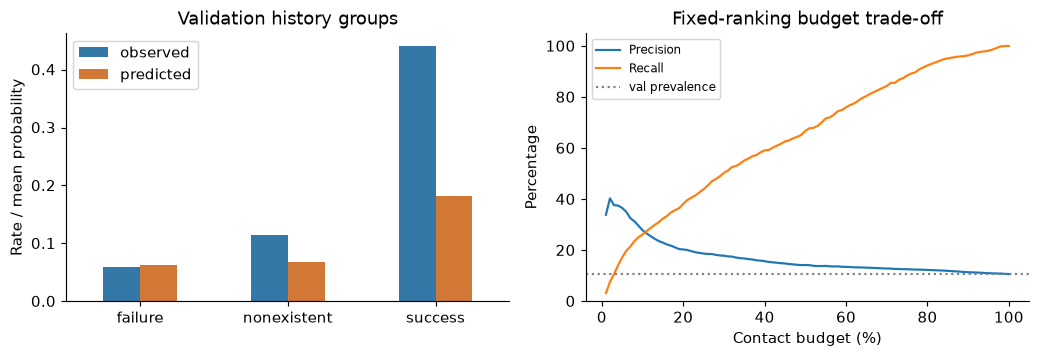

In [12]:
contact_spec={'age':'spline','history':3,'macro_penalty':None,'drop':['month','day_of_week']}
contact_model=None
contact_model=build_contact_representation(contact_spec)
contact_model.set_params(classifier__C=.01)
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always');contact_model.fit(X_train,y_train)
assert contact_model.named_steps['classifier'].n_iter_[0]<20000
assert not any(issubclass(w.category,ConvergenceWarning) for w in caught)
rerun_contact=contact_model.predict_proba(X_val)[:,1]
contact_p=rerun_contact

def budget_metrics(y,p,fraction):
    y=np.asarray(y);p=np.asarray(p)
    k=int(np.ceil(len(y)*fraction))
    order=np.lexsort((np.arange(len(p)), -p))[:k]  # Original row-order tie break; no labels.
    tp=int(y[order].sum())
    return dict(budget=fraction,n_contact=k,TP=tp,FP=k-tp,FN=int(y.sum())-tp,
                precision=tp/k,recall=tp/y.sum(),lift=(tp/k)/y.mean())
budget=pd.DataFrame([budget_metrics(y_val,contact_p,q) for q in [.05,.10,.20]])
show(budget)
contact_metrics=[]
for rule,t in [('fixed_0.5',.5),('val_F1_selection_only',choose_f1_threshold(y_val,contact_p))]:
    contact_metrics.append({'model':'contact_LR_spline_C0.01','rule':rule,**metric_row(y_val,contact_p,t)})
show(pd.DataFrame(contact_metrics)[['model','rule','threshold']+METRIC_COLUMNS[1:]])
metric_contact=metric_row(y_val,contact_p,.5)
print('Contact LR val AUC/AP:',round(metric_contact['roc_auc'],6),round(metric_contact['average_precision'],6))
# Group rates and residuals describe this fixed model; no automatic subgroup correction.
gp=pd.DataFrame({'poutcome':val.poutcome,'y':y_val,'p':contact_p})
diagnostic=gp.groupby('poutcome').agg(n=('y','size'),yes=('y','sum'),observed=('y','mean'),predicted=('p','mean')).reset_index()
show(diagnostic)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
diagnostic.set_index('poutcome')[['observed','predicted']].plot.bar(ax=axes[0],rot=0,color=['#3478A8','#D27837'])
axes[0].set(title='Validation history groups',ylabel='Rate / mean probability',xlabel='')
grid=pd.DataFrame([budget_metrics(y_val,contact_p,q) for q in np.arange(.01,1.01,.01)])
axes[1].plot(grid.budget*100,grid.precision*100,label='Precision')
axes[1].plot(grid.budget*100,grid.recall*100,label='Recall')
axes[1].axhline(y_val.mean()*100,ls=':',color='grey',label='val prevalence')
axes[1].set(xlabel='Contact budget (%)',ylabel='Percentage',title='Fixed-ranking budget trade-off',ylim=(0,105))
axes[1].legend(fontsize=8);finish(fig,'06_contact_budget_and_groups')


**名单能力与概率能力要分开。** 联系版val AUC≈0.6593、AP≈0.2147；联系前10%即618人，命中172、误报446，
Precision≈27.83%、Recall≈26.14%，优于10.65%的随机抽样期望，但仍有明显区分瓶颈。
5%预算Precision≈36.57%，20%≈20.31%；提高Precision通常减少覆盖，不能靠改阈值提升排序能力。

success组实际44.08%、预测均值18.15%；failure组实际5.86%、预测6.20%，偏差不统一。
前10%已找到success中的63/67个yes，仍有81个该组误报；nonexistent组有485个yes，只找到100个。
因此直接抬高success整体分数未必解决多数客户的区分。学生在高分前200人的53条中仅9个yes，
也说明单变量“学生更高”不足以给学生手工加分。

In [13]:
# Read coefficients only if the model was refitted. These are parameter contrasts,
# not a cross-feature importance ranking or an intervention effect.
if contact_model is not None:
    pre=contact_model.named_steps['preprocess']
    coef=pd.Series(contact_model.named_steps['classifier'].coef_[0],index=pre.get_feature_names_out())
    pairs=[('job','student','admin.'),('job','retired','admin.'),
           ('education','university.degree','high.school'),('poutcome','success','failure'),
           ('poutcome','success','nonexistent')]
    rows=[]
    for field,a,b in pairs:
        ka,kb=f'cat__{field}_{a}',f'cat__{field}_{b}'
        delta=float(coef[ka]-coef[kb])
        rows.append([field,a,b,delta,np.exp(delta)])
    show(pd.DataFrame(rows,columns=['field','category a','category b','conditional log-odds difference','conditional odds ratio']))

field,category a,category b,conditional log-odds difference,conditional odds ratio
job,student,admin.,0.1982,1.2192
job,retired,admin.,0.2827,1.3267
education,university.degree,high.school,0.0655,1.0677
poutcome,success,failure,0.0119,1.0119
poutcome,success,nonexistent,-0.0398,0.9610


### 8.1 Historical supplementary test / 已有的事后补测

下表保留原有信息范围及规则，不按test成绩排冠军。
联系版C=0.01的“val Precision40”规则在test达到约67% Precision，却只召回约37–38%。
这与val前10%预算不是同一选人规则，亦不是新的独立确认；需要同时看阈值、人数、基础率和Recall。

### 111个预测器版本及3个常数参照的已有事后测试：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|top10|6179|0.3845|—|0.5632|0.4398|0.6038|0.4417|0.1149|0.1824|0.8366|0.2843|273|345|2103|3458|
|original__A_scaled|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|original__B|test|top10|6179|0.3845|—|0.4690|0.3542|0.5757|0.3010|0.0783|0.1242|0.9728|0.3145|186|432|2190|3371|
|original__B_default3|test|top10|6179|0.3845|—|0.4340|0.3362|0.5682|0.2638|0.0686|0.1089|1.0176|0.3207|163|455|2213|3348|
|original__B_macro_all|test|top10|6179|0.3845|—|0.4973|0.3987|0.6100|0.4725|0.1229|0.1951|0.9735|0.3091|292|326|2084|3477|
|original__B_month|test|top10|6179|0.3845|—|0.4301|0.3550|0.5912|0.3786|0.0985|0.1563|1.3872|0.3507|234|384|2142|3419|
|original__B_pdays|test|top10|6179|0.3845|—|0.4473|0.3670|0.5860|0.3528|0.0918|0.1456|1.0233|0.3161|218|400|2158|3403|
|macro__M1_all_macro|test|top10|6179|0.3845|—|0.6015|0.4582|0.6132|0.4887|0.1271|0.2017|0.8063|0.2751|302|316|2074|3487|
|macro__M2_no_macro|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|macro__M3_three_macro|test|top10|6179|0.3845|—|0.4195|0.3397|0.5698|0.2718|0.0707|0.1122|2.0117|0.3701|168|450|2208|3353|
|personal_macro_v2__M_drop_age|test|top10|6179|0.3845|—|0.6352|0.4832|0.6016|0.4304|0.1120|0.1777|0.7796|0.2737|266|352|2110|3451|
|personal_macro_v2__M_drop_campaign|test|top10|6179|0.3845|—|0.6329|0.4807|0.6019|0.4320|0.1124|0.1784|0.7822|0.2746|267|351|2109|3452|
|personal_macro_v2__M_drop_contact|test|top10|6179|0.3845|—|0.6274|0.4746|0.6016|0.4304|0.1120|0.1777|0.7817|0.2742|266|352|2110|3451|
|personal_macro_v2__M_drop_default|test|top10|6179|0.3845|—|0.6328|0.4809|0.6019|0.4320|0.1124|0.1784|0.7825|0.2746|267|351|2109|3452|
|personal_macro_v2__M_drop_education|test|top10|6179|0.3845|—|0.6367|0.4835|0.6009|0.4272|0.1111|0.1764|0.7791|0.2738|264|354|2112|3449|
|personal_macro_v2__M_drop_history|test|top10|6179|0.3845|—|0.5950|0.4453|0.6003|0.4239|0.1103|0.1750|0.8080|0.2843|262|356|2114|3447|
|personal_macro_v2__M_drop_job|test|top10|6179|0.3845|—|0.6374|0.4844|0.6009|0.4272|0.1111|0.1764|0.7796|0.2740|264|354|2112|3449|
|personal_macro_v2__M_drop_loans|test|top10|6179|0.3845|—|0.6345|0.4815|0.6019|0.4320|0.1124|0.1784|0.7799|0.2740|267|351|2109|3452|
|personal_macro_v2__M_drop_marital|test|top10|6179|0.3845|—|0.6341|0.4817|0.6019|0.4320|0.1124|0.1784|0.7799|0.2739|267|351|2109|3452|
|personal_macro_v2__M_drop_month|test|top10|6179|0.3845|—|0.5436|0.4365|0.6242|0.5437|0.1414|0.2244|0.8784|0.2921|336|282|2040|3521|
|personal_macro_v2__M_drop_weekday|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|
|personal_macro_v2__M_penalty1|test|top10|6179|0.3845|—|0.6148|0.4659|0.6126|0.4854|0.1263|0.2004|0.7855|0.2698|300|318|2076|3485|
|personal_macro_v2__M_penalty10|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|personal_macro_v2__M_penalty100|test|top10|6179|0.3845|—|0.6421|0.4862|0.6038|0.4417|0.1149|0.1824|0.8488|0.2905|273|345|2103|3458|
|personal_macro_v2__P0_linear|test|top10|6179|0.3845|—|0.6369|0.4859|0.6084|0.4644|0.1208|0.1917|0.9866|0.3103|287|331|2089|3472|
|personal_macro_v2__P1_age_spline|test|top10|6179|0.3845|—|0.6386|0.4849|0.6074|0.4595|0.1195|0.1897|0.9803|0.3097|284|334|2092|3469|
|personal_macro_v2__P2_previous|test|top10|6179|0.3845|—|0.6368|0.4833|0.6074|0.4595|0.1195|0.1897|0.9831|0.3101|284|334|2092|3469|
|personal_macro_v2__P3_pdays_flag|test|top10|6179|0.3845|—|0.6406|0.4856|0.6077|0.4612|0.1199|0.1904|0.9790|0.3096|285|333|2091|3470|
|personal_macro_v2__P_drop_age|test|top10|6179|0.3845|—|0.6421|0.4872|0.6090|0.4676|0.1216|0.1931|0.9756|0.3082|289|329|2087|3474|
|personal_macro_v2__P_drop_campaign|test|top10|6179|0.3845|—|0.6402|0.4854|0.6080|0.4628|0.1204|0.1910|0.9764|0.3087|286|332|2090|3471|
|personal_macro_v2__P_drop_contact|test|top10|6179|0.3845|—|0.6397|0.4840|0.6096|0.4709|0.1225|0.1944|0.9960|0.3094|291|327|2085|3476|
|personal_macro_v2__P_drop_default|test|top10|6179|0.3845|—|0.6405|0.4860|0.6080|0.4628|0.1204|0.1910|0.9777|0.3087|286|332|2090|3471|
|personal_macro_v2__P_drop_education|test|top10|6179|0.3845|—|0.6430|0.4876|0.6087|0.4660|0.1212|0.1924|0.9745|0.3084|288|330|2088|3473|
|personal_macro_v2__P_drop_history|test|top10|6179|0.3845|—|0.6130|0.4570|0.6019|0.4320|0.1124|0.1784|0.9913|0.3145|267|351|2109|3452|
|personal_macro_v2__P_drop_job|test|top10|6179|0.3845|—|0.6446|0.4889|0.6116|0.4806|0.1250|0.1984|0.9797|0.3089|297|321|2079|3482|
|personal_macro_v2__P_drop_loans|test|top10|6179|0.3845|—|0.6418|0.4862|0.6084|0.4644|0.1208|0.1917|0.9731|0.3082|287|331|2089|3472|
|personal_macro_v2__P_drop_marital|test|top10|6179|0.3845|—|0.6413|0.4860|0.6080|0.4628|0.1204|0.1910|0.9733|0.3081|286|332|2090|3471|
|personal_macro_v2__P_drop_month|test|top10|6179|0.3845|—|0.6548|0.5436|0.6491|0.6683|0.1738|0.2759|0.8996|0.2955|413|205|1963|3598|
|personal_macro_v2__P_drop_weekday|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|personal_macro_v2__P_full|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|weight_interaction__M10_w1_i0|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|weight_interaction__M10_w1_i1|test|top10|6179|0.3845|—|0.6337|0.4774|0.6012|0.4288|0.1115|0.1770|0.7823|0.2743|265|353|2111|3450|
|weight_interaction__M10_w2_i0|test|top10|6179|0.3845|—|0.6280|0.4764|0.6022|0.4337|0.1128|0.1790|0.7217|0.2554|268|350|2108|3453|
|weight_interaction__M10_w2_i1|test|top10|6179|0.3845|—|0.6277|0.4722|0.6028|0.4369|0.1136|0.1804|0.7247|0.2559|270|348|2106|3455|
|weight_interaction__M10_w5_i0|test|top10|6179|0.3845|—|0.6178|0.4686|0.6032|0.4385|0.1141|0.1810|0.7040|0.2465|271|347|2105|3456|
|weight_interaction__M10_w5_i1|test|top10|6179|0.3845|—|0.6180|0.4653|0.6051|0.4482|0.1166|0.1850|0.7111|0.2481|277|341|2099|3462|
|weight_interaction__M10_wbalanced_i0|test|top10|6179|0.3845|—|0.6036|0.4605|0.6058|0.4515|0.1174|0.1864|0.8588|0.3018|279|339|2097|3464|
|weight_interaction__M10_wbalanced_i1|test|top10|6179|0.3845|—|0.6060|0.4586|0.6071|0.4579|0.1191|0.1890|0.8799|0.3059|283|335|2093|3468|
|weight_interaction__P_w1_i0|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|weight_interaction__P_w1_i1|test|top10|6179|0.3845|—|0.6409|0.4820|0.6080|0.4628|0.1204|0.1910|0.9732|0.3082|286|332|2090|3471|
|weight_interaction__P_w2_i0|test|top10|6179|0.3845|—|0.6380|0.4839|0.6080|0.4628|0.1204|0.1910|0.8374|0.2870|286|332|2090|3471|
|weight_interaction__P_w2_i1|test|top10|6179|0.3845|—|0.6374|0.4793|0.6074|0.4595|0.1195|0.1897|0.8382|0.2867|284|334|2092|3469|
|weight_interaction__P_w5_i0|test|top10|6179|0.3845|—|0.6336|0.4813|0.6077|0.4612|0.1199|0.1904|0.7441|0.2592|285|333|2091|3470|
|weight_interaction__P_w5_i1|test|top10|6179|0.3845|—|0.6331|0.4765|0.6074|0.4595|0.1195|0.1897|0.7501|0.2599|284|334|2092|3469|
|weight_interaction__P_wbalanced_i0|test|top10|6179|0.3845|—|0.6269|0.4775|0.6084|0.4644|0.1208|0.1917|0.8315|0.2761|287|331|2089|3472|
|weight_interaction__P_wbalanced_i1|test|top10|6179|0.3845|—|0.6268|0.4727|0.6090|0.4676|0.1216|0.1931|0.8491|0.2792|289|329|2087|3474|
|information_scope__personal_contact_history|test|top10|6179|0.3845|—|0.6509|0.5405|0.6491|0.6683|0.1738|0.2759|0.8966|0.2950|413|205|1963|3598|
|information_scope__personal_only|test|top10|6179|0.3845|—|0.5294|0.4126|0.6061|0.4531|0.1178|0.1870|1.0638|0.3320|280|338|2096|3465|
|precision_constraints__contact_LR_linear_C0.01|test|top10|6179|0.3845|—|0.6640|0.5586|0.6543|0.6942|0.1806|0.2866|0.9399|0.3079|429|189|1947|3614|
|precision_constraints__contact_LR_linear_C0.1|test|top10|6179|0.3845|—|0.6571|0.5514|0.6517|0.6812|0.1772|0.2812|0.9199|0.3019|421|197|1955|3606|
|precision_constraints__contact_LR_linear_C1|test|top10|6179|0.3845|—|0.6489|0.5397|0.6475|0.6602|0.1717|0.2725|0.9147|0.2993|408|210|1968|3593|
|precision_constraints__contact_LR_linear_C10|test|top10|6179|0.3845|—|0.6382|0.5343|0.6485|0.6650|0.1730|0.2745|0.9165|0.2978|411|207|1965|3596|
|precision_constraints__contact_LR_spline_C0.01|test|top10|6179|0.3845|—|0.6680|0.5620|0.6517|0.6812|0.1772|0.2812|0.9273|0.3053|421|197|1955|3606|
|precision_constraints__contact_LR_spline_C0.1|test|top10|6179|0.3845|—|0.6590|0.5524|0.6533|0.6893|0.1793|0.2846|0.9050|0.2985|426|192|1950|3611|
|precision_constraints__contact_LR_spline_C1|test|top10|6179|0.3845|—|0.6509|0.5405|0.6491|0.6683|0.1738|0.2759|0.8966|0.2950|413|205|1963|3598|
|precision_constraints__contact_LR_spline_C10|test|top10|6179|0.3845|—|0.6397|0.5328|0.6469|0.6570|0.1709|0.2712|0.8876|0.2902|406|212|1970|3591|
|precision_constraints__contact_TREE_d2_leaf100|test|top10|6179|0.3845|—|0.5432|0.4100|0.6084|0.4644|0.1208|0.1917|1.0263|0.3232|287|331|2089|3472|
|precision_constraints__contact_TREE_d2_leaf300|test|top10|6179|0.3845|—|0.5495|0.4125|0.6035|0.4401|0.1145|0.1817|1.0447|0.3295|272|346|2104|3457|
|precision_constraints__contact_TREE_d3_leaf100|test|top10|6179|0.3845|—|0.5475|0.4150|0.6084|0.4644|0.1208|0.1917|1.0180|0.3216|287|331|2089|3472|
|precision_constraints__contact_TREE_d3_leaf300|test|top10|6179|0.3845|—|0.5487|0.4171|0.6035|0.4401|0.1145|0.1817|1.0352|0.3277|272|346|2104|3457|
|precision_constraints__contact_TREE_d4_leaf100|test|top10|6179|0.3845|—|0.5486|0.4191|0.6084|0.4644|0.1208|0.1917|0.9967|0.3169|287|331|2089|3472|
|precision_constraints__contact_TREE_d4_leaf300|test|top10|6179|0.3845|—|0.5532|0.4220|0.6035|0.4401|0.1145|0.1817|1.0207|0.3254|272|346|2104|3457|
|precision_constraints__personal_LR_linear_C0.01|test|top10|6179|0.3845|—|0.5105|0.3964|0.5964|0.4045|0.1052|0.1670|1.1109|0.3405|250|368|2126|3435|
|precision_constraints__personal_LR_linear_C0.1|test|top10|6179|0.3845|—|0.5222|0.4069|0.6009|0.4272|0.1111|0.1764|1.0900|0.3368|264|354|2112|3449|
|precision_constraints__personal_LR_linear_C1|test|top10|6179|0.3845|—|0.5231|0.4082|0.6006|0.4256|0.1107|0.1757|1.0852|0.3355|263|355|2113|3448|
|precision_constraints__personal_LR_linear_C10|test|top10|6179|0.3845|—|0.5232|0.4089|0.6009|0.4272|0.1111|0.1764|1.0847|0.3353|264|354|2112|3449|
|precision_constraints__personal_LR_spline_C0.01|test|top10|6179|0.3845|—|0.5243|0.4031|0.6009|0.4272|0.1111|0.1764|1.0969|0.3387|264|354|2112|3449|
|precision_constraints__personal_LR_spline_C0.1|test|top10|6179|0.3845|—|0.5284|0.4106|0.6028|0.4369|0.1136|0.1804|1.0726|0.3341|270|348|2106|3455|
|precision_constraints__personal_LR_spline_C1|test|top10|6179|0.3845|—|0.5294|0.4126|0.6061|0.4531|0.1178|0.1870|1.0638|0.3320|280|338|2096|3465|
|precision_constraints__personal_LR_spline_C10|test|top10|6179|0.3845|—|0.5331|0.4201|0.6071|0.4579|0.1191|0.1890|1.0479|0.3280|283|335|2093|3468|
|precision_constraints__personal_TREE_d2_leaf100|test|top10|6179|0.3845|—|0.5237|0.4018|0.6058|0.4515|0.1174|0.1864|1.0787|0.3310|279|339|2097|3464|
|precision_constraints__personal_TREE_d2_leaf300|test|top10|6179|0.3845|—|0.5284|0.4061|0.5944|0.3948|0.1027|0.1630|1.0898|0.3365|244|374|2132|3429|
|precision_constraints__personal_TREE_d3_leaf100|test|top10|6179|0.3845|—|0.5306|0.4078|0.6061|0.4531|0.1178|0.1870|1.0509|0.3266|280|338|2096|3465|
|precision_constraints__personal_TREE_d3_leaf300|test|top10|6179|0.3845|—|0.5303|0.4095|0.5944|0.3948|0.1027|0.1630|1.0765|0.3348|244|374|2132|3429|
|precision_constraints__personal_TREE_d4_leaf100|test|top10|6179|0.3845|—|0.5302|0.4080|0.6064|0.4547|0.1183|0.1877|1.0568|0.3266|281|337|2095|3466|
|precision_constraints__personal_TREE_d4_leaf300|test|top10|6179|0.3845|—|0.5384|0.4144|0.5944|0.3948|0.1027|0.1630|1.0702|0.3339|244|374|2132|3429|
|boosting_error_audit__contact_HGB_d2_l21|test|top10|6179|0.3845|—|0.5580|0.4310|0.6087|0.4660|0.1212|0.1924|0.9892|0.3172|288|330|2088|3473|
|boosting_error_audit__contact_HGB_d2_l210|test|top10|6179|0.3845|—|0.5577|0.4294|0.6080|0.4628|0.1204|0.1910|0.9926|0.3187|286|332|2090|3471|
|boosting_error_audit__contact_HGB_d3_l21|test|top10|6179|0.3845|—|0.5586|0.4315|0.6080|0.4628|0.1204|0.1910|0.9839|0.3150|286|332|2090|3471|
|boosting_error_audit__contact_HGB_d3_l210|test|top10|6179|0.3845|—|0.5594|0.4358|0.6084|0.4644|0.1208|0.1917|0.9855|0.3161|287|331|2089|3472|
|boosting_error_audit__personal_HGB_d2_l21|test|top10|6179|0.3845|—|0.5344|0.4162|0.6071|0.4579|0.1191|0.1890|1.0295|0.3225|283|335|2093|3468|
|boosting_error_audit__personal_HGB_d2_l210|test|top10|6179|0.3845|—|0.5358|0.4161|0.6058|0.4515|0.1174|0.1864|1.0343|0.3246|279|339|2097|3464|
|boosting_error_audit__personal_HGB_d3_l21|test|top10|6179|0.3845|—|0.5327|0.4186|0.6093|0.4693|0.1221|0.1937|1.0277|0.3211|290|328|2086|3475|
|boosting_error_audit__personal_HGB_d3_l210|test|top10|6179|0.3845|—|0.5353|0.4192|0.6074|0.4595|0.1195|0.1897|1.0291|0.3225|284|334|2092|3469|
|temporal_calibration__P__raw|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|1.1081|0.3392|292|326|2084|3477|
|temporal_calibration__P__intercept_only|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|0.9744|0.3201|292|326|2084|3477|
|temporal_calibration__P__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|1.1081|0.3392|292|326|2084|3477|
|temporal_calibration__M10__raw|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.7023|0.2544|341|277|2035|3526|
|temporal_calibration__M10__intercept_only|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.6522|0.2299|341|277|2035|3526|
|temporal_calibration__M10__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.7109|0.2545|341|277|2035|3526|
|temporal_calibration__M100__raw|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.6462|0.2274|313|305|2063|3498|
|temporal_calibration__M100__intercept_only|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.6705|0.2383|313|305|2063|3498|
|temporal_calibration__M100__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.7014|0.2509|313|305|2063|3498|
|diagnostic_reconstructed__baseline|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|diagnostic_reconstructed__C_0.1|test|top10|6179|0.3845|—|0.5836|0.4508|0.6109|0.4773|0.1242|0.1971|0.8001|0.2750|295|323|2081|3480|
|diagnostic_reconstructed__C_10|test|top10|6179|0.3845|—|0.5774|0.4463|0.6093|0.4693|0.1221|0.1937|0.8179|0.2758|290|328|2086|3475|
|diagnostic_reconstructed__log_counts|test|top10|6179|0.3845|—|0.5920|0.4527|0.6067|0.4563|0.1187|0.1884|0.7840|0.2706|282|336|2094|3467|
|diagnostic_reconstructed__age_spline|test|top10|6179|0.3845|—|0.5790|0.4449|0.6090|0.4676|0.1216|0.1931|0.8138|0.2754|289|329|2087|3474|
|diagnostic_reconstructed__log_counts_age_spline|test|top10|6179|0.3845|—|0.5943|0.4519|0.6061|0.4531|0.1178|0.1870|0.7811|0.2701|280|338|2096|3465|
|diagnostic_reconstructed__recent_12000|test|top10|6179|0.3845|—|0.6489|0.4982|0.6252|0.5485|0.1427|0.2265|0.6979|0.2427|339|279|2037|3524|
|diagnostic_reconstructed__age_spline_strict|test|top10|6179|0.3845|—|0.6052|0.4585|0.6132|0.4887|0.1271|0.2017|0.8027|0.2744|302|316|2074|3487|
|reference__all_no|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|13.8598|0.3845|63|555|2313|3248|
|reference__all_yes|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|22.1839|0.6155|63|555|2313|3248|
|reference__train_prior|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|1.1457|0.3448|63|555|2313|3248|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（225行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|fixed_0.5|6179|0.3845|0.5|0.5632|0.4398|0.6126|0.4751|0.0724|0.1256|0.8366|0.2843|172|190|2204|3613|
|original__A_scaled|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|original__B|test|fixed_0.5|6179|0.3845|0.5|0.4690|0.3542|0.6155|—|0.0000|0.0000|0.9728|0.3145|0|0|2376|3803|
|original__B_default3|test|fixed_0.5|6179|0.3845|0.5|0.4340|0.3362|0.6155|—|0.0000|0.0000|1.0176|0.3207|0|0|2376|3803|
|original__B_macro_all|test|fixed_0.5|6179|0.3845|0.5|0.4973|0.3987|0.6173|0.5478|0.0265|0.0506|0.9735|0.3091|63|52|2313|3751|
|original__B_month|test|fixed_0.5|6179|0.3845|0.5|0.4301|0.3550|0.6151|0.4938|0.0332|0.0623|1.3872|0.3507|79|81|2297|3722|
|original__B_pdays|test|fixed_0.5|6179|0.3845|0.5|0.4473|0.3670|0.6184|0.6452|0.0168|0.0328|1.0233|0.3161|40|22|2336|3781|
|macro__M1_all_macro|test|fixed_0.5|6179|0.3845|0.5|0.6015|0.4582|0.6171|0.5171|0.0636|0.1132|0.8063|0.2751|151|141|2225|3662|
|macro__M2_no_macro|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|macro__M3_three_macro|test|fixed_0.5|6179|0.3845|0.5|0.4195|0.3397|0.6160|0.7143|0.0021|0.0042|2.0117|0.3701|5|2|2371|3801|
|personal_macro_v2__M_drop_age|test|fixed_0.5|6179|0.3845|0.5|0.6352|0.4832|0.6007|0.4307|0.1191|0.1866|0.7796|0.2737|283|374|2093|3429|
|personal_macro_v2__M_drop_campaign|test|fixed_0.5|6179|0.3845|0.5|0.6329|0.4807|0.6004|0.4292|0.1187|0.1860|0.7822|0.2746|282|375|2094|3428|
|personal_macro_v2__M_drop_contact|test|fixed_0.5|6179|0.3845|0.5|0.6274|0.4746|0.6006|0.4288|0.1166|0.1833|0.7817|0.2742|277|369|2099|3434|
|personal_macro_v2__M_drop_default|test|fixed_0.5|6179|0.3845|0.5|0.6328|0.4809|0.6006|0.4297|0.1183|0.1855|0.7825|0.2746|281|373|2095|3430|
|personal_macro_v2__M_drop_education|test|fixed_0.5|6179|0.3845|0.5|0.6367|0.4835|0.5999|0.4271|0.1183|0.1852|0.7791|0.2738|281|377|2095|3426|
|personal_macro_v2__M_drop_history|test|fixed_0.5|6179|0.3845|0.5|0.5950|0.4453|0.5983|0.4185|0.1145|0.1798|0.8080|0.2843|272|378|2104|3425|
|personal_macro_v2__M_drop_job|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4844|0.5999|0.4271|0.1183|0.1852|0.7796|0.2740|281|377|2095|3426|
|personal_macro_v2__M_drop_loans|test|fixed_0.5|6179|0.3845|0.5|0.6345|0.4815|0.5999|0.4268|0.1178|0.1847|0.7799|0.2740|280|376|2096|3427|
|personal_macro_v2__M_drop_marital|test|fixed_0.5|6179|0.3845|0.5|0.6341|0.4817|0.6006|0.4299|0.1187|0.1860|0.7799|0.2739|282|374|2094|3429|
|personal_macro_v2__M_drop_month|test|fixed_0.5|6179|0.3845|0.5|0.5436|0.4365|0.6168|0.5370|0.0244|0.0467|0.8784|0.2921|58|50|2318|3753|
|personal_macro_v2__M_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|
|personal_macro_v2__M_penalty1|test|fixed_0.5|6179|0.3845|0.5|0.6148|0.4659|0.6163|0.5075|0.0715|0.1254|0.7855|0.2698|170|165|2206|3638|
|personal_macro_v2__M_penalty10|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|personal_macro_v2__M_penalty100|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4862|0.6037|0.4484|0.1334|0.2056|0.8488|0.2905|317|390|2059|3413|
|personal_macro_v2__P0_linear|test|fixed_0.5|6179|0.3845|0.5|0.6369|0.4859|0.6080|0.4645|0.1267|0.1991|0.9866|0.3103|301|347|2075|3456|
|personal_macro_v2__P1_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.6386|0.4849|0.6074|0.4619|0.1275|0.1999|0.9803|0.3097|303|353|2073|3450|
|personal_macro_v2__P2_previous|test|fixed_0.5|6179|0.3845|0.5|0.6368|0.4833|0.6072|0.4607|0.1258|0.1977|0.9831|0.3101|299|350|2077|3453|
|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|6179|0.3845|0.5|0.6406|0.4856|0.6067|0.4586|0.1258|0.1975|0.9790|0.3096|299|353|2077|3450|
|personal_macro_v2__P_drop_age|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4872|0.6085|0.4678|0.1313|0.2051|0.9756|0.3082|312|355|2064|3448|
|personal_macro_v2__P_drop_campaign|test|fixed_0.5|6179|0.3845|0.5|0.6402|0.4854|0.6071|0.4611|0.1296|0.2024|0.9764|0.3087|308|360|2068|3443|
|personal_macro_v2__P_drop_contact|test|fixed_0.5|6179|0.3845|0.5|0.6397|0.4840|0.6101|0.4729|0.1212|0.1930|0.9960|0.3094|288|321|2088|3482|
|personal_macro_v2__P_drop_default|test|fixed_0.5|6179|0.3845|0.5|0.6405|0.4860|0.6072|0.4615|0.1288|0.2014|0.9777|0.3087|306|357|2070|3446|
|personal_macro_v2__P_drop_education|test|fixed_0.5|6179|0.3845|0.5|0.6430|0.4876|0.6075|0.4632|0.1296|0.2026|0.9745|0.3084|308|357|2068|3446|
|personal_macro_v2__P_drop_history|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4570|0.6012|0.4357|0.1254|0.1948|0.9913|0.3145|298|386|2078|3417|
|personal_macro_v2__P_drop_job|test|fixed_0.5|6179|0.3845|0.5|0.6446|0.4889|0.6093|0.4717|0.1334|0.2080|0.9797|0.3089|317|355|2059|3448|
|personal_macro_v2__P_drop_loans|test|fixed_0.5|6179|0.3845|0.5|0.6418|0.4862|0.6077|0.4641|0.1305|0.2037|0.9731|0.3082|310|358|2066|3445|
|personal_macro_v2__P_drop_marital|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4860|0.6082|0.4661|0.1301|0.2034|0.9733|0.3081|309|354|2067|3449|
|personal_macro_v2__P_drop_month|test|fixed_0.5|6179|0.3845|0.5|0.6548|0.5436|0.6182|0.6269|0.0177|0.0344|0.8996|0.2955|42|25|2334|3778|
|personal_macro_v2__P_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|personal_macro_v2__P_full|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|weight_interaction__M10_w1_i0|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|weight_interaction__M10_w1_i1|test|fixed_0.5|6179|0.3845|0.5|0.6337|0.4774|0.6003|0.4290|0.1195|0.1870|0.7823|0.2743|284|378|2092|3425|
|weight_interaction__M10_w2_i0|test|fixed_0.5|6179|0.3845|0.5|0.6280|0.4764|0.6048|0.4567|0.1465|0.2218|0.7217|0.2554|348|414|2028|3389|
|weight_interaction__M10_w2_i1|test|fixed_0.5|6179|0.3845|0.5|0.6277|0.4722|0.6061|0.4647|0.1608|0.2389|0.7247|0.2559|382|440|1994|3363|
|weight_interaction__M10_w5_i0|test|fixed_0.5|6179|0.3845|0.5|0.6178|0.4686|0.6103|0.4912|0.3737|0.4245|0.7040|0.2465|888|920|1488|2883|
|weight_interaction__M10_w5_i1|test|fixed_0.5|6179|0.3845|0.5|0.6180|0.4653|0.6067|0.4859|0.3910|0.4333|0.7111|0.2481|929|983|1447|2820|
|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|6179|0.3845|0.5|0.6036|0.4605|0.4944|0.4195|0.8207|0.5552|0.8588|0.3018|1950|2698|426|1105|
|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|6179|0.3845|0.5|0.6060|0.4586|0.4957|0.4204|0.8224|0.5564|0.8799|0.3059|1954|2694|422|1109|
|weight_interaction__P_w1_i0|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|weight_interaction__P_w1_i1|test|fixed_0.5|6179|0.3845|0.5|0.6409|0.4820|0.6069|0.4600|0.1284|0.2007|0.9732|0.3082|305|358|2071|3445|
|weight_interaction__P_w2_i0|test|fixed_0.5|6179|0.3845|0.5|0.6380|0.4839|0.6080|0.4736|0.1734|0.2539|0.8374|0.2870|412|458|1964|3345|
|weight_interaction__P_w2_i1|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4793|0.6087|0.4761|0.1759|0.2569|0.8382|0.2867|418|460|1958|3343|
|weight_interaction__P_w5_i0|test|fixed_0.5|6179|0.3845|0.5|0.6336|0.4813|0.6166|0.5028|0.2605|0.3432|0.7441|0.2592|619|612|1757|3191|
|weight_interaction__P_w5_i1|test|fixed_0.5|6179|0.3845|0.5|0.6331|0.4765|0.6174|0.5047|0.2740|0.3552|0.7501|0.2599|651|639|1725|3164|
|weight_interaction__P_wbalanced_i0|test|fixed_0.5|6179|0.3845|0.5|0.6269|0.4775|0.5891|0.4757|0.6717|0.5570|0.8315|0.2761|1596|1759|780|2044|
|weight_interaction__P_wbalanced_i1|test|fixed_0.5|6179|0.3845|0.5|0.6268|0.4727|0.5915|0.4778|0.6717|0.5584|0.8491|0.2792|1596|1744|780|2059|
|information_scope__personal_contact_history|test|fixed_0.5|6179|0.3845|0.5|0.6509|0.5405|0.6179|0.6087|0.0177|0.0344|0.8966|0.2950|42|27|2334|3776|
|information_scope__personal_only|test|fixed_0.5|6179|0.3845|0.5|0.5294|0.4126|0.6155|—|0.0000|0.0000|1.0638|0.3320|0|0|2376|3803|
|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.6640|0.5586|0.6155|—|0.0000|0.0000|0.9399|0.3079|0|0|2376|3803|
|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.6571|0.5514|0.6161|0.6429|0.0038|0.0075|0.9199|0.3019|9|5|2367|3798|
|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|6179|0.3845|0.5|0.6489|0.5397|0.6166|0.5745|0.0114|0.0223|0.9147|0.2993|27|20|2349|3783|
|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|6179|0.3845|0.5|0.6382|0.5343|0.6219|0.6852|0.0311|0.0596|0.9165|0.2978|74|34|2302|3769|
|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.6680|0.5620|0.6155|—|0.0000|0.0000|0.9273|0.3053|0|0|2376|3803|
|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.6590|0.5524|0.6164|0.6667|0.0051|0.0100|0.9050|0.2985|12|6|2364|3797|
|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|6179|0.3845|0.5|0.6509|0.5405|0.6179|0.6087|0.0177|0.0344|0.8966|0.2950|42|27|2334|3776|
|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|6179|0.3845|0.5|0.6397|0.5328|0.6271|0.7278|0.0484|0.0908|0.8876|0.2902|115|43|2261|3760|
|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5432|0.4100|0.6155|—|0.0000|0.0000|1.0263|0.3232|0|0|2376|3803|
|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5495|0.4125|0.6155|—|0.0000|0.0000|1.0447|0.3295|0|0|2376|3803|
|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5475|0.4150|0.6155|—|0.0000|0.0000|1.0180|0.3216|0|0|2376|3803|
|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5487|0.4171|0.6155|—|0.0000|0.0000|1.0352|0.3277|0|0|2376|3803|
|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5486|0.4191|0.6155|—|0.0000|0.0000|0.9967|0.3169|0|0|2376|3803|
|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5532|0.4220|0.6155|—|0.0000|0.0000|1.0207|0.3254|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.5105|0.3964|0.6155|—|0.0000|0.0000|1.1109|0.3405|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.5222|0.4069|0.6155|—|0.0000|0.0000|1.0900|0.3368|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|6179|0.3845|0.5|0.5231|0.4082|0.6155|—|0.0000|0.0000|1.0852|0.3355|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|6179|0.3845|0.5|0.5232|0.4089|0.6155|—|0.0000|0.0000|1.0847|0.3353|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.5243|0.4031|0.6155|—|0.0000|0.0000|1.0969|0.3387|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.5284|0.4106|0.6155|—|0.0000|0.0000|1.0726|0.3341|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|6179|0.3845|0.5|0.5294|0.4126|0.6155|—|0.0000|0.0000|1.0638|0.3320|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|6179|0.3845|0.5|0.5331|0.4201|0.6148|0.0000|0.0000|0.0000|1.0479|0.3280|0|4|2376|3799|
|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5237|0.4018|0.6155|—|0.0000|0.0000|1.0787|0.3310|0|0|2376|3803|
|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5284|0.4061|0.6155|—|0.0000|0.0000|1.0898|0.3365|0|0|2376|3803|
|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5306|0.4078|0.6155|—|0.0000|0.0000|1.0509|0.3266|0|0|2376|3803|
|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5303|0.4095|0.6155|—|0.0000|0.0000|1.0765|0.3348|0|0|2376|3803|
|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5302|0.4080|0.6155|—|0.0000|0.0000|1.0568|0.3266|0|0|2376|3803|
|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5384|0.4144|0.6155|—|0.0000|0.0000|1.0702|0.3339|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|6179|0.3845|0.5|0.5580|0.4310|0.6155|—|0.0000|0.0000|0.9892|0.3172|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|6179|0.3845|0.5|0.5577|0.4294|0.6155|—|0.0000|0.0000|0.9926|0.3187|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|6179|0.3845|0.5|0.5586|0.4315|0.6155|—|0.0000|0.0000|0.9839|0.3150|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|6179|0.3845|0.5|0.5594|0.4358|0.6155|—|0.0000|0.0000|0.9855|0.3161|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|6179|0.3845|0.5|0.5344|0.4162|0.6155|—|0.0000|0.0000|1.0295|0.3225|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|6179|0.3845|0.5|0.5358|0.4161|0.6155|—|0.0000|0.0000|1.0343|0.3246|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|6179|0.3845|0.5|0.5327|0.4186|0.6155|—|0.0000|0.0000|1.0277|0.3211|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|6179|0.3845|0.5|0.5353|0.4192|0.6155|—|0.0000|0.0000|1.0291|0.3225|0|0|2376|3803|
|temporal_calibration__P__raw|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|1.1081|0.3392|0|0|2376|3803|
|temporal_calibration__P__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|0.9744|0.3201|0|0|2376|3803|
|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|1.1081|0.3392|0|0|2376|3803|
|temporal_calibration__M10__raw|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.5103|0.4257|0.7841|0.5518|0.7023|0.2544|1863|2513|513|1290|
|temporal_calibration__M10__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.6205|0.5951|0.0408|0.0764|0.6522|0.2299|97|66|2279|3737|
|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.6155|—|0.0000|0.0000|0.7109|0.2545|0|0|2376|3803|
|temporal_calibration__M100__raw|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6177|0.5192|0.0795|0.1380|0.6462|0.2274|189|175|2187|3628|
|temporal_calibration__M100__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6163|0.7778|0.0029|0.0059|0.6705|0.2383|7|2|2369|3801|
|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6155|0.5000|0.0004|0.0008|0.7014|0.2509|1|1|2375|3802|
|diagnostic_reconstructed__baseline|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|diagnostic_reconstructed__C_0.1|test|fixed_0.5|6179|0.3845|0.5|0.5836|0.4508|0.6177|0.5350|0.0450|0.0831|0.8001|0.2750|107|93|2269|3710|
|diagnostic_reconstructed__C_10|test|fixed_0.5|6179|0.3845|0.5|0.5774|0.4463|0.6087|0.4587|0.0981|0.1616|0.8179|0.2758|233|275|2143|3528|
|diagnostic_reconstructed__log_counts|test|fixed_0.5|6179|0.3845|0.5|0.5920|0.4527|0.6075|0.4537|0.1010|0.1652|0.7840|0.2706|240|289|2136|3514|
|diagnostic_reconstructed__age_spline|test|fixed_0.5|6179|0.3845|0.5|0.5790|0.4449|0.6071|0.4490|0.0964|0.1587|0.8138|0.2754|229|281|2147|3522|
|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.5943|0.4519|0.6056|0.4436|0.1010|0.1646|0.7811|0.2701|240|301|2136|3502|
|diagnostic_reconstructed__recent_12000|test|fixed_0.5|6179|0.3845|0.5|0.6489|0.4982|0.6198|0.5052|0.5526|0.5278|0.6979|0.2427|1313|1286|1063|2517|
|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|6179|0.3845|0.5|0.6052|0.4585|0.6173|0.5178|0.0673|0.1192|0.8027|0.2744|160|149|2216|3654|
|reference__all_no|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|13.8598|0.3845|0|0|2376|3803|
|reference__all_yes|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.3845|0.3845|1.0000|0.5555|22.1839|0.6155|2376|3803|0|0|
|reference__train_prior|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|1.1457|0.3448|0|0|2376|3803|
|original__A|test|saved_val_F1|6179|0.3845|0.15103434|0.5632|0.4398|0.5676|0.4454|0.5080|0.4746|0.8366|0.2843|1207|1503|1169|2300|
|original__A_scaled|test|saved_val_F1|6179|0.3845|0.1283533|0.5773|0.4466|0.5480|0.4435|0.6894|0.5398|0.8151|0.2752|1638|2055|738|1748|
|original__B|test|saved_val_F1|6179|0.3845|0.21610865|0.4690|0.3542|0.5661|0.2891|0.0880|0.1349|0.9728|0.3145|209|514|2167|3289|
|original__B_default3|test|saved_val_F1|6179|0.3845|0.2023331|0.4340|0.3362|0.5475|0.2458|0.0854|0.1268|1.0176|0.3207|203|623|2173|3180|
|original__B_macro_all|test|saved_val_F1|6179|0.3845|0.19193474|0.4973|0.3987|0.5700|0.3891|0.2075|0.2707|0.9735|0.3091|493|774|1883|3029|
|original__B_month|test|saved_val_F1|6179|0.3845|0.15256322|0.4301|0.3550|0.5931|0.3831|0.0951|0.1524|1.3872|0.3507|226|364|2150|3439|
|original__B_pdays|test|saved_val_F1|6179|0.3845|0.20304083|0.4473|0.3670|0.5577|0.3135|0.1263|0.1800|1.0233|0.3161|300|657|2076|3146|
|weight_interaction__M10_w1_i0|test|saved_val_F1|6179|0.3845|0.14480563|0.6339|0.4816|0.5807|0.4697|0.7016|0.5627|0.7801|0.2739|1667|1882|709|1921|
|weight_interaction__M10_w1_i0|test|saved_D4_F1|6179|0.3845|0.99081989|0.6339|0.4816|0.6155|—|0.0000|0.0000|0.7801|0.2739|0|0|2376|3803|
|weight_interaction__M10_w1_i1|test|saved_val_F1|6179|0.3845|0.13673283|0.6337|0.4774|0.5766|0.4676|0.7298|0.5700|0.7823|0.2743|1734|1974|642|1829|
|weight_interaction__M10_w1_i1|test|saved_D4_F1|6179|0.3845|0.98986062|0.6337|0.4774|0.6155|—|0.0000|0.0000|0.7823|0.2743|0|0|2376|3803|
|weight_interaction__M10_w2_i0|test|saved_val_F1|6179|0.3845|0.20724758|0.6280|0.4764|0.5778|0.4678|0.7117|0.5645|0.7217|0.2554|1691|1924|685|1879|
|weight_interaction__M10_w2_i0|test|saved_D4_F1|6179|0.3845|0.99714884|0.6280|0.4764|0.6155|—|0.0000|0.0000|0.7217|0.2554|0|0|2376|3803|
|weight_interaction__M10_w2_i1|test|saved_val_F1|6179|0.3845|0.20379695|0.6277|0.4722|0.5792|0.4693|0.7205|0.5684|0.7247|0.2559|1712|1936|664|1867|
|weight_interaction__M10_w2_i1|test|saved_D4_F1|6179|0.3845|0.99624832|0.6277|0.4722|0.6155|—|0.0000|0.0000|0.7247|0.2559|0|0|2376|3803|
|weight_interaction__M10_w5_i0|test|saved_val_F1|6179|0.3845|0.38484171|0.6178|0.4686|0.5999|0.4833|0.5854|0.5295|0.7040|0.2465|1391|1487|985|2316|
|weight_interaction__M10_w5_i0|test|saved_D4_F1|6179|0.3845|0.99893451|0.6178|0.4686|0.6155|—|0.0000|0.0000|0.7040|0.2465|0|0|2376|3803|
|weight_interaction__M10_w5_i1|test|saved_val_F1|6179|0.3845|0.37983555|0.6180|0.4653|0.5991|0.4830|0.6056|0.5374|0.7111|0.2481|1439|1540|937|2263|
|weight_interaction__M10_w5_i1|test|saved_D4_F1|6179|0.3845|0.9748222|0.6180|0.4653|0.6153|0.4545|0.0021|0.0042|0.7111|0.2481|5|6|2371|3797|
|weight_interaction__M10_wbalanced_i0|test|saved_val_F1|6179|0.3845|0.65235665|0.6036|0.4605|0.5954|0.4773|0.5476|0.5100|0.8588|0.3018|1301|1425|1075|2378|
|weight_interaction__M10_wbalanced_i0|test|saved_D4_F1|6179|0.3845|0.99955905|0.6036|0.4605|0.6155|—|0.0000|0.0000|0.8588|0.3018|0|0|2376|3803|
|weight_interaction__M10_wbalanced_i1|test|saved_val_F1|6179|0.3845|0.63483262|0.6060|0.4586|0.5922|0.4760|0.6014|0.5314|0.8799|0.3059|1429|1573|947|2230|
|weight_interaction__M10_wbalanced_i1|test|saved_D4_F1|6179|0.3845|0.99481609|0.6060|0.4586|0.6155|0.5000|0.0013|0.0025|0.8799|0.3059|3|3|2373|3800|
|weight_interaction__P_w1_i0|test|saved_val_F1|6179|0.3845|0.13651082|0.6413|0.4863|0.6229|0.5159|0.3140|0.3904|0.9734|0.3081|746|700|1630|3103|
|weight_interaction__P_w1_i0|test|saved_D4_F1|6179|0.3845|0.10719753|0.6413|0.4863|0.6239|0.5147|0.3834|0.4395|0.9734|0.3081|911|859|1465|2944|
|weight_interaction__P_w1_i1|test|saved_val_F1|6179|0.3845|0.13790203|0.6409|0.4820|0.6218|0.5134|0.3140|0.3897|0.9732|0.3082|746|707|1630|3096|
|weight_interaction__P_w1_i1|test|saved_D4_F1|6179|0.3845|0.11572329|0.6409|0.4820|0.6239|0.5151|0.3729|0.4326|0.9732|0.3082|886|834|1490|2969|
|weight_interaction__P_w2_i0|test|saved_val_F1|6179|0.3845|0.21364318|0.6380|0.4839|0.6249|0.5179|0.3527|0.4196|0.8374|0.2870|838|780|1538|3023|
|weight_interaction__P_w2_i0|test|saved_D4_F1|6179|0.3845|0.20837875|0.6380|0.4839|0.6232|0.5145|0.3586|0.4226|0.8374|0.2870|852|804|1524|2999|
|weight_interaction__P_w2_i1|test|saved_val_F1|6179|0.3845|0.11883388|0.6374|0.4793|0.6106|0.4950|0.6275|0.5535|0.8382|0.2867|1491|1521|885|2282|
|weight_interaction__P_w2_i1|test|saved_D4_F1|6179|0.3845|0.22393517|0.6374|0.4793|0.6229|0.5144|0.3468|0.4143|0.8382|0.2867|824|778|1552|3025|
|weight_interaction__P_w5_i0|test|saved_val_F1|6179|0.3845|0.24943149|0.6336|0.4813|0.6066|0.4908|0.6162|0.5464|0.7441|0.2592|1464|1519|912|2284|
|weight_interaction__P_w5_i0|test|saved_D4_F1|6179|0.3845|0.41140881|0.6336|0.4813|0.6234|0.5154|0.3447|0.4131|0.7441|0.2592|819|770|1557|3033|
|weight_interaction__P_w5_i1|test|saved_val_F1|6179|0.3845|0.25033188|0.6331|0.4765|0.6079|0.4921|0.6145|0.5465|0.7501|0.2599|1460|1507|916|2296|
|weight_interaction__P_w5_i1|test|saved_D4_F1|6179|0.3845|0.43108041|0.6331|0.4765|0.6202|0.5091|0.3422|0.4093|0.7501|0.2599|813|784|1563|3019|
|weight_interaction__P_wbalanced_i0|test|saved_val_F1|6179|0.3845|0.58201287|0.6269|0.4775|0.6160|0.5006|0.4882|0.4944|0.8315|0.2761|1160|1157|1216|2646|
|weight_interaction__P_wbalanced_i0|test|saved_D4_F1|6179|0.3845|0.73393141|0.6269|0.4775|0.6208|0.5115|0.3093|0.3855|0.8315|0.2761|735|702|1641|3101|
|weight_interaction__P_wbalanced_i1|test|saved_val_F1|6179|0.3845|0.49374791|0.6268|0.4727|0.5904|0.4775|0.6928|0.5653|0.8491|0.2792|1646|1801|730|2002|
|weight_interaction__P_wbalanced_i1|test|saved_D4_F1|6179|0.3845|0.75174843|0.6268|0.4727|0.6190|0.5075|0.3127|0.3870|0.8491|0.2792|743|721|1633|3082|
|information_scope__personal_contact_history|test|saved_val_F1|6179|0.3845|0.084319943|0.6509|0.5405|0.6121|0.4964|0.6014|0.5439|0.8966|0.2950|1429|1450|947|2353|
|information_scope__personal_contact_history|test|saved_D4_F1|6179|0.3845|0.018162973|0.6509|0.5405|0.3845|0.3845|1.0000|0.5555|0.8966|0.2950|2376|3803|0|0|
|information_scope__personal_only|test|saved_val_F1|6179|0.3845|0.054003316|0.5294|0.4126|0.4633|0.3970|0.7622|0.5221|1.0638|0.3320|1811|2751|565|1052|
|information_scope__personal_only|test|saved_D4_F1|6179|0.3845|0.050725187|0.5294|0.4126|0.4383|0.3926|0.8422|0.5355|1.0638|0.3320|2001|3096|375|707|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.08531385|0.6640|0.5586|0.6684|0.5892|0.4545|0.5132|0.9399|0.3079|1080|753|1296|3050|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.10208862|0.6640|0.5586|0.6898|0.6719|0.3775|0.4834|0.9399|0.3079|897|438|1479|3365|
|precision_constraints__contact_LR_linear_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.094926752|0.6571|0.5514|0.6593|0.5689|0.4710|0.5153|0.9199|0.3019|1119|848|1257|2955|
|precision_constraints__contact_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.081345863|0.6571|0.5514|0.6239|0.5095|0.5842|0.5443|0.9199|0.3019|1388|1336|988|2467|
|precision_constraints__contact_LR_linear_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15467969|0.6489|0.5397|0.6635|0.6311|0.3009|0.4075|0.9147|0.2993|715|418|1661|3385|
|precision_constraints__contact_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.086271885|0.6489|0.5397|0.6308|0.5192|0.5408|0.5298|0.9147|0.2993|1285|1190|1091|2613|
|precision_constraints__contact_LR_linear_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15447231|0.6382|0.5343|0.6605|0.6257|0.2912|0.3975|0.9165|0.2978|692|414|1684|3389|
|precision_constraints__contact_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.088299041|0.6382|0.5343|0.6270|0.5152|0.5072|0.5111|0.9165|0.2978|1205|1134|1171|2669|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.087295287|0.6680|0.5620|0.6579|0.5626|0.4958|0.5271|0.9273|0.3053|1178|916|1198|2887|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.10978669|0.6680|0.5620|0.6896|0.6756|0.3708|0.4788|0.9273|0.3053|881|423|1495|3380|
|precision_constraints__contact_LR_spline_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1000837|0.6590|0.5524|0.6559|0.5587|0.5004|0.5280|0.9050|0.2985|1189|939|1187|2864|
|precision_constraints__contact_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.082698029|0.6590|0.5524|0.6135|0.4979|0.6014|0.5448|0.9050|0.2985|1429|1441|947|2362|
|precision_constraints__contact_LR_spline_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11237371|0.6509|0.5405|0.6527|0.5602|0.4503|0.4993|0.8966|0.2950|1070|840|1306|2963|
|precision_constraints__contact_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.086545746|0.6509|0.5405|0.6173|0.5020|0.5791|0.5378|0.8966|0.2950|1376|1365|1000|2438|
|precision_constraints__contact_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.12772565|0.6397|0.5328|0.6490|0.5604|0.4040|0.4696|0.8876|0.2902|960|753|1416|3050|
|precision_constraints__contact_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.08845006|0.6397|0.5328|0.6087|0.4921|0.5535|0.5210|0.8876|0.2902|1315|1357|1061|2446|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10344828|0.5432|0.4100|0.6028|0.4526|0.1566|0.2326|1.0263|0.3232|372|450|2004|3353|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5432|0.4100|0.6084|0.4707|0.1490|0.2263|1.0263|0.3232|354|398|2022|3405|
|precision_constraints__contact_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5495|0.4125|0.6082|0.4728|0.1646|0.2441|1.0447|0.3295|391|436|1985|3367|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10344828|0.5475|0.4150|0.6028|0.4526|0.1566|0.2326|1.0180|0.3216|372|450|2004|3353|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5475|0.4150|0.6084|0.4707|0.1490|0.2263|1.0180|0.3216|354|398|2022|3405|
|precision_constraints__contact_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5487|0.4171|0.6082|0.4728|0.1646|0.2441|1.0352|0.3277|391|436|1985|3367|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.19266055|0.5486|0.4191|0.6054|0.4730|0.2285|0.3082|0.9967|0.3169|543|605|1833|3198|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5486|0.4191|0.6084|0.4707|0.1490|0.2263|0.9967|0.3169|354|398|2022|3405|
|precision_constraints__contact_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5532|0.4220|0.6082|0.4728|0.1646|0.2441|1.0207|0.3254|391|436|1985|3367|
|precision_constraints__personal_LR_linear_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.054591873|0.5105|0.3964|0.4350|0.3843|0.7790|0.5147|1.1109|0.3405|1851|2966|525|837|
|precision_constraints__personal_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.061986381|0.5222|0.4069|0.5132|0.4026|0.5501|0.4650|1.0900|0.3368|1307|1939|1069|1864|
|precision_constraints__personal_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.068705779|0.5231|0.4082|0.5538|0.4089|0.3598|0.3828|1.0852|0.3355|855|1236|1521|2567|
|precision_constraints__personal_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.070048374|0.5232|0.4089|0.5603|0.4130|0.3405|0.3732|1.0847|0.3353|809|1150|1567|2653|
|precision_constraints__personal_LR_spline_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.054602207|0.5243|0.4031|0.4499|0.3941|0.8013|0.5284|1.0969|0.3387|1904|2927|472|876|
|precision_constraints__personal_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063890063|0.5284|0.4106|0.5153|0.3991|0.5152|0.4498|1.0726|0.3341|1224|1843|1152|1960|
|precision_constraints__personal_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063286288|0.5294|0.4126|0.5171|0.4014|0.5210|0.4535|1.0638|0.3320|1238|1846|1138|1957|
|precision_constraints__personal_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.16672637|0.5331|0.4201|0.6114|0.4717|0.0875|0.1477|1.0479|0.3280|208|233|2168|3570|
|precision_constraints__personal_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063475345|0.5331|0.4201|0.5177|0.4039|0.5341|0.4599|1.0479|0.3280|1269|1873|1107|1930|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.075630252|0.5237|0.4018|0.6043|0.4592|0.1633|0.2409|1.0787|0.3310|388|457|1988|3346|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.075630252|0.5237|0.4018|0.6043|0.4592|0.1633|0.2409|1.0787|0.3310|388|457|1988|3346|
|precision_constraints__personal_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5284|0.4061|0.6027|0.4577|0.1797|0.2581|1.0898|0.3365|427|506|1949|3297|
|precision_constraints__personal_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.26356589|0.5306|0.4078|0.6087|0.4646|0.1162|0.1859|1.0509|0.3266|276|318|2100|3485|
|precision_constraints__personal_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5303|0.4095|0.6027|0.4577|0.1797|0.2581|1.0765|0.3348|427|506|1949|3297|
|precision_constraints__personal_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.26356589|0.5302|0.4080|0.6087|0.4646|0.1162|0.1859|1.0568|0.3266|276|318|2100|3485|
|precision_constraints__personal_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5384|0.4144|0.6027|0.4577|0.1797|0.2581|1.0702|0.3339|427|506|1949|3297|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10620952|0.5580|0.4310|0.6001|0.4604|0.2323|0.3088|0.9892|0.3172|552|647|1824|3156|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.079726265|0.5580|0.4310|0.5585|0.4279|0.4398|0.4338|0.9892|0.3172|1045|1397|1331|2406|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.18140749|0.5580|0.4310|0.6040|0.4548|0.1503|0.2259|0.9892|0.3172|357|428|2019|3375|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11762788|0.5577|0.4294|0.6030|0.4660|0.2222|0.3009|0.9926|0.3187|528|605|1848|3198|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.075670849|0.5577|0.4294|0.5415|0.4216|0.5173|0.4646|0.9926|0.3187|1229|1686|1147|2117|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.16411052|0.5577|0.4294|0.6043|0.4556|0.1490|0.2245|0.9926|0.3187|354|423|2022|3380|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11524085|0.5586|0.4315|0.5954|0.4548|0.2626|0.3330|0.9839|0.3150|624|748|1752|3055|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.20930004|0.5586|0.4315|0.6085|0.4650|0.1204|0.1912|0.9839|0.3150|286|329|2090|3474|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11098352|0.5594|0.4358|0.5938|0.4524|0.2681|0.3367|0.9855|0.3161|637|771|1739|3032|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.17150682|0.5594|0.4358|0.6058|0.4614|0.1511|0.2276|0.9855|0.3161|359|419|2017|3384|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.16979007|0.5344|0.4162|0.6022|0.4534|0.1679|0.2451|1.0295|0.3225|399|481|1977|3322|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.059577412|0.5344|0.4162|0.4904|0.3971|0.6275|0.4864|1.0295|0.3225|1491|2264|885|1539|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.08842444|0.5358|0.4161|0.5938|0.4499|0.2534|0.3242|1.0343|0.3246|602|736|1774|3067|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.056264821|0.5358|0.4161|0.4731|0.3970|0.7138|0.5102|1.0343|0.3246|1696|2576|680|1227|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.099058156|0.5327|0.4186|0.5917|0.4438|0.2441|0.3150|1.0277|0.3211|580|727|1796|3076|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.32554274|0.5327|0.4186|0.6148|0.4925|0.0556|0.0998|1.0277|0.3211|132|136|2244|3667|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.099625881|0.5353|0.4192|0.5946|0.4507|0.2483|0.3202|1.0291|0.3225|590|719|1786|3084|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063264487|0.5353|0.4192|0.5116|0.4017|0.5522|0.4651|1.0291|0.3225|1312|1954|1064|1849|
|temporal_calibration__P__raw|test|saved_train_tail_F1|6179|0.3845|0.066517332|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|1.1081|0.3392|1031|1288|1345|2515|
|temporal_calibration__P__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.098967439|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|0.9744|0.3201|1031|1288|1345|2515|
|temporal_calibration__P__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.066517332|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|1.1081|0.3392|1031|1288|1345|2515|
|temporal_calibration__M10__raw|test|saved_train_tail_F1|6179|0.3845|0.32416079|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.7023|0.2544|2359|3763|17|40|
|temporal_calibration__M10__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.17325834|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.6522|0.2299|2359|3763|17|40|
|temporal_calibration__M10__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.14805538|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.7109|0.2545|2359|3763|17|40|
|temporal_calibration__M100__raw|test|saved_train_tail_F1|6179|0.3845|0.19686556|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.6462|0.2274|2367|3753|9|50|
|temporal_calibration__M100__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.13316784|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.6705|0.2383|2367|3753|9|50|
|temporal_calibration__M100__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.12811812|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.7014|0.2509|2367|3753|9|50|

</details>


### 宏观方案已有事后测试：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|top10|6179|0.3845|—|0.6015|0.4582|0.6132|0.4887|0.1271|0.2017|0.8063|0.2751|302|316|2074|3487|
|M2_no_macro|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|M3_three_macro|test|top10|6179|0.3845|—|0.4195|0.3397|0.5698|0.2718|0.0707|0.1122|2.0117|0.3701|168|450|2208|3353|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（3行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|fixed_0.5|6179|0.3845|0.5|0.6015|0.4582|0.6171|0.5171|0.0636|0.1132|0.8063|0.2751|151|141|2225|3662|
|M2_no_macro|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|M3_three_macro|test|fixed_0.5|6179|0.3845|0.5|0.4195|0.3397|0.6160|0.7143|0.0021|0.0042|2.0117|0.3701|5|2|2371|3801|

</details>


### 个人／宏观方案已有事后测试：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|top10|6179|0.3845|—|0.6369|0.4859|0.6084|0.4644|0.1208|0.1917|0.9866|0.3103|287|331|2089|3472|
|P1_age_spline|test|top10|6179|0.3845|—|0.6386|0.4849|0.6074|0.4595|0.1195|0.1897|0.9803|0.3097|284|334|2092|3469|
|P2_previous|test|top10|6179|0.3845|—|0.6368|0.4833|0.6074|0.4595|0.1195|0.1897|0.9831|0.3101|284|334|2092|3469|
|P3_pdays_flag|test|top10|6179|0.3845|—|0.6406|0.4856|0.6077|0.4612|0.1199|0.1904|0.9790|0.3096|285|333|2091|3470|
|P_full|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|M_penalty1|test|top10|6179|0.3845|—|0.6148|0.4659|0.6126|0.4854|0.1263|0.2004|0.7855|0.2698|300|318|2076|3485|
|M_penalty10|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|M_penalty100|test|top10|6179|0.3845|—|0.6421|0.4862|0.6038|0.4417|0.1149|0.1824|0.8488|0.2905|273|345|2103|3458|
|P_drop_weekday|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|M_drop_weekday|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（10行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|fixed_0.5|6179|0.3845|0.5|0.6369|0.4859|0.6080|0.4645|0.1267|0.1991|0.9866|0.3103|301|347|2075|3456|
|P1_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.6386|0.4849|0.6074|0.4619|0.1275|0.1999|0.9803|0.3097|303|353|2073|3450|
|P2_previous|test|fixed_0.5|6179|0.3845|0.5|0.6368|0.4833|0.6072|0.4607|0.1258|0.1977|0.9831|0.3101|299|350|2077|3453|
|P3_pdays_flag|test|fixed_0.5|6179|0.3845|0.5|0.6406|0.4856|0.6067|0.4586|0.1258|0.1975|0.9790|0.3096|299|353|2077|3450|
|P_full|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|M_penalty1|test|fixed_0.5|6179|0.3845|0.5|0.6148|0.4659|0.6163|0.5075|0.0715|0.1254|0.7855|0.2698|170|165|2206|3638|
|M_penalty10|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|M_penalty100|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4862|0.6037|0.4484|0.1334|0.2056|0.8488|0.2905|317|390|2059|3413|
|P_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|M_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|

</details>


## 9. Imbalance and calibration / 不平衡与校准是否解决问题
### 9.1 Matched imbalance experiments / 公平配对

五个LR是contact_LR_spline_C0.01、M_drop_weekday、P_drop_weekday、M2_no_macro、早期diagnosis_age_spline，
按此前val AP挑选不同配置；并非五种算法，也不声称独立验证过的最优五个。
每个与自己的严格未采样控制比较：balanced类权重，随机过采样/欠采样至正负1:2或1:1，
随机种子17/42/2026；预处理先在自然训练分布fit，再采样，采样后权重总和归一至原训练人数以控制损失尺度。
验证分布不平衡化，固定Top10人数并以行序破同分。五窗350次LR拟合，另45次RF扩展，共395次。

**发现：** 原val上25个LR干预组合的平均Top10 Precision及AP都比各自控制低，
但不能说每个单独种子都更差，也不能说任何窗口都无收益。
跨窗没有稳定全面提升。正例稀少影响学习，但现有证据不支持“平衡比例即可解决瓶颈”。

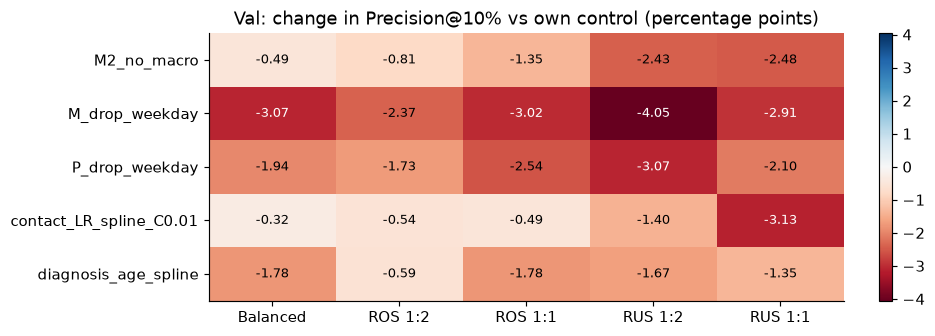

In [14]:
# Historical saved summary: percentage-point differences, not new fits.
delta=pd.DataFrame([[-0.4854368932038833, -0.8090614886731351, -1.3484358144552315, -2.4271844660194137, -2.481121898597624], [-3.0744336569579254, -2.3732470334412032, -3.0204962243797153, -4.045307443365692, -2.912621359223297], [-1.9417475728155305, -1.7259978425026967, -2.535059331175832, -3.0744336569579254, -2.103559870550159], [-0.32362459546925737, -0.5393743257820993, -0.48543689320388883, -1.402373247033445, -3.1283710895361416], [-1.7799352750809072, -0.5933117583603015, -1.7799352750809043, -1.6720604099244891, -1.3484358144552315]],
    index=['M2_no_macro', 'M_drop_weekday', 'P_drop_weekday', 'contact_LR_spline_C0.01', 'diagnosis_age_spline'],
    columns=['balanced', 'ros_1to2', 'ros_1to1', 'rus_1to2', 'rus_1to1'])
fig,ax=plt.subplots(figsize=(9,3.3))
bound=max(1.,float(np.abs(delta.to_numpy()).max()))
im=ax.imshow(delta,vmin=-bound,vmax=bound,cmap='RdBu',aspect='auto')
ax.set(xticks=np.arange(len(delta.columns)),xticklabels=['Balanced','ROS 1:2','ROS 1:1','RUS 1:2','RUS 1:1'],
       yticks=np.arange(len(delta)),yticklabels=delta.index,title='Val: change in Precision@10% vs own control (percentage points)')
for i in range(len(delta)):
    for j in range(len(delta.columns)):ax.text(j,i,f'{delta.iloc[i,j]:+.2f}',ha='center',va='center',fontsize=9,color='white' if abs(delta.iloc[i,j])>bound*.7 else 'black')
fig.colorbar(im,ax=ax,fraction=.04);finish(fig,'07_imbalance_paired')

### 五个LR及三类RF不平衡对照：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6533|0.2055|0.8485|0.2751|0.2584|0.2665|0.7676|0.2857|170|448|488|5072|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|top10|6178|0.1065|—|0.6174|0.1787|0.8398|0.2314|0.2173|0.2241|0.7274|0.2657|143|475|515|5045|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6142|0.1755|0.8385|0.2249|0.2112|0.2179|0.7251|0.2646|139|479|519|5041|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|top10|6178|0.1065|—|0.6161|0.1777|0.8375|0.2201|0.2067|0.2132|0.7227|0.2635|136|482|522|5038|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|top10|6178|0.1065|—|0.5977|0.1727|0.8378|0.2217|0.2082|0.2147|0.3400|0.0942|137|481|521|5039|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6025|0.1751|0.8372|0.2184|0.2052|0.2116|0.3390|0.0941|135|483|523|5037|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|top10|6178|0.1065|—|0.6013|0.1750|0.8385|0.2249|0.2112|0.2179|0.3393|0.0941|139|479|519|5041|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6555|0.2029|0.8488|0.2767|0.2599|0.2680|0.7612|0.2826|171|447|487|5073|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6554|0.2050|0.8478|0.2718|0.2553|0.2633|0.7616|0.2828|168|450|490|5070|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6481|0.2008|0.8478|0.2718|0.2553|0.2633|0.7685|0.2863|168|450|490|5070|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6574|0.2026|0.8475|0.2702|0.2538|0.2618|0.5170|0.1651|167|451|491|5069|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6633|0.2110|0.8495|0.2799|0.2629|0.2712|0.5137|0.1634|173|445|485|5075|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6514|0.2027|0.8472|0.2686|0.2523|0.2602|0.5207|0.1666|166|452|492|5068|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6387|0.1936|0.8478|0.2718|0.2553|0.2633|0.7897|0.2960|168|450|490|5070|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6261|0.1690|0.8388|0.2265|0.2128|0.2194|0.7827|0.2935|140|478|518|5042|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6384|0.1931|0.8420|0.2427|0.2280|0.2351|0.7759|0.2898|150|468|508|5052|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6468|0.2015|0.8488|0.2767|0.2599|0.2680|0.5283|0.1701|171|447|487|5073|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6262|0.1851|0.8430|0.2476|0.2325|0.2398|0.5367|0.1741|153|465|505|5055|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6451|0.2009|0.8472|0.2686|0.2523|0.2602|0.5235|0.1679|166|452|492|5068|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|top10|6178|0.1065|—|0.6079|0.1636|0.8291|0.1780|0.1672|0.1724|0.5000|0.1598|110|508|548|5012|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6093|0.1645|0.8307|0.1861|0.1748|0.1803|0.5008|0.1602|115|503|543|5017|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|top10|6178|0.1065|—|0.6061|0.1629|0.8297|0.1812|0.1702|0.1755|0.5017|0.1606|112|506|546|5014|
|diagnosis_age_spline  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6647|0.1937|0.8385|0.2249|0.2112|0.2179|0.9036|0.3466|139|479|519|5041|
|diagnosis_age_spline  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6583|0.1866|0.8365|0.2152|0.2021|0.2085|0.8521|0.3223|133|485|525|5035|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6648|0.1956|0.8401|0.2330|0.2188|0.2257|0.8914|0.3409|144|474|514|5046|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6620|0.1896|0.8388|0.2265|0.2128|0.2194|0.8758|0.3333|140|478|518|5042|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6641|0.1940|0.8391|0.2282|0.2143|0.2210|0.5648|0.1892|141|477|517|5043|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6717|0.2079|0.8449|0.2573|0.2416|0.2492|0.5915|0.2013|159|459|499|5061|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6676|0.1943|0.8385|0.2249|0.2112|0.2179|0.5925|0.2017|139|479|519|5041|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6676|0.1982|0.8414|0.2395|0.2249|0.2320|0.9863|0.3848|148|470|510|5050|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6190|0.1771|0.8365|0.2152|0.2021|0.2085|1.0210|0.3962|133|485|525|5035|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6634|0.1857|0.8401|0.2330|0.2188|0.2257|0.7829|0.2877|144|474|514|5046|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6684|0.1972|0.8381|0.2233|0.2097|0.2163|0.6079|0.2088|138|480|520|5040|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6437|0.1854|0.8375|0.2201|0.2067|0.2132|0.7023|0.2539|136|482|522|5038|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6678|0.1898|0.8404|0.2346|0.2204|0.2273|0.5529|0.1834|145|473|513|5047|
|M2_no_macro  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6607|0.1985|0.8443|0.2540|0.2386|0.2461|0.6865|0.2409|157|461|501|5059|
|M2_no_macro  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|M2_no_macro  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6546|0.1890|0.8410|0.2379|0.2234|0.2304|0.6700|0.2338|147|471|511|5049|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6597|0.1986|0.8443|0.2540|0.2386|0.2461|0.6660|0.2317|157|461|501|5059|
|M2_no_macro  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6578|0.1921|0.8423|0.2443|0.2295|0.2367|0.6826|0.2390|151|467|507|5053|
|M2_no_macro  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6610|0.1983|0.8423|0.2443|0.2295|0.2367|0.4780|0.1538|151|467|507|5053|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.2100|0.8462|0.2638|0.2477|0.2555|0.4738|0.1524|163|455|495|5065|
|M2_no_macro  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6627|0.1970|0.8423|0.2443|0.2295|0.2367|0.4871|0.1571|151|467|507|5053|
|M2_no_macro  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6670|0.2099|0.8449|0.2573|0.2416|0.2492|0.7114|0.2526|159|459|499|5061|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6248|0.1734|0.8352|0.2087|0.1960|0.2022|0.7799|0.2794|129|489|529|5031|
|M2_no_macro  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6566|0.1861|0.8407|0.2362|0.2219|0.2288|0.6935|0.2433|146|472|512|5048|
|M2_no_macro  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6677|0.2084|0.8423|0.2443|0.2295|0.2367|0.5070|0.1651|151|467|507|5053|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6396|0.1780|0.8385|0.2249|0.2112|0.2179|0.5118|0.1671|139|479|519|5041|
|M2_no_macro  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6624|0.1926|0.8404|0.2346|0.2204|0.2273|0.4875|0.1571|145|473|513|5047|
|M_drop_weekday  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6647|0.1982|0.8410|0.2379|0.2234|0.2304|0.8222|0.3066|147|471|511|5049|
|M_drop_weekday  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6591|0.1920|0.8414|0.2395|0.2249|0.2320|0.7783|0.2859|148|470|510|5050|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.1991|0.8410|0.2379|0.2234|0.2304|0.8030|0.2973|147|471|511|5049|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6632|0.1934|0.8410|0.2379|0.2234|0.2304|0.7895|0.2908|147|471|511|5049|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6629|0.1956|0.8410|0.2379|0.2234|0.2304|0.5334|0.1756|147|471|511|5049|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6711|0.2076|0.8446|0.2557|0.2401|0.2476|0.5606|0.1874|158|460|500|5060|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6693|0.1985|0.8417|0.2411|0.2264|0.2335|0.5594|0.1867|149|469|509|5051|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6745|0.2065|0.8456|0.2605|0.2447|0.2524|0.8495|0.3196|161|457|497|5063|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6278|0.1818|0.8375|0.2201|0.2067|0.2132|0.9707|0.3731|136|482|522|5038|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6667|0.1906|0.8410|0.2379|0.2234|0.2304|0.6797|0.2381|147|471|511|5049|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6682|0.1973|0.8394|0.2298|0.2158|0.2226|0.5630|0.1883|142|476|516|5044|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6553|0.1920|0.8378|0.2217|0.2082|0.2147|0.6549|0.2308|137|481|521|5039|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6682|0.1976|0.8401|0.2330|0.2188|0.2257|0.5273|0.1725|144|474|514|5046|
|P_drop_weekday  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6643|0.2006|0.8433|0.2492|0.2340|0.2414|0.6952|0.2449|154|464|504|5056|
|P_drop_weekday  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6610|0.1960|0.8414|0.2395|0.2249|0.2320|0.6779|0.2375|148|470|510|5050|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.2026|0.8427|0.2460|0.2310|0.2382|0.6753|0.2357|152|466|506|5054|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6634|0.1968|0.8423|0.2443|0.2295|0.2367|0.6907|0.2428|151|467|507|5053|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6641|0.1992|0.8427|0.2460|0.2310|0.2382|0.4817|0.1552|152|466|506|5054|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6703|0.2098|0.8469|0.2670|0.2508|0.2586|0.4791|0.1546|165|453|493|5067|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6688|0.2008|0.8417|0.2411|0.2264|0.2335|0.4906|0.1585|149|469|509|5051|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6732|0.2106|0.8469|0.2670|0.2508|0.2586|0.7225|0.2573|165|453|493|5067|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6413|0.1895|0.8388|0.2265|0.2128|0.2194|0.7851|0.2825|140|478|518|5042|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6649|0.1937|0.8433|0.2492|0.2340|0.2414|0.6976|0.2455|154|464|504|5056|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6683|0.2020|0.8440|0.2524|0.2371|0.2445|0.5118|0.1670|156|462|502|5058|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6581|0.1968|0.8398|0.2314|0.2173|0.2241|0.5169|0.1693|143|475|515|5045|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6673|0.2008|0.8394|0.2298|0.2158|0.2226|0.4900|0.1580|142|476|516|5044|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（2844行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5072|0.0678|0.5038|0.0634|0.4771|0.1119|0.7020|0.2544|125|1848|137|1890|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5072|0.0678|0.8480|0.0675|0.1031|0.0816|0.7020|0.2544|27|373|235|3365|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5013|0.0687|0.6685|0.0625|0.2901|0.1028|0.6480|0.2278|76|1140|186|2598|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5013|0.0687|0.8480|0.0675|0.1031|0.0816|0.6480|0.2278|27|373|235|3365|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5010|0.0680|0.6573|0.0705|0.3473|0.1172|0.6506|0.2290|91|1200|171|2538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5010|0.0680|0.8475|0.0650|0.0992|0.0785|0.6506|0.2290|26|374|236|3364|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5013|0.0683|0.6603|0.0629|0.3015|0.1042|0.6481|0.2279|79|1176|183|2562|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5013|0.0683|0.8490|0.0725|0.1107|0.0876|0.6481|0.2279|29|371|233|3367|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0737|0.9345|—|0.0000|0.0000|0.2650|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5082|0.0737|0.8500|0.0775|0.1183|0.0937|0.2650|0.0625|31|369|231|3369|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5098|0.0730|0.9345|—|0.0000|0.0000|0.2649|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5098|0.0730|0.8475|0.0650|0.0992|0.0785|0.2649|0.0625|26|374|236|3364|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5020|0.0697|0.9345|—|0.0000|0.0000|0.2655|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5020|0.0697|0.8505|0.0800|0.1221|0.0967|0.2655|0.0625|32|368|230|3370|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5056|0.0688|0.5140|0.0647|0.4771|0.1139|0.7022|0.2545|125|1807|137|1931|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5056|0.0688|0.8485|0.0700|0.1069|0.0846|0.7022|0.2545|28|372|234|3366|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5053|0.0676|0.5098|0.0655|0.4885|0.1155|0.7004|0.2536|128|1827|134|1911|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5053|0.0676|0.8495|0.0750|0.1145|0.0906|0.7004|0.2536|30|370|232|3368|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5087|0.0689|0.5055|0.0631|0.4733|0.1114|0.7047|0.2557|124|1840|138|1898|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5087|0.0689|0.8480|0.0675|0.1031|0.0816|0.7047|0.2557|27|373|235|3365|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5058|0.0670|0.9345|—|0.0000|0.0000|0.4582|0.1369|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5058|0.0670|0.8475|0.0650|0.0992|0.0785|0.4582|0.1369|26|374|236|3364|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5078|0.0689|0.9345|—|0.0000|0.0000|0.4562|0.1359|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5078|0.0689|0.8500|0.0775|0.1183|0.0937|0.4562|0.1359|31|369|231|3369|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5071|0.0695|0.9345|—|0.0000|0.0000|0.4570|0.1364|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5071|0.0695|0.8480|0.0675|0.1031|0.0816|0.4570|0.1364|27|373|235|3365|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0677|0.4735|0.0659|0.5344|0.1174|0.7094|0.2580|140|1984|122|1754|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5110|0.0677|0.8460|0.0575|0.0878|0.0695|0.7094|0.2580|23|377|239|3361|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4952|0.0697|0.4540|0.0640|0.5382|0.1144|0.7217|0.2640|141|2063|121|1675|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4952|0.0697|0.8470|0.0625|0.0954|0.0755|0.7217|0.2640|25|375|237|3363|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5145|0.0705|0.4743|0.0668|0.5420|0.1190|0.7155|0.2609|142|1983|120|1755|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5145|0.0705|0.8495|0.0750|0.1145|0.0906|0.7155|0.2609|30|370|232|3368|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5046|0.0696|0.9345|—|0.0000|0.0000|0.4646|0.1399|0|0|262|3738|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5046|0.0696|0.8485|0.0700|0.1069|0.0846|0.4646|0.1399|28|372|234|3366|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4878|0.0672|0.9340|0.0000|0.0000|0.0000|0.4649|0.1402|0|2|262|3736|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4878|0.0672|0.8490|0.0725|0.1107|0.0876|0.4649|0.1402|29|371|233|3367|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5027|0.0698|0.9345|—|0.0000|0.0000|0.4614|0.1384|0|0|262|3738|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5027|0.0698|0.8445|0.0500|0.0763|0.0604|0.4614|0.1384|20|380|242|3358|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5052|0.0686|0.9058|0.0741|0.0382|0.0504|0.3568|0.0999|10|125|252|3613|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5052|0.0686|0.8460|0.0575|0.0878|0.0695|0.3568|0.0999|23|377|239|3361|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0695|0.9103|0.0855|0.0382|0.0528|0.3557|0.0993|10|107|252|3631|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5017|0.0695|0.8485|0.0700|0.1069|0.0846|0.3557|0.0993|28|372|234|3366|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5005|0.0695|0.9062|0.0815|0.0420|0.0554|0.3572|0.0999|11|124|251|3614|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5005|0.0695|0.8470|0.0625|0.0954|0.0755|0.3572|0.0999|25|375|237|3363|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5150|0.0678|0.4133|0.0683|0.6298|0.1233|0.7351|0.2705|165|2250|97|1488|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5150|0.0678|0.8475|0.0650|0.0992|0.0785|0.7351|0.2705|26|374|236|3364|
|diagnosis_age_spline  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5141|0.0680|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|diagnosis_age_spline  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5141|0.0680|0.8485|0.0700|0.1069|0.0846|0.2520|0.0620|28|372|234|3366|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5094|0.0670|0.4218|0.0660|0.5954|0.1189|0.7321|0.2691|156|2207|106|1531|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5094|0.0670|0.8480|0.0675|0.1031|0.0816|0.7321|0.2691|27|373|235|3365|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.4045|0.0670|0.6260|0.1210|0.7342|0.2701|164|2284|98|1454|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8475|0.0650|0.0992|0.0785|0.7342|0.2701|26|374|236|3364|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0675|0.3877|0.0673|0.6489|0.1219|0.7451|0.2753|170|2357|92|1381|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5100|0.0675|0.8495|0.0750|0.1145|0.0906|0.7451|0.2753|30|370|232|3368|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5066|0.0663|0.9220|0.0370|0.0076|0.0127|0.4717|0.1444|2|52|260|3686|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5066|0.0663|0.8465|0.0600|0.0916|0.0725|0.4717|0.1444|24|376|238|3362|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0672|0.9187|0.0299|0.0076|0.0122|0.4699|0.1435|2|65|260|3673|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5104|0.0672|0.8495|0.0750|0.1145|0.0906|0.4699|0.1435|30|370|232|3368|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5073|0.0674|0.9123|0.0505|0.0191|0.0277|0.4941|0.1544|5|94|257|3644|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5073|0.0674|0.8500|0.0775|0.1183|0.0937|0.4941|0.1544|31|369|231|3369|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5131|0.0693|0.3740|0.0638|0.6260|0.1158|0.7833|0.2927|164|2406|98|1332|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5131|0.0693|0.8475|0.0650|0.0992|0.0785|0.7833|0.2927|26|374|236|3364|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5019|0.0699|0.2515|0.0636|0.7595|0.1173|0.8533|0.3264|199|2931|63|807|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5019|0.0699|0.8490|0.0725|0.1107|0.0876|0.8533|0.3264|29|371|233|3367|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5158|0.0689|0.3475|0.0677|0.7023|0.1236|0.8314|0.3140|184|2532|78|1206|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5158|0.0689|0.8485|0.0700|0.1069|0.0846|0.8314|0.3140|28|372|234|3366|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0680|0.8682|0.0712|0.0840|0.0771|0.5129|0.1639|22|287|240|3451|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5133|0.0680|0.8475|0.0650|0.0992|0.0785|0.5129|0.1639|26|374|236|3364|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5043|0.0691|0.8802|0.0843|0.0840|0.0841|0.4981|0.1568|22|239|240|3499|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5043|0.0691|0.8480|0.0675|0.1031|0.0816|0.4981|0.1568|27|373|235|3365|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0670|0.9207|0.0635|0.0153|0.0246|0.4819|0.1487|4|59|258|3679|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5107|0.0670|0.8460|0.0575|0.0878|0.0695|0.4819|0.1487|23|377|239|3361|
|M2_no_macro  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0679|0.4645|0.0648|0.5344|0.1156|0.7136|0.2600|140|2020|122|1718|
|M2_no_macro  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5133|0.0679|0.8475|0.0650|0.0992|0.0785|0.7136|0.2600|26|374|236|3364|
|M2_no_macro  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0682|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|M2_no_macro  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5117|0.0682|0.8495|0.0750|0.1145|0.0906|0.2524|0.0621|30|370|232|3368|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5066|0.0679|0.4545|0.0628|0.5267|0.1123|0.7164|0.2615|138|2058|124|1680|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5066|0.0679|0.8480|0.0675|0.1031|0.0816|0.7164|0.2615|27|373|235|3365|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0673|0.4540|0.0644|0.5420|0.1151|0.7153|0.2609|142|2064|120|1674|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5099|0.0673|0.8485|0.0700|0.1069|0.0846|0.7153|0.2609|28|372|234|3366|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5089|0.0681|0.4672|0.0651|0.5344|0.1161|0.7156|0.2610|140|2009|122|1729|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5089|0.0681|0.8495|0.0750|0.1145|0.0906|0.7156|0.2610|30|370|232|3368|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5034|0.0670|0.9237|0.0222|0.0038|0.0065|0.4681|0.1426|1|44|261|3694|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5034|0.0670|0.8495|0.0750|0.1145|0.0906|0.4681|0.1426|30|370|232|3368|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5085|0.0676|0.9220|0.0370|0.0076|0.0127|0.4655|0.1413|2|52|260|3686|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5085|0.0676|0.8500|0.0775|0.1183|0.0937|0.4655|0.1413|31|369|231|3369|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5070|0.0680|0.9200|0.0469|0.0115|0.0184|0.4675|0.1423|3|61|259|3677|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5070|0.0680|0.8510|0.0825|0.1260|0.0997|0.4675|0.1423|33|367|229|3371|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5134|0.0704|0.4430|0.0662|0.5725|0.1187|0.7483|0.2761|150|2116|112|1622|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5134|0.0704|0.8475|0.0650|0.0992|0.0785|0.7483|0.2761|26|374|236|3364|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4990|0.0695|0.4125|0.0621|0.5649|0.1119|0.7500|0.2775|148|2236|114|1502|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4990|0.0695|0.8505|0.0800|0.1221|0.0967|0.7500|0.2775|32|368|230|3370|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5240|0.0710|0.4723|0.0686|0.5611|0.1222|0.7268|0.2660|147|1996|115|1742|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5240|0.0710|0.8480|0.0675|0.1031|0.0816|0.7268|0.2660|27|373|235|3365|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5126|0.0677|0.8905|0.0644|0.0496|0.0560|0.4885|0.1526|13|189|249|3549|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5126|0.0677|0.8460|0.0575|0.0878|0.0695|0.4885|0.1526|23|377|239|3361|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5015|0.0693|0.9020|0.0779|0.0458|0.0577|0.4791|0.1479|12|142|250|3596|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5015|0.0693|0.8505|0.0800|0.1221|0.0967|0.4791|0.1479|32|368|230|3370|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0679|0.9243|0.0638|0.0115|0.0194|0.4647|0.1406|3|44|259|3694|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5107|0.0679|0.8475|0.0650|0.0992|0.0785|0.4647|0.1406|26|374|236|3364|
|M_drop_weekday  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0662|0.3375|0.0674|0.7099|0.1231|0.7506|0.2782|186|2574|76|1164|
|M_drop_weekday  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5099|0.0662|0.8475|0.0650|0.0992|0.0785|0.7506|0.2782|26|374|236|3364|
|M_drop_weekday  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5096|0.0663|0.9345|—|0.0000|0.0000|0.2508|0.0620|0|0|262|3738|
|M_drop_weekday  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5096|0.0663|0.8470|0.0625|0.0954|0.0755|0.2508|0.0620|25|375|237|3363|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5024|0.0660|0.3675|0.0642|0.6374|0.1166|0.7446|0.2753|167|2435|95|1303|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5024|0.0660|0.8495|0.0750|0.1145|0.0906|0.7446|0.2753|30|370|232|3368|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5060|0.0658|0.3280|0.0659|0.7023|0.1204|0.7474|0.2766|184|2610|78|1128|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5060|0.0658|0.8475|0.0650|0.0992|0.0785|0.7474|0.2766|26|374|236|3364|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0663|0.3435|0.0667|0.6947|0.1217|0.7601|0.2828|182|2546|80|1192|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5082|0.0663|0.8485|0.0700|0.1069|0.0846|0.7601|0.2828|28|372|234|3366|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5008|0.0657|0.9237|0.0222|0.0038|0.0065|0.4774|0.1463|1|44|261|3694|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5008|0.0657|0.8480|0.0675|0.1031|0.0816|0.4774|0.1463|27|373|235|3365|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5064|0.0665|0.9237|0.0000|0.0000|0.0000|0.4775|0.1463|0|43|262|3695|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5064|0.0665|0.8470|0.0625|0.0954|0.0755|0.4775|0.1463|25|375|237|3363|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5060|0.0662|0.9143|0.0549|0.0191|0.0283|0.5038|0.1585|5|86|257|3652|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5060|0.0662|0.8480|0.0675|0.1031|0.0816|0.5038|0.1585|27|373|235|3365|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5130|0.0674|0.2955|0.0680|0.7672|0.1248|0.8001|0.3014|201|2757|61|981|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5130|0.0674|0.8485|0.0700|0.1069|0.0846|0.8001|0.3014|28|372|234|3366|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4903|0.0701|0.2362|0.0629|0.7672|0.1163|0.8565|0.3282|201|2994|61|744|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4903|0.0701|0.8510|0.0825|0.1260|0.0997|0.8565|0.3282|33|367|229|3371|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5182|0.0690|0.3715|0.0689|0.6870|0.1253|0.8018|0.3004|180|2432|82|1306|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5182|0.0690|0.8495|0.0750|0.1145|0.0906|0.8018|0.3004|30|370|232|3368|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5038|0.0659|0.8898|0.0758|0.0611|0.0677|0.5204|0.1668|16|195|246|3543|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5038|0.0659|0.8475|0.0650|0.0992|0.0785|0.5204|0.1668|26|374|236|3364|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4946|0.0675|0.8950|0.0842|0.0611|0.0708|0.5141|0.1637|16|174|246|3564|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4946|0.0675|0.8500|0.0775|0.1183|0.0937|0.5141|0.1637|31|369|231|3369|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5084|0.0664|0.9193|0.0704|0.0191|0.0300|0.4813|0.1482|5|66|257|3672|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5084|0.0664|0.8475|0.0650|0.0992|0.0785|0.4813|0.1482|26|374|236|3364|
|P_drop_weekday  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5097|0.0661|0.4305|0.0659|0.5840|0.1184|0.7221|0.2642|153|2169|109|1569|
|P_drop_weekday  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5097|0.0661|0.8475|0.0650|0.0992|0.0785|0.7221|0.2642|26|374|236|3364|
|P_drop_weekday  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5092|0.0662|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_weekday  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5092|0.0662|0.8475|0.0650|0.0992|0.0785|0.2517|0.0620|26|374|236|3364|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5023|0.0661|0.4355|0.0638|0.5573|0.1145|0.7253|0.2658|146|2142|116|1596|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5023|0.0661|0.8500|0.0775|0.1183|0.0937|0.7253|0.2658|31|369|231|3369|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5058|0.0657|0.4037|0.0655|0.6107|0.1183|0.7225|0.2644|160|2283|102|1455|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5058|0.0657|0.8480|0.0675|0.1031|0.0816|0.7225|0.2644|27|373|235|3365|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5081|0.0663|0.4417|0.0637|0.5496|0.1142|0.7244|0.2653|144|2115|118|1623|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5081|0.0663|0.8485|0.0700|0.1069|0.0846|0.7244|0.2653|28|372|234|3366|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5007|0.0657|0.9240|0.0227|0.0038|0.0065|0.4722|0.1440|1|43|261|3695|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5007|0.0657|0.8485|0.0700|0.1069|0.0846|0.4722|0.1440|28|372|234|3366|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5064|0.0665|0.9247|0.0000|0.0000|0.0000|0.4703|0.1430|0|39|262|3699|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5064|0.0665|0.8475|0.0650|0.0992|0.0785|0.4703|0.1430|26|374|236|3364|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5059|0.0661|0.9207|0.0339|0.0076|0.0125|0.4706|0.1433|2|57|260|3681|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5059|0.0661|0.8470|0.0625|0.0954|0.0755|0.4706|0.1433|25|375|237|3363|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0672|0.3855|0.0664|0.6412|0.1203|0.7510|0.2778|168|2364|94|1374|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5129|0.0672|0.8475|0.0650|0.0992|0.0785|0.7510|0.2778|26|374|236|3364|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4901|0.0698|0.3877|0.0617|0.5878|0.1117|0.7634|0.2840|154|2341|108|1397|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4901|0.0698|0.8500|0.0775|0.1183|0.0937|0.7634|0.2840|31|369|231|3369|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5182|0.0690|0.4300|0.0684|0.6107|0.1231|0.7755|0.2880|160|2178|102|1560|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5182|0.0690|0.8490|0.0725|0.1107|0.0876|0.7755|0.2880|29|371|233|3367|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5036|0.0659|0.9042|0.0647|0.0344|0.0449|0.4962|0.1555|9|130|253|3608|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5036|0.0659|0.8470|0.0625|0.0954|0.0755|0.4962|0.1555|25|375|237|3363|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4944|0.0675|0.9100|0.0847|0.0382|0.0526|0.4885|0.1519|10|108|252|3630|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4944|0.0675|0.8505|0.0800|0.1221|0.0967|0.4885|0.1519|32|368|230|3370|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0664|0.9207|0.0635|0.0153|0.0246|0.4754|0.1455|4|59|258|3679|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5082|0.0664|0.8475|0.0650|0.0992|0.0785|0.4754|0.1455|26|374|236|3364|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5123|0.0605|0.1485|0.0597|0.9267|0.1121|0.9127|0.3566|215|3389|17|379|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5123|0.0605|0.8515|0.0475|0.0819|0.0601|0.9127|0.3566|19|381|213|3387|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5154|0.0604|0.2077|0.0599|0.8621|0.1121|0.8331|0.3183|200|3137|32|631|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|top10|4000|0.0580|—|0.5154|0.0604|0.8555|0.0675|0.1164|0.0854|0.8331|0.3183|27|373|205|3395|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5177|0.0603|0.2040|0.0591|0.8534|0.1106|0.8376|0.3204|198|3150|34|618|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.5177|0.0603|0.8540|0.0600|0.1034|0.0759|0.8376|0.3204|24|376|208|3392|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5222|0.0613|0.2037|0.0591|0.8534|0.1106|0.8383|0.3206|198|3151|34|617|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|top10|4000|0.0580|—|0.5222|0.0613|0.8565|0.0725|0.1250|0.0918|0.8383|0.3206|29|371|203|3397|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.4872|0.0563|0.9420|—|0.0000|0.0000|0.2309|0.0560|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|top10|4000|0.0580|—|0.4872|0.0563|0.8545|0.0625|0.1078|0.0791|0.2309|0.0560|25|375|207|3393|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.4886|0.0580|0.9420|—|0.0000|0.0000|0.2307|0.0559|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.4886|0.0580|0.8555|0.0675|0.1164|0.0854|0.2307|0.0559|27|373|205|3395|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4963|0.0570|0.9420|—|0.0000|0.0000|0.2301|0.0559|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|top10|4000|0.0580|—|0.4963|0.0570|0.8550|0.0650|0.1121|0.0823|0.2301|0.0559|26|374|206|3394|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5063|0.0596|0.1455|0.0595|0.9267|0.1117|0.9098|0.3552|215|3401|17|367|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5063|0.0596|0.8530|0.0550|0.0948|0.0696|0.9098|0.3552|22|378|210|3390|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5064|0.0597|0.1460|0.0595|0.9267|0.1118|0.9198|0.3598|215|3399|17|369|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5064|0.0597|0.8530|0.0550|0.0948|0.0696|0.9198|0.3598|22|378|210|3390|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5128|0.0607|0.1492|0.0597|0.9267|0.1122|0.9085|0.3546|215|3386|17|382|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5128|0.0607|0.8520|0.0500|0.0862|0.0633|0.9085|0.3546|20|380|212|3388|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5124|0.0597|0.8458|0.0471|0.0862|0.0609|0.5934|0.2013|20|405|212|3363|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5124|0.0597|0.8520|0.0500|0.0862|0.0633|0.5934|0.2013|20|380|212|3388|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5068|0.0589|0.8530|0.0436|0.0733|0.0547|0.5948|0.2020|17|373|215|3395|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5068|0.0589|0.8505|0.0425|0.0733|0.0538|0.5948|0.2020|17|383|215|3385|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5067|0.0599|0.8940|0.0514|0.0474|0.0493|0.5900|0.1996|11|203|221|3565|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5067|0.0599|0.8510|0.0450|0.0776|0.0570|0.5900|0.1996|18|382|214|3386|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5295|0.0649|0.1368|0.0591|0.9310|0.1112|0.9331|0.3657|216|3437|16|331|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5295|0.0649|0.8565|0.0725|0.1250|0.0918|0.9331|0.3657|29|371|203|3397|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5006|0.0605|0.1335|0.0589|0.9310|0.1108|0.9673|0.3807|216|3450|16|318|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5006|0.0605|0.8570|0.0750|0.1293|0.0949|0.9673|0.3807|30|370|202|3398|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4911|0.0567|0.1515|0.0586|0.9052|0.1101|0.8916|0.3456|210|3372|22|396|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4911|0.0567|0.8510|0.0450|0.0776|0.0570|0.8916|0.3456|18|382|214|3386|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5222|0.0628|0.8427|0.0559|0.1078|0.0736|0.5982|0.2037|25|422|207|3346|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5222|0.0628|0.8535|0.0575|0.0991|0.0728|0.5982|0.2037|23|377|209|3391|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5009|0.0601|0.7650|0.0575|0.1983|0.0891|0.6132|0.2111|46|754|186|3014|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5009|0.0601|0.8560|0.0700|0.1207|0.0886|0.6132|0.2111|28|372|204|3396|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4917|0.0560|0.8702|0.0473|0.0647|0.0546|0.5829|0.1962|15|302|217|3466|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.4917|0.0560|0.8515|0.0475|0.0819|0.0601|0.5829|0.1962|19|381|213|3387|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5081|0.0599|0.8770|0.0608|0.0776|0.0682|0.4407|0.1334|18|278|214|3490|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|top10|4000|0.0580|—|0.5081|0.0599|0.8545|0.0625|0.1078|0.0791|0.4407|0.1334|25|375|207|3393|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5006|0.0579|0.8798|0.0505|0.0603|0.0550|0.4405|0.1333|14|263|218|3505|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.5006|0.0579|0.8540|0.0600|0.1034|0.0759|0.4405|0.1333|24|376|208|3392|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5027|0.0584|0.8758|0.0569|0.0733|0.0640|0.4430|0.1343|17|282|215|3486|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|top10|4000|0.0580|—|0.5027|0.0584|0.8540|0.0600|0.1034|0.0759|0.4430|0.1343|24|376|208|3392|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5154|0.0610|0.2070|0.0599|0.8621|0.1120|0.8795|0.3395|200|3140|32|628|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5154|0.0610|0.8540|0.0600|0.1034|0.0759|0.8795|0.3395|24|376|208|3392|
|diagnosis_age_spline  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0618|0.9420|—|0.0000|0.0000|0.2247|0.0550|0|0|232|3768|
|diagnosis_age_spline  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5173|0.0618|0.8565|0.0725|0.1250|0.0918|0.2247|0.0550|29|371|203|3397|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0611|0.2092|0.0598|0.8578|0.1118|0.8763|0.3379|199|3130|33|638|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5105|0.0611|0.8550|0.0650|0.1121|0.0823|0.8763|0.3379|26|374|206|3394|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5097|0.0609|0.2042|0.0589|0.8491|0.1101|0.8894|0.3439|197|3148|35|620|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5097|0.0609|0.8545|0.0625|0.1078|0.0791|0.8894|0.3439|25|375|207|3393|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5155|0.0607|0.2140|0.0599|0.8534|0.1119|0.8732|0.3367|198|3110|34|658|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5155|0.0607|0.8540|0.0600|0.1034|0.0759|0.8732|0.3367|24|376|208|3392|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5116|0.0617|0.7695|0.0519|0.1724|0.0798|0.5729|0.1928|40|730|192|3038|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5116|0.0617|0.8540|0.0600|0.1034|0.0759|0.5729|0.1928|24|376|208|3392|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5110|0.0614|0.7708|0.0603|0.2026|0.0930|0.5717|0.1925|47|732|185|3036|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5110|0.0614|0.8535|0.0575|0.0991|0.0728|0.5717|0.1925|23|377|209|3391|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5115|0.0601|0.7795|0.0596|0.1897|0.0907|0.5698|0.1918|44|694|188|3074|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5115|0.0601|0.8545|0.0625|0.1078|0.0791|0.5698|0.1918|25|375|207|3393|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5409|0.0654|0.1605|0.0607|0.9310|0.1140|0.9601|0.3752|216|3342|16|426|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5409|0.0654|0.8560|0.0700|0.1207|0.0886|0.9601|0.3752|28|372|204|3396|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5111|0.0606|0.2195|0.0605|0.8578|0.1131|0.9224|0.3568|199|3089|33|679|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5111|0.0606|0.8565|0.0725|0.1250|0.0918|0.9224|0.3568|29|371|203|3397|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5042|0.0568|0.2650|0.0607|0.8060|0.1129|0.8952|0.3432|187|2895|45|873|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5042|0.0568|0.8510|0.0450|0.0776|0.0570|0.8952|0.3432|18|382|214|3386|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5291|0.0648|0.7310|0.0577|0.2371|0.0927|0.5902|0.2010|55|899|177|2869|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5291|0.0648|0.8550|0.0650|0.1121|0.0823|0.5902|0.2010|26|374|206|3394|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5027|0.0620|0.7318|0.0569|0.2328|0.0914|0.5872|0.2001|54|895|178|2873|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5027|0.0620|0.8570|0.0750|0.1293|0.0949|0.5872|0.2001|30|370|202|3398|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5074|0.0579|0.7310|0.0472|0.1897|0.0756|0.5815|0.1972|44|888|188|2880|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5074|0.0579|0.8525|0.0525|0.0905|0.0665|0.5815|0.1972|21|379|211|3389|
|M2_no_macro  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0624|0.1810|0.0594|0.8836|0.1112|0.9682|0.3796|205|3249|27|519|
|M2_no_macro  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5251|0.0624|0.8545|0.0625|0.1078|0.0791|0.9682|0.3796|25|375|207|3393|
|M2_no_macro  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5272|0.0629|0.9420|—|0.0000|0.0000|0.2258|0.0553|0|0|232|3768|
|M2_no_macro  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5272|0.0629|0.8550|0.0650|0.1121|0.0823|0.2258|0.0553|26|374|206|3394|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0622|0.1815|0.0589|0.8750|0.1103|0.9684|0.3796|203|3245|29|523|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5248|0.0622|0.8540|0.0600|0.1034|0.0759|0.9684|0.3796|24|376|208|3392|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0620|0.1765|0.0588|0.8793|0.1102|0.9760|0.3831|204|3266|28|502|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5197|0.0620|0.8545|0.0625|0.1078|0.0791|0.9760|0.3831|25|375|207|3393|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5239|0.0628|0.1875|0.0595|0.8793|0.1115|0.9728|0.3810|204|3222|28|546|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5239|0.0628|0.8570|0.0750|0.1293|0.0949|0.9728|0.3810|30|370|202|3398|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0625|0.5958|0.0614|0.4181|0.1071|0.6333|0.2225|97|1482|135|2286|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5259|0.0625|0.8540|0.0600|0.1034|0.0759|0.6333|0.2225|24|376|208|3392|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5231|0.0624|0.5795|0.0643|0.4612|0.1129|0.6448|0.2282|107|1557|125|2211|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5231|0.0624|0.8555|0.0675|0.1164|0.0854|0.6448|0.2282|27|373|205|3395|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5227|0.0620|0.5673|0.0620|0.4569|0.1091|0.6465|0.2293|106|1605|126|2163|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5227|0.0620|0.8560|0.0700|0.1207|0.0886|0.6465|0.2293|28|372|204|3396|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5399|0.0656|0.1568|0.0607|0.9353|0.1140|0.9663|0.3783|217|3358|15|410|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5399|0.0656|0.8570|0.0750|0.1293|0.0949|0.9663|0.3783|30|370|202|3398|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5231|0.0611|0.1797|0.0595|0.8879|0.1116|1.0317|0.4045|206|3255|26|513|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5231|0.0611|0.8555|0.0675|0.1164|0.0854|1.0317|0.4045|27|373|205|3395|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5059|0.0581|0.2135|0.0596|0.8491|0.1113|0.9761|0.3797|197|3111|35|657|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5059|0.0581|0.8530|0.0550|0.0948|0.0696|0.9761|0.3797|22|378|210|3390|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5410|0.0654|0.5665|0.0613|0.4526|0.1080|0.6477|0.2292|105|1607|127|2161|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5410|0.0654|0.8570|0.0750|0.1293|0.0949|0.6477|0.2292|30|370|202|3398|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5228|0.0619|0.5280|0.0600|0.4871|0.1069|0.6697|0.2403|113|1769|119|1999|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5228|0.0619|0.8540|0.0600|0.1034|0.0759|0.6697|0.2403|24|376|208|3392|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5099|0.0593|0.5695|0.0571|0.4138|0.1003|0.6409|0.2263|96|1586|136|2182|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5099|0.0593|0.8540|0.0600|0.1034|0.0759|0.6409|0.2263|24|376|208|3392|
|M_drop_weekday  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5147|0.0608|0.1745|0.0597|0.8966|0.1119|0.9392|0.3677|208|3278|24|490|
|M_drop_weekday  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5147|0.0608|0.8555|0.0675|0.1164|0.0854|0.9392|0.3677|27|373|205|3395|
|M_drop_weekday  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5130|0.0605|0.9420|—|0.0000|0.0000|0.2251|0.0551|0|0|232|3768|
|M_drop_weekday  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5130|0.0605|0.8550|0.0650|0.1121|0.0823|0.2251|0.0551|26|374|206|3394|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5096|0.0601|0.1765|0.0598|0.8966|0.1121|0.9386|0.3674|208|3270|24|498|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5096|0.0601|0.8550|0.0650|0.1121|0.0823|0.9386|0.3674|26|374|206|3394|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5069|0.0603|0.1762|0.0598|0.8966|0.1121|0.9451|0.3703|208|3271|24|497|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5069|0.0603|0.8570|0.0750|0.1293|0.0949|0.9451|0.3703|30|370|202|3398|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5160|0.0625|0.1772|0.0596|0.8922|0.1117|0.9468|0.3709|207|3266|25|502|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5160|0.0625|0.8565|0.0725|0.1250|0.0918|0.9468|0.3709|29|371|203|3397|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0597|0.6675|0.0636|0.3448|0.1074|0.6145|0.2130|80|1178|152|2590|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5105|0.0597|0.8540|0.0600|0.1034|0.0759|0.6145|0.2130|24|376|208|3392|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0604|0.6790|0.0595|0.3060|0.0996|0.6157|0.2138|71|1123|161|2645|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5076|0.0604|0.8550|0.0650|0.1121|0.0823|0.6157|0.2138|26|374|206|3394|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5128|0.0607|0.6315|0.0602|0.3664|0.1034|0.6243|0.2183|85|1327|147|2441|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5128|0.0607|0.8555|0.0675|0.1164|0.0854|0.6243|0.2183|27|373|205|3395|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0634|0.1335|0.0592|0.9353|0.1113|0.9611|0.3766|217|3451|15|317|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5259|0.0634|0.8575|0.0775|0.1336|0.0981|0.9611|0.3766|31|369|201|3399|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5147|0.0605|0.1730|0.0601|0.9052|0.1127|1.0231|0.4017|210|3286|22|482|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5147|0.0605|0.8570|0.0750|0.1293|0.0949|1.0231|0.4017|30|370|202|3398|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4946|0.0559|0.2047|0.0595|0.8578|0.1112|0.9437|0.3663|199|3148|33|620|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4946|0.0559|0.8525|0.0525|0.0905|0.0665|0.9437|0.3663|21|379|211|3389|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5274|0.0620|0.7020|0.0588|0.2759|0.0970|0.6161|0.2134|64|1024|168|2744|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5274|0.0620|0.8560|0.0700|0.1207|0.0886|0.6161|0.2134|28|372|204|3396|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5121|0.0611|0.5595|0.0583|0.4353|0.1029|0.6523|0.2318|101|1631|131|2137|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5121|0.0611|0.8560|0.0700|0.1207|0.0886|0.6523|0.2318|28|372|204|3396|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4976|0.0559|0.6927|0.0489|0.2328|0.0808|0.6071|0.2095|54|1051|178|2717|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.4976|0.0559|0.8520|0.0500|0.0862|0.0633|0.6071|0.2095|20|380|212|3388|
|P_drop_weekday  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0617|0.1708|0.0597|0.9009|0.1119|0.9661|0.3793|209|3294|23|474|
|P_drop_weekday  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5179|0.0617|0.8560|0.0700|0.1207|0.0886|0.9661|0.3793|28|372|204|3396|
|P_drop_weekday  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0619|0.9420|—|0.0000|0.0000|0.2258|0.0552|0|0|232|3768|
|P_drop_weekday  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5173|0.0619|0.8570|0.0750|0.1293|0.0949|0.2258|0.0552|30|370|202|3398|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5142|0.0609|0.1740|0.0599|0.9009|0.1123|0.9659|0.3791|209|3281|23|487|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5142|0.0609|0.8560|0.0700|0.1207|0.0886|0.9659|0.3791|28|372|204|3396|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5114|0.0617|0.1730|0.0598|0.9009|0.1122|0.9727|0.3822|209|3285|23|483|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5114|0.0617|0.8570|0.0750|0.1293|0.0949|0.9727|0.3822|30|370|202|3398|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0627|0.1742|0.0594|0.8922|0.1114|0.9718|0.3813|207|3278|25|490|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5179|0.0627|0.8555|0.0675|0.1164|0.0854|0.9718|0.3813|27|373|205|3395|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5134|0.0608|0.6005|0.0627|0.4224|0.1093|0.6328|0.2221|98|1464|134|2304|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5134|0.0608|0.8555|0.0675|0.1164|0.0854|0.6328|0.2221|27|373|205|3395|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5115|0.0620|0.5877|0.0586|0.4052|0.1023|0.6419|0.2267|94|1511|138|2257|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5115|0.0620|0.8575|0.0775|0.1336|0.0981|0.6419|0.2267|31|369|201|3399|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5152|0.0611|0.6075|0.0610|0.4009|0.1059|0.6434|0.2277|93|1431|139|2337|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5152|0.0611|0.8535|0.0575|0.0991|0.0728|0.6434|0.2277|23|377|209|3391|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5243|0.0632|0.1353|0.0590|0.9310|0.1110|0.9521|0.3725|216|3443|16|325|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5243|0.0632|0.8575|0.0775|0.1336|0.0981|0.9521|0.3725|31|369|201|3399|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5202|0.0612|0.1698|0.0598|0.9052|0.1123|1.0525|0.4134|210|3299|22|469|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5202|0.0612|0.8555|0.0675|0.1164|0.0854|1.0525|0.4134|27|373|205|3395|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4973|0.0564|0.2018|0.0595|0.8621|0.1113|0.9593|0.3730|200|3161|32|607|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4973|0.0564|0.8520|0.0500|0.0862|0.0633|0.9593|0.3730|20|380|212|3388|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5329|0.0621|0.6330|0.0629|0.3836|0.1081|0.6321|0.2213|89|1325|143|2443|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5329|0.0621|0.8535|0.0575|0.0991|0.0728|0.6321|0.2213|23|377|209|3391|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5167|0.0613|0.5168|0.0596|0.4957|0.1063|0.6737|0.2422|115|1816|117|1952|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5167|0.0613|0.8550|0.0650|0.1121|0.0823|0.6737|0.2422|26|374|206|3394|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5030|0.0572|0.6265|0.0550|0.3362|0.0945|0.6268|0.2192|78|1340|154|2428|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5030|0.0572|0.8525|0.0525|0.0905|0.0665|0.6268|0.2192|21|379|211|3389|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4843|0.0472|0.1052|0.0469|0.9021|0.0891|0.8502|0.3275|175|3560|19|246|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4843|0.0472|0.8605|0.0450|0.0928|0.0606|0.8502|0.3275|18|382|176|3424|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4702|0.0461|0.2790|0.0462|0.7062|0.0868|0.7874|0.2962|137|2827|57|979|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4702|0.0461|0.8615|0.0500|0.1031|0.0673|0.7874|0.2962|20|380|174|3426|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4737|0.0468|0.2933|0.0477|0.7165|0.0895|0.7829|0.2939|139|2772|55|1034|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4737|0.0468|0.8595|0.0400|0.0825|0.0539|0.7829|0.2939|16|384|178|3422|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4780|0.0473|0.2805|0.0475|0.7268|0.0892|0.7845|0.2948|141|2825|53|981|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4780|0.0473|0.8595|0.0400|0.0825|0.0539|0.7845|0.2948|16|384|178|3422|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4692|0.0449|0.9515|—|0.0000|0.0000|0.2055|0.0477|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4692|0.0449|0.8585|0.0350|0.0722|0.0471|0.2055|0.0477|14|386|180|3420|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4634|0.0441|0.9515|—|0.0000|0.0000|0.2060|0.0478|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4634|0.0441|0.8600|0.0425|0.0876|0.0572|0.2060|0.0478|17|383|177|3423|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4710|0.0455|0.9515|—|0.0000|0.0000|0.2054|0.0477|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4710|0.0455|0.8605|0.0450|0.0928|0.0606|0.2054|0.0477|18|382|176|3424|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4838|0.0476|0.1025|0.0472|0.9124|0.0898|0.8453|0.3252|177|3573|17|233|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4838|0.0476|0.8610|0.0475|0.0979|0.0640|0.8453|0.3252|19|381|175|3425|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4885|0.0472|0.1057|0.0469|0.9021|0.0891|0.8501|0.3274|175|3558|19|248|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4885|0.0472|0.8600|0.0425|0.0876|0.0572|0.8501|0.3274|17|383|177|3423|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4801|0.0467|0.1005|0.0469|0.9072|0.0891|0.8514|0.3281|176|3580|18|226|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4801|0.0467|0.8600|0.0425|0.0876|0.0572|0.8514|0.3281|17|383|177|3423|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4790|0.0475|0.9510|0.0000|0.0000|0.0000|0.5410|0.1752|0|2|194|3804|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4790|0.0475|0.8620|0.0525|0.1082|0.0707|0.5410|0.1752|21|379|173|3427|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4895|0.0480|0.9503|0.0000|0.0000|0.0000|0.5443|0.1768|0|5|194|3801|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4895|0.0480|0.8615|0.0500|0.1031|0.0673|0.5443|0.1768|20|380|174|3426|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4832|0.0478|0.9515|—|0.0000|0.0000|0.5424|0.1758|0|0|194|3806|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4832|0.0478|0.8605|0.0450|0.0928|0.0606|0.5424|0.1758|18|382|176|3424|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4795|0.0469|0.0948|0.0471|0.9175|0.0895|0.9255|0.3627|178|3605|16|201|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4795|0.0469|0.8590|0.0375|0.0773|0.0505|0.9255|0.3627|15|385|179|3421|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4782|0.0508|0.0940|0.0468|0.9124|0.0890|0.8613|0.3325|177|3607|17|199|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4782|0.0508|0.8610|0.0475|0.0979|0.0640|0.8613|0.3325|19|381|175|3425|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5016|0.0580|0.1742|0.0477|0.8454|0.0903|0.8175|0.3111|164|3273|30|533|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5016|0.0580|0.8635|0.0600|0.1237|0.0808|0.8175|0.3111|24|376|170|3430|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4718|0.0466|0.9500|0.0000|0.0000|0.0000|0.5481|0.1787|0|6|194|3800|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4718|0.0466|0.8610|0.0475|0.0979|0.0640|0.5481|0.1787|19|381|175|3425|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4920|0.0506|0.9493|0.0000|0.0000|0.0000|0.5317|0.1708|0|9|194|3797|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4920|0.0506|0.8635|0.0600|0.1237|0.0808|0.5317|0.1708|24|376|170|3430|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4897|0.0532|0.9487|0.1333|0.0103|0.0191|0.5354|0.1727|2|13|192|3793|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4897|0.0532|0.8625|0.0550|0.1134|0.0741|0.5354|0.1727|22|378|172|3428|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0456|0.8550|0.0469|0.1031|0.0645|0.4536|0.1398|20|406|174|3400|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4800|0.0456|0.8605|0.0450|0.0928|0.0606|0.4536|0.1398|18|382|176|3424|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4712|0.0448|0.8565|0.0366|0.0773|0.0497|0.4569|0.1410|15|395|179|3411|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4712|0.0448|0.8590|0.0375|0.0773|0.0505|0.4569|0.1410|15|385|179|3421|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4818|0.0456|0.8508|0.0431|0.0979|0.0598|0.4546|0.1402|19|422|175|3384|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4818|0.0456|0.8600|0.0425|0.0876|0.0572|0.4546|0.1402|17|383|177|3423|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4581|0.0485|0.1253|0.0476|0.8969|0.0905|0.8788|0.3405|174|3479|20|327|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4581|0.0485|0.8590|0.0375|0.0773|0.0505|0.8788|0.3405|15|385|179|3421|
|diagnosis_age_spline  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4601|0.0490|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|diagnosis_age_spline  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4601|0.0490|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4567|0.0471|0.1343|0.0476|0.8866|0.0904|0.8575|0.3303|172|3441|22|365|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4567|0.0471|0.8605|0.0450|0.0928|0.0606|0.8575|0.3303|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4598|0.0483|0.1230|0.0478|0.9021|0.0907|0.8955|0.3483|175|3489|19|317|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4598|0.0483|0.8585|0.0350|0.0722|0.0471|0.8955|0.3483|14|386|180|3420|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4552|0.0478|0.1202|0.0476|0.9021|0.0905|0.8813|0.3418|175|3500|19|306|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4552|0.0478|0.8590|0.0375|0.0773|0.0505|0.8813|0.3418|15|385|179|3421|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4550|0.0474|0.8928|0.0392|0.0515|0.0445|0.5578|0.1839|10|245|184|3561|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4550|0.0474|0.8605|0.0450|0.0928|0.0606|0.5578|0.1839|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4640|0.0476|0.8668|0.0456|0.0876|0.0600|0.5705|0.1901|17|356|177|3450|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4640|0.0476|0.8605|0.0450|0.0928|0.0606|0.5705|0.1901|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4559|0.0454|0.8930|0.0500|0.0670|0.0573|0.5684|0.1889|13|247|181|3559|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4559|0.0454|0.8605|0.0450|0.0928|0.0606|0.5684|0.1889|18|382|176|3424|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4743|0.0480|0.1195|0.0476|0.9021|0.0904|0.9695|0.3818|175|3503|19|303|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4743|0.0480|0.8600|0.0425|0.0876|0.0572|0.9695|0.3818|17|383|177|3423|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4718|0.0524|0.1160|0.0469|0.8918|0.0891|0.9119|0.3547|173|3515|21|291|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4718|0.0524|0.8620|0.0525|0.1082|0.0707|0.9119|0.3547|21|379|173|3427|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4995|0.0543|0.2305|0.0480|0.7887|0.0904|0.8222|0.3124|153|3037|41|769|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4995|0.0543|0.8640|0.0625|0.1289|0.0842|0.8222|0.3124|25|375|169|3431|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4578|0.0476|0.9247|0.0650|0.0412|0.0505|0.5331|0.1722|8|115|186|3691|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4578|0.0476|0.8610|0.0475|0.0979|0.0640|0.5331|0.1722|19|381|175|3425|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4732|0.0504|0.9185|0.0658|0.0515|0.0578|0.5170|0.1646|10|142|184|3664|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4732|0.0504|0.8635|0.0600|0.1237|0.0808|0.5170|0.1646|24|376|170|3430|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4706|0.0470|0.9093|0.0481|0.0464|0.0472|0.5286|0.1701|9|178|185|3628|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4706|0.0470|0.8590|0.0375|0.0773|0.0505|0.5286|0.1701|15|385|179|3421|
|M2_no_macro  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4660|0.0504|0.1192|0.0476|0.9021|0.0904|0.8735|0.3381|175|3504|19|302|
|M2_no_macro  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4660|0.0504|0.8600|0.0425|0.0876|0.0572|0.8735|0.3381|17|383|177|3423|
|M2_no_macro  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4654|0.0506|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M2_no_macro  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4654|0.0506|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4635|0.0496|0.1325|0.0478|0.8918|0.0907|0.8521|0.3279|173|3449|21|357|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4635|0.0496|0.8605|0.0450|0.0928|0.0606|0.8521|0.3279|18|382|176|3424|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4682|0.0502|0.1163|0.0477|0.9072|0.0906|0.8901|0.3460|176|3517|18|289|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4682|0.0502|0.8620|0.0525|0.1082|0.0707|0.8901|0.3460|21|379|173|3427|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4628|0.0492|0.1200|0.0476|0.9021|0.0904|0.8758|0.3393|175|3501|19|305|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4628|0.0492|0.8600|0.0425|0.0876|0.0572|0.8758|0.3393|17|383|177|3423|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4603|0.0492|0.9083|0.0374|0.0361|0.0367|0.5534|0.1818|7|180|187|3626|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4603|0.0492|0.8615|0.0500|0.1031|0.0673|0.5534|0.1818|20|380|174|3426|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4729|0.0507|0.8978|0.0539|0.0670|0.0598|0.5657|0.1878|13|228|181|3578|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4729|0.0507|0.8605|0.0450|0.0928|0.0606|0.5657|0.1878|18|382|176|3424|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4629|0.0481|0.9097|0.0437|0.0412|0.0424|0.5634|0.1865|8|175|186|3631|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4629|0.0481|0.8605|0.0450|0.0928|0.0606|0.5634|0.1865|18|382|176|3424|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0490|0.1192|0.0476|0.9021|0.0904|0.9605|0.3780|175|3504|19|302|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4800|0.0490|0.8595|0.0400|0.0825|0.0539|0.9605|0.3780|16|384|178|3422|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0541|0.1138|0.0470|0.8969|0.0894|0.9016|0.3502|174|3525|20|281|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4800|0.0541|0.8625|0.0550|0.1134|0.0741|0.9016|0.3502|22|378|172|3428|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5079|0.0547|0.2170|0.0472|0.7887|0.0890|0.8178|0.3105|153|3091|41|715|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5079|0.0547|0.8640|0.0625|0.1289|0.0842|0.8178|0.3105|25|375|169|3431|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4649|0.0484|0.9385|0.0667|0.0206|0.0315|0.5260|0.1687|4|56|190|3750|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4649|0.0484|0.8610|0.0475|0.0979|0.0640|0.5260|0.1687|19|381|175|3425|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0528|0.9243|0.0709|0.0464|0.0561|0.5143|0.1632|9|118|185|3688|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4829|0.0528|0.8640|0.0625|0.1289|0.0842|0.5143|0.1632|25|375|169|3431|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4765|0.0472|0.9207|0.0576|0.0412|0.0480|0.5255|0.1685|8|131|186|3675|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4765|0.0472|0.8610|0.0475|0.0979|0.0640|0.5255|0.1685|19|381|175|3425|
|M_drop_weekday  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4789|0.0559|0.1128|0.0472|0.9021|0.0898|0.9053|0.3536|175|3530|19|276|
|M_drop_weekday  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4789|0.0559|0.8635|0.0600|0.1237|0.0808|0.9053|0.3536|24|376|170|3430|
|M_drop_weekday  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0548|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|M_drop_weekday  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4829|0.0548|0.8630|0.0575|0.1186|0.0774|0.1992|0.0467|23|377|171|3429|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4777|0.0546|0.1170|0.0472|0.8969|0.0897|0.8819|0.3425|174|3512|20|294|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4777|0.0546|0.8630|0.0575|0.1186|0.0774|0.8819|0.3425|23|377|171|3429|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4834|0.0545|0.1080|0.0472|0.9072|0.0898|0.9253|0.3629|176|3550|18|256|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4834|0.0545|0.8635|0.0600|0.1237|0.0808|0.9253|0.3629|24|376|170|3430|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4731|0.0555|0.1082|0.0470|0.9021|0.0894|0.9076|0.3548|175|3548|19|258|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4731|0.0555|0.8615|0.0500|0.1031|0.0673|0.9076|0.3548|20|380|174|3426|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4742|0.0546|0.9187|0.0719|0.0567|0.0634|0.5746|0.1918|11|142|183|3664|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4742|0.0546|0.8625|0.0550|0.1134|0.0741|0.5746|0.1918|22|378|172|3428|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4857|0.0546|0.9073|0.0640|0.0670|0.0655|0.5884|0.1986|13|190|181|3616|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4857|0.0546|0.8610|0.0475|0.0979|0.0640|0.5884|0.1986|19|381|175|3425|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4783|0.0533|0.9247|0.0787|0.0515|0.0623|0.5860|0.1973|10|117|184|3689|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4783|0.0533|0.8615|0.0500|0.1031|0.0673|0.5860|0.1973|20|380|174|3426|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4816|0.0523|0.1098|0.0476|0.9124|0.0904|0.9927|0.3929|177|3544|17|262|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4816|0.0523|0.8600|0.0425|0.0876|0.0572|0.9927|0.3929|17|383|177|3423|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4737|0.0562|0.0930|0.0470|0.9175|0.0894|0.9443|0.3707|178|3612|16|194|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4737|0.0562|0.8620|0.0525|0.1082|0.0707|0.9443|0.3707|21|379|173|3427|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0572|0.1935|0.0485|0.8402|0.0918|0.8372|0.3200|163|3195|31|611|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5000|0.0572|0.8645|0.0650|0.1340|0.0875|0.8372|0.3200|26|374|168|3432|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4631|0.0516|0.9323|0.0860|0.0412|0.0557|0.5482|0.1792|8|85|186|3721|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4631|0.0516|0.8630|0.0575|0.1186|0.0774|0.5482|0.1792|23|377|171|3429|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4869|0.0559|0.9220|0.0786|0.0567|0.0659|0.5310|0.1709|11|129|183|3677|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4869|0.0559|0.8630|0.0575|0.1186|0.0774|0.5310|0.1709|23|377|171|3429|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4855|0.0528|0.9260|0.0750|0.0464|0.0573|0.5453|0.1778|9|111|185|3695|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4855|0.0528|0.8635|0.0600|0.1237|0.0808|0.5453|0.1778|24|376|170|3430|
|P_drop_weekday  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4793|0.0560|0.1128|0.0472|0.9021|0.0898|0.9050|0.3534|175|3530|19|276|
|P_drop_weekday  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4793|0.0560|0.8635|0.0600|0.1237|0.0808|0.9050|0.3534|24|376|170|3430|
|P_drop_weekday  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4837|0.0546|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|P_drop_weekday  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4837|0.0546|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4786|0.0547|0.1170|0.0472|0.8969|0.0897|0.8808|0.3420|174|3512|20|294|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4786|0.0547|0.8635|0.0600|0.1237|0.0808|0.8808|0.3420|24|376|170|3430|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4836|0.0545|0.1080|0.0472|0.9072|0.0898|0.9253|0.3629|176|3550|18|256|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4836|0.0545|0.8635|0.0600|0.1237|0.0808|0.9253|0.3629|24|376|170|3430|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4739|0.0556|0.1085|0.0470|0.9021|0.0894|0.9067|0.3544|175|3547|19|259|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4739|0.0556|0.8615|0.0500|0.1031|0.0673|0.9067|0.3544|20|380|174|3426|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4748|0.0547|0.9187|0.0719|0.0567|0.0634|0.5742|0.1916|11|142|183|3664|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4748|0.0547|0.8625|0.0550|0.1134|0.0741|0.5742|0.1916|22|378|172|3428|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4861|0.0546|0.9075|0.0644|0.0670|0.0657|0.5880|0.1985|13|189|181|3617|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4861|0.0546|0.8610|0.0475|0.0979|0.0640|0.5880|0.1985|19|381|175|3425|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4795|0.0533|0.9257|0.0813|0.0515|0.0631|0.5845|0.1966|10|113|184|3693|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4795|0.0533|0.8620|0.0525|0.1082|0.0707|0.5845|0.1966|21|379|173|3427|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4816|0.0523|0.1098|0.0476|0.9124|0.0904|0.9929|0.3930|177|3544|17|262|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4816|0.0523|0.8600|0.0425|0.0876|0.0572|0.9929|0.3930|17|383|177|3423|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4740|0.0562|0.0930|0.0470|0.9175|0.0894|0.9438|0.3705|178|3612|16|194|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4740|0.0562|0.8620|0.0525|0.1082|0.0707|0.9438|0.3705|21|379|173|3427|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4989|0.0571|0.1915|0.0487|0.8454|0.0921|0.8398|0.3213|164|3204|30|602|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4989|0.0571|0.8645|0.0650|0.1340|0.0875|0.8398|0.3213|26|374|168|3432|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4629|0.0515|0.9323|0.0860|0.0412|0.0557|0.5488|0.1795|8|85|186|3721|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4629|0.0515|0.8625|0.0550|0.1134|0.0741|0.5488|0.1795|22|378|172|3428|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4876|0.0560|0.9235|0.0758|0.0515|0.0613|0.5294|0.1701|10|122|184|3684|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4876|0.0560|0.8630|0.0575|0.1186|0.0774|0.5294|0.1701|23|377|171|3429|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4856|0.0529|0.9257|0.0744|0.0464|0.0571|0.5460|0.1781|9|112|185|3694|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4856|0.0529|0.8635|0.0600|0.1237|0.0808|0.5460|0.1781|24|376|170|3430|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5031|0.1190|0.1952|0.0974|0.8233|0.1742|0.7902|0.2980|410|3800|88|533|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5031|0.1190|0.8224|0.1281|0.1245|0.1263|0.7902|0.2980|62|422|436|3911|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4912|0.1069|0.3637|0.0993|0.6406|0.1719|0.7416|0.2739|319|2895|179|1438|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|top10|4831|0.1031|—|0.4912|0.1069|0.8178|0.1054|0.1024|0.1039|0.7416|0.2739|51|433|447|3900|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5008|0.1105|0.3983|0.1031|0.6285|0.1772|0.7342|0.2702|313|2722|185|1611|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5008|0.1105|0.8199|0.1157|0.1124|0.1141|0.7342|0.2702|56|428|442|3905|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4934|0.1093|0.3836|0.0995|0.6185|0.1714|0.7403|0.2732|308|2788|190|1545|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|top10|4831|0.1031|—|0.4934|0.1093|0.8232|0.1322|0.1285|0.1303|0.7403|0.2732|64|420|434|3913|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5022|0.1146|0.8969|—|0.0000|0.0000|0.3610|0.0950|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|top10|4831|0.1031|—|0.5022|0.1146|0.8228|0.1302|0.1265|0.1283|0.3610|0.0950|63|421|435|3912|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5021|0.1176|0.8969|—|0.0000|0.0000|0.3605|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5021|0.1176|0.8232|0.1322|0.1285|0.1303|0.3605|0.0949|64|420|434|3913|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4973|0.1145|0.8969|—|0.0000|0.0000|0.3619|0.0951|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|top10|4831|0.1031|—|0.4973|0.1145|0.8212|0.1219|0.1185|0.1202|0.3619|0.0951|59|425|439|3908|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4985|0.1122|0.1964|0.0970|0.8173|0.1733|0.7866|0.2963|407|3791|91|542|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.4985|0.1122|0.8203|0.1178|0.1145|0.1161|0.7866|0.2963|57|427|441|3906|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5007|0.1176|0.1952|0.0970|0.8193|0.1735|0.7909|0.2983|408|3798|90|535|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5007|0.1176|0.8212|0.1219|0.1185|0.1202|0.7909|0.2983|59|425|439|3908|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5046|0.1179|0.1956|0.0974|0.8233|0.1742|0.7903|0.2980|410|3798|88|535|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5046|0.1179|0.8220|0.1260|0.1225|0.1242|0.7903|0.2980|61|423|437|3910|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1120|0.8971|1.0000|0.0020|0.0040|0.5392|0.1748|1|0|497|4333|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5000|0.1120|0.8216|0.1240|0.1205|0.1222|0.5392|0.1748|60|424|438|3909|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.4928|0.1105|0.8971|1.0000|0.0020|0.0040|0.5390|0.1746|1|0|497|4333|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.4928|0.1105|0.8191|0.1116|0.1084|0.1100|0.5390|0.1746|54|430|444|3903|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5010|0.1180|0.8965|0.2500|0.0020|0.0040|0.5397|0.1750|1|3|497|4330|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5010|0.1180|0.8220|0.1260|0.1225|0.1242|0.5397|0.1750|61|423|437|3910|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4724|0.0961|0.2107|0.0976|0.8072|0.1741|0.8101|0.3074|402|3717|96|616|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.4724|0.0961|0.8145|0.0888|0.0863|0.0876|0.8101|0.3074|43|441|455|3892|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5006|0.1066|0.2058|0.0976|0.8133|0.1743|0.7982|0.3018|405|3744|93|589|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5006|0.1066|0.8195|0.1136|0.1104|0.1120|0.7982|0.3018|55|429|443|3904|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4651|0.1069|0.1991|0.0959|0.8032|0.1713|0.7955|0.3005|400|3771|98|562|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.4651|0.1069|0.8232|0.1322|0.1285|0.1303|0.7955|0.3005|64|420|434|3913|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5050|0.1197|0.8969|0.5000|0.0020|0.0040|0.5412|0.1758|1|1|497|4332|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5050|0.1197|0.8236|0.1343|0.1305|0.1324|0.5412|0.1758|65|419|433|3914|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5054|0.1120|0.8969|—|0.0000|0.0000|0.5285|0.1697|0|0|498|4333|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5054|0.1120|0.8220|0.1260|0.1225|0.1242|0.5285|0.1697|61|423|437|3910|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4912|0.1147|0.8959|0.2727|0.0060|0.0118|0.5411|0.1757|3|8|495|4325|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.4912|0.1147|0.8191|0.1116|0.1084|0.1100|0.5411|0.1757|54|430|444|3903|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5033|0.1151|0.8323|0.1214|0.1004|0.1099|0.4864|0.1533|50|362|448|3971|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|top10|4831|0.1031|—|0.5033|0.1151|0.8216|0.1240|0.1205|0.1222|0.4864|0.1533|60|424|438|3909|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5063|0.1189|0.8361|0.1343|0.1084|0.1200|0.4886|0.1541|54|348|444|3985|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5063|0.1189|0.8253|0.1426|0.1386|0.1405|0.4886|0.1541|69|415|429|3918|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5030|0.1146|0.8315|0.1184|0.0984|0.1075|0.4886|0.1542|49|365|449|3968|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|top10|4831|0.1031|—|0.5030|0.1146|0.8212|0.1219|0.1185|0.1202|0.4886|0.1542|59|425|439|3908|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.6534|0.2422|0.8539|0.2851|0.2771|0.2811|4.7244|0.8781|138|346|360|3987|
|diagnosis_age_spline  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6535|0.2402|0.1033|0.1031|1.0000|0.1869|2.4776|0.6710|498|4332|0|1|
|diagnosis_age_spline  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.6535|0.2402|0.8551|0.2913|0.2831|0.2872|2.4776|0.6710|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6536|0.2432|0.8551|0.2913|0.2831|0.2872|4.4438|0.8741|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6526|0.2381|0.8526|0.2789|0.2711|0.2749|5.0657|0.8827|135|349|363|3984|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6527|0.2427|0.8539|0.2851|0.2771|0.2811|4.8734|0.8804|138|346|360|3987|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6528|0.2424|0.8551|0.2913|0.2831|0.2872|3.8978|0.8548|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.6512|0.2295|0.8543|0.2872|0.2791|0.2831|4.2847|0.8657|139|345|359|3988|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6544|0.2465|0.8543|0.2872|0.2791|0.2831|4.1129|0.8618|139|345|359|3988|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6711|0.2418|0.8617|0.3244|0.3153|0.3198|5.3645|0.8892|157|327|341|4006|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6787|0.2642|0.8621|0.3264|0.3173|0.3218|5.2501|0.8881|158|326|340|4007|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6282|0.1896|0.8332|0.1818|0.1767|0.1792|13.2933|0.8968|88|396|410|3937|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6830|0.2690|0.8650|0.3409|0.3313|0.3360|4.9536|0.8843|165|319|333|4014|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.7148|0.2798|0.8650|0.3409|0.3313|0.3360|4.4948|0.8788|165|319|333|4014|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6361|0.2074|0.8439|0.2355|0.2289|0.2322|8.8970|0.8960|114|370|384|3963|
|M2_no_macro  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5718|0.1898|0.1118|0.1025|0.9819|0.1856|1.0383|0.4124|489|4282|9|51|
|M2_no_macro  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5718|0.1898|0.8348|0.1901|0.1847|0.1874|1.0383|0.4124|92|392|406|3941|
|M2_no_macro  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5746|0.1833|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|M2_no_macro  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.5746|0.1833|0.8348|0.1901|0.1847|0.1874|0.3281|0.0914|92|392|406|3941|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5654|0.1862|0.1105|0.1024|0.9819|0.1854|1.0411|0.4135|489|4288|9|45|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5654|0.1862|0.8365|0.1983|0.1928|0.1955|1.0411|0.4135|96|388|402|3945|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5702|0.1900|0.1103|0.1025|0.9839|0.1857|1.0437|0.4145|490|4290|8|43|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5702|0.1900|0.8348|0.1901|0.1847|0.1874|1.0437|0.4145|92|392|406|3941|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5747|0.1926|0.1103|0.1025|0.9839|0.1857|1.0659|0.4240|490|4290|8|43|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5747|0.1926|0.8373|0.2025|0.1968|0.1996|1.0659|0.4240|98|386|400|3947|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5677|0.1851|0.3250|0.1070|0.7550|0.1874|0.7381|0.2721|376|3139|122|1194|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5677|0.1851|0.8369|0.2004|0.1948|0.1976|0.7381|0.2721|97|387|401|3946|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5658|0.1876|0.3639|0.1097|0.7269|0.1907|0.7241|0.2651|362|2937|136|1396|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5658|0.1876|0.8352|0.1921|0.1867|0.1894|0.7241|0.2651|93|391|405|3942|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5766|0.1937|0.3161|0.1088|0.7831|0.1910|0.7422|0.2740|390|3196|108|1137|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5766|0.1937|0.8361|0.1963|0.1908|0.1935|0.7422|0.2740|95|389|403|3944|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5400|0.1511|0.1199|0.1028|0.9759|0.1861|1.0893|0.4320|486|4240|12|93|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5400|0.1511|0.8294|0.1632|0.1586|0.1609|1.0893|0.4320|79|405|419|3928|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5781|0.1875|0.1178|0.1031|0.9819|0.1866|1.0465|0.4155|489|4253|9|80|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5781|0.1875|0.8369|0.2004|0.1948|0.1976|1.0465|0.4155|97|387|401|3946|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5416|0.1736|0.1105|0.1030|0.9900|0.1866|1.0475|0.4149|493|4292|5|41|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5416|0.1736|0.8390|0.2107|0.2048|0.2077|1.0475|0.4149|102|382|396|3951|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5683|0.1801|0.3150|0.1090|0.7871|0.1915|0.7385|0.2719|392|3203|106|1130|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5683|0.1801|0.8327|0.1798|0.1747|0.1772|0.7385|0.2719|87|397|411|3936|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5744|0.1837|0.4322|0.1152|0.6747|0.1968|0.7119|0.2590|336|2581|162|1752|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5744|0.1837|0.8365|0.1983|0.1928|0.1955|0.7119|0.2590|96|388|402|3945|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5606|0.1722|0.3991|0.1117|0.6948|0.1925|0.7267|0.2652|346|2751|152|1582|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5606|0.1722|0.8361|0.1963|0.1908|0.1935|0.7267|0.2652|95|389|403|3944|
|M_drop_weekday  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.6582|0.2275|0.8518|0.2748|0.2671|0.2709|3.5897|0.8443|133|351|365|3982|
|M_drop_weekday  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6557|0.2242|0.1704|0.1058|0.9458|0.1903|1.3998|0.4346|471|3981|27|352|
|M_drop_weekday  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.6557|0.2242|0.8539|0.2851|0.2771|0.2811|1.3998|0.4346|138|346|360|3987|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6786|0.2351|0.8551|0.2913|0.2831|0.2872|3.2999|0.8330|141|343|357|3990|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6544|0.2230|0.8514|0.2727|0.2651|0.2688|3.8270|0.8533|132|352|366|3981|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6558|0.2283|0.8530|0.2810|0.2731|0.2770|3.8225|0.8532|136|348|362|3985|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6718|0.2356|0.8551|0.2913|0.2831|0.2872|2.8422|0.7906|141|343|357|3990|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.6553|0.2197|0.8534|0.2831|0.2751|0.2790|3.2168|0.8149|137|347|361|3986|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6587|0.2334|0.8547|0.2893|0.2811|0.2851|3.2684|0.8184|140|344|358|3989|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6979|0.2325|0.8572|0.3017|0.2932|0.2974|3.1572|0.8341|146|338|352|3995|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.7186|0.2641|0.8626|0.3285|0.3193|0.3238|2.8888|0.8178|159|325|339|4008|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6236|0.1673|0.8282|0.1570|0.1526|0.1548|11.1230|0.8965|76|408|422|3925|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.7114|0.2663|0.8659|0.3450|0.3353|0.3401|2.7908|0.7999|167|317|331|4016|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.7214|0.2685|0.8646|0.3388|0.3293|0.3340|2.5447|0.7789|164|320|334|4013|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6286|0.1790|0.8385|0.2087|0.2028|0.2057|6.7360|0.8899|101|383|397|3950|
|P_drop_weekday  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5777|0.1923|0.1097|0.1024|0.9839|0.1856|1.0452|0.4155|490|4293|8|40|
|P_drop_weekday  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5777|0.1923|0.8402|0.2169|0.2108|0.2138|1.0452|0.4155|105|379|393|3954|
|P_drop_weekday  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5779|0.1860|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_weekday  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.5779|0.1860|0.8385|0.2087|0.2028|0.2057|0.3278|0.0914|101|383|397|3950|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5736|0.1919|0.1087|0.1023|0.9839|0.1854|1.0495|0.4173|490|4298|8|35|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5736|0.1919|0.8414|0.2231|0.2169|0.2200|1.0495|0.4173|108|376|390|3957|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5714|0.1903|0.1081|0.1024|0.9859|0.1856|1.0512|0.4180|491|4302|7|31|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5714|0.1903|0.8402|0.2169|0.2108|0.2138|1.0512|0.4180|105|379|393|3954|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5825|0.1946|0.1089|0.1024|0.9839|0.1854|1.0713|0.4265|490|4297|8|36|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5825|0.1946|0.8385|0.2087|0.2028|0.2057|1.0713|0.4265|101|383|397|3950|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5763|0.1957|0.2910|0.1105|0.8333|0.1951|0.7429|0.2745|415|3342|83|991|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5763|0.1957|0.8423|0.2273|0.2209|0.2240|0.7429|0.2745|110|374|388|3959|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5604|0.1814|0.3252|0.1094|0.7771|0.1919|0.7297|0.2679|387|3149|111|1184|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5604|0.1814|0.8332|0.1818|0.1767|0.1792|0.7297|0.2679|88|396|410|3937|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5807|0.1958|0.2956|0.1111|0.8333|0.1961|0.7421|0.2739|415|3320|83|1013|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5807|0.1958|0.8406|0.2190|0.2129|0.2159|0.7421|0.2739|106|378|392|3955|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5387|0.1492|0.1172|0.1022|0.9719|0.1850|1.0999|0.4364|484|4251|14|82|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5387|0.1492|0.8303|0.1674|0.1627|0.1650|1.0999|0.4364|81|403|417|3930|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5754|0.1835|0.1136|0.1025|0.9799|0.1856|1.0562|0.4198|488|4272|10|61|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5754|0.1835|0.8356|0.1942|0.1888|0.1914|1.0562|0.4198|94|390|404|3943|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5433|0.1779|0.1101|0.1023|0.9819|0.1853|1.0508|0.4162|489|4290|9|43|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5433|0.1779|0.8410|0.2211|0.2149|0.2179|1.0508|0.4162|107|377|391|3956|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5807|0.1853|0.3030|0.1084|0.7972|0.1908|0.7445|0.2748|397|3266|101|1067|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5807|0.1853|0.8377|0.2045|0.1988|0.2016|0.7445|0.2748|99|385|399|3948|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5819|0.1872|0.4020|0.1167|0.7309|0.2013|0.7189|0.2624|364|2755|134|1578|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5819|0.1872|0.8390|0.2107|0.2048|0.2077|0.7189|0.2624|102|382|396|3951|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5672|0.1767|0.3817|0.1141|0.7390|0.1977|0.7306|0.2670|368|2857|130|1476|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5672|0.1767|0.8390|0.2107|0.2048|0.2077|0.7306|0.2670|102|382|396|3951|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.2055|0.3116|0.1237|0.8982|0.2175|0.7676|0.2857|591|4186|67|1334|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6174|0.1787|0.4801|0.1330|0.7036|0.2238|0.7274|0.2657|463|3017|195|2503|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6142|0.1755|0.4837|0.1311|0.6839|0.2200|0.7251|0.2646|450|2982|208|2538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6161|0.1777|0.4961|0.1333|0.6778|0.2227|0.7227|0.2635|446|2901|212|2619|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.5977|0.1727|0.8933|0.3333|0.0015|0.0030|0.3400|0.0942|1|2|657|5518|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6025|0.1751|0.8935|0.5000|0.0030|0.0060|0.3390|0.0941|2|2|656|5518|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6013|0.1750|0.8933|0.3333|0.0015|0.0030|0.3393|0.0941|1|2|657|5518|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6555|0.2029|0.3360|0.1250|0.8723|0.2187|0.7612|0.2826|574|4018|84|1502|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6554|0.2050|0.3368|0.1248|0.8693|0.2183|0.7616|0.2828|572|4011|86|1509|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6481|0.2008|0.3090|0.1236|0.9012|0.2174|0.7685|0.2863|593|4204|65|1316|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6574|0.2026|0.8750|0.3273|0.1641|0.2186|0.5170|0.1651|108|222|550|5298|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6633|0.2110|0.8788|0.3518|0.1641|0.2238|0.5137|0.1634|108|199|550|5321|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6514|0.2027|0.8747|0.3221|0.1596|0.2134|0.5207|0.1666|105|221|553|5299|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6387|0.1936|0.2957|0.1212|0.8982|0.2136|0.7897|0.2960|591|4284|67|1236|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6261|0.1690|0.2962|0.1222|0.9073|0.2154|0.7827|0.2935|597|4287|61|1233|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6384|0.1931|0.3249|0.1225|0.8663|0.2146|0.7759|0.2898|570|4083|88|1437|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6468|0.2015|0.8747|0.3304|0.1717|0.2260|0.5283|0.1701|113|229|545|5291|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6262|0.1851|0.8737|0.3057|0.1459|0.1975|0.5367|0.1741|96|218|562|5302|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6451|0.2009|0.8796|0.3453|0.1459|0.2051|0.5235|0.1679|96|182|562|5338|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6079|0.1636|0.8111|0.1766|0.2112|0.1924|0.5000|0.1598|139|648|519|4872|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6093|0.1645|0.8111|0.1783|0.2143|0.1946|0.5008|0.1602|141|650|517|4870|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6061|0.1629|0.8106|0.1784|0.2158|0.1953|0.5017|0.1606|142|654|516|4866|
|diagnosis_age_spline  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.1937|0.2719|0.1204|0.9255|0.2131|0.9036|0.3466|609|4449|49|1071|
|diagnosis_age_spline  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6583|0.1866|0.3391|0.1255|0.8723|0.2195|0.8521|0.3223|574|3999|84|1521|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6648|0.1956|0.2927|0.1223|0.9134|0.2157|0.8914|0.3409|601|4313|57|1207|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6620|0.1896|0.3135|0.1240|0.8982|0.2180|0.8758|0.3333|591|4174|67|1346|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.1940|0.7591|0.2001|0.4210|0.2713|0.5648|0.1892|277|1107|381|4413|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6717|0.2079|0.7525|0.2043|0.4574|0.2825|0.5915|0.2013|301|1172|357|4348|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.1943|0.7423|0.1979|0.4650|0.2777|0.5925|0.2017|306|1240|352|4280|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.1982|0.1727|0.1124|0.9818|0.2018|0.9863|0.3848|646|5099|12|421|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6190|0.1771|0.1649|0.1084|0.9468|0.1945|1.0210|0.3962|623|5124|35|396|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6634|0.1857|0.4974|0.1430|0.7447|0.2399|0.7829|0.2877|490|2937|168|2583|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6684|0.1972|0.7292|0.1941|0.4894|0.2779|0.6079|0.2088|322|1337|336|4183|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6437|0.1854|0.5447|0.1436|0.6596|0.2358|0.7023|0.2539|434|2589|224|2931|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6678|0.1898|0.7579|0.2024|0.4331|0.2759|0.5529|0.1834|285|1123|373|4397|
|M2_no_macro  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6607|0.1985|0.7216|0.1869|0.4818|0.2693|0.6865|0.2409|317|1379|341|4141|
|M2_no_macro  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|M2_no_macro  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6546|0.1890|0.7222|0.1836|0.4666|0.2635|0.6700|0.2338|307|1365|351|4155|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6597|0.1986|0.7240|0.1837|0.4620|0.2629|0.6660|0.2317|304|1351|354|4169|
|M2_no_macro  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6578|0.1921|0.7195|0.1821|0.4681|0.2622|0.6826|0.2390|308|1383|350|4137|
|M2_no_macro  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6610|0.1983|0.7614|0.2031|0.4240|0.2746|0.4780|0.1538|279|1095|379|4425|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2100|0.7606|0.2057|0.4362|0.2796|0.4738|0.1524|287|1108|371|4412|
|M2_no_macro  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6627|0.1970|0.7582|0.2035|0.4362|0.2776|0.4871|0.1571|287|1123|371|4397|
|M2_no_macro  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6670|0.2099|0.6782|0.1778|0.5578|0.2697|0.7114|0.2526|367|1697|291|3823|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6248|0.1734|0.6515|0.1601|0.5350|0.2464|0.7799|0.2794|352|1847|306|3673|
|M2_no_macro  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6566|0.1861|0.7153|0.1838|0.4863|0.2668|0.6935|0.2433|320|1421|338|4099|
|M2_no_macro  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6677|0.2084|0.7472|0.1966|0.4453|0.2728|0.5070|0.1651|293|1197|365|4323|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6396|0.1780|0.7389|0.1925|0.4544|0.2705|0.5118|0.1671|299|1254|359|4266|
|M2_no_macro  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6624|0.1926|0.7515|0.1978|0.4362|0.2722|0.4875|0.1571|287|1164|371|4356|
|M_drop_weekday  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.1982|0.3954|0.1311|0.8313|0.2265|0.8222|0.3066|547|3624|111|1896|
|M_drop_weekday  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6591|0.1920|0.4702|0.1379|0.7568|0.2333|0.7783|0.2859|498|3113|160|2407|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.1991|0.4247|0.1327|0.7948|0.2274|0.8030|0.2973|523|3419|135|2101|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6632|0.1934|0.4678|0.1379|0.7614|0.2336|0.7895|0.2908|501|3131|157|2389|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6629|0.1956|0.7579|0.1994|0.4225|0.2710|0.5334|0.1756|278|1116|380|4404|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6711|0.2076|0.7567|0.2048|0.4453|0.2805|0.5606|0.1874|293|1138|365|4382|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6693|0.1985|0.7489|0.1989|0.4483|0.2756|0.5594|0.1867|295|1188|363|4332|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6745|0.2065|0.3639|0.1285|0.8602|0.2236|0.8495|0.3196|566|3838|92|1682|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6278|0.1818|0.2056|0.1119|0.9316|0.1999|0.9707|0.3731|613|4863|45|657|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.1906|0.7111|0.1864|0.5091|0.2729|0.6797|0.2381|335|1462|323|4058|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6682|0.1973|0.7383|0.1928|0.4574|0.2713|0.5630|0.1883|301|1260|357|4260|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6553|0.1920|0.6806|0.1737|0.5319|0.2619|0.6549|0.2308|350|1665|308|3855|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6682|0.1976|0.7504|0.2005|0.4498|0.2774|0.5273|0.1725|296|1180|362|4340|
|P_drop_weekday  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6643|0.2006|0.7169|0.1892|0.5046|0.2752|0.6952|0.2449|332|1423|326|4097|
|P_drop_weekday  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6610|0.1960|0.7171|0.1879|0.4985|0.2729|0.6779|0.2375|328|1418|330|4102|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2026|0.7188|0.1887|0.4970|0.2735|0.6753|0.2357|327|1406|331|4114|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6634|0.1968|0.7167|0.1905|0.5106|0.2775|0.6907|0.2428|336|1428|322|4092|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.1992|0.7596|0.1980|0.4119|0.2674|0.4817|0.1552|271|1098|387|4422|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6703|0.2098|0.7583|0.2003|0.4240|0.2721|0.4791|0.1546|279|1114|379|4406|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2008|0.7540|0.1978|0.4286|0.2706|0.4906|0.1585|282|1144|376|4376|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6732|0.2106|0.6769|0.1768|0.5562|0.2683|0.7225|0.2573|366|1704|292|3816|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6413|0.1895|0.6345|0.1578|0.5608|0.2463|0.7851|0.2825|369|1969|289|3551|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.1937|0.7088|0.1860|0.5137|0.2731|0.6976|0.2455|338|1479|320|4041|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6683|0.2020|0.7409|0.1932|0.4514|0.2706|0.5118|0.1670|297|1240|361|4280|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6581|0.1968|0.7341|0.1877|0.4498|0.2649|0.5169|0.1693|296|1281|362|4239|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6673|0.2008|0.7468|0.1996|0.4574|0.2779|0.4900|0.1580|301|1207|357|4313|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54964155|0.5072|0.0678|0.7837|0.0748|0.2023|0.1092|0.7020|0.2544|53|656|209|3082|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51182885|0.5072|0.0678|0.5753|0.0638|0.4008|0.1100|0.7020|0.2544|105|1542|157|2196|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4888395|0.5072|0.0678|0.4080|0.0652|0.6031|0.1177|0.7020|0.2544|158|2264|104|1474|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52518428|0.5013|0.0687|0.7590|0.0656|0.2023|0.0991|0.6480|0.2278|53|755|209|2983|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48409554|0.5013|0.0687|0.5933|0.0667|0.4008|0.1143|0.6480|0.2278|105|1470|157|2268|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.45354911|0.5013|0.0687|0.4422|0.0691|0.6031|0.1241|0.6480|0.2278|158|2127|104|1611|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52675732|0.5010|0.0680|0.7622|0.0667|0.2023|0.1003|0.6506|0.2290|53|742|209|2996|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49080422|0.5010|0.0680|0.6172|0.0710|0.4008|0.1206|0.6506|0.2290|105|1374|157|2364|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44398604|0.5010|0.0680|0.3915|0.0635|0.6031|0.1149|0.6506|0.2290|158|2330|104|1408|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52491485|0.5013|0.0683|0.7565|0.0648|0.2023|0.0981|0.6481|0.2279|53|765|209|2973|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48226031|0.5013|0.0683|0.5865|0.0655|0.4008|0.1127|0.6481|0.2279|105|1497|157|2241|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44960356|0.5013|0.0683|0.4253|0.0671|0.6031|0.1208|0.6481|0.2279|158|2195|104|1543|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039081453|0.5017|0.0691|0.7760|0.0716|0.2023|0.1058|0.2523|0.0621|53|687|209|3051|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.036014602|0.5017|0.0691|0.5810|0.0647|0.4008|0.1113|0.2523|0.0621|105|1519|157|2219|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034154059|0.5017|0.0691|0.3912|0.0635|0.6031|0.1149|0.2523|0.0621|158|2331|104|1407|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.051895724|0.5082|0.0737|0.7640|0.0673|0.2023|0.1010|0.2650|0.0625|53|735|209|3003|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037826971|0.5082|0.0737|0.6102|0.0697|0.4008|0.1187|0.2650|0.0625|105|1402|157|2336|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.026508168|0.5082|0.0737|0.4288|0.0676|0.6031|0.1215|0.2650|0.0625|158|2181|104|1557|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.051930334|0.5098|0.0730|0.7645|0.0674|0.2023|0.1011|0.2649|0.0625|53|733|209|3005|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037664904|0.5098|0.0730|0.6155|0.0707|0.4008|0.1201|0.2649|0.0625|105|1381|157|2357|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.027450181|0.5098|0.0730|0.4520|0.0703|0.6031|0.1260|0.2649|0.0625|158|2088|104|1650|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.05214385|0.5020|0.0697|0.7578|0.0652|0.2023|0.0986|0.2655|0.0625|53|760|209|2978|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037271576|0.5020|0.0697|0.6030|0.0684|0.4008|0.1168|0.2655|0.0625|105|1431|157|2307|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.026608153|0.5020|0.0697|0.4323|0.0680|0.6031|0.1221|0.2655|0.0625|158|2167|104|1571|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5535404|0.5056|0.0688|0.7810|0.0736|0.2023|0.1079|0.7022|0.2545|53|667|209|3071|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51096386|0.5056|0.0688|0.5777|0.0641|0.4008|0.1106|0.7022|0.2545|105|1532|157|2206|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48782469|0.5056|0.0688|0.4193|0.0665|0.6031|0.1197|0.7022|0.2545|158|2219|104|1519|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5459696|0.5053|0.0676|0.7837|0.0748|0.2023|0.1092|0.7004|0.2536|53|656|209|3082|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50919421|0.5053|0.0676|0.5735|0.0635|0.4008|0.1096|0.7004|0.2536|105|1549|157|2189|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49152012|0.5053|0.0676|0.4175|0.0663|0.6031|0.1194|0.7004|0.2536|158|2226|104|1512|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55297739|0.5087|0.0689|0.7782|0.0725|0.2023|0.1067|0.7047|0.2557|53|678|209|3060|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51232357|0.5087|0.0689|0.5705|0.0630|0.4008|0.1089|0.7047|0.2557|105|1561|157|2177|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48510799|0.5087|0.0689|0.4060|0.0650|0.6031|0.1174|0.7047|0.2557|158|2272|104|1466|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37820212|0.5058|0.0670|0.7827|0.0743|0.2023|0.1087|0.4582|0.1369|53|660|209|3078|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34574353|0.5058|0.0670|0.5825|0.0649|0.4008|0.1117|0.4582|0.1369|105|1513|157|2225|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32108576|0.5058|0.0670|0.4012|0.0649|0.6069|0.1172|0.4582|0.1369|159|2292|103|1446|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37398556|0.5078|0.0689|0.7850|0.0753|0.2023|0.1097|0.4562|0.1359|53|651|209|3087|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34671138|0.5078|0.0689|0.5960|0.0671|0.4008|0.1150|0.4562|0.1359|105|1459|157|2279|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32284111|0.5078|0.0689|0.3992|0.0643|0.6031|0.1162|0.4562|0.1359|158|2299|104|1439|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37814696|0.5071|0.0695|0.7730|0.0705|0.2023|0.1045|0.4570|0.1364|53|699|209|3039|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34457533|0.5071|0.0695|0.5833|0.0650|0.4008|0.1119|0.4570|0.1364|105|1510|157|2228|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31899567|0.5071|0.0695|0.3887|0.0632|0.6031|0.1145|0.4570|0.1364|158|2341|104|1397|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55322993|0.5110|0.0677|0.7422|0.0606|0.2023|0.0932|0.7094|0.2580|53|822|209|2916|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51963788|0.5110|0.0677|0.5853|0.0653|0.4008|0.1124|0.7094|0.2580|105|1502|157|2236|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48831066|0.5110|0.0677|0.4027|0.0647|0.6031|0.1168|0.7094|0.2580|158|2285|104|1453|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58365907|0.4952|0.0697|0.7947|0.0797|0.2023|0.1143|0.7217|0.2640|53|612|209|3126|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52310411|0.4952|0.0697|0.5577|0.0612|0.4008|0.1061|0.7217|0.2640|105|1612|157|2126|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48625866|0.4952|0.0697|0.3847|0.0628|0.6031|0.1138|0.7217|0.2640|158|2357|104|1381|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56415454|0.5145|0.0705|0.7802|0.0733|0.2023|0.1076|0.7155|0.2609|53|670|209|3068|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52012057|0.5145|0.0705|0.5897|0.0661|0.4008|0.1135|0.7155|0.2609|105|1484|157|2254|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49390293|0.5145|0.0705|0.4310|0.0678|0.6031|0.1219|0.7155|0.2609|158|2172|104|1566|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37161279|0.5046|0.0696|0.7315|0.0577|0.2023|0.0898|0.4646|0.1399|53|865|209|2873|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34344046|0.5046|0.0696|0.5535|0.0606|0.4008|0.1052|0.4646|0.1399|105|1629|157|2109|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33152686|0.5046|0.0696|0.4173|0.0662|0.6031|0.1194|0.4646|0.1399|158|2227|104|1511|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38876633|0.4878|0.0672|0.7528|0.0636|0.2023|0.0968|0.4649|0.1402|53|780|209|2958|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35059936|0.4878|0.0672|0.5840|0.0651|0.4008|0.1121|0.4649|0.1402|105|1507|157|2231|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31866331|0.4878|0.0672|0.3770|0.0621|0.6031|0.1125|0.4649|0.1402|158|2388|104|1350|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37725689|0.5027|0.0698|0.7562|0.0647|0.2023|0.0981|0.4614|0.1384|53|766|209|2972|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3499932|0.5027|0.0698|0.5843|0.0652|0.4008|0.1121|0.4614|0.1384|105|1506|157|2232|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32483624|0.5027|0.0698|0.3962|0.0640|0.6031|0.1157|0.4614|0.1384|158|2311|104|1427|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31256541|0.5052|0.0686|0.7635|0.0671|0.2023|0.1008|0.3568|0.0999|53|737|209|3001|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.23289228|0.5052|0.0686|0.6058|0.0694|0.4046|0.1185|0.3568|0.0999|106|1421|156|2317|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17781185|0.5052|0.0686|0.4165|0.0662|0.6031|0.1192|0.3568|0.0999|158|2230|104|1508|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.30644654|0.5017|0.0695|0.7578|0.0652|0.2023|0.0986|0.3557|0.0993|53|760|209|2978|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.24251972|0.5017|0.0695|0.6328|0.0741|0.4008|0.1251|0.3557|0.0993|105|1312|157|2426|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17276163|0.5017|0.0695|0.3985|0.0642|0.6031|0.1161|0.3557|0.0993|158|2302|104|1436|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3167375|0.5005|0.0695|0.7742|0.0710|0.2023|0.1051|0.3572|0.0999|53|694|209|3044|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.24302789|0.5005|0.0695|0.6342|0.0744|0.4008|0.1255|0.3572|0.0999|105|1306|157|2432|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17253196|0.5005|0.0695|0.3987|0.0643|0.6031|0.1161|0.3572|0.0999|158|2301|104|1437|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58001796|0.5150|0.0678|0.7570|0.0650|0.2023|0.0983|0.7351|0.2705|53|763|209|2975|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54101609|0.5150|0.0678|0.6032|0.0684|0.4008|0.1169|0.7351|0.2705|105|1430|157|2308|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5033453|0.5150|0.0678|0.4280|0.0675|0.6031|0.1214|0.7351|0.2705|158|2184|104|1554|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.046792941|0.5141|0.0680|0.7708|0.0696|0.2023|0.1036|0.2520|0.0620|53|708|209|3030|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039434924|0.5141|0.0680|0.5903|0.0662|0.4008|0.1136|0.2520|0.0620|105|1482|157|2256|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034620561|0.5141|0.0680|0.4258|0.0672|0.6031|0.1209|0.2520|0.0620|158|2193|104|1545|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58986911|0.5094|0.0670|0.7825|0.0742|0.2023|0.1086|0.7321|0.2691|53|661|209|3077|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53877466|0.5094|0.0670|0.5930|0.0666|0.4008|0.1143|0.7321|0.2691|105|1471|157|2267|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49959003|0.5094|0.0670|0.4208|0.0666|0.6031|0.1200|0.7321|0.2691|158|2213|104|1525|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57860254|0.5110|0.0667|0.7635|0.0671|0.2023|0.1008|0.7342|0.2701|53|737|209|3001|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5394801|0.5110|0.0667|0.5933|0.0667|0.4008|0.1143|0.7342|0.2701|105|1470|157|2268|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50639356|0.5110|0.0667|0.4407|0.0690|0.6031|0.1238|0.7342|0.2701|158|2133|104|1605|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58407827|0.5100|0.0675|0.7485|0.0624|0.2023|0.0953|0.7451|0.2753|53|797|209|2941|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5451735|0.5100|0.0675|0.5985|0.0676|0.4008|0.1156|0.7451|0.2753|105|1449|157|2289|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50738088|0.5100|0.0675|0.4248|0.0671|0.6031|0.1207|0.7451|0.2753|158|2197|104|1541|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40726023|0.5066|0.0663|0.7745|0.0710|0.2023|0.1052|0.4717|0.1444|53|693|209|3045|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36365092|0.5066|0.0663|0.5942|0.0668|0.4008|0.1146|0.4717|0.1444|105|1466|157|2272|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32813444|0.5066|0.0663|0.4225|0.0668|0.6031|0.1203|0.4717|0.1444|158|2206|104|1532|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40030681|0.5104|0.0672|0.7628|0.0668|0.2023|0.1005|0.4699|0.1435|53|740|209|2998|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35898299|0.5104|0.0672|0.5765|0.0639|0.4008|0.1103|0.4699|0.1435|105|1537|157|2201|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33153955|0.5104|0.0672|0.4305|0.0678|0.6031|0.1218|0.4699|0.1435|158|2174|104|1564|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42527708|0.5073|0.0674|0.7792|0.0729|0.2023|0.1072|0.4941|0.1544|53|674|209|3064|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37921841|0.5073|0.0674|0.5890|0.0660|0.4008|0.1133|0.4941|0.1544|105|1487|157|2251|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34798822|0.5073|0.0674|0.4238|0.0670|0.6031|0.1206|0.4941|0.1544|158|2201|104|1537|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.62520243|0.5131|0.0693|0.7668|0.0682|0.2023|0.1020|0.7833|0.2927|53|724|209|3014|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56597143|0.5131|0.0693|0.5958|0.0671|0.4008|0.1149|0.7833|0.2927|105|1460|157|2278|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50998243|0.5131|0.0693|0.4083|0.0653|0.6031|0.1178|0.7833|0.2927|158|2263|104|1475|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.66631409|0.5019|0.0699|0.7885|0.0768|0.2023|0.1113|0.8533|0.3264|53|637|209|3101|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.59772233|0.5019|0.0699|0.5797|0.0645|0.4008|0.1111|0.8533|0.3264|105|1524|157|2214|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54997297|0.5019|0.0699|0.4165|0.0662|0.6031|0.1192|0.8533|0.3264|158|2230|104|1508|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.65913826|0.5158|0.0689|0.7758|0.0715|0.2023|0.1057|0.8314|0.3140|53|688|209|3050|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58683816|0.5158|0.0689|0.6182|0.0712|0.4008|0.1209|0.8314|0.3140|105|1370|157|2368|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52735274|0.5158|0.0689|0.4310|0.0678|0.6031|0.1219|0.8314|0.3140|158|2172|104|1566|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44354724|0.5133|0.0680|0.7562|0.0647|0.2023|0.0981|0.5129|0.1639|53|766|209|2972|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3972195|0.5133|0.0680|0.5925|0.0665|0.4008|0.1141|0.5129|0.1639|105|1473|157|2265|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35281457|0.5133|0.0680|0.4260|0.0672|0.6031|0.1210|0.5129|0.1639|158|2192|104|1546|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44119725|0.5043|0.0691|0.7762|0.0717|0.2023|0.1059|0.4981|0.1568|53|686|209|3052|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38139847|0.5043|0.0691|0.5897|0.0661|0.4008|0.1135|0.4981|0.1568|105|1484|157|2254|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33751646|0.5043|0.0691|0.4198|0.0665|0.6031|0.1198|0.4981|0.1568|158|2217|104|1521|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40465559|0.5107|0.0670|0.7388|0.0596|0.2023|0.0921|0.4819|0.1487|53|836|209|2902|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37840425|0.5107|0.0670|0.6288|0.0733|0.4008|0.1239|0.4819|0.1487|105|1328|157|2410|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34050662|0.5107|0.0670|0.4315|0.0679|0.6031|0.1220|0.4819|0.1487|158|2170|104|1568|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57792586|0.5133|0.0679|0.7887|0.0769|0.2023|0.1115|0.7136|0.2600|53|636|209|3102|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5306372|0.5133|0.0679|0.6000|0.0678|0.4008|0.1160|0.7136|0.2600|105|1443|157|2295|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48873446|0.5133|0.0679|0.4170|0.0662|0.6031|0.1193|0.7136|0.2600|158|2228|104|1510|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.04633606|0.5117|0.0682|0.7890|0.0770|0.2023|0.1116|0.2524|0.0621|53|635|209|3103|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.038118455|0.5117|0.0682|0.5673|0.0625|0.4008|0.1082|0.2524|0.0621|105|1574|157|2164|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.033902177|0.5117|0.0682|0.4260|0.0672|0.6031|0.1210|0.2524|0.0621|158|2192|104|1546|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57898754|0.5066|0.0679|0.7835|0.0746|0.2023|0.1091|0.7164|0.2615|53|657|209|3081|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5258779|0.5066|0.0679|0.5665|0.0624|0.4008|0.1080|0.7164|0.2615|105|1577|157|2161|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48903656|0.5066|0.0679|0.4103|0.0655|0.6031|0.1181|0.7164|0.2615|158|2255|104|1483|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57175128|0.5099|0.0673|0.7827|0.0743|0.2023|0.1087|0.7153|0.2609|53|660|209|3078|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.523864|0.5099|0.0673|0.5650|0.0622|0.4008|0.1077|0.7153|0.2609|105|1583|157|2155|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49119703|0.5099|0.0673|0.4153|0.0660|0.6031|0.1190|0.7153|0.2609|158|2235|104|1503|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57912739|0.5089|0.0681|0.7913|0.0781|0.2023|0.1126|0.7156|0.2610|53|626|209|3112|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.525409|0.5089|0.0681|0.5757|0.0638|0.4008|0.1101|0.7156|0.2610|105|1540|157|2198|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48731536|0.5089|0.0681|0.4070|0.0651|0.6031|0.1176|0.7156|0.2610|158|2268|104|1470|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40443982|0.5034|0.0670|0.7833|0.0745|0.2023|0.1089|0.4681|0.1426|53|658|209|3080|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35823294|0.5034|0.0670|0.5745|0.0636|0.4008|0.1098|0.4681|0.1426|105|1545|157|2193|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32357395|0.5034|0.0670|0.3912|0.0635|0.6031|0.1149|0.4681|0.1426|158|2331|104|1407|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4024109|0.5085|0.0676|0.7950|0.0798|0.2023|0.1145|0.4655|0.1413|53|611|209|3127|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35657451|0.5085|0.0676|0.5800|0.0645|0.4008|0.1111|0.4655|0.1413|105|1523|157|2215|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32532328|0.5085|0.0676|0.4073|0.0652|0.6031|0.1176|0.4655|0.1413|158|2267|104|1471|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39776026|0.5070|0.0680|0.7670|0.0683|0.2023|0.1021|0.4675|0.1423|53|723|209|3015|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35477071|0.5070|0.0680|0.5623|0.0618|0.4008|0.1071|0.4675|0.1423|105|1594|157|2144|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32235026|0.5070|0.0680|0.4027|0.0647|0.6031|0.1168|0.4675|0.1423|158|2285|104|1453|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60394455|0.5134|0.0704|0.7642|0.0673|0.2023|0.1010|0.7483|0.2761|53|734|209|3004|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55123707|0.5134|0.0704|0.6068|0.0690|0.4008|0.1178|0.7483|0.2761|105|1416|157|2322|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4890959|0.5134|0.0704|0.4035|0.0648|0.6031|0.1170|0.7483|0.2761|158|2282|104|1456|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60476576|0.4990|0.0695|0.7700|0.0694|0.2023|0.1033|0.7500|0.2775|53|711|209|3027|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54428675|0.4990|0.0695|0.5817|0.0648|0.4008|0.1115|0.7500|0.2775|105|1516|157|2222|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49338447|0.4990|0.0695|0.3890|0.0633|0.6031|0.1145|0.7500|0.2775|158|2340|104|1398|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58206842|0.5240|0.0710|0.7802|0.0733|0.2023|0.1076|0.7268|0.2660|53|670|209|3068|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53060303|0.5240|0.0710|0.6225|0.0720|0.4008|0.1221|0.7268|0.2660|105|1353|157|2385|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48921521|0.5240|0.0710|0.4228|0.0669|0.6031|0.1204|0.7268|0.2660|158|2205|104|1533|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42516532|0.5126|0.0677|0.7600|0.0659|0.2023|0.0994|0.4885|0.1526|53|751|209|2987|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37725768|0.5126|0.0677|0.5893|0.0660|0.4008|0.1133|0.4885|0.1526|105|1486|157|2252|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33321889|0.5126|0.0677|0.4198|0.0665|0.6031|0.1198|0.4885|0.1526|158|2217|104|1521|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42214792|0.5015|0.0693|0.7817|0.0739|0.2023|0.1083|0.4791|0.1479|53|664|209|3074|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3651195|0.5015|0.0693|0.5905|0.0662|0.4008|0.1136|0.4791|0.1479|105|1481|157|2257|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32680508|0.5015|0.0693|0.4230|0.0669|0.6031|0.1204|0.4791|0.1479|158|2204|104|1534|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38664522|0.5107|0.0679|0.7388|0.0596|0.2023|0.0921|0.4647|0.1406|53|836|209|2902|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35805382|0.5107|0.0679|0.6012|0.0680|0.4008|0.1163|0.4647|0.1406|105|1438|157|2300|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.328884|0.5107|0.0679|0.4380|0.0686|0.6031|0.1232|0.4647|0.1406|158|2144|104|1594|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58052584|0.5099|0.0662|0.7555|0.0645|0.2023|0.0978|0.7506|0.2782|53|769|209|2969|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54164343|0.5099|0.0662|0.5962|0.0672|0.4008|0.1151|0.7506|0.2782|105|1458|157|2280|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51441848|0.5099|0.0662|0.4225|0.0668|0.6031|0.1203|0.7506|0.2782|158|2206|104|1532|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.046159055|0.5096|0.0663|0.7528|0.0636|0.2023|0.0968|0.2508|0.0620|53|780|209|2958|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.040427016|0.5096|0.0663|0.6072|0.0691|0.4008|0.1179|0.2508|0.0620|105|1414|157|2324|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.035851606|0.5096|0.0663|0.4168|0.0662|0.6031|0.1193|0.2508|0.0620|158|2229|104|1509|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58088963|0.5024|0.0660|0.7545|0.0642|0.2023|0.0974|0.7446|0.2753|53|773|209|2965|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53875123|0.5024|0.0660|0.5950|0.0670|0.4008|0.1148|0.7446|0.2753|105|1463|157|2275|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50559753|0.5024|0.0660|0.4047|0.0649|0.6031|0.1172|0.7446|0.2753|158|2277|104|1461|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57433052|0.5060|0.0658|0.7522|0.0635|0.2023|0.0966|0.7474|0.2766|53|782|209|2956|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53769282|0.5060|0.0658|0.5840|0.0651|0.4008|0.1121|0.7474|0.2766|105|1507|157|2231|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51507164|0.5060|0.0658|0.4143|0.0659|0.6031|0.1188|0.7474|0.2766|158|2239|104|1499|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58960807|0.5082|0.0663|0.7582|0.0654|0.2023|0.0988|0.7601|0.2828|53|758|209|2980|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54701571|0.5082|0.0663|0.5820|0.0648|0.4008|0.1116|0.7601|0.2828|105|1515|157|2223|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51413772|0.5082|0.0663|0.4180|0.0663|0.6031|0.1195|0.7601|0.2828|158|2224|104|1514|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39704385|0.5008|0.0657|0.7442|0.0611|0.2023|0.0939|0.4774|0.1463|53|814|209|2924|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36415006|0.5008|0.0657|0.5955|0.0670|0.4008|0.1149|0.4774|0.1463|105|1461|157|2277|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33318426|0.5008|0.0657|0.4000|0.0644|0.6031|0.1163|0.4774|0.1463|158|2296|104|1442|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3980649|0.5064|0.0665|0.7760|0.0716|0.2023|0.1058|0.4775|0.1463|53|687|209|3051|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36757746|0.5064|0.0665|0.6085|0.0694|0.4008|0.1182|0.4775|0.1463|105|1409|157|2329|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33944315|0.5064|0.0665|0.4095|0.0654|0.6031|0.1180|0.4775|0.1463|158|2258|104|1480|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42581354|0.5060|0.0662|0.7712|0.0698|0.2023|0.1038|0.5038|0.1585|53|706|209|3032|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38380733|0.5060|0.0662|0.5790|0.0643|0.4008|0.1109|0.5038|0.1585|105|1527|157|2211|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35581493|0.5060|0.0662|0.4265|0.0673|0.6031|0.1211|0.5038|0.1585|158|2190|104|1548|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.61927524|0.5130|0.0674|0.7665|0.0681|0.2023|0.1019|0.8001|0.3014|53|725|209|3013|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56462139|0.5130|0.0674|0.5773|0.0641|0.4008|0.1105|0.8001|0.3014|105|1534|157|2204|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53387988|0.5130|0.0674|0.4243|0.0670|0.6031|0.1207|0.8001|0.3014|158|2199|104|1539|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.65948313|0.4903|0.0701|0.7765|0.0718|0.2023|0.1060|0.8565|0.3282|53|685|209|3053|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60173787|0.4903|0.0701|0.5910|0.0663|0.4008|0.1138|0.8565|0.3282|105|1479|157|2259|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5457008|0.4903|0.0701|0.3837|0.0627|0.6031|0.1136|0.8565|0.3282|158|2361|104|1377|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.63649526|0.5182|0.0690|0.7788|0.0727|0.2023|0.1070|0.8018|0.3004|53|676|209|3062|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56545294|0.5182|0.0690|0.6145|0.0705|0.4008|0.1199|0.8018|0.3004|105|1385|157|2353|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5162242|0.5182|0.0690|0.4400|0.0689|0.6031|0.1236|0.8018|0.3004|158|2136|104|1602|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44435099|0.5038|0.0659|0.7532|0.0638|0.2023|0.0970|0.5204|0.1668|53|778|209|2960|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39310296|0.5038|0.0659|0.5725|0.0633|0.4008|0.1094|0.5204|0.1668|105|1553|157|2185|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36438515|0.5038|0.0659|0.4068|0.0651|0.6031|0.1175|0.5204|0.1668|158|2269|104|1469|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44798213|0.4946|0.0675|0.7688|0.0689|0.2023|0.1028|0.5141|0.1637|53|716|209|3022|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39034237|0.4946|0.0675|0.5800|0.0645|0.4008|0.1111|0.5141|0.1637|105|1523|157|2215|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3504845|0.4946|0.0675|0.3897|0.0633|0.6031|0.1146|0.5141|0.1637|158|2337|104|1401|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40546301|0.5084|0.0664|0.7562|0.0647|0.2023|0.0981|0.4813|0.1482|53|766|209|2972|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36681917|0.5084|0.0664|0.5810|0.0647|0.4008|0.1113|0.4813|0.1482|105|1519|157|2219|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33863264|0.5084|0.0664|0.4208|0.0666|0.6031|0.1200|0.4813|0.1482|158|2213|104|1525|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56474591|0.5097|0.0661|0.7542|0.0641|0.2023|0.0973|0.7221|0.2642|53|774|209|2964|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52540691|0.5097|0.0661|0.5942|0.0668|0.4008|0.1146|0.7221|0.2642|105|1466|157|2272|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49864542|0.5097|0.0661|0.4233|0.0669|0.6031|0.1205|0.7221|0.2642|158|2203|104|1535|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.044893616|0.5092|0.0662|0.7575|0.0651|0.2023|0.0985|0.2517|0.0620|53|761|209|2977|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039075563|0.5092|0.0662|0.6050|0.0687|0.4008|0.1173|0.2517|0.0620|105|1423|157|2315|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034661076|0.5092|0.0662|0.4140|0.0659|0.6031|0.1188|0.2517|0.0620|158|2240|104|1498|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57009911|0.5023|0.0661|0.7532|0.0638|0.2023|0.0970|0.7253|0.2658|53|778|209|2960|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52776375|0.5023|0.0661|0.5940|0.0668|0.4008|0.1145|0.7253|0.2658|105|1467|157|2271|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49456454|0.5023|0.0661|0.4030|0.0647|0.6031|0.1169|0.7253|0.2658|158|2284|104|1454|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56078873|0.5058|0.0657|0.7528|0.0636|0.2023|0.0968|0.7225|0.2644|53|780|209|2958|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52348251|0.5058|0.0657|0.5827|0.0649|0.4008|0.1118|0.7225|0.2644|105|1512|157|2226|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50123566|0.5058|0.0657|0.4143|0.0659|0.6031|0.1188|0.7225|0.2644|158|2239|104|1499|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56940102|0.5081|0.0663|0.7535|0.0639|0.2023|0.0971|0.7244|0.2653|53|777|209|2961|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52797877|0.5081|0.0663|0.5847|0.0653|0.4008|0.1122|0.7244|0.2653|105|1504|157|2234|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49589195|0.5081|0.0663|0.4223|0.0668|0.6031|0.1203|0.7244|0.2653|158|2207|104|1531|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39286313|0.5007|0.0657|0.7452|0.0614|0.2023|0.0942|0.4722|0.1440|53|810|209|2928|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35956813|0.5007|0.0657|0.5942|0.0668|0.4008|0.1146|0.4722|0.1440|105|1466|157|2272|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32873254|0.5007|0.0657|0.3992|0.0643|0.6031|0.1162|0.4722|0.1440|158|2299|104|1439|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39197539|0.5064|0.0665|0.7770|0.0720|0.2023|0.1062|0.4703|0.1430|53|683|209|3055|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36139889|0.5064|0.0665|0.6068|0.0690|0.4008|0.1178|0.4703|0.1430|105|1416|157|2322|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33347452|0.5064|0.0665|0.4085|0.0656|0.6069|0.1185|0.4703|0.1430|159|2263|103|1475|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39793645|0.5059|0.0661|0.7705|0.0696|0.2023|0.1035|0.4706|0.1433|53|709|209|3029|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35896685|0.5059|0.0661|0.5897|0.0661|0.4008|0.1135|0.4706|0.1433|105|1484|157|2254|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32975953|0.5059|0.0661|0.4225|0.0668|0.6031|0.1203|0.4706|0.1433|158|2206|104|1532|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.59451864|0.5129|0.0672|0.7665|0.0681|0.2023|0.1019|0.7510|0.2778|53|725|209|3013|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53956912|0.5129|0.0672|0.5815|0.0647|0.4008|0.1115|0.7510|0.2778|105|1517|157|2221|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50702389|0.5129|0.0672|0.4210|0.0667|0.6031|0.1201|0.7510|0.2778|158|2212|104|1526|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.61436512|0.4901|0.0698|0.7765|0.0718|0.2023|0.1060|0.7634|0.2840|53|685|209|3053|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55255938|0.4901|0.0698|0.5827|0.0649|0.4008|0.1118|0.7634|0.2840|105|1512|157|2226|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49836357|0.4901|0.0698|0.3835|0.0627|0.6031|0.1136|0.7634|0.2840|158|2362|104|1376|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.62336583|0.5182|0.0690|0.7780|0.0724|0.2023|0.1066|0.7755|0.2880|53|679|209|3059|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55220147|0.5182|0.0690|0.6145|0.0705|0.4008|0.1199|0.7755|0.2880|105|1385|157|2353|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50165476|0.5182|0.0690|0.4373|0.0685|0.6031|0.1231|0.7755|0.2880|158|2147|104|1591|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42516976|0.5036|0.0659|0.7550|0.0643|0.2023|0.0976|0.4962|0.1555|53|771|209|2967|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37456036|0.5036|0.0659|0.5740|0.0636|0.4008|0.1097|0.4962|0.1555|105|1547|157|2191|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34545348|0.5036|0.0659|0.4040|0.0652|0.6069|0.1177|0.4962|0.1555|159|2281|103|1457|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42752134|0.4944|0.0675|0.7738|0.0708|0.2023|0.1048|0.4885|0.1519|53|696|209|3042|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37171864|0.4944|0.0675|0.5855|0.0654|0.4008|0.1124|0.4885|0.1519|105|1501|157|2237|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33110159|0.4944|0.0675|0.3885|0.0632|0.6031|0.1144|0.4885|0.1519|158|2342|104|1396|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40055236|0.5082|0.0664|0.7555|0.0645|0.2023|0.0978|0.4754|0.1455|53|769|209|2969|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36195802|0.5082|0.0664|0.5797|0.0645|0.4008|0.1111|0.4754|0.1455|105|1524|157|2214|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33363514|0.5082|0.0664|0.4185|0.0664|0.6031|0.1196|0.4754|0.1455|158|2222|104|1516|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65475048|0.5123|0.0605|0.7853|0.0652|0.2026|0.0986|0.9127|0.3566|47|674|185|3094|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54964155|0.5123|0.0605|0.1810|0.0591|0.8793|0.1107|0.9127|0.3566|204|3248|28|520|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63345177|0.5123|0.0605|0.6210|0.0633|0.4009|0.1093|0.9127|0.3566|93|1377|139|2391|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51182885|0.5123|0.0605|0.1555|0.0599|0.9224|0.1125|0.9127|0.3566|214|3360|18|408|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60789191|0.5123|0.0605|0.4135|0.0585|0.6034|0.1066|0.9127|0.3566|140|2254|92|1514|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4888395|0.5123|0.0605|0.1388|0.0590|0.9267|0.1110|0.9127|0.3566|215|3428|17|340|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63491823|0.5154|0.0604|0.8067|0.0740|0.2026|0.1084|0.8331|0.3183|47|588|185|3180|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52518428|0.5154|0.0604|0.2737|0.0588|0.7672|0.1092|0.8331|0.3183|178|2851|54|917|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59625001|0.5154|0.0604|0.6082|0.0611|0.4009|0.1061|0.8331|0.3183|93|1428|139|2340|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48409554|0.5154|0.0604|0.1720|0.0587|0.8836|0.1102|0.8331|0.3183|205|3285|27|483|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56442022|0.5154|0.0604|0.4363|0.0608|0.6034|0.1105|0.8331|0.3183|140|2163|92|1605|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.45354911|0.5154|0.0604|0.1293|0.0591|0.9397|0.1113|0.8331|0.3183|218|3469|14|299|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63021745|0.5177|0.0603|0.7632|0.0581|0.2026|0.0903|0.8376|0.3204|47|762|185|3006|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52675732|0.5177|0.0603|0.2727|0.0596|0.7802|0.1107|0.8376|0.3204|181|2858|51|910|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60401165|0.5177|0.0603|0.6360|0.0660|0.4009|0.1133|0.8376|0.3204|93|1317|139|2451|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49080422|0.5177|0.0603|0.1842|0.0591|0.8750|0.1107|0.8376|0.3204|203|3234|29|534|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56687219|0.5177|0.0603|0.4355|0.0607|0.6034|0.1103|0.8376|0.3204|140|2166|92|1602|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44398604|0.5177|0.0603|0.1205|0.0590|0.9483|0.1112|0.8376|0.3204|220|3506|12|262|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63501937|0.5222|0.0613|0.7802|0.0634|0.2026|0.0966|0.8383|0.3206|47|694|185|3074|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52491485|0.5222|0.0613|0.2672|0.0586|0.7716|0.1088|0.8383|0.3206|179|2878|53|890|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59826269|0.5222|0.0613|0.6060|0.0608|0.4009|0.1056|0.8383|0.3206|93|1437|139|2331|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48226031|0.5222|0.0613|0.1660|0.0593|0.9009|0.1113|0.8383|0.3206|209|3313|23|455|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56682893|0.5222|0.0613|0.4348|0.0606|0.6034|0.1102|0.8383|0.3206|140|2169|92|1599|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44960356|0.5222|0.0613|0.1263|0.0589|0.9397|0.1109|0.8383|0.3206|218|3481|14|287|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.0682475|0.5233|0.0624|0.7897|0.0669|0.2026|0.1005|0.2217|0.0547|47|656|185|3112|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039081453|0.5233|0.0624|0.1222|0.0584|0.9353|0.1100|0.2217|0.0547|217|3496|15|272|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.064990343|0.5233|0.0624|0.6440|0.0675|0.4009|0.1155|0.2217|0.0547|93|1285|139|2483|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.036014602|0.5233|0.0624|0.0935|0.0578|0.9569|0.1091|0.2217|0.0547|222|3616|10|152|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.061329499|0.5233|0.0624|0.4475|0.0620|0.6034|0.1124|0.2217|0.0547|140|2118|92|1650|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034154059|0.5233|0.0624|0.0800|0.0582|0.9784|0.1098|0.2217|0.0547|227|3675|5|93|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.094057323|0.4872|0.0563|0.7642|0.0584|0.2026|0.0906|0.2309|0.0560|47|758|185|3010|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.051895724|0.4872|0.0563|0.3700|0.0556|0.6164|0.1019|0.2309|0.0560|143|2431|89|1337|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.068076318|0.4872|0.0563|0.5505|0.0531|0.4009|0.0938|0.2309|0.0560|93|1659|139|2109|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037826971|0.4872|0.0563|0.2120|0.0581|0.8276|0.1086|0.2309|0.0560|192|3112|40|656|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.052736006|0.4872|0.0563|0.3787|0.0553|0.6034|0.1013|0.2309|0.0560|140|2393|92|1375|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.026508168|0.4872|0.0563|0.1185|0.0584|0.9397|0.1100|0.2309|0.0560|218|3512|14|256|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.09355444|0.4886|0.0580|0.7682|0.0596|0.2026|0.0921|0.2307|0.0559|47|742|185|3026|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.051930334|0.4886|0.0580|0.3733|0.0562|0.6207|0.1030|0.2307|0.0559|144|2419|88|1349|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.068981655|0.4886|0.0580|0.5665|0.0551|0.4009|0.0969|0.2307|0.0559|93|1595|139|2173|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037664904|0.4886|0.0580|0.2177|0.0569|0.8017|0.1063|0.2307|0.0559|186|3083|46|685|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.053044984|0.4886|0.0580|0.3875|0.0560|0.6034|0.1026|0.2307|0.0559|140|2358|92|1410|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.027450181|0.4886|0.0580|0.1270|0.0583|0.9267|0.1096|0.2307|0.0559|215|3475|17|293|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.09439236|0.4963|0.0570|0.7622|0.0578|0.2026|0.0900|0.2301|0.0559|47|766|185|3002|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.05214385|0.4963|0.0570|0.3708|0.0580|0.6466|0.1065|0.2301|0.0559|150|2435|82|1333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.07171531|0.4963|0.0570|0.5780|0.0566|0.4009|0.0993|0.2301|0.0559|93|1549|139|2219|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037271576|0.4963|0.0570|0.2125|0.0589|0.8405|0.1102|0.2301|0.0559|195|3113|37|655|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.05456535|0.4963|0.0570|0.3980|0.0570|0.6034|0.1042|0.2301|0.0559|140|2316|92|1452|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.026608153|0.4963|0.0570|0.1225|0.0592|0.9483|0.1114|0.2301|0.0559|220|3498|12|270|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65268492|0.5063|0.0596|0.7762|0.0621|0.2026|0.0950|0.9098|0.3552|47|710|185|3058|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5535404|0.5063|0.0596|0.1888|0.0583|0.8578|0.1093|0.9098|0.3552|199|3212|33|556|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62967677|0.5063|0.0596|0.6050|0.0606|0.4009|0.1053|0.9098|0.3552|93|1441|139|2327|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51096386|0.5063|0.0596|0.1527|0.0594|0.9181|0.1117|0.9098|0.3552|213|3370|19|398|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60548616|0.5063|0.0596|0.4183|0.0589|0.6034|0.1074|0.9098|0.3552|140|2235|92|1533|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48782469|0.5063|0.0596|0.1378|0.0592|0.9310|0.1113|0.9098|0.3552|216|3433|16|335|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65806796|0.5064|0.0597|0.7867|0.0657|0.2026|0.0993|0.9198|0.3598|47|668|185|3100|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5459696|0.5064|0.0597|0.1755|0.0590|0.8836|0.1106|0.9198|0.3598|205|3271|27|497|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63471136|0.5064|0.0597|0.6002|0.0599|0.4009|0.1042|0.9198|0.3598|93|1460|139|2308|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50919421|0.5064|0.0597|0.1522|0.0599|0.9267|0.1125|0.9198|0.3598|215|3374|17|394|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60810128|0.5064|0.0597|0.3905|0.0563|0.6034|0.1030|0.9198|0.3598|140|2346|92|1422|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49152012|0.5064|0.0597|0.1388|0.0593|0.9310|0.1114|0.9198|0.3598|216|3429|16|339|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65235681|0.5128|0.0607|0.7875|0.0660|0.2026|0.0996|0.9085|0.3546|47|665|185|3103|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55297739|0.5128|0.0607|0.1883|0.0583|0.8578|0.1092|0.9085|0.3546|199|3214|33|554|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6308791|0.5128|0.0607|0.6190|0.0629|0.4009|0.1088|0.9085|0.3546|93|1385|139|2383|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51232357|0.5128|0.0607|0.1562|0.0597|0.9181|0.1121|0.9085|0.3546|213|3356|19|412|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60712587|0.5128|0.0607|0.4105|0.0582|0.6034|0.1061|0.9085|0.3546|140|2266|92|1502|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48510799|0.5128|0.0607|0.1340|0.0587|0.9267|0.1104|0.9085|0.3546|215|3447|17|321|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48703856|0.5124|0.0597|0.7790|0.0630|0.2026|0.0961|0.5934|0.2013|47|699|185|3069|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37820212|0.5124|0.0597|0.1840|0.0585|0.8664|0.1097|0.5934|0.2013|201|3233|31|535|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46311097|0.5124|0.0597|0.6230|0.0636|0.4009|0.1098|0.5934|0.2013|93|1369|139|2399|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34574353|0.5124|0.0597|0.1535|0.0600|0.9267|0.1127|0.5934|0.2013|215|3369|17|399|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43972846|0.5124|0.0597|0.4330|0.0604|0.6034|0.1099|0.5934|0.2013|140|2176|92|1592|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32108576|0.5124|0.0597|0.1330|0.0589|0.9310|0.1108|0.5934|0.2013|216|3452|16|316|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48348538|0.5068|0.0589|0.7678|0.0594|0.2026|0.0919|0.5948|0.2020|47|744|185|3024|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37398556|0.5068|0.0589|0.1755|0.0590|0.8836|0.1106|0.5948|0.2020|205|3271|27|497|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46227647|0.5068|0.0589|0.6025|0.0602|0.4009|0.1047|0.5948|0.2020|93|1451|139|2317|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34671138|0.5068|0.0589|0.1555|0.0599|0.9224|0.1125|0.5948|0.2020|214|3360|18|408|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43792684|0.5068|0.0589|0.3992|0.0571|0.6034|0.1044|0.5948|0.2020|140|2311|92|1457|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32284111|0.5068|0.0589|0.1345|0.0590|0.9310|0.1109|0.5948|0.2020|216|3446|16|322|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47927187|0.5067|0.0599|0.7758|0.0619|0.2026|0.0949|0.5900|0.1996|47|712|185|3056|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37814696|0.5067|0.0599|0.1800|0.0593|0.8836|0.1111|0.5900|0.1996|205|3253|27|515|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46175301|0.5067|0.0599|0.6178|0.0627|0.4009|0.1085|0.5900|0.1996|93|1390|139|2378|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34457533|0.5067|0.0599|0.1547|0.0596|0.9181|0.1119|0.5900|0.1996|213|3362|19|406|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43774338|0.5067|0.0599|0.4055|0.0577|0.6034|0.1053|0.5900|0.1996|140|2286|92|1482|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31899567|0.5067|0.0599|0.1360|0.0591|0.9310|0.1111|0.5900|0.1996|216|3440|16|328|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66546925|0.5295|0.0649|0.7680|0.0606|0.2069|0.0938|0.9331|0.3657|48|744|184|3024|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55322993|0.5295|0.0649|0.1913|0.0601|0.8836|0.1125|0.9331|0.3657|205|3208|27|560|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64413136|0.5295|0.0649|0.6400|0.0667|0.4009|0.1144|0.9331|0.3657|93|1301|139|2467|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51963788|0.5295|0.0649|0.1485|0.0594|0.9224|0.1116|0.9331|0.3657|214|3388|18|380|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61766687|0.5295|0.0649|0.4560|0.0629|0.6034|0.1140|0.9331|0.3657|140|2084|92|1684|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48831066|0.5295|0.0649|0.1313|0.0588|0.9310|0.1106|0.9331|0.3657|216|3459|16|309|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69404712|0.5006|0.0605|0.8040|0.0728|0.2026|0.1071|0.9673|0.3807|47|599|185|3169|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58365907|0.5006|0.0605|0.2562|0.0594|0.7974|0.1106|0.9673|0.3807|185|2928|47|840|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64875987|0.5006|0.0605|0.5657|0.0550|0.4009|0.0967|0.9673|0.3807|93|1598|139|2170|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52310411|0.5006|0.0605|0.1517|0.0589|0.9095|0.1106|0.9673|0.3807|211|3372|21|396|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61545969|0.5006|0.0605|0.3780|0.0552|0.6034|0.1012|0.9673|0.3807|140|2396|92|1372|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48625866|0.5006|0.0605|0.1268|0.0585|0.9310|0.1101|0.9673|0.3807|216|3477|16|291|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65293354|0.4911|0.0567|0.7525|0.0552|0.2026|0.0867|0.8916|0.3456|47|805|185|2963|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56415454|0.4911|0.0567|0.3357|0.0576|0.6810|0.1063|0.8916|0.3456|158|2583|74|1185|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6102964|0.4911|0.0567|0.5557|0.0537|0.4009|0.0948|0.8916|0.3456|93|1638|139|2130|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52012057|0.4911|0.0567|0.1785|0.0589|0.8793|0.1104|0.8916|0.3456|204|3258|28|510|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57918219|0.4911|0.0567|0.3982|0.0570|0.6034|0.1042|0.8916|0.3456|140|2315|92|1453|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49390293|0.4911|0.0567|0.1440|0.0586|0.9138|0.1102|0.8916|0.3456|212|3404|20|364|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48729095|0.5222|0.0628|0.7595|0.0570|0.2026|0.0890|0.5982|0.2037|47|777|185|2991|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37161279|0.5222|0.0628|0.1720|0.0592|0.8922|0.1111|0.5982|0.2037|207|3287|25|481|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46527236|0.5222|0.0628|0.6075|0.0610|0.4009|0.1059|0.5982|0.2037|93|1431|139|2337|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34344046|0.5222|0.0628|0.1470|0.0593|0.9224|0.1115|0.5982|0.2037|214|3394|18|374|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.44718605|0.5222|0.0628|0.4688|0.0644|0.6034|0.1164|0.5982|0.2037|140|2033|92|1735|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33152686|0.5222|0.0628|0.1412|0.0589|0.9224|0.1108|0.5982|0.2037|214|3417|18|351|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49939235|0.5009|0.0601|0.7602|0.0572|0.2026|0.0893|0.6132|0.2111|47|774|185|2994|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38876633|0.5009|0.0601|0.1832|0.0587|0.8707|0.1101|0.6132|0.2111|202|3237|30|531|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47191307|0.5009|0.0601|0.6018|0.0601|0.4009|0.1046|0.6132|0.2111|93|1454|139|2314|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35059936|0.5009|0.0601|0.1450|0.0589|0.9181|0.1108|0.6132|0.2111|213|3401|19|367|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.44105675|0.5009|0.0601|0.4022|0.0574|0.6034|0.1048|0.6132|0.2111|140|2299|92|1469|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31866331|0.5009|0.0601|0.1242|0.0586|0.9353|0.1102|0.6132|0.2111|217|3488|15|280|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47431249|0.4917|0.0560|0.7348|0.0509|0.2026|0.0814|0.5829|0.1962|47|876|185|2892|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37725689|0.4917|0.0560|0.1940|0.0597|0.8750|0.1118|0.5829|0.1962|203|3195|29|573|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4482977|0.4917|0.0560|0.5730|0.0560|0.4009|0.0982|0.5829|0.1962|93|1569|139|2199|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3499932|0.4917|0.0560|0.1552|0.0591|0.9095|0.1110|0.5829|0.1962|211|3358|21|410|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.42520746|0.4917|0.0560|0.4050|0.0577|0.6034|0.1053|0.5829|0.1962|140|2288|92|1480|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32483624|0.4917|0.0560|0.1363|0.0589|0.9267|0.1107|0.5829|0.1962|215|3438|17|330|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43530866|0.5081|0.0599|0.8005|0.0712|0.2026|0.1054|0.4407|0.1334|47|613|185|3155|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31256541|0.5081|0.0599|0.5337|0.0594|0.4741|0.1055|0.4407|0.1334|110|1743|122|2025|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33490943|0.5081|0.0599|0.5958|0.0592|0.4009|0.1032|0.4407|0.1334|93|1478|139|2290|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.23289228|0.5081|0.0599|0.3008|0.0585|0.7328|0.1084|0.4407|0.1334|170|2735|62|1033|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26669433|0.5081|0.0599|0.3997|0.0572|0.6034|0.1044|0.4407|0.1334|140|2309|92|1459|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17781185|0.5081|0.0599|0.1555|0.0584|0.8966|0.1096|0.4407|0.1334|208|3354|24|414|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4131041|0.5006|0.0579|0.7682|0.0596|0.2026|0.0921|0.4405|0.1333|47|742|185|3026|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.30644654|0.5006|0.0579|0.5142|0.0560|0.4655|0.1000|0.4405|0.1333|108|1819|124|1949|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33151225|0.5006|0.0579|0.5850|0.0576|0.4009|0.1008|0.4405|0.1333|93|1521|139|2247|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.24251972|0.5006|0.0579|0.3262|0.0584|0.7026|0.1079|0.4405|0.1333|163|2626|69|1142|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26786632|0.5006|0.0579|0.4032|0.0575|0.6034|0.1050|0.4405|0.1333|140|2295|92|1473|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17276163|0.5006|0.0579|0.1425|0.0583|0.9095|0.1096|0.4405|0.1333|211|3409|21|359|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41694714|0.5027|0.0584|0.7745|0.0615|0.2026|0.0944|0.4430|0.1343|47|717|185|3051|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3167375|0.5027|0.0584|0.5410|0.0589|0.4612|0.1044|0.4430|0.1343|107|1711|125|2057|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33130044|0.5027|0.0584|0.5787|0.0567|0.4009|0.0994|0.4430|0.1343|93|1546|139|2222|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.24302789|0.5027|0.0584|0.3200|0.0586|0.7112|0.1082|0.4430|0.1343|165|2653|67|1115|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26466386|0.5027|0.0584|0.3852|0.0558|0.6034|0.1022|0.4430|0.1343|140|2367|92|1401|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17253196|0.5027|0.0584|0.1385|0.0588|0.9224|0.1105|0.4430|0.1343|214|3428|18|340|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66525294|0.5154|0.0610|0.7625|0.0579|0.2026|0.0900|0.8795|0.3395|47|765|185|3003|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58001796|0.5154|0.0610|0.4065|0.0614|0.6466|0.1122|0.8795|0.3395|150|2292|82|1476|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62727262|0.5154|0.0610|0.6032|0.0604|0.4009|0.1049|0.8795|0.3395|93|1448|139|2320|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54101609|0.5154|0.0610|0.2835|0.0610|0.7888|0.1132|0.8795|0.3395|183|2817|49|951|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58684618|0.5154|0.0610|0.4278|0.0599|0.6034|0.1090|0.8795|0.3395|140|2197|92|1571|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5033453|0.5154|0.0610|0.2115|0.0597|0.8534|0.1115|0.8795|0.3395|198|3120|34|648|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.082792752|0.5173|0.0618|0.7903|0.0670|0.2026|0.1008|0.2247|0.0550|47|654|185|3114|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.046792941|0.5173|0.0618|0.2440|0.0610|0.8362|0.1137|0.2247|0.0550|194|2986|38|782|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.070167498|0.5173|0.0618|0.6088|0.0612|0.4009|0.1062|0.2247|0.0550|93|1426|139|2342|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039434924|0.5173|0.0618|0.1802|0.0598|0.8922|0.1121|0.2247|0.0550|207|3254|25|514|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.059973791|0.5173|0.0618|0.4380|0.0610|0.6034|0.1108|0.2247|0.0550|140|2156|92|1612|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034620561|0.5173|0.0618|0.1595|0.0594|0.9095|0.1115|0.2247|0.0550|211|3341|21|427|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66504106|0.5105|0.0611|0.7650|0.0586|0.2026|0.0909|0.8763|0.3379|47|755|185|3013|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58986911|0.5105|0.0611|0.4557|0.0590|0.5603|0.1067|0.8763|0.3379|130|2075|102|1693|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62232668|0.5105|0.0611|0.5860|0.0578|0.4009|0.1010|0.8763|0.3379|93|1517|139|2251|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53877466|0.5105|0.0611|0.2820|0.0594|0.7672|0.1103|0.8763|0.3379|178|2818|54|950|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58572294|0.5105|0.0611|0.4410|0.0613|0.6034|0.1113|0.8763|0.3379|140|2144|92|1624|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49959003|0.5105|0.0611|0.2092|0.0598|0.8578|0.1118|0.8763|0.3379|199|3130|33|638|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6712068|0.5097|0.0609|0.7710|0.0604|0.2026|0.0931|0.8894|0.3439|47|731|185|3037|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57860254|0.5097|0.0609|0.3895|0.0608|0.6595|0.1114|0.8894|0.3439|153|2363|79|1405|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6279407|0.5097|0.0609|0.5883|0.0581|0.4009|0.1015|0.8894|0.3439|93|1508|139|2260|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5394801|0.5097|0.0609|0.2755|0.0606|0.7931|0.1127|0.8894|0.3439|184|2850|48|918|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58974631|0.5097|0.0609|0.4320|0.0603|0.6034|0.1097|0.8894|0.3439|140|2180|92|1588|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50639356|0.5097|0.0609|0.2142|0.0593|0.8448|0.1109|0.8894|0.3439|196|3107|36|661|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66617612|0.5155|0.0607|0.7800|0.0633|0.2026|0.0965|0.8732|0.3367|47|695|185|3073|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58407827|0.5155|0.0607|0.4160|0.0609|0.6293|0.1111|0.8732|0.3367|146|2250|86|1518|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62837739|0.5155|0.0607|0.6110|0.0616|0.4009|0.1068|0.8732|0.3367|93|1417|139|2351|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5451735|0.5155|0.0607|0.2945|0.0589|0.7457|0.1092|0.8732|0.3367|173|2763|59|1005|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58812518|0.5155|0.0607|0.4293|0.0601|0.6034|0.1092|0.8732|0.3367|140|2191|92|1577|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50738088|0.5155|0.0607|0.2268|0.0603|0.8448|0.1125|0.8732|0.3367|196|3057|36|711|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49449475|0.5116|0.0617|0.7495|0.0544|0.2026|0.0858|0.5729|0.1928|47|817|185|2951|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40726023|0.5116|0.0617|0.4022|0.0614|0.6509|0.1121|0.5729|0.1928|151|2310|81|1458|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45379395|0.5116|0.0617|0.5935|0.0589|0.4009|0.1026|0.5729|0.1928|93|1487|139|2281|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36365092|0.5116|0.0617|0.2632|0.0605|0.8060|0.1126|0.5729|0.1928|187|2902|45|866|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41580352|0.5116|0.0617|0.4402|0.0612|0.6034|0.1112|0.5729|0.1928|140|2147|92|1621|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32813444|0.5116|0.0617|0.2008|0.0597|0.8664|0.1117|0.5729|0.1928|201|3166|31|602|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5003042|0.5110|0.0614|0.7722|0.0608|0.2026|0.0935|0.5717|0.1925|47|726|185|3042|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40030681|0.5110|0.0614|0.3780|0.0597|0.6595|0.1095|0.5717|0.1925|153|2409|79|1359|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45914435|0.5110|0.0614|0.6128|0.0619|0.4009|0.1072|0.5717|0.1925|93|1410|139|2358|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35898299|0.5110|0.0614|0.2657|0.0607|0.8060|0.1130|0.5717|0.1925|187|2892|45|876|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4093532|0.5110|0.0614|0.4130|0.0584|0.6034|0.1065|0.5717|0.1925|140|2256|92|1512|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33153955|0.5110|0.0614|0.2085|0.0587|0.8405|0.1097|0.5717|0.1925|195|3129|37|639|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49743018|0.5115|0.0601|0.7695|0.0599|0.2026|0.0925|0.5698|0.1918|47|737|185|3031|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42527708|0.5115|0.0601|0.4562|0.0610|0.5819|0.1104|0.5698|0.1918|135|2078|97|1690|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45696065|0.5115|0.0601|0.5945|0.0590|0.4009|0.1029|0.5698|0.1918|93|1483|139|2285|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37921841|0.5115|0.0601|0.2980|0.0592|0.7457|0.1097|0.5698|0.1918|173|2749|59|1019|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41908807|0.5115|0.0601|0.4248|0.0596|0.6034|0.1085|0.5698|0.1918|140|2209|92|1559|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34798822|0.5115|0.0601|0.2360|0.0601|0.8319|0.1121|0.5698|0.1918|193|3017|39|751|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70310828|0.5409|0.0654|0.8017|0.0718|0.2026|0.1060|0.9601|0.3752|47|608|185|3160|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.62520243|0.5409|0.0654|0.4883|0.0622|0.5560|0.1119|0.9601|0.3752|129|1944|103|1824|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65811097|0.5409|0.0654|0.6252|0.0640|0.4009|0.1104|0.9601|0.3752|93|1360|139|2408|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56597143|0.5409|0.0654|0.2888|0.0641|0.8276|0.1189|0.9601|0.3752|192|2805|40|963|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61527612|0.5409|0.0654|0.4490|0.0622|0.6034|0.1127|0.9601|0.3752|140|2112|92|1656|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50998243|0.5409|0.0654|0.1747|0.0604|0.9095|0.1133|0.9601|0.3752|211|3280|21|488|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70023781|0.5111|0.0606|0.7812|0.0638|0.2026|0.0970|0.9224|0.3568|47|690|185|3078|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.66631409|0.5111|0.0606|0.6755|0.0551|0.2845|0.0923|0.9224|0.3568|66|1132|166|2636|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64122102|0.5111|0.0606|0.5945|0.0590|0.4009|0.1029|0.9224|0.3568|93|1483|139|2285|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.59772233|0.5111|0.0606|0.4457|0.0591|0.5733|0.1071|0.9224|0.3568|133|2118|99|1650|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59042433|0.5111|0.0606|0.4235|0.0595|0.6034|0.1083|0.9224|0.3568|140|2214|92|1554|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54997297|0.5111|0.0606|0.3085|0.0598|0.7414|0.1106|0.9224|0.3568|172|2706|60|1062|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66813661|0.5042|0.0568|0.7140|0.0467|0.2026|0.0759|0.8952|0.3432|47|959|185|2809|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.65913826|0.5042|0.0568|0.6880|0.0480|0.2328|0.0796|0.8952|0.3432|54|1070|178|2698|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62164636|0.5042|0.0568|0.5810|0.0571|0.4009|0.0999|0.8952|0.3432|93|1537|139|2231|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58683816|0.5042|0.0568|0.4735|0.0605|0.5560|0.1091|0.8952|0.3432|129|2003|103|1765|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57779869|0.5042|0.0568|0.4495|0.0622|0.6034|0.1128|0.8952|0.3432|140|2110|92|1658|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52735274|0.5042|0.0568|0.3202|0.0614|0.7500|0.1135|0.8952|0.3432|174|2661|58|1107|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5127876|0.5291|0.0648|0.7762|0.0621|0.2026|0.0950|0.5902|0.2010|47|710|185|3058|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44354724|0.5291|0.0648|0.5070|0.0619|0.5302|0.1109|0.5902|0.2010|123|1863|109|1905|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47221597|0.5291|0.0648|0.6248|0.0639|0.4009|0.1103|0.5902|0.2010|93|1362|139|2406|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3972195|0.5291|0.0648|0.3245|0.0611|0.7414|0.1129|0.5902|0.2010|172|2642|60|1126|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.42689729|0.5291|0.0648|0.4358|0.0607|0.6034|0.1104|0.5902|0.2010|140|2165|92|1603|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35281457|0.5291|0.0648|0.2270|0.0619|0.8707|0.1156|0.5902|0.2010|202|3062|30|706|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50922125|0.5027|0.0620|0.7660|0.0589|0.2026|0.0913|0.5872|0.2001|47|751|185|3017|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44119725|0.5027|0.0620|0.5070|0.0552|0.4655|0.0987|0.5872|0.2001|108|1848|124|1920|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46580529|0.5027|0.0620|0.6082|0.0611|0.4009|0.1061|0.5872|0.2001|93|1428|139|2340|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38139847|0.5027|0.0620|0.3015|0.0595|0.7457|0.1102|0.5872|0.2001|173|2735|59|1033|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41301355|0.5027|0.0620|0.4042|0.0576|0.6034|0.1051|0.5872|0.2001|140|2291|92|1477|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33751646|0.5027|0.0620|0.2097|0.0593|0.8491|0.1108|0.5872|0.2001|197|3126|35|642|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49910572|0.5074|0.0579|0.7288|0.0496|0.2026|0.0797|0.5815|0.1972|47|900|185|2868|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40465559|0.5074|0.0579|0.4133|0.0617|0.6422|0.1127|0.5815|0.1972|149|2264|83|1504|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46110797|0.5074|0.0579|0.5948|0.0590|0.4009|0.1029|0.5815|0.1972|93|1482|139|2286|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37840425|0.5074|0.0579|0.3347|0.0627|0.7500|0.1157|0.5815|0.1972|174|2603|58|1165|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41447804|0.5074|0.0579|0.4432|0.0615|0.6034|0.1117|0.5815|0.1972|140|2135|92|1633|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34050662|0.5074|0.0579|0.2410|0.0605|0.8319|0.1128|0.5815|0.1972|193|2997|39|771|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70826776|0.5251|0.0624|0.7855|0.0653|0.2026|0.0987|0.9682|0.3796|47|673|185|3095|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57792586|0.5251|0.0624|0.2818|0.0603|0.7802|0.1119|0.9682|0.3796|181|2822|51|946|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67174275|0.5251|0.0624|0.6188|0.0629|0.4009|0.1087|0.9682|0.3796|93|1386|139|2382|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5306372|0.5251|0.0624|0.2085|0.0603|0.8664|0.1127|0.9682|0.3796|201|3135|31|633|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63358238|0.5251|0.0624|0.4338|0.0605|0.6034|0.1100|0.9682|0.3796|140|2173|92|1595|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48873446|0.5251|0.0624|0.1755|0.0600|0.9009|0.1125|0.9682|0.3796|209|3275|23|493|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.094702483|0.5272|0.0629|0.7722|0.0608|0.2026|0.0935|0.2258|0.0553|47|726|185|3042|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.04633606|0.5272|0.0629|0.1890|0.0599|0.8836|0.1122|0.2258|0.0553|205|3217|27|551|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.084448427|0.5272|0.0629|0.6412|0.0670|0.4009|0.1147|0.2258|0.0553|93|1296|139|2472|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.038118455|0.5272|0.0629|0.1590|0.0596|0.9138|0.1119|0.2258|0.0553|212|3344|20|424|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.072828586|0.5272|0.0629|0.4485|0.0621|0.6034|0.1126|0.2258|0.0553|140|2114|92|1654|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.033902177|0.5272|0.0629|0.1455|0.0595|0.9267|0.1117|0.2258|0.0553|215|3401|17|367|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70945392|0.5248|0.0622|0.7800|0.0633|0.2026|0.0965|0.9684|0.3796|47|695|185|3073|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57898754|0.5248|0.0622|0.2802|0.0593|0.7672|0.1100|0.9684|0.3796|178|2825|54|943|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67151995|0.5248|0.0622|0.6145|0.0622|0.4009|0.1076|0.9684|0.3796|93|1403|139|2365|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5258779|0.5248|0.0622|0.2028|0.0601|0.8707|0.1124|0.9684|0.3796|202|3159|30|609|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63178504|0.5248|0.0622|0.4300|0.0601|0.6034|0.1094|0.9684|0.3796|140|2188|92|1580|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48903656|0.5248|0.0622|0.1752|0.0590|0.8836|0.1105|0.9684|0.3796|205|3272|27|496|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70929773|0.5197|0.0620|0.7825|0.0642|0.2026|0.0975|0.9760|0.3831|47|685|185|3083|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57175128|0.5197|0.0620|0.2630|0.0591|0.7845|0.1099|0.9760|0.3831|182|2898|50|870|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67654281|0.5197|0.0620|0.6310|0.0650|0.4009|0.1119|0.9760|0.3831|93|1337|139|2431|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.523864|0.5197|0.0620|0.1963|0.0596|0.8707|0.1116|0.9760|0.3831|202|3185|30|583|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63558387|0.5197|0.0620|0.4248|0.0596|0.6034|0.1085|0.9760|0.3831|140|2209|92|1559|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49119703|0.5197|0.0620|0.1727|0.0593|0.8922|0.1112|0.9760|0.3831|207|3284|25|484|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71547813|0.5239|0.0628|0.7730|0.0610|0.2026|0.0938|0.9728|0.3810|47|723|185|3045|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57912739|0.5239|0.0628|0.2905|0.0604|0.7716|0.1120|0.9728|0.3810|179|2785|53|983|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67293459|0.5239|0.0628|0.6118|0.0617|0.4009|0.1070|0.9728|0.3810|93|1414|139|2354|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.525409|0.5239|0.0628|0.2115|0.0599|0.8578|0.1120|0.9728|0.3810|199|3121|33|647|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63318453|0.5239|0.0628|0.4375|0.0609|0.6034|0.1107|0.9728|0.3810|140|2158|92|1610|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48731536|0.5239|0.0628|0.1800|0.0603|0.9009|0.1130|0.9728|0.3810|209|3257|23|511|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.54505467|0.5259|0.0625|0.7833|0.0645|0.2026|0.0978|0.6333|0.2225|47|682|185|3086|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40443982|0.5259|0.0625|0.2775|0.0596|0.7759|0.1108|0.6333|0.2225|180|2838|52|930|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50653398|0.5259|0.0625|0.6270|0.0643|0.4009|0.1108|0.6333|0.2225|93|1353|139|2415|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35823294|0.5259|0.0625|0.2065|0.0596|0.8578|0.1114|0.6333|0.2225|199|3141|33|627|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46611503|0.5259|0.0625|0.4492|0.0622|0.6034|0.1128|0.6333|0.2225|140|2111|92|1657|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32357395|0.5259|0.0625|0.1757|0.0592|0.8879|0.1111|0.6333|0.2225|206|3271|26|497|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5566531|0.5231|0.0624|0.7870|0.0658|0.2026|0.0994|0.6448|0.2282|47|667|185|3101|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4024109|0.5231|0.0624|0.2600|0.0589|0.7845|0.1095|0.6448|0.2282|182|2910|50|858|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50799945|0.5231|0.0624|0.6100|0.0614|0.4009|0.1065|0.6448|0.2282|93|1421|139|2347|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35657451|0.5231|0.0624|0.1975|0.0595|0.8664|0.1113|0.6448|0.2282|201|3179|31|589|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46998841|0.5231|0.0624|0.4410|0.0613|0.6034|0.1113|0.6448|0.2282|140|2144|92|1624|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32532328|0.5231|0.0624|0.1747|0.0594|0.8922|0.1114|0.6448|0.2282|207|3276|25|492|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56574859|0.5227|0.0620|0.7815|0.0639|0.2026|0.0971|0.6465|0.2293|47|689|185|3079|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39776026|0.5227|0.0620|0.2632|0.0608|0.8103|0.1132|0.6465|0.2293|188|2903|44|865|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50947054|0.5227|0.0620|0.6065|0.0609|0.4009|0.1057|0.6465|0.2293|93|1435|139|2333|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35477071|0.5227|0.0620|0.2097|0.0603|0.8664|0.1128|0.6465|0.2293|201|3130|31|638|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46485374|0.5227|0.0620|0.4390|0.0611|0.6034|0.1109|0.6465|0.2293|140|2152|92|1616|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32235026|0.5227|0.0620|0.1787|0.0600|0.8966|0.1124|0.6465|0.2293|208|3261|24|507|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70100277|0.5399|0.0656|0.7960|0.0693|0.2026|0.1033|0.9663|0.3783|47|631|185|3137|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60394455|0.5399|0.0656|0.3887|0.0642|0.7026|0.1176|0.9663|0.3783|163|2376|69|1392|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65816819|0.5399|0.0656|0.6160|0.0624|0.4009|0.1080|0.9663|0.3783|93|1397|139|2371|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55123707|0.5399|0.0656|0.2367|0.0618|0.8578|0.1153|0.9663|0.3783|199|3020|33|748|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62474466|0.5399|0.0656|0.4693|0.0645|0.6034|0.1165|0.9663|0.3783|140|2031|92|1737|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4890959|0.5399|0.0656|0.1455|0.0602|0.9397|0.1131|0.9663|0.3783|218|3404|14|364|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.7396543|0.5231|0.0611|0.7715|0.0606|0.2026|0.0933|1.0317|0.4045|47|729|185|3039|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60476576|0.5231|0.0611|0.3225|0.0603|0.7328|0.1115|1.0317|0.4045|170|2648|62|1120|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69824951|0.5231|0.0611|0.6260|0.0641|0.4009|0.1106|1.0317|0.4045|93|1357|139|2411|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54428675|0.5231|0.0611|0.2193|0.0602|0.8534|0.1125|1.0317|0.4045|198|3089|34|679|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64807281|0.5231|0.0611|0.4390|0.0611|0.6034|0.1109|1.0317|0.4045|140|2152|92|1616|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49338447|0.5231|0.0611|0.1742|0.0591|0.8879|0.1109|1.0317|0.4045|206|3277|26|491|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71627138|0.5059|0.0581|0.7628|0.0580|0.2026|0.0901|0.9761|0.3797|47|764|185|3004|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58206842|0.5059|0.0581|0.3392|0.0596|0.7026|0.1098|0.9761|0.3797|163|2574|69|1194|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66312466|0.5059|0.0581|0.5777|0.0566|0.4009|0.0992|0.9761|0.3797|93|1550|139|2218|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53060303|0.5059|0.0581|0.2462|0.0587|0.7974|0.1093|0.9761|0.3797|185|2968|47|800|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6169217|0.5059|0.0581|0.4258|0.0597|0.6034|0.1087|0.9761|0.3797|140|2205|92|1563|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48921521|0.5059|0.0581|0.2037|0.0596|0.8621|0.1116|0.9761|0.3797|200|3153|32|615|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56346438|0.5410|0.0654|0.8133|0.0772|0.2026|0.1118|0.6477|0.2292|47|562|185|3206|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42516532|0.5410|0.0654|0.3060|0.0623|0.7802|0.1154|0.6477|0.2292|181|2725|51|1043|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51398845|0.5410|0.0654|0.6242|0.0644|0.4052|0.1112|0.6477|0.2292|94|1365|138|2403|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37725768|0.5410|0.0654|0.2147|0.0618|0.8836|0.1155|0.6477|0.2292|205|3114|27|654|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47262262|0.5410|0.0654|0.4587|0.0633|0.6034|0.1145|0.6477|0.2292|140|2073|92|1695|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33321889|0.5410|0.0654|0.1730|0.0606|0.9138|0.1136|0.6477|0.2292|212|3288|20|480|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57573602|0.5228|0.0619|0.7812|0.0638|0.2026|0.0970|0.6697|0.2403|47|690|185|3078|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42214792|0.5228|0.0619|0.2885|0.0596|0.7629|0.1106|0.6697|0.2403|177|2791|55|977|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52538169|0.5228|0.0619|0.6255|0.0640|0.4009|0.1105|0.6697|0.2403|93|1359|139|2409|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3651195|0.5228|0.0619|0.1938|0.0595|0.8707|0.1113|0.6697|0.2403|202|3195|30|573|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47610861|0.5228|0.0619|0.4365|0.0608|0.6034|0.1105|0.6697|0.2403|140|2162|92|1606|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32680508|0.5228|0.0619|0.1673|0.0597|0.9052|0.1120|0.6697|0.2403|210|3309|22|459|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5523827|0.5099|0.0593|0.7755|0.0618|0.2026|0.0948|0.6409|0.2263|47|713|185|3055|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38664522|0.5099|0.0593|0.2547|0.0599|0.8060|0.1115|0.6409|0.2263|187|2936|45|832|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50877555|0.5099|0.0593|0.6095|0.0613|0.4009|0.1064|0.6409|0.2263|93|1423|139|2345|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35805382|0.5099|0.0593|0.2188|0.0599|0.8491|0.1120|0.6409|0.2263|197|3090|35|678|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45835966|0.5099|0.0593|0.4225|0.0594|0.6034|0.1081|0.6409|0.2263|140|2218|92|1550|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.328884|0.5099|0.0593|0.1908|0.0605|0.8922|0.1134|0.6409|0.2263|207|3212|25|556|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68136825|0.5147|0.0608|0.7775|0.0625|0.2026|0.0955|0.9392|0.3677|47|705|185|3063|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58052584|0.5147|0.0608|0.2610|0.0578|0.7672|0.1075|0.9392|0.3677|178|2902|54|866|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6586358|0.5147|0.0608|0.6370|0.0661|0.4009|0.1136|0.9392|0.3677|93|1313|139|2455|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54164343|0.5147|0.0608|0.2050|0.0587|0.8448|0.1097|0.9392|0.3677|196|3144|36|624|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62741608|0.5147|0.0608|0.4300|0.0601|0.6034|0.1094|0.9392|0.3677|140|2188|92|1580|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51441848|0.5147|0.0608|0.1812|0.0591|0.8793|0.1108|0.9392|0.3677|204|3247|28|521|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.084546936|0.5130|0.0605|0.7732|0.0611|0.2026|0.0939|0.2251|0.0551|47|722|185|3046|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.046159055|0.5130|0.0605|0.1820|0.0592|0.8793|0.1109|0.2251|0.0551|204|3244|28|524|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.076725351|0.5130|0.0605|0.6092|0.0613|0.4009|0.1063|0.2251|0.0551|93|1424|139|2344|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.040427016|0.5130|0.0605|0.1650|0.0598|0.9095|0.1122|0.2251|0.0551|211|3319|21|449|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.067734099|0.5130|0.0605|0.4090|0.0580|0.6034|0.1059|0.2251|0.0551|140|2272|92|1496|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.035851606|0.5130|0.0605|0.1520|0.0596|0.9224|0.1120|0.2251|0.0551|214|3374|18|394|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68063785|0.5096|0.0601|0.7685|0.0596|0.2026|0.0922|0.9386|0.3674|47|741|185|3027|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58088963|0.5096|0.0601|0.2660|0.0567|0.7457|0.1054|0.9386|0.3674|173|2877|59|891|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6558753|0.5096|0.0601|0.6208|0.0632|0.4009|0.1092|0.9386|0.3674|93|1378|139|2390|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53875123|0.5096|0.0601|0.2035|0.0588|0.8491|0.1101|0.9386|0.3674|197|3151|35|617|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62326583|0.5096|0.0601|0.4125|0.0584|0.6034|0.1065|0.9386|0.3674|140|2258|92|1510|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50559753|0.5096|0.0601|0.1780|0.0591|0.8836|0.1109|0.9386|0.3674|205|3261|27|507|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68521627|0.5069|0.0603|0.7963|0.0694|0.2026|0.1034|0.9451|0.3703|47|630|185|3138|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57433052|0.5069|0.0603|0.2475|0.0568|0.7672|0.1058|0.9451|0.3703|178|2956|54|812|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65514881|0.5069|0.0603|0.5927|0.0587|0.4009|0.1025|0.9451|0.3703|93|1490|139|2278|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53769282|0.5069|0.0603|0.1990|0.0585|0.8491|0.1095|0.9451|0.3703|197|3169|35|599|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62563755|0.5069|0.0603|0.4125|0.0584|0.6034|0.1065|0.9451|0.3703|140|2258|92|1510|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51507164|0.5069|0.0603|0.1815|0.0586|0.8707|0.1098|0.9451|0.3703|202|3244|30|524|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68965639|0.5160|0.0625|0.7735|0.0612|0.2026|0.0940|0.9468|0.3709|47|721|185|3047|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58960807|0.5160|0.0625|0.2835|0.0578|0.7414|0.1072|0.9468|0.3709|172|2806|60|962|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66068039|0.5160|0.0625|0.6172|0.0626|0.4009|0.1083|0.9468|0.3709|93|1392|139|2376|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54701571|0.5160|0.0625|0.2188|0.0597|0.8448|0.1115|0.9468|0.3709|196|3089|36|679|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62995143|0.5160|0.0625|0.4298|0.0601|0.6034|0.1093|0.9468|0.3709|140|2189|92|1579|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51413772|0.5160|0.0625|0.1862|0.0592|0.8750|0.1109|0.9468|0.3709|203|3226|29|542|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51368424|0.5105|0.0597|0.7695|0.0599|0.2026|0.0925|0.6145|0.2130|47|737|185|3031|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39704385|0.5105|0.0597|0.2477|0.0588|0.7974|0.1095|0.6145|0.2130|185|2962|47|806|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48868477|0.5105|0.0597|0.6022|0.0602|0.4009|0.1047|0.6145|0.2130|93|1452|139|2316|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36415006|0.5105|0.0597|0.1998|0.0588|0.8534|0.1101|0.6145|0.2130|198|3167|34|601|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45405129|0.5105|0.0597|0.4045|0.0576|0.6034|0.1052|0.6145|0.2130|140|2290|92|1478|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33318426|0.5105|0.0597|0.1775|0.0594|0.8879|0.1113|0.6145|0.2130|206|3264|26|504|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51582918|0.5076|0.0604|0.7780|0.0627|0.2026|0.0957|0.6157|0.2138|47|703|185|3065|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3980649|0.5076|0.0604|0.2460|0.0581|0.7888|0.1082|0.6157|0.2138|183|2967|49|801|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48751443|0.5076|0.0604|0.5952|0.0591|0.4009|0.1030|0.6157|0.2138|93|1480|139|2288|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36757746|0.5076|0.0604|0.1985|0.0582|0.8448|0.1089|0.6157|0.2138|196|3170|36|598|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45863321|0.5076|0.0604|0.4110|0.0582|0.6034|0.1062|0.6157|0.2138|140|2264|92|1504|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33944315|0.5076|0.0604|0.1780|0.0591|0.8836|0.1109|0.6157|0.2138|205|3261|27|507|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53148442|0.5128|0.0607|0.7792|0.0631|0.2026|0.0962|0.6243|0.2183|47|698|185|3070|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42581354|0.5128|0.0607|0.2885|0.0578|0.7371|0.1073|0.6243|0.2183|171|2785|61|983|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49594534|0.5128|0.0607|0.6128|0.0619|0.4009|0.1072|0.6243|0.2183|93|1410|139|2358|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38380733|0.5128|0.0607|0.2185|0.0586|0.8276|0.1094|0.6243|0.2183|192|3086|40|682|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46299338|0.5128|0.0607|0.4260|0.0597|0.6034|0.1087|0.6243|0.2183|140|2204|92|1564|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35581493|0.5128|0.0607|0.1925|0.0589|0.8621|0.1102|0.6243|0.2183|200|3198|32|570|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68086925|0.5259|0.0634|0.7718|0.0606|0.2026|0.0933|0.9611|0.3766|47|728|185|3040|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.61927524|0.5259|0.0634|0.4485|0.0613|0.5948|0.1112|0.9611|0.3766|138|2112|94|1656|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64928421|0.5259|0.0634|0.6220|0.0634|0.4009|0.1095|0.9611|0.3766|93|1373|139|2395|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56462139|0.5259|0.0634|0.2338|0.0602|0.8362|0.1124|0.9611|0.3766|194|3027|38|741|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61808433|0.5259|0.0634|0.4412|0.0613|0.6034|0.1113|0.9611|0.3766|140|2143|92|1625|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53387988|0.5259|0.0634|0.1750|0.0594|0.8922|0.1115|0.9611|0.3766|207|3275|25|493|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.73777827|0.5147|0.0605|0.8033|0.0724|0.2026|0.1067|1.0231|0.4017|47|602|185|3166|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.65948313|0.5147|0.0605|0.4910|0.0600|0.5302|0.1078|1.0231|0.4017|123|1927|109|1841|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68589356|0.5147|0.0605|0.5910|0.0585|0.4009|0.1021|1.0231|0.4017|93|1497|139|2271|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60173787|0.5147|0.0605|0.3000|0.0588|0.7371|0.1088|1.0231|0.4017|171|2739|61|1029|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64580723|0.5147|0.0605|0.4360|0.0608|0.6034|0.1104|1.0231|0.4017|140|2164|92|1604|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5457008|0.5147|0.0605|0.2085|0.0600|0.8621|0.1122|1.0231|0.4017|200|3134|32|634|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68358433|0.4946|0.0559|0.7305|0.0500|0.2026|0.0802|0.9437|0.3663|47|893|185|2875|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.63649526|0.4946|0.0559|0.5493|0.0555|0.4224|0.0980|0.9437|0.3663|98|1669|134|2099|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64125446|0.4946|0.0559|0.5710|0.0557|0.4009|0.0978|0.9437|0.3663|93|1577|139|2191|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56545294|0.4946|0.0559|0.2988|0.0587|0.7371|0.1087|0.9437|0.3663|171|2744|61|1024|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60379205|0.4946|0.0559|0.4165|0.0588|0.6034|0.1071|0.9437|0.3663|140|2242|92|1526|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5162242|0.4946|0.0559|0.2185|0.0588|0.8319|0.1099|0.9437|0.3663|193|3087|39|681|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5169341|0.5274|0.0620|0.7863|0.0656|0.2026|0.0991|0.6161|0.2134|47|670|185|3098|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44435099|0.5274|0.0620|0.3748|0.0621|0.6940|0.1141|0.6161|0.2134|161|2430|71|1338|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48449416|0.5274|0.0620|0.6115|0.0617|0.4009|0.1069|0.6161|0.2134|93|1415|139|2353|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39310296|0.5274|0.0620|0.2198|0.0608|0.8621|0.1136|0.6161|0.2134|200|3089|32|679|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4560425|0.5274|0.0620|0.4420|0.0614|0.6034|0.1115|0.6161|0.2134|140|2140|92|1628|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36438515|0.5274|0.0620|0.1755|0.0597|0.8966|0.1120|0.6161|0.2134|208|3274|24|494|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.55127528|0.5121|0.0611|0.7812|0.0638|0.2026|0.0970|0.6523|0.2318|47|690|185|3078|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44798213|0.5121|0.0611|0.3453|0.0588|0.6853|0.1083|0.6523|0.2318|159|2546|73|1222|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50983187|0.5121|0.0611|0.6035|0.0604|0.4009|0.1050|0.6523|0.2318|93|1447|139|2321|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39034237|0.5121|0.0611|0.2097|0.0572|0.8147|0.1068|0.6523|0.2318|189|3118|43|650|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46629959|0.5121|0.0611|0.4193|0.0590|0.6034|0.1076|0.6523|0.2318|140|2231|92|1537|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3504845|0.5121|0.0611|0.1777|0.0589|0.8793|0.1104|0.6523|0.2318|204|3261|28|507|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51065793|0.4976|0.0559|0.7458|0.0535|0.2026|0.0846|0.6071|0.2095|47|832|185|2936|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40546301|0.4976|0.0559|0.2878|0.0590|0.7543|0.1094|0.6071|0.2095|175|2792|57|976|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48032127|0.4976|0.0559|0.5913|0.0585|0.4009|0.1021|0.6071|0.2095|93|1496|139|2272|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36681917|0.4976|0.0559|0.2185|0.0583|0.8233|0.1089|0.6071|0.2095|191|3085|41|683|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4413438|0.4976|0.0559|0.4068|0.0578|0.6034|0.1055|0.6071|0.2095|140|2281|92|1487|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33863264|0.4976|0.0559|0.1943|0.0598|0.8750|0.1119|0.6071|0.2095|203|3194|29|574|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.7016409|0.5179|0.0617|0.7860|0.0655|0.2026|0.0989|0.9661|0.3793|47|671|185|3097|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56474591|0.5179|0.0617|0.2325|0.0601|0.8362|0.1122|0.9661|0.3793|194|3032|38|736|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66822171|0.5179|0.0617|0.6162|0.0625|0.4009|0.1081|0.9661|0.3793|93|1396|139|2372|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52540691|0.5179|0.0617|0.1862|0.0597|0.8836|0.1119|0.9661|0.3793|205|3228|27|540|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63206423|0.5179|0.0617|0.4215|0.0593|0.6034|0.1079|0.9661|0.3793|140|2222|92|1546|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49864542|0.5179|0.0617|0.1708|0.0597|0.9009|0.1119|0.9661|0.3793|209|3294|23|474|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.091839502|0.5173|0.0619|0.7780|0.0627|0.2026|0.0957|0.2258|0.0552|47|703|185|3065|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.044893616|0.5173|0.0619|0.1725|0.0595|0.8966|0.1116|0.2258|0.0552|208|3286|24|482|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.080653143|0.5173|0.0619|0.6098|0.0614|0.4009|0.1065|0.2258|0.0552|93|1422|139|2346|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039075563|0.5173|0.0619|0.1583|0.0593|0.9095|0.1114|0.2258|0.0552|211|3346|21|422|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.071637226|0.5173|0.0619|0.4358|0.0607|0.6034|0.1104|0.2258|0.0552|140|2165|92|1603|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034661076|0.5173|0.0619|0.1475|0.0596|0.9267|0.1120|0.2258|0.0552|215|3393|17|375|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70228654|0.5142|0.0609|0.7792|0.0631|0.2026|0.0962|0.9659|0.3791|47|698|185|3070|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57009911|0.5142|0.0609|0.2397|0.0590|0.8103|0.1100|0.9659|0.3791|188|2997|44|771|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66824902|0.5142|0.0609|0.6110|0.0616|0.4009|0.1068|0.9659|0.3791|93|1417|139|2351|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52776375|0.5142|0.0609|0.1908|0.0587|0.8621|0.1100|0.9659|0.3791|200|3205|32|563|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63239406|0.5142|0.0609|0.4200|0.0591|0.6034|0.1077|0.9659|0.3791|140|2228|92|1540|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49456454|0.5142|0.0609|0.1715|0.0597|0.9009|0.1120|0.9659|0.3791|209|3291|23|477|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70398923|0.5114|0.0617|0.7893|0.0667|0.2026|0.1003|0.9727|0.3822|47|658|185|3110|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56078873|0.5114|0.0617|0.2233|0.0586|0.8233|0.1095|0.9727|0.3822|191|3066|41|702|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66787776|0.5114|0.0617|0.5972|0.0594|0.4009|0.1035|0.9727|0.3822|93|1472|139|2296|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52348251|0.5114|0.0617|0.1850|0.0591|0.8750|0.1107|0.9727|0.3822|203|3231|29|537|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63446586|0.5114|0.0617|0.4175|0.0589|0.6034|0.1073|0.9727|0.3822|140|2238|92|1530|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50123566|0.5114|0.0617|0.1737|0.0596|0.8966|0.1118|0.9727|0.3822|208|3281|24|487|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71134566|0.5179|0.0627|0.7867|0.0657|0.2026|0.0993|0.9718|0.3813|47|668|185|3100|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56940102|0.5179|0.0627|0.2422|0.0584|0.7974|0.1088|0.9718|0.3813|185|2984|47|784|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66919859|0.5179|0.0627|0.6120|0.0618|0.4009|0.1070|0.9718|0.3813|93|1413|139|2355|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52797877|0.5179|0.0627|0.1935|0.0587|0.8578|0.1098|0.9718|0.3813|199|3193|33|575|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63341294|0.5179|0.0627|0.4328|0.0604|0.6034|0.1098|0.9718|0.3813|140|2177|92|1591|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49589195|0.5179|0.0627|0.1722|0.0595|0.8966|0.1116|0.9718|0.3813|208|3287|24|481|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53872871|0.5134|0.0608|0.7817|0.0639|0.2026|0.0972|0.6328|0.2221|47|688|185|3080|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39286313|0.5134|0.0608|0.2352|0.0587|0.8103|0.1095|0.6328|0.2221|188|3015|44|753|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50328611|0.5134|0.0608|0.6255|0.0640|0.4009|0.1105|0.6328|0.2221|93|1359|139|2409|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35956813|0.5134|0.0608|0.1940|0.0590|0.8621|0.1104|0.6328|0.2221|200|3192|32|576|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46207546|0.5134|0.0608|0.4083|0.0580|0.6034|0.1058|0.6328|0.2221|140|2275|92|1493|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32873254|0.5134|0.0608|0.1722|0.0593|0.8922|0.1111|0.6328|0.2221|207|3286|25|482|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.54906685|0.5115|0.0620|0.7915|0.0675|0.2026|0.1013|0.6419|0.2267|47|649|185|3119|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39197539|0.5115|0.0620|0.2288|0.0593|0.8276|0.1107|0.6419|0.2267|192|3045|40|723|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50073134|0.5115|0.0620|0.5910|0.0585|0.4009|0.1021|0.6419|0.2267|93|1497|139|2271|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36139889|0.5115|0.0620|0.1918|0.0588|0.8621|0.1101|0.6419|0.2267|200|3201|32|567|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46656874|0.5115|0.0620|0.4185|0.0590|0.6034|0.1074|0.6419|0.2267|140|2234|92|1534|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33347452|0.5115|0.0620|0.1718|0.0590|0.8879|0.1106|0.6419|0.2267|206|3287|26|481|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56092027|0.5152|0.0611|0.7925|0.0679|0.2026|0.1017|0.6434|0.2277|47|645|185|3123|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39793645|0.5152|0.0611|0.2355|0.0587|0.8103|0.1095|0.6434|0.2277|188|3014|44|754|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50046657|0.5152|0.0611|0.6102|0.0615|0.4009|0.1066|0.6434|0.2277|93|1420|139|2348|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35896685|0.5152|0.0611|0.1940|0.0590|0.8621|0.1104|0.6434|0.2277|200|3192|32|576|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4631662|0.5152|0.0611|0.4163|0.0587|0.6034|0.1071|0.6434|0.2277|140|2243|92|1525|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32975953|0.5152|0.0611|0.1725|0.0595|0.8966|0.1116|0.6434|0.2277|208|3286|24|482|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6798926|0.5243|0.0632|0.7825|0.0642|0.2026|0.0975|0.9521|0.3725|47|685|185|3083|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.59451864|0.5243|0.0632|0.3525|0.0614|0.7112|0.1130|0.9521|0.3725|165|2523|67|1245|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64344141|0.5243|0.0632|0.6128|0.0619|0.4009|0.1072|0.9521|0.3725|93|1410|139|2358|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53956912|0.5243|0.0632|0.1903|0.0597|0.8793|0.1119|0.9521|0.3725|204|3211|28|557|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61419722|0.5243|0.0632|0.4420|0.0614|0.6034|0.1115|0.9521|0.3725|140|2140|92|1628|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50702389|0.5243|0.0632|0.1452|0.0592|0.9224|0.1113|0.9521|0.3725|214|3401|18|367|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.74920919|0.5202|0.0612|0.7857|0.0654|0.2026|0.0988|1.0525|0.4134|47|672|185|3096|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.61436512|0.5202|0.0612|0.3147|0.0587|0.7198|0.1086|1.0525|0.4134|167|2676|65|1092|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70160745|0.5202|0.0612|0.6050|0.0606|0.4009|0.1053|1.0525|0.4134|93|1441|139|2327|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55255938|0.5202|0.0612|0.2142|0.0599|0.8534|0.1119|1.0525|0.4134|198|3109|34|659|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65289591|0.5202|0.0612|0.4360|0.0608|0.6034|0.1104|1.0525|0.4134|140|2164|92|1604|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49836357|0.5202|0.0612|0.1693|0.0598|0.9052|0.1122|1.0525|0.4134|210|3301|22|467|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69587158|0.4973|0.0564|0.7398|0.0520|0.2026|0.0828|0.9593|0.3730|47|856|185|2912|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.62336583|0.4973|0.0564|0.4600|0.0582|0.5474|0.1052|0.9593|0.3730|127|2055|105|1713|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64866574|0.4973|0.0564|0.5727|0.0559|0.4009|0.0982|0.9593|0.3730|93|1570|139|2198|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55220147|0.4973|0.0564|0.2717|0.0595|0.7802|0.1105|0.9593|0.3730|181|2862|51|906|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61051327|0.4973|0.0564|0.4165|0.0588|0.6034|0.1071|0.9593|0.3730|140|2242|92|1526|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50165476|0.4973|0.0564|0.2025|0.0593|0.8578|0.1109|0.9593|0.3730|199|3157|33|611|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53129756|0.5329|0.0621|0.7865|0.0656|0.2026|0.0992|0.6321|0.2213|47|669|185|3099|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42516976|0.5329|0.0621|0.2825|0.0612|0.7931|0.1137|0.6321|0.2213|184|2822|48|946|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49796428|0.5329|0.0621|0.6250|0.0640|0.4009|0.1103|0.6321|0.2213|93|1361|139|2407|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37456036|0.5329|0.0621|0.1830|0.0595|0.8836|0.1115|0.6321|0.2213|205|3241|27|527|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46546233|0.5329|0.0621|0.4592|0.0633|0.6034|0.1146|0.6321|0.2213|140|2071|92|1697|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34545348|0.5329|0.0621|0.1620|0.0598|0.9138|0.1123|0.6321|0.2213|212|3332|20|436|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58072127|0.5167|0.0613|0.8045|0.0730|0.2026|0.1073|0.6737|0.2422|47|597|185|3171|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42752134|0.5167|0.0613|0.2787|0.0592|0.7672|0.1098|0.6737|0.2422|178|2831|54|937|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52031774|0.5167|0.0613|0.5952|0.0591|0.4009|0.1030|0.6737|0.2422|93|1480|139|2288|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37171864|0.5167|0.0613|0.1872|0.0582|0.8578|0.1091|0.6737|0.2422|199|3218|33|550|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47753996|0.5167|0.0613|0.4333|0.0605|0.6034|0.1099|0.6737|0.2422|140|2175|92|1593|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33110159|0.5167|0.0613|0.1680|0.0600|0.9095|0.1125|0.6737|0.2422|211|3307|21|461|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52955764|0.5030|0.0572|0.7510|0.0548|0.2026|0.0862|0.6268|0.2192|47|811|185|2957|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40055236|0.5030|0.0572|0.2640|0.0595|0.7888|0.1106|0.6268|0.2192|183|2895|49|873|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49044171|0.5030|0.0572|0.5820|0.0572|0.4009|0.1001|0.6268|0.2192|93|1533|139|2235|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36195802|0.5030|0.0572|0.2097|0.0598|0.8578|0.1118|0.6268|0.2192|199|3128|33|640|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45109741|0.5030|0.0572|0.4110|0.0582|0.6034|0.1062|0.6268|0.2192|140|2264|92|1504|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33363514|0.5030|0.0572|0.1857|0.0597|0.8836|0.1118|0.6268|0.2192|205|3230|27|538|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60399341|0.4843|0.0472|0.7442|0.0430|0.2010|0.0708|0.8502|0.3275|39|868|155|2938|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65475048|0.4843|0.0472|0.9503|0.0000|0.0000|0.0000|0.8502|0.3275|0|5|194|3801|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58876728|0.4843|0.0472|0.5677|0.0461|0.4021|0.0828|0.8502|0.3275|78|1613|116|2193|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63345177|0.4843|0.0472|0.9335|0.0714|0.0309|0.0432|0.8502|0.3275|6|78|188|3728|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57754086|0.4843|0.0472|0.4042|0.0483|0.6031|0.0894|0.8502|0.3275|117|2306|77|1500|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60789191|0.4843|0.0472|0.7983|0.0419|0.1443|0.0649|0.8502|0.3275|28|641|166|3165|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59733499|0.4702|0.0461|0.7430|0.0428|0.2010|0.0705|0.7874|0.2962|39|873|155|2933|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63491823|0.4702|0.0461|0.8745|0.0523|0.0928|0.0669|0.7874|0.2962|18|326|176|3480|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55468968|0.4702|0.0461|0.5228|0.0417|0.4021|0.0755|0.7874|0.2962|78|1793|116|2013|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59625001|0.4702|0.0461|0.7365|0.0416|0.2010|0.0689|0.7874|0.2962|39|899|155|2907|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.51915906|0.4702|0.0461|0.3630|0.0452|0.6031|0.0841|0.7874|0.2962|117|2471|77|1335|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56442022|0.4702|0.0461|0.5760|0.0415|0.3505|0.0742|0.7874|0.2962|68|1570|126|2236|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60074299|0.4737|0.0468|0.7600|0.0462|0.2010|0.0751|0.7829|0.2939|39|805|155|3001|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63021745|0.4737|0.0468|0.8652|0.0400|0.0773|0.0527|0.7829|0.2939|15|360|179|3446|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54951866|0.4737|0.0468|0.5185|0.0413|0.4021|0.0749|0.7829|0.2939|78|1810|116|1996|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60401165|0.4737|0.0468|0.7732|0.0447|0.1804|0.0716|0.7829|0.2939|35|748|159|3058|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.52079106|0.4737|0.0468|0.3822|0.0466|0.6031|0.0865|0.7829|0.2939|117|2394|77|1412|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56687219|0.4737|0.0468|0.6052|0.0386|0.2990|0.0684|0.7829|0.2939|58|1443|136|2363|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60385218|0.4780|0.0473|0.7778|0.0505|0.2010|0.0807|0.7845|0.2948|39|734|155|3072|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63501937|0.4780|0.0473|0.8748|0.0445|0.0773|0.0565|0.7845|0.2948|15|322|179|3484|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55621542|0.4780|0.0473|0.5453|0.0438|0.4021|0.0790|0.7845|0.2948|78|1703|116|2103|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59826269|0.4780|0.0473|0.7485|0.0469|0.2165|0.0771|0.7845|0.2948|42|854|152|2952|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.52166655|0.4780|0.0473|0.3827|0.0466|0.6031|0.0866|0.7845|0.2948|117|2392|77|1414|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56682893|0.4780|0.0473|0.5923|0.0415|0.3351|0.0738|0.7845|0.2948|65|1502|129|2304|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.064217836|0.4799|0.0464|0.7320|0.0408|0.2010|0.0678|0.1964|0.0464|39|917|155|2889|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.0682475|0.4799|0.0464|0.9020|0.0459|0.0515|0.0485|0.1964|0.0464|10|208|184|3598|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.06165879|0.4799|0.0464|0.5700|0.0464|0.4021|0.0832|0.1964|0.0464|78|1604|116|2202|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.064990343|0.4799|0.0464|0.7785|0.0374|0.1443|0.0594|0.1964|0.0464|28|720|166|3086|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.059340146|0.4799|0.0464|0.3920|0.0473|0.6031|0.0878|0.1964|0.0464|117|2355|77|1451|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.061329499|0.4799|0.0464|0.5333|0.0486|0.4639|0.0879|0.1964|0.0464|90|1763|104|2043|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.085193354|0.4692|0.0449|0.7548|0.0451|0.2010|0.0737|0.2055|0.0477|39|826|155|2980|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.094057323|0.4692|0.0449|0.8043|0.0476|0.1598|0.0734|0.2055|0.0477|31|620|163|3186|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.061219693|0.4692|0.0449|0.5298|0.0423|0.4021|0.0766|0.2055|0.0477|78|1765|116|2041|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.068076318|0.4692|0.0449|0.6115|0.0461|0.3557|0.0816|0.2055|0.0477|69|1429|125|2377|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.045634769|0.4692|0.0449|0.3505|0.0444|0.6031|0.0826|0.2055|0.0477|117|2521|77|1285|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.052736006|0.4692|0.0449|0.4315|0.0431|0.5052|0.0794|0.2055|0.0477|98|2178|96|1628|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.086435628|0.4634|0.0441|0.7618|0.0466|0.2010|0.0757|0.2060|0.0478|39|798|155|3008|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.09355444|0.4634|0.0441|0.8055|0.0466|0.1546|0.0716|0.2060|0.0478|30|614|164|3192|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.062093635|0.4634|0.0441|0.5395|0.0432|0.4021|0.0781|0.2060|0.0478|78|1726|116|2080|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.068981655|0.4634|0.0441|0.6105|0.0441|0.3402|0.0781|0.2060|0.0478|66|1430|128|2376|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.044241887|0.4634|0.0441|0.3262|0.0428|0.6031|0.0799|0.2060|0.0478|117|2618|77|1188|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.053044984|0.4634|0.0441|0.4353|0.0433|0.5052|0.0798|0.2060|0.0478|98|2163|96|1643|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.089002021|0.4710|0.0455|0.7700|0.0485|0.2010|0.0782|0.2054|0.0477|39|765|155|3041|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.09439236|0.4710|0.0455|0.8025|0.0443|0.1495|0.0684|0.2054|0.0477|29|625|165|3181|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.062331905|0.4710|0.0455|0.5407|0.0434|0.4021|0.0783|0.2054|0.0477|78|1721|116|2085|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.07171531|0.4710|0.0455|0.6395|0.0445|0.3144|0.0780|0.2054|0.0477|61|1309|133|2497|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.046312123|0.4710|0.0455|0.3540|0.0446|0.6031|0.0830|0.2054|0.0477|117|2507|77|1299|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.05456535|0.4710|0.0455|0.4565|0.0442|0.4948|0.0811|0.2054|0.0477|96|2076|98|1730|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60213742|0.4838|0.0476|0.7702|0.0486|0.2010|0.0782|0.8453|0.3252|39|764|155|3042|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65268492|0.4838|0.0476|0.9507|0.0000|0.0000|0.0000|0.8453|0.3252|0|3|194|3803|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58763036|0.4838|0.0476|0.5775|0.0472|0.4021|0.0845|0.8453|0.3252|78|1574|116|2232|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62967677|0.4838|0.0476|0.9333|0.0494|0.0206|0.0291|0.8453|0.3252|4|77|190|3729|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57404465|0.4838|0.0476|0.3857|0.0469|0.6031|0.0870|0.8453|0.3252|117|2380|77|1426|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60548616|0.4838|0.0476|0.8005|0.0438|0.1495|0.0678|0.8453|0.3252|29|633|165|3173|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60569589|0.4885|0.0472|0.7415|0.0425|0.2010|0.0701|0.8501|0.3274|39|879|155|2927|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65806796|0.4885|0.0472|0.9505|0.0000|0.0000|0.0000|0.8501|0.3274|0|4|194|3802|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5906801|0.4885|0.0472|0.5817|0.0477|0.4021|0.0853|0.8501|0.3274|78|1557|116|2249|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63471136|0.4885|0.0472|0.9340|0.0395|0.0155|0.0222|0.8501|0.3274|3|73|191|3733|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5772476|0.4885|0.0472|0.4040|0.0483|0.6031|0.0894|0.8501|0.3274|117|2307|77|1499|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60810128|0.4885|0.0472|0.7790|0.0424|0.1649|0.0675|0.8501|0.3274|32|722|162|3084|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60028155|0.4801|0.0467|0.7183|0.0386|0.2010|0.0647|0.8514|0.3281|39|972|155|2834|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65235681|0.4801|0.0467|0.9513|0.0000|0.0000|0.0000|0.8514|0.3281|0|1|194|3805|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58925893|0.4801|0.0467|0.5670|0.0460|0.4021|0.0826|0.8514|0.3281|78|1616|116|2190|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6308791|0.4801|0.0467|0.9365|0.0714|0.0258|0.0379|0.8514|0.3281|5|65|189|3741|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57784431|0.4801|0.0467|0.4052|0.0484|0.6031|0.0896|0.8514|0.3281|117|2302|77|1504|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60712587|0.4801|0.0467|0.8005|0.0382|0.1289|0.0590|0.8514|0.3281|25|629|169|3177|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43104545|0.4790|0.0475|0.7590|0.0460|0.2010|0.0749|0.5410|0.1752|39|809|155|2997|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48703856|0.4790|0.0475|0.9480|0.0625|0.0052|0.0095|0.5410|0.1752|1|15|193|3791|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41400489|0.4790|0.0475|0.5500|0.0443|0.4021|0.0798|0.5410|0.1752|78|1684|116|2122|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46311097|0.4790|0.0475|0.9320|0.0465|0.0206|0.0286|0.5410|0.1752|4|82|190|3724|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40364329|0.4790|0.0475|0.3932|0.0474|0.6031|0.0879|0.5410|0.1752|117|2350|77|1456|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43972846|0.4790|0.0475|0.8395|0.0466|0.1186|0.0669|0.5410|0.1752|23|471|171|3335|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43521557|0.4895|0.0480|0.7545|0.0450|0.2010|0.0736|0.5443|0.1768|39|827|155|2979|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48348538|0.4895|0.0480|0.9453|0.0370|0.0052|0.0090|0.5443|0.1768|1|26|193|3780|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41858634|0.4895|0.0480|0.5773|0.0472|0.4021|0.0845|0.5443|0.1768|78|1575|116|2231|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46227647|0.4895|0.0480|0.9235|0.0556|0.0361|0.0437|0.5443|0.1768|7|119|187|3687|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40432493|0.4895|0.0480|0.3987|0.0479|0.6031|0.0887|0.5443|0.1768|117|2328|77|1478|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43792684|0.4895|0.0480|0.7865|0.0467|0.1753|0.0738|0.5443|0.1768|34|694|160|3112|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42993515|0.4832|0.0478|0.7472|0.0446|0.2062|0.0733|0.5424|0.1758|40|857|154|2949|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47927187|0.4832|0.0478|0.9510|0.0000|0.0000|0.0000|0.5424|0.1758|0|2|194|3804|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41539477|0.4832|0.0478|0.5705|0.0464|0.4021|0.0832|0.5424|0.1758|78|1602|116|2204|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46175301|0.4832|0.0478|0.9443|0.1081|0.0206|0.0346|0.5424|0.1758|4|33|190|3773|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40355504|0.4832|0.0478|0.3862|0.0469|0.6031|0.0870|0.5424|0.1758|117|2378|77|1428|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43774338|0.4832|0.0478|0.8227|0.0442|0.1289|0.0659|0.5424|0.1758|25|540|169|3266|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6542251|0.4795|0.0469|0.7560|0.0453|0.2010|0.0740|0.9255|0.3627|39|821|155|2985|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66546925|0.4795|0.0469|0.8393|0.0428|0.1082|0.0613|0.9255|0.3627|21|470|173|3336|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62671954|0.4795|0.0469|0.5870|0.0483|0.4021|0.0863|0.9255|0.3627|78|1536|116|2270|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64413136|0.4795|0.0469|0.6925|0.0480|0.2835|0.0821|0.9255|0.3627|55|1091|139|2715|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59528647|0.4795|0.0469|0.3575|0.0448|0.6031|0.0835|0.9255|0.3627|117|2493|77|1313|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61766687|0.4795|0.0469|0.5228|0.0494|0.4845|0.0897|0.9255|0.3627|94|1809|100|1997|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61790067|0.4782|0.0508|0.7498|0.0441|0.2010|0.0723|0.8613|0.3325|39|846|155|2960|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69404712|0.4782|0.0508|0.9435|0.1000|0.0206|0.0342|0.8613|0.3325|4|36|190|3770|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59025399|0.4782|0.0508|0.5373|0.0430|0.4021|0.0777|0.8613|0.3325|78|1735|116|2071|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64875987|0.4782|0.0508|0.9048|0.0610|0.0670|0.0639|0.8613|0.3325|13|200|181|3606|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57367814|0.4782|0.0508|0.3982|0.0478|0.6031|0.0886|0.8613|0.3325|117|2330|77|1476|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61545969|0.4782|0.0508|0.7335|0.0439|0.2165|0.0730|0.8613|0.3325|42|914|152|2892|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60897929|0.5016|0.0580|0.7885|0.0534|0.2010|0.0844|0.8175|0.3111|39|691|155|3115|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65293354|0.5016|0.0580|0.9250|0.0859|0.0567|0.0683|0.8175|0.3111|11|117|183|3689|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57940854|0.5016|0.0580|0.5975|0.0496|0.4021|0.0883|0.8175|0.3111|78|1494|116|2312|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6102964|0.5016|0.0580|0.7945|0.0514|0.1856|0.0805|0.8175|0.3111|36|664|158|3142|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54847797|0.5016|0.0580|0.3877|0.0470|0.6031|0.0872|0.8175|0.3111|117|2372|77|1434|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57918219|0.5016|0.0580|0.5958|0.0494|0.4021|0.0880|0.8175|0.3111|78|1501|116|2305|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43961613|0.4718|0.0466|0.7588|0.0459|0.2010|0.0748|0.5481|0.1787|39|810|155|2996|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48729095|0.4718|0.0466|0.9443|0.0323|0.0052|0.0089|0.5481|0.1787|1|30|193|3776|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42107352|0.4718|0.0466|0.5665|0.0460|0.4021|0.0825|0.5481|0.1787|78|1618|116|2188|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46527236|0.4718|0.0466|0.9052|0.0616|0.0670|0.0642|0.5481|0.1787|13|198|181|3608|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40285911|0.4718|0.0466|0.3728|0.0459|0.6031|0.0853|0.5481|0.1787|117|2432|77|1374|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.44718605|0.4718|0.0466|0.8060|0.0425|0.1392|0.0651|0.5481|0.1787|27|609|167|3197|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43173017|0.4920|0.0506|0.7792|0.0508|0.2010|0.0812|0.5317|0.1708|39|728|155|3078|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49939235|0.4920|0.0506|0.9490|0.0000|0.0000|0.0000|0.5317|0.1708|0|10|194|3796|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40853058|0.4920|0.0506|0.5877|0.0484|0.4021|0.0864|0.5317|0.1708|78|1533|116|2273|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47191307|0.4920|0.0506|0.9273|0.0631|0.0361|0.0459|0.5317|0.1708|7|104|187|3702|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39031939|0.4920|0.0506|0.4065|0.0485|0.6031|0.0897|0.5317|0.1708|117|2297|77|1509|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.44105675|0.4920|0.0506|0.8180|0.0520|0.1598|0.0785|0.5317|0.1708|31|565|163|3241|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43553852|0.4897|0.0532|0.7675|0.0479|0.2010|0.0774|0.5354|0.1727|39|775|155|3031|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47431249|0.4897|0.0532|0.9330|0.0978|0.0464|0.0629|0.5354|0.1727|9|83|185|3723|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4119069|0.4897|0.0532|0.5457|0.0438|0.4021|0.0791|0.5354|0.1727|78|1701|116|2105|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4482977|0.4897|0.0532|0.8495|0.0507|0.1186|0.0710|0.5354|0.1727|23|431|171|3375|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39646168|0.4897|0.0532|0.3970|0.0477|0.6031|0.0884|0.5354|0.1727|117|2335|77|1471|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.42520746|0.4897|0.0532|0.6777|0.0471|0.2938|0.0813|0.5354|0.1727|57|1152|137|2654|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42814782|0.4800|0.0456|0.7595|0.0461|0.2010|0.0750|0.4536|0.1398|39|807|155|2999|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43530866|0.4800|0.0456|0.7700|0.0417|0.1701|0.0669|0.4536|0.1398|33|759|161|3047|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.31389932|0.4800|0.0456|0.5068|0.0403|0.4021|0.0733|0.4536|0.1398|78|1857|116|1949|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33490943|0.4800|0.0456|0.5613|0.0422|0.3711|0.0758|0.4536|0.1398|72|1633|122|2173|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.27048327|0.4800|0.0456|0.3852|0.0468|0.6031|0.0869|0.4536|0.1398|117|2382|77|1424|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26669433|0.4800|0.0456|0.3738|0.0474|0.6237|0.0881|0.4536|0.1398|121|2432|73|1374|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43551573|0.4712|0.0448|0.7660|0.0476|0.2010|0.0769|0.4569|0.1410|39|781|155|3025|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4131041|0.4712|0.0448|0.7270|0.0418|0.2113|0.0698|0.4569|0.1410|41|939|153|2867|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.32544532|0.4712|0.0448|0.5250|0.0419|0.4021|0.0759|0.4569|0.1410|78|1784|116|2022|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33151225|0.4712|0.0448|0.5447|0.0427|0.3918|0.0770|0.4569|0.1410|76|1703|118|2103|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.26332095|0.4712|0.0448|0.3575|0.0448|0.6031|0.0835|0.4569|0.1410|117|2493|77|1313|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26786632|0.4712|0.0448|0.3705|0.0440|0.5773|0.0817|0.4569|0.1410|112|2436|82|1370|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42701826|0.4818|0.0456|0.7542|0.0450|0.2010|0.0735|0.4546|0.1402|39|828|155|2978|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41694714|0.4818|0.0456|0.7375|0.0437|0.2113|0.0724|0.4546|0.1402|41|897|153|2909|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.33330504|0.4818|0.0456|0.5627|0.0456|0.4021|0.0819|0.4546|0.1402|78|1633|116|2173|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33130044|0.4818|0.0456|0.5595|0.0458|0.4072|0.0823|0.4546|0.1402|79|1647|115|2159|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.27004825|0.4818|0.0456|0.3870|0.0470|0.6031|0.0871|0.4546|0.1402|117|2375|77|1431|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26466386|0.4818|0.0456|0.3705|0.0472|0.6237|0.0877|0.4546|0.1402|121|2445|73|1361|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63285758|0.4581|0.0485|0.7522|0.0446|0.2010|0.0730|0.8788|0.3405|39|836|155|2970|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66525294|0.4581|0.0485|0.8850|0.0414|0.0619|0.0496|0.8788|0.3405|12|278|182|3528|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59871519|0.4581|0.0485|0.5343|0.0427|0.4021|0.0773|0.8788|0.3405|78|1747|116|2059|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62727262|0.4581|0.0485|0.7280|0.0467|0.2371|0.0780|0.8788|0.3405|46|940|148|2866|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57283833|0.4581|0.0485|0.3385|0.0436|0.6031|0.0813|0.8788|0.3405|117|2569|77|1237|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58684618|0.4581|0.0485|0.4415|0.0414|0.4742|0.0761|0.8788|0.3405|92|2132|102|1674|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.075184556|0.4601|0.0490|0.7552|0.0452|0.2010|0.0738|0.2000|0.0468|39|824|155|2982|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.082792752|0.4601|0.0490|0.8538|0.0378|0.0825|0.0519|0.2000|0.0468|16|407|178|3399|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065890901|0.4601|0.0490|0.5430|0.0436|0.4021|0.0786|0.2000|0.0468|78|1712|116|2094|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.070167498|0.4601|0.0490|0.6555|0.0425|0.2835|0.0739|0.2000|0.0468|55|1239|139|2567|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.059275569|0.4601|0.0490|0.3370|0.0435|0.6031|0.0811|0.2000|0.0468|117|2575|77|1231|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.059973791|0.4601|0.0490|0.3583|0.0442|0.5928|0.0822|0.2000|0.0468|115|2488|79|1318|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61753065|0.4567|0.0471|0.7298|0.0404|0.2010|0.0673|0.8575|0.3303|39|926|155|2880|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66504106|0.4567|0.0471|0.9070|0.0365|0.0361|0.0363|0.8575|0.3303|7|185|187|3621|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59040408|0.4567|0.0471|0.5550|0.0448|0.4021|0.0806|0.8575|0.3303|78|1664|116|2142|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62232668|0.4567|0.0471|0.7532|0.0406|0.1804|0.0662|0.8575|0.3303|35|828|159|2978|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.56453611|0.4567|0.0471|0.3407|0.0437|0.6031|0.0815|0.8575|0.3303|117|2560|77|1246|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58572294|0.4567|0.0471|0.5162|0.0430|0.4227|0.0781|0.8575|0.3303|82|1823|112|1983|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64224428|0.4598|0.0483|0.7560|0.0453|0.2010|0.0740|0.8955|0.3483|39|821|155|2985|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6712068|0.4598|0.0483|0.8725|0.0380|0.0670|0.0485|0.8955|0.3483|13|329|181|3477|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60678912|0.4598|0.0483|0.5370|0.0430|0.4021|0.0777|0.8955|0.3483|78|1736|116|2070|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6279407|0.4598|0.0483|0.6805|0.0453|0.2784|0.0779|0.8955|0.3483|54|1138|140|2668|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58082136|0.4598|0.0483|0.3480|0.0442|0.6031|0.0823|0.8955|0.3483|117|2531|77|1275|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58974631|0.4598|0.0483|0.4078|0.0417|0.5103|0.0771|0.8955|0.3483|99|2274|95|1532|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62964302|0.4552|0.0478|0.7425|0.0427|0.2010|0.0704|0.8813|0.3418|39|875|155|2931|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66617612|0.4552|0.0478|0.8938|0.0398|0.0515|0.0449|0.8813|0.3418|10|241|184|3565|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5946379|0.4552|0.0478|0.4948|0.0393|0.4021|0.0717|0.8813|0.3418|78|1905|116|1901|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62837739|0.4552|0.0478|0.7342|0.0431|0.2113|0.0716|0.8813|0.3418|41|910|153|2896|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57648017|0.4552|0.0478|0.3503|0.0443|0.6031|0.0826|0.8813|0.3418|117|2522|77|1284|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58812518|0.4552|0.0478|0.4370|0.0414|0.4794|0.0763|0.8813|0.3418|93|2151|101|1655|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45524922|0.4550|0.0474|0.7435|0.0429|0.2010|0.0707|0.5578|0.1839|39|871|155|2935|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49449475|0.4550|0.0474|0.8810|0.0422|0.0670|0.0518|0.5578|0.1839|13|295|181|3511|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41948333|0.4550|0.0474|0.5175|0.0412|0.4021|0.0748|0.5578|0.1839|78|1814|116|1992|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45379395|0.4550|0.0474|0.7378|0.0428|0.2062|0.0709|0.5578|0.1839|40|895|154|2911|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39776939|0.4550|0.0474|0.3500|0.0443|0.6031|0.0826|0.5578|0.1839|117|2523|77|1283|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41580352|0.4550|0.0474|0.4855|0.0422|0.4433|0.0771|0.5578|0.1839|86|1950|108|1856|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.47019342|0.4640|0.0476|0.7638|0.0470|0.2010|0.0762|0.5705|0.1901|39|790|155|3016|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5003042|0.4640|0.0476|0.8670|0.0457|0.0876|0.0601|0.5705|0.1901|17|355|177|3451|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43194294|0.4640|0.0476|0.5435|0.0436|0.4021|0.0787|0.5705|0.1901|78|1710|116|2096|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45914435|0.4640|0.0476|0.7135|0.0467|0.2526|0.0788|0.5705|0.1901|49|1001|145|2805|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40442036|0.4640|0.0476|0.3518|0.0444|0.6031|0.0828|0.5705|0.1901|117|2516|77|1290|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4093532|0.4640|0.0476|0.3805|0.0436|0.5619|0.0809|0.5705|0.1901|109|2393|85|1413|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46520567|0.4559|0.0454|0.7668|0.0477|0.2010|0.0772|0.5684|0.1889|39|778|155|3028|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49743018|0.4559|0.0454|0.8862|0.0453|0.0670|0.0541|0.5684|0.1889|13|274|181|3532|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42959507|0.4559|0.0454|0.5323|0.0426|0.4021|0.0770|0.5684|0.1889|78|1755|116|2051|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45696065|0.4559|0.0454|0.7185|0.0467|0.2474|0.0786|0.5684|0.1889|48|980|146|2826|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4061714|0.4559|0.0454|0.3430|0.0439|0.6031|0.0818|0.5684|0.1889|117|2551|77|1255|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41908807|0.4559|0.0454|0.4397|0.0408|0.4691|0.0751|0.5684|0.1889|91|2138|103|1668|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.68399601|0.4743|0.0480|0.7592|0.0460|0.2010|0.0749|0.9695|0.3818|39|808|155|2998|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70310828|0.4743|0.0480|0.8370|0.0402|0.1031|0.0578|0.9695|0.3818|20|478|174|3328|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65059488|0.4743|0.0480|0.5960|0.0494|0.4021|0.0880|0.9695|0.3818|78|1500|116|2306|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65811097|0.4743|0.0480|0.6352|0.0505|0.3660|0.0887|0.9695|0.3818|71|1336|123|2470|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60541996|0.4743|0.0480|0.3503|0.0443|0.6031|0.0826|0.9695|0.3818|117|2522|77|1284|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61527612|0.4743|0.0480|0.3962|0.0436|0.5464|0.0807|0.9695|0.3818|106|2327|88|1479|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65793493|0.4718|0.0524|0.7788|0.0507|0.2010|0.0810|0.9119|0.3547|39|730|155|3076|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70023781|0.4718|0.0524|0.8800|0.0586|0.0979|0.0734|0.9119|0.3547|19|305|175|3501|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60704003|0.4718|0.0524|0.5295|0.0423|0.4021|0.0765|0.9119|0.3547|78|1766|116|2040|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64122102|0.4718|0.0524|0.7095|0.0460|0.2526|0.0778|0.9119|0.3547|49|1017|145|2789|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57371117|0.4718|0.0524|0.3633|0.0452|0.6031|0.0841|0.9119|0.3547|117|2470|77|1336|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59042433|0.4718|0.0524|0.4425|0.0431|0.4948|0.0793|0.9119|0.3547|96|2132|98|1674|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62318101|0.4995|0.0543|0.7740|0.0495|0.2010|0.0794|0.8222|0.3124|39|749|155|3057|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66813661|0.4995|0.0543|0.8865|0.0667|0.1031|0.0810|0.8222|0.3124|20|280|174|3526|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58752226|0.4995|0.0543|0.6178|0.0523|0.4021|0.0926|0.8222|0.3124|78|1413|116|2393|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62164636|0.4995|0.0543|0.7690|0.0494|0.2062|0.0797|0.8222|0.3124|40|770|154|3036|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5447274|0.4995|0.0543|0.4055|0.0484|0.6031|0.0896|0.8222|0.3124|117|2301|77|1505|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57779869|0.4995|0.0543|0.5693|0.0484|0.4227|0.0869|0.8222|0.3124|82|1611|112|2195|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43768269|0.4578|0.0476|0.7330|0.0410|0.2010|0.0681|0.5331|0.1722|39|913|155|2893|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5127876|0.4578|0.0476|0.9350|0.0541|0.0206|0.0299|0.5331|0.1722|4|70|190|3736|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40751082|0.4578|0.0476|0.5285|0.0422|0.4021|0.0764|0.5331|0.1722|78|1770|116|2036|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47221597|0.4578|0.0476|0.8725|0.0511|0.0928|0.0659|0.5331|0.1722|18|334|176|3472|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37968448|0.4578|0.0476|0.3375|0.0435|0.6031|0.0811|0.5331|0.1722|117|2573|77|1233|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.42689729|0.4578|0.0476|0.6703|0.0445|0.2835|0.0770|0.5331|0.1722|55|1180|139|2626|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43657942|0.4732|0.0504|0.7720|0.0490|0.2010|0.0788|0.5170|0.1646|39|757|155|3049|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50922125|0.4732|0.0504|0.9247|0.0579|0.0361|0.0444|0.5170|0.1646|7|114|187|3692|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39147705|0.4732|0.0504|0.5262|0.0420|0.4021|0.0761|0.5170|0.1646|78|1779|116|2027|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46580529|0.4732|0.0504|0.8580|0.0590|0.1289|0.0809|0.5170|0.1646|25|399|169|3407|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.36322268|0.4732|0.0504|0.3508|0.0444|0.6031|0.0827|0.5170|0.1646|117|2520|77|1286|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41301355|0.4732|0.0504|0.6610|0.0503|0.3351|0.0875|0.5170|0.1646|65|1227|129|2579|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44660461|0.4706|0.0470|0.7702|0.0486|0.2010|0.0782|0.5286|0.1701|39|764|155|3042|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49910572|0.4706|0.0470|0.9085|0.0474|0.0464|0.0469|0.5286|0.1701|9|181|185|3625|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4056776|0.4706|0.0470|0.5583|0.0451|0.4021|0.0811|0.5286|0.1701|78|1651|116|2155|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46110797|0.4706|0.0470|0.8280|0.0460|0.1289|0.0678|0.5286|0.1701|25|519|169|3287|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37366535|0.4706|0.0470|0.3545|0.0446|0.6031|0.0831|0.5286|0.1701|117|2505|77|1301|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41447804|0.4706|0.0470|0.6152|0.0434|0.3299|0.0768|0.5286|0.1701|64|1409|130|2397|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6302741|0.4660|0.0504|0.7658|0.0475|0.2010|0.0768|0.8735|0.3381|39|782|155|3024|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70826776|0.4660|0.0504|0.9475|0.1000|0.0103|0.0187|0.8735|0.3381|2|18|192|3788|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59668764|0.4660|0.0504|0.5315|0.0425|0.4021|0.0768|0.8735|0.3381|78|1758|116|2048|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67174275|0.4660|0.0504|0.9193|0.0426|0.0309|0.0358|0.8735|0.3381|6|135|188|3671|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57511841|0.4660|0.0504|0.3595|0.0450|0.6031|0.0837|0.8735|0.3381|117|2485|77|1321|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63358238|0.4660|0.0504|0.7812|0.0430|0.1649|0.0682|0.8735|0.3381|32|713|162|3093|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.074335674|0.4654|0.0506|0.7638|0.0470|0.2010|0.0762|0.1989|0.0467|39|790|155|3016|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.094702483|0.4654|0.0506|0.9403|0.0909|0.0258|0.0402|0.1989|0.0467|5|50|189|3756|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065094806|0.4654|0.0506|0.5345|0.0428|0.4021|0.0773|0.1989|0.0467|78|1746|116|2060|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.084448427|0.4654|0.0506|0.8948|0.0618|0.0825|0.0706|0.1989|0.0467|16|243|178|3563|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.060010072|0.4654|0.0506|0.3665|0.0455|0.6031|0.0845|0.1989|0.0467|117|2457|77|1349|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.072828586|0.4654|0.0506|0.7338|0.0449|0.2216|0.0747|0.1989|0.0467|43|914|151|2892|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61636008|0.4635|0.0496|0.7482|0.0438|0.2010|0.0719|0.8521|0.3279|39|852|155|2954|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70945392|0.4635|0.0496|0.9495|0.1667|0.0103|0.0194|0.8521|0.3279|2|10|192|3796|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58853525|0.4635|0.0496|0.5517|0.0444|0.4021|0.0800|0.8521|0.3279|78|1677|116|2129|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67151995|0.4635|0.0496|0.9340|0.0513|0.0206|0.0294|0.8521|0.3279|4|74|190|3732|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.56708987|0.4635|0.0496|0.3638|0.0453|0.6031|0.0842|0.8521|0.3279|117|2468|77|1338|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63178504|0.4635|0.0496|0.8200|0.0402|0.1186|0.0601|0.8521|0.3279|23|549|171|3257|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63929491|0.4682|0.0502|0.7735|0.0494|0.2010|0.0793|0.8901|0.3460|39|751|155|3055|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70929773|0.4682|0.0502|0.9460|0.0769|0.0103|0.0182|0.8901|0.3460|2|24|192|3782|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60665457|0.4682|0.0502|0.5575|0.0450|0.4021|0.0810|0.8901|0.3460|78|1654|116|2152|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67654281|0.4682|0.0502|0.9110|0.0398|0.0361|0.0378|0.8901|0.3460|7|169|187|3637|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5820941|0.4682|0.0502|0.3518|0.0444|0.6031|0.0828|0.8901|0.3460|117|2516|77|1290|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63558387|0.4682|0.0502|0.7502|0.0503|0.2320|0.0826|0.8901|0.3460|45|850|149|2956|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62958674|0.4628|0.0492|0.7595|0.0461|0.2010|0.0750|0.8758|0.3393|39|807|155|2999|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71547813|0.4628|0.0492|0.9503|0.2222|0.0103|0.0197|0.8758|0.3393|2|7|192|3799|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59575334|0.4628|0.0492|0.5185|0.0413|0.4021|0.0749|0.8758|0.3393|78|1810|116|1996|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67293459|0.4628|0.0492|0.9275|0.0556|0.0309|0.0397|0.8758|0.3393|6|102|188|3704|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57784106|0.4628|0.0492|0.3603|0.0450|0.6031|0.0838|0.8758|0.3393|117|2482|77|1324|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63318453|0.4628|0.0492|0.7795|0.0426|0.1649|0.0677|0.8758|0.3393|32|720|162|3086|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44997763|0.4603|0.0492|0.7432|0.0428|0.2010|0.0706|0.5534|0.1818|39|872|155|2934|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.54505467|0.4603|0.0492|0.9445|0.0882|0.0155|0.0263|0.5534|0.1818|3|31|191|3775|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41897194|0.4603|0.0492|0.5335|0.0427|0.4021|0.0772|0.5534|0.1818|78|1750|116|2056|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50653398|0.4603|0.0492|0.9200|0.0368|0.0258|0.0303|0.5534|0.1818|5|131|189|3675|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40026456|0.4603|0.0492|0.3688|0.0456|0.6031|0.0848|0.5534|0.1818|117|2448|77|1358|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46611503|0.4603|0.0492|0.8080|0.0430|0.1392|0.0657|0.5534|0.1818|27|601|167|3205|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46693031|0.4729|0.0507|0.7738|0.0494|0.2010|0.0793|0.5657|0.1878|39|750|155|3056|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5566531|0.4729|0.0507|0.9465|0.1154|0.0155|0.0273|0.5657|0.1878|3|23|191|3783|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43291865|0.4729|0.0507|0.5635|0.0457|0.4021|0.0820|0.5657|0.1878|78|1630|116|2176|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50799945|0.4729|0.0507|0.9140|0.0536|0.0464|0.0497|0.5657|0.1878|9|159|185|3647|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40485897|0.4729|0.0507|0.3478|0.0442|0.6031|0.0823|0.5657|0.1878|117|2532|77|1274|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46998841|0.4729|0.0507|0.7895|0.0487|0.1804|0.0768|0.5657|0.1878|35|683|159|3123|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46167708|0.4629|0.0481|0.7772|0.0503|0.2010|0.0805|0.5634|0.1865|39|736|155|3070|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56574859|0.4629|0.0481|0.9515|0.5000|0.0052|0.0102|0.5634|0.1865|1|1|193|3805|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42838013|0.4629|0.0481|0.5290|0.0423|0.4021|0.0765|0.5634|0.1865|78|1768|116|2038|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50947054|0.4629|0.0481|0.9257|0.0522|0.0309|0.0388|0.5634|0.1865|6|109|188|3697|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40656363|0.4629|0.0481|0.3473|0.0441|0.6031|0.0822|0.5634|0.1865|117|2534|77|1272|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46485374|0.4629|0.0481|0.7923|0.0495|0.1804|0.0777|0.5634|0.1865|35|672|159|3134|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.67783264|0.4800|0.0490|0.7568|0.0455|0.2010|0.0742|0.9605|0.3780|39|818|155|2988|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70100277|0.4800|0.0490|0.8522|0.0416|0.0928|0.0574|0.9605|0.3780|18|415|176|3391|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64518406|0.4800|0.0490|0.5817|0.0477|0.4021|0.0853|0.9605|0.3780|78|1557|116|2249|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65816819|0.4800|0.0490|0.6560|0.0495|0.3351|0.0863|0.9605|0.3780|65|1247|129|2559|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60721151|0.4800|0.0490|0.3640|0.0453|0.6031|0.0842|0.9605|0.3780|117|2467|77|1339|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62474466|0.4800|0.0490|0.4565|0.0459|0.5155|0.0842|0.9605|0.3780|100|2080|94|1726|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64809474|0.4800|0.0541|0.7592|0.0460|0.2010|0.0749|0.9016|0.3502|39|808|155|2998|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.7396543|0.4800|0.0541|0.9333|0.1075|0.0515|0.0697|0.9016|0.3502|10|83|184|3723|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60855439|0.4800|0.0541|0.5550|0.0448|0.4021|0.0806|0.9016|0.3502|78|1664|116|2142|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69824951|0.4800|0.0541|0.8925|0.0597|0.0825|0.0693|0.9016|0.3502|16|252|178|3554|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57272544|0.4800|0.0541|0.3715|0.0458|0.6031|0.0852|0.9016|0.3502|117|2437|77|1369|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64807281|0.4800|0.0541|0.7592|0.0460|0.2010|0.0749|0.9016|0.3502|39|808|155|2998|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62609474|0.5079|0.0547|0.7965|0.0559|0.2010|0.0874|0.8178|0.3105|39|659|155|3147|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71627138|0.5079|0.0547|0.9387|0.0820|0.0258|0.0392|0.8178|0.3105|5|56|189|3750|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58102483|0.5079|0.0547|0.5927|0.0490|0.4021|0.0874|0.8178|0.3105|78|1513|116|2293|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66312466|0.5079|0.0547|0.8898|0.0697|0.1031|0.0832|0.8178|0.3105|20|267|174|3539|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54776404|0.5079|0.0547|0.4225|0.0498|0.6031|0.0920|0.8178|0.3105|117|2233|77|1573|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6169217|0.5079|0.0547|0.7678|0.0535|0.2268|0.0865|0.8178|0.3105|44|779|150|3027|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4333552|0.4649|0.0484|0.7500|0.0441|0.2010|0.0724|0.5260|0.1687|39|845|155|2961|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56346438|0.4649|0.0484|0.9507|0.2857|0.0103|0.0199|0.5260|0.1687|2|5|192|3801|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40591487|0.4649|0.0484|0.5450|0.0438|0.4021|0.0789|0.5260|0.1687|78|1704|116|2102|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51398845|0.4649|0.0484|0.9425|0.0500|0.0103|0.0171|0.5260|0.1687|2|38|192|3768|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37993184|0.4649|0.0484|0.3370|0.0435|0.6031|0.0811|0.5260|0.1687|117|2575|77|1231|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47262262|0.4649|0.0484|0.9025|0.0421|0.0464|0.0441|0.5260|0.1687|9|205|185|3601|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43616205|0.4829|0.0528|0.7798|0.0510|0.2010|0.0813|0.5143|0.1632|39|726|155|3080|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57573602|0.4829|0.0528|0.9503|0.1429|0.0052|0.0100|0.5143|0.1632|1|6|193|3800|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39493993|0.4829|0.0528|0.5595|0.0452|0.4021|0.0813|0.5143|0.1632|78|1646|116|2160|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52538169|0.4829|0.0528|0.9380|0.0645|0.0206|0.0312|0.5143|0.1632|4|58|190|3748|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.36181035|0.4829|0.0528|0.3415|0.0438|0.6031|0.0816|0.5143|0.1632|117|2557|77|1249|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47610861|0.4829|0.0528|0.8925|0.0597|0.0825|0.0693|0.5143|0.1632|16|252|178|3554|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44159236|0.4765|0.0472|0.7645|0.0472|0.2010|0.0765|0.5255|0.1685|39|787|155|3019|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5523827|0.4765|0.0472|0.9485|0.0000|0.0000|0.0000|0.5255|0.1685|0|12|194|3794|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40305913|0.4765|0.0472|0.5483|0.0441|0.4021|0.0795|0.5255|0.1685|78|1691|116|2115|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50877555|0.4765|0.0472|0.9267|0.0459|0.0258|0.0330|0.5255|0.1685|5|104|189|3702|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37421182|0.4765|0.0472|0.3628|0.0452|0.6031|0.0841|0.5255|0.1685|117|2472|77|1334|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45835966|0.4765|0.0472|0.8345|0.0465|0.1237|0.0676|0.5255|0.1685|24|492|170|3314|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63081804|0.4789|0.0559|0.7342|0.0412|0.2010|0.0684|0.9053|0.3536|39|908|155|2898|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68136825|0.4789|0.0559|0.9387|0.0952|0.0309|0.0467|0.9053|0.3536|6|57|188|3749|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61469858|0.4789|0.0559|0.5585|0.0457|0.4072|0.0821|0.9053|0.3536|79|1651|115|2155|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6586358|0.4789|0.0559|0.9065|0.0588|0.0619|0.0603|0.9053|0.3536|12|192|182|3614|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6019003|0.4789|0.0559|0.3945|0.0475|0.6031|0.0881|0.9053|0.3536|117|2345|77|1461|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62741608|0.4789|0.0559|0.6820|0.0424|0.2577|0.0729|0.9053|0.3536|50|1128|144|2678|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.075073405|0.4829|0.0548|0.7588|0.0459|0.2010|0.0748|0.1992|0.0467|39|810|155|2996|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.084546936|0.4829|0.0548|0.9120|0.0611|0.0567|0.0588|0.1992|0.0467|11|169|183|3637|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.070112606|0.4829|0.0548|0.5705|0.0464|0.4021|0.0832|0.1992|0.0467|78|1602|116|2204|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.076725351|0.4829|0.0548|0.8050|0.0464|0.1546|0.0714|0.1992|0.0467|30|616|164|3190|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.06551314|0.4829|0.0548|0.3795|0.0464|0.6031|0.0862|0.1992|0.0467|117|2405|77|1401|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.067734099|0.4829|0.0548|0.4660|0.0463|0.5103|0.0848|0.1992|0.0467|99|2041|95|1765|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61932115|0.4777|0.0546|0.7310|0.0406|0.2010|0.0676|0.8819|0.3425|39|921|155|2885|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68063785|0.4777|0.0546|0.9475|0.1364|0.0155|0.0278|0.8819|0.3425|3|19|191|3787|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60641296|0.4777|0.0546|0.5655|0.0459|0.4021|0.0824|0.8819|0.3425|78|1622|116|2184|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6558753|0.4777|0.0546|0.9250|0.0656|0.0412|0.0506|0.8819|0.3425|8|114|186|3692|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59084934|0.4777|0.0546|0.3710|0.0458|0.6031|0.0851|0.8819|0.3425|117|2439|77|1367|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62326583|0.4777|0.0546|0.7752|0.0440|0.1753|0.0703|0.8819|0.3425|34|739|160|3067|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64184533|0.4834|0.0545|0.7498|0.0441|0.2010|0.0723|0.9253|0.3629|39|846|155|2960|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68521627|0.4834|0.0545|0.9340|0.0732|0.0309|0.0435|0.9253|0.3629|6|76|188|3730|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62609179|0.4834|0.0545|0.5673|0.0461|0.4021|0.0827|0.9253|0.3629|78|1615|116|2191|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65514881|0.4834|0.0545|0.8335|0.0513|0.1392|0.0750|0.9253|0.3629|27|499|167|3307|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60846938|0.4834|0.0545|0.3795|0.0464|0.6031|0.0862|0.9253|0.3629|117|2405|77|1401|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62563755|0.4834|0.0545|0.5635|0.0457|0.4021|0.0820|0.9253|0.3629|78|1630|116|2176|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63063158|0.4731|0.0555|0.7335|0.0411|0.2010|0.0682|0.9076|0.3548|39|911|155|2895|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68965639|0.4731|0.0555|0.9453|0.1429|0.0258|0.0437|0.9076|0.3548|5|30|189|3776|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61759247|0.4731|0.0555|0.5540|0.0447|0.4021|0.0804|0.9076|0.3548|78|1668|116|2138|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66068039|0.4731|0.0555|0.9175|0.0696|0.0567|0.0625|0.9076|0.3548|11|147|183|3659|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60205483|0.4731|0.0555|0.3745|0.0460|0.6031|0.0855|0.9076|0.3548|117|2425|77|1381|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62995143|0.4731|0.0555|0.7160|0.0400|0.2113|0.0673|0.9076|0.3548|41|983|153|2823|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45797895|0.4742|0.0546|0.7632|0.0469|0.2010|0.0761|0.5746|0.1918|39|792|155|3014|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51368424|0.4742|0.0546|0.9337|0.0920|0.0412|0.0569|0.5746|0.1918|8|79|186|3727|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43813583|0.4742|0.0546|0.5453|0.0438|0.4021|0.0790|0.5746|0.1918|78|1703|116|2103|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48868477|0.4742|0.0546|0.9025|0.0586|0.0670|0.0625|0.5746|0.1918|13|209|181|3597|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42279294|0.4742|0.0546|0.3603|0.0450|0.6031|0.0838|0.5746|0.1918|117|2482|77|1324|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45405129|0.4742|0.0546|0.7220|0.0437|0.2268|0.0733|0.5746|0.1918|44|962|150|2844|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46765405|0.4857|0.0546|0.7578|0.0457|0.2010|0.0745|0.5884|0.1986|39|814|155|2992|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51582918|0.4857|0.0546|0.9253|0.0732|0.0464|0.0568|0.5884|0.1986|9|114|185|3692|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45256292|0.4857|0.0546|0.5860|0.0482|0.4021|0.0861|0.5884|0.1986|78|1540|116|2266|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48751443|0.4857|0.0546|0.8712|0.0504|0.0928|0.0653|0.5884|0.1986|18|339|176|3467|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43349685|0.4857|0.0546|0.3920|0.0473|0.6031|0.0878|0.5884|0.1986|117|2355|77|1451|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45863321|0.4857|0.0546|0.6345|0.0458|0.3299|0.0805|0.5884|0.1986|64|1332|130|2474|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46515865|0.4783|0.0533|0.7502|0.0442|0.2010|0.0724|0.5860|0.1973|39|844|155|2962|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53148442|0.4783|0.0533|0.9450|0.1176|0.0206|0.0351|0.5860|0.1973|4|30|190|3776|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44747968|0.4783|0.0533|0.5657|0.0459|0.4021|0.0824|0.5860|0.1973|78|1621|116|2185|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49594534|0.4783|0.0533|0.9173|0.0692|0.0567|0.0623|0.5860|0.1973|11|148|183|3658|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43190205|0.4783|0.0533|0.3643|0.0453|0.6031|0.0843|0.5860|0.1973|117|2466|77|1340|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46299338|0.4783|0.0533|0.7308|0.0472|0.2371|0.0787|0.5860|0.1973|46|929|148|2877|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.68881029|0.4816|0.0523|0.7742|0.0496|0.2010|0.0795|0.9927|0.3929|39|748|155|3058|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68086925|0.4816|0.0523|0.7137|0.0510|0.2784|0.0862|0.9927|0.3929|54|1005|140|2801|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65971566|0.4816|0.0523|0.5955|0.0494|0.4021|0.0879|0.9927|0.3929|78|1502|116|2304|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64928421|0.4816|0.0523|0.5268|0.0484|0.4691|0.0877|0.9927|0.3929|91|1790|103|2016|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61849076|0.4816|0.0523|0.3405|0.0437|0.6031|0.0815|0.9927|0.3929|117|2561|77|1245|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61808433|0.4816|0.0523|0.3382|0.0435|0.6031|0.0812|0.9927|0.3929|117|2570|77|1236|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65457046|0.4737|0.0562|0.7385|0.0419|0.2010|0.0694|0.9443|0.3707|39|891|155|2915|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.73777827|0.4737|0.0562|0.9247|0.0787|0.0515|0.0623|0.9443|0.3707|10|117|184|3689|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62311937|0.4737|0.0562|0.5383|0.0431|0.4021|0.0779|0.9443|0.3707|78|1731|116|2075|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68589356|0.4737|0.0562|0.8802|0.0561|0.0928|0.0699|0.9443|0.3707|18|303|176|3503|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6010801|0.4737|0.0562|0.3790|0.0464|0.6031|0.0861|0.9443|0.3707|117|2407|77|1399|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64580723|0.4737|0.0562|0.6880|0.0417|0.2474|0.0714|0.9443|0.3707|48|1102|146|2704|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62840921|0.5000|0.0572|0.7980|0.0564|0.2010|0.0880|0.8372|0.3200|39|653|155|3153|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68358433|0.5000|0.0572|0.9210|0.0878|0.0670|0.0760|0.8372|0.3200|13|135|181|3671|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59311648|0.5000|0.0572|0.6102|0.0513|0.4021|0.0910|0.8372|0.3200|78|1443|116|2363|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64125446|0.5000|0.0572|0.8435|0.0610|0.1546|0.0875|0.8372|0.3200|30|462|164|3344|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5518505|0.5000|0.0572|0.3660|0.0454|0.6031|0.0845|0.8372|0.3200|117|2459|77|1347|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60379205|0.5000|0.0572|0.6687|0.0508|0.3299|0.0881|0.8372|0.3200|64|1195|130|2611|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44439058|0.4631|0.0516|0.7460|0.0433|0.2010|0.0713|0.5482|0.1792|39|861|155|2945|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5169341|0.4631|0.0516|0.9373|0.0870|0.0309|0.0456|0.5482|0.1792|6|63|188|3743|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42025465|0.4631|0.0516|0.5195|0.0414|0.4021|0.0751|0.5482|0.1792|78|1806|116|2000|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48449416|0.4631|0.0516|0.9170|0.0793|0.0670|0.0726|0.5482|0.1792|13|151|181|3655|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40147518|0.4631|0.0516|0.3565|0.0448|0.6031|0.0833|0.5482|0.1792|117|2497|77|1309|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4560425|0.4631|0.0516|0.8250|0.0498|0.1443|0.0741|0.5482|0.1792|28|534|166|3272|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43828568|0.4869|0.0559|0.7815|0.0515|0.2010|0.0819|0.5310|0.1709|39|719|155|3087|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.55127528|0.4869|0.0559|0.9485|0.1250|0.0103|0.0190|0.5310|0.1709|2|14|192|3792|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40585219|0.4869|0.0559|0.5597|0.0453|0.4021|0.0814|0.5310|0.1709|78|1645|116|2161|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50983187|0.4869|0.0559|0.9295|0.0926|0.0515|0.0662|0.5310|0.1709|10|98|184|3708|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.38659371|0.4869|0.0559|0.3967|0.0477|0.6031|0.0884|0.5310|0.1709|117|2336|77|1470|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46629959|0.4869|0.0559|0.8830|0.0665|0.1082|0.0824|0.5310|0.1709|21|295|173|3511|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44702579|0.4855|0.0528|0.7568|0.0455|0.2010|0.0742|0.5453|0.1778|39|818|155|2988|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51065793|0.4855|0.0528|0.9345|0.0952|0.0412|0.0576|0.5453|0.1778|8|76|186|3730|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42446483|0.4855|0.0528|0.5793|0.0474|0.4021|0.0848|0.5453|0.1778|78|1567|116|2239|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48032127|0.4855|0.0528|0.9015|0.0652|0.0773|0.0708|0.5453|0.1778|15|215|179|3591|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.3988683|0.4855|0.0528|0.3752|0.0461|0.6031|0.0856|0.5453|0.1778|117|2422|77|1384|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4413438|0.4855|0.0528|0.7200|0.0452|0.2371|0.0759|0.5453|0.1778|46|972|148|2834|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63082467|0.4793|0.0560|0.7350|0.0413|0.2010|0.0685|0.9050|0.3534|39|905|155|2901|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.7016409|0.4793|0.0560|0.9473|0.1304|0.0155|0.0276|0.9050|0.3534|3|20|191|3786|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61458119|0.4793|0.0560|0.5583|0.0456|0.4072|0.0821|0.9050|0.3534|79|1652|115|2154|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66822171|0.4793|0.0560|0.9280|0.0804|0.0464|0.0588|0.9050|0.3534|9|103|185|3703|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60181137|0.4793|0.0560|0.3945|0.0475|0.6031|0.0881|0.9050|0.3534|117|2345|77|1461|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63206423|0.4793|0.0560|0.7570|0.0424|0.1856|0.0690|0.9050|0.3534|36|814|158|2992|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.074950395|0.4837|0.0546|0.7582|0.0458|0.2010|0.0746|0.1990|0.0467|39|812|155|2994|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.091839502|0.4837|0.0546|0.9407|0.0943|0.0258|0.0405|0.1990|0.0467|5|48|189|3758|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.070049727|0.4837|0.0546|0.5730|0.0467|0.4021|0.0837|0.1990|0.0467|78|1592|116|2214|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.080653143|0.4837|0.0546|0.8845|0.0563|0.0876|0.0685|0.1990|0.0467|17|285|177|3521|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065417353|0.4837|0.0546|0.3797|0.0464|0.6031|0.0862|0.1990|0.0467|117|2404|77|1402|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.071637226|0.4837|0.0546|0.6355|0.0427|0.3041|0.0749|0.1990|0.0467|59|1323|135|2483|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61889234|0.4786|0.0547|0.7272|0.0400|0.2010|0.0667|0.8808|0.3420|39|936|155|2870|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70228654|0.4786|0.0547|0.9505|0.2500|0.0103|0.0198|0.8808|0.3420|2|6|192|3800|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60595731|0.4786|0.0547|0.5660|0.0459|0.4021|0.0825|0.8808|0.3420|78|1620|116|2186|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66824902|0.4786|0.0547|0.9425|0.1087|0.0258|0.0417|0.8808|0.3420|5|41|189|3765|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59036066|0.4786|0.0547|0.3708|0.0458|0.6031|0.0851|0.8808|0.3420|117|2440|77|1366|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63239406|0.4786|0.0547|0.8490|0.0524|0.1237|0.0736|0.8808|0.3420|24|434|170|3372|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64186176|0.4836|0.0545|0.7498|0.0441|0.2010|0.0723|0.9253|0.3629|39|846|155|2960|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70398923|0.4836|0.0545|0.9437|0.1220|0.0258|0.0426|0.9253|0.3629|5|36|189|3770|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62610925|0.4836|0.0545|0.5673|0.0461|0.4021|0.0827|0.9253|0.3629|78|1615|116|2191|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66787776|0.4836|0.0545|0.9038|0.0639|0.0722|0.0678|0.9253|0.3629|14|205|180|3601|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60848839|0.4836|0.0545|0.3792|0.0464|0.6031|0.0861|0.9253|0.3629|117|2406|77|1400|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63446586|0.4836|0.0545|0.6300|0.0427|0.3093|0.0750|0.9253|0.3629|60|1346|134|2460|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6300336|0.4739|0.0556|0.7238|0.0394|0.2010|0.0659|0.9067|0.3544|39|950|155|2856|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71134566|0.4739|0.0556|0.9500|0.2000|0.0103|0.0196|0.9067|0.3544|2|8|192|3798|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61718767|0.4739|0.0556|0.5550|0.0448|0.4021|0.0806|0.9067|0.3544|78|1664|116|2142|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66919859|0.4739|0.0556|0.9323|0.0947|0.0464|0.0623|0.9067|0.3544|9|86|185|3720|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60197683|0.4739|0.0556|0.3762|0.0462|0.6031|0.0857|0.9067|0.3544|117|2418|77|1388|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63341294|0.4739|0.0556|0.7845|0.0399|0.1495|0.0630|0.9067|0.3544|29|697|165|3109|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45787667|0.4748|0.0547|0.7638|0.0470|0.2010|0.0762|0.5742|0.1916|39|790|155|3016|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53872871|0.4748|0.0547|0.9473|0.1600|0.0206|0.0365|0.5742|0.1916|4|21|190|3785|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43789519|0.4748|0.0547|0.5447|0.0437|0.4021|0.0789|0.5742|0.1916|78|1705|116|2101|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50328611|0.4748|0.0547|0.9237|0.0763|0.0515|0.0615|0.5742|0.1916|10|121|184|3685|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42266566|0.4748|0.0547|0.3618|0.0451|0.6031|0.0840|0.5742|0.1916|117|2476|77|1330|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46207546|0.4748|0.0547|0.7975|0.0471|0.1649|0.0732|0.5742|0.1916|32|648|162|3158|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46745222|0.4861|0.0546|0.7580|0.0458|0.2010|0.0746|0.5880|0.1985|39|813|155|2993|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.54906685|0.4861|0.0546|0.9415|0.1154|0.0309|0.0488|0.5880|0.1985|6|46|188|3760|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45201234|0.4861|0.0546|0.5837|0.0479|0.4021|0.0857|0.5880|0.1985|78|1549|116|2257|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50073134|0.4861|0.0546|0.9103|0.0635|0.0619|0.0627|0.5880|0.1985|12|177|182|3629|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43342952|0.4861|0.0546|0.3932|0.0474|0.6031|0.0879|0.5880|0.1985|117|2350|77|1456|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46656874|0.4861|0.0546|0.7472|0.0466|0.2165|0.0767|0.5880|0.1985|42|859|152|2947|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46440748|0.4795|0.0533|0.7470|0.0445|0.2062|0.0733|0.5845|0.1966|40|858|154|2948|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56092027|0.4795|0.0533|0.9505|0.1667|0.0052|0.0100|0.5845|0.1966|1|5|193|3801|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44725094|0.4795|0.0533|0.5760|0.0470|0.4021|0.0842|0.5845|0.1966|78|1580|116|2226|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50046657|0.4795|0.0533|0.9260|0.0820|0.0515|0.0633|0.5845|0.1966|10|112|184|3694|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43065583|0.4795|0.0533|0.3630|0.0452|0.6031|0.0841|0.5845|0.1966|117|2471|77|1335|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4631662|0.4795|0.0533|0.7360|0.0482|0.2371|0.0801|0.5845|0.1966|46|908|148|2898|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6888435|0.4816|0.0523|0.7742|0.0496|0.2010|0.0795|0.9929|0.3930|39|748|155|3058|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6798926|0.4816|0.0523|0.7063|0.0496|0.2784|0.0842|0.9929|0.3930|54|1035|140|2771|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65974764|0.4816|0.0523|0.5942|0.0492|0.4021|0.0877|0.9929|0.3930|78|1507|116|2299|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64344141|0.4816|0.0523|0.4863|0.0468|0.4948|0.0854|0.9929|0.3930|96|1957|98|1849|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61860736|0.4816|0.0523|0.3402|0.0437|0.6031|0.0814|0.9929|0.3930|117|2562|77|1244|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61419722|0.4816|0.0523|0.3115|0.0429|0.6186|0.0802|0.9929|0.3930|120|2680|74|1126|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6543984|0.4740|0.0562|0.7385|0.0419|0.2010|0.0694|0.9438|0.3705|39|891|155|2915|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.74920919|0.4740|0.0562|0.9275|0.0862|0.0515|0.0645|0.9438|0.3705|10|106|184|3700|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62302655|0.4740|0.0562|0.5380|0.0431|0.4021|0.0778|0.9438|0.3705|78|1732|116|2074|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70160745|0.4740|0.0562|0.9115|0.0652|0.0619|0.0635|0.9438|0.3705|12|172|182|3634|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60077636|0.4740|0.0562|0.3785|0.0463|0.6031|0.0860|0.9438|0.3705|117|2409|77|1397|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65289591|0.4740|0.0562|0.7302|0.0415|0.2062|0.0690|0.9438|0.3705|40|925|154|2881|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62827734|0.4989|0.0571|0.7943|0.0552|0.2010|0.0866|0.8398|0.3213|39|668|155|3138|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69587158|0.4989|0.0571|0.9287|0.0901|0.0515|0.0656|0.8398|0.3213|10|101|184|3705|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59280584|0.4989|0.0571|0.6020|0.0508|0.4072|0.0903|0.8398|0.3213|79|1477|115|2329|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64866574|0.4989|0.0571|0.8625|0.0637|0.1340|0.0864|0.8398|0.3213|26|382|168|3424|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55383847|0.4989|0.0571|0.3715|0.0458|0.6031|0.0852|0.8398|0.3213|117|2437|77|1369|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61051327|0.4989|0.0571|0.7060|0.0536|0.3041|0.0912|0.8398|0.3213|59|1041|135|2765|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44470673|0.4629|0.0515|0.7458|0.0433|0.2010|0.0712|0.5488|0.1795|39|862|155|2944|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53129756|0.4629|0.0515|0.9447|0.0909|0.0155|0.0264|0.5488|0.1795|3|30|191|3776|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42054876|0.4629|0.0515|0.5168|0.0412|0.4021|0.0747|0.5488|0.1795|78|1817|116|1989|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49796428|0.4629|0.0515|0.9315|0.0833|0.0412|0.0552|0.5488|0.1795|8|88|186|3718|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4018681|0.4629|0.0515|0.3548|0.0446|0.6031|0.0831|0.5488|0.1795|117|2504|77|1302|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46546233|0.4629|0.0515|0.8712|0.0504|0.0928|0.0653|0.5488|0.1795|18|339|176|3467|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43726725|0.4876|0.0560|0.7810|0.0513|0.2010|0.0818|0.5294|0.1701|39|721|155|3085|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58072127|0.4876|0.0560|0.9510|0.0000|0.0000|0.0000|0.5294|0.1701|0|2|194|3804|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40497044|0.4876|0.0560|0.5607|0.0454|0.4021|0.0815|0.5294|0.1701|78|1641|116|2165|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52031774|0.4876|0.0560|0.9353|0.0886|0.0361|0.0513|0.5294|0.1701|7|72|187|3734|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.38573006|0.4876|0.0560|0.3992|0.0479|0.6031|0.0887|0.5294|0.1701|117|2326|77|1480|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47753996|0.4876|0.0560|0.9067|0.0758|0.0825|0.0790|0.5294|0.1701|16|195|178|3611|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44765199|0.4856|0.0529|0.7580|0.0458|0.2010|0.0746|0.5460|0.1781|39|813|155|2993|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52955764|0.4856|0.0529|0.9433|0.1163|0.0258|0.0422|0.5460|0.1781|5|38|189|3768|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42493192|0.4856|0.0529|0.5797|0.0475|0.4021|0.0849|0.5460|0.1781|78|1565|116|2241|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49044171|0.4856|0.0529|0.9170|0.0741|0.0619|0.0674|0.5460|0.1781|12|150|182|3656|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39990764|0.4856|0.0529|0.3795|0.0464|0.6031|0.0862|0.5460|0.1781|117|2405|77|1401|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45109741|0.4856|0.0529|0.7817|0.0455|0.1753|0.0723|0.5460|0.1781|34|713|160|3093|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59503809|0.5031|0.1190|0.7630|0.1181|0.2008|0.1487|0.7902|0.2980|100|747|398|3586|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60399341|0.5031|0.1190|0.8168|0.1314|0.1386|0.1349|0.7902|0.2980|69|456|429|3877|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5719576|0.5031|0.1190|0.5817|0.1040|0.4016|0.1652|0.7902|0.2980|200|1723|298|2610|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58876728|0.5031|0.1190|0.7203|0.1105|0.2430|0.1519|0.7902|0.2980|121|974|377|3359|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55568916|0.5031|0.1190|0.4353|0.1057|0.6004|0.1798|0.7902|0.2980|299|2529|199|1804|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57754086|0.5031|0.1190|0.6318|0.1087|0.3574|0.1667|0.7902|0.2980|178|1459|320|2874|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58406438|0.4912|0.1069|0.7425|0.1057|0.2008|0.1385|0.7416|0.2739|100|846|398|3487|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59733499|0.4912|0.1069|0.7940|0.1074|0.1365|0.1202|0.7416|0.2739|68|565|430|3768|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54480111|0.4912|0.1069|0.5728|0.1017|0.4016|0.1623|0.7416|0.2739|200|1766|298|2567|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55468968|0.4912|0.1069|0.6262|0.1070|0.3574|0.1647|0.7416|0.2739|178|1486|320|2847|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51080804|0.4912|0.1069|0.4154|0.1023|0.6004|0.1748|0.7416|0.2739|299|2625|199|1708|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.51915906|0.4912|0.1069|0.4517|0.1027|0.5582|0.1735|0.7416|0.2739|278|2429|220|1904|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58485695|0.5008|0.1105|0.7626|0.1178|0.2008|0.1485|0.7342|0.2702|100|749|398|3584|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60074299|0.5008|0.1105|0.8058|0.1099|0.1245|0.1168|0.7342|0.2702|62|502|436|3831|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54711331|0.5008|0.1105|0.6048|0.1104|0.4016|0.1732|0.7342|0.2702|200|1611|298|2722|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54951866|0.5008|0.1105|0.6154|0.1092|0.3815|0.1698|0.7342|0.2702|190|1550|308|2783|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.50687524|0.5008|0.1105|0.4270|0.1043|0.6004|0.1777|0.7342|0.2702|299|2569|199|1764|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.52079106|0.5008|0.1105|0.4879|0.1064|0.5361|0.1775|0.7342|0.2702|267|2243|231|2090|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58864272|0.4934|0.1093|0.7533|0.1127|0.2028|0.1449|0.7403|0.2732|101|795|397|3538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60385218|0.4934|0.1093|0.8085|0.1221|0.1386|0.1298|0.7403|0.2732|69|496|429|3837|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54414809|0.4934|0.1093|0.5744|0.1021|0.4016|0.1629|0.7403|0.2732|200|1758|298|2575|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55621542|0.4934|0.1093|0.6295|0.1075|0.3554|0.1651|0.7403|0.2732|177|1469|321|2864|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.50501426|0.4934|0.1093|0.4047|0.1005|0.6004|0.1721|0.7403|0.2732|299|2677|199|1656|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.52166655|0.4934|0.1093|0.4819|0.1027|0.5201|0.1715|0.7403|0.2732|259|2264|239|2069|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.062349145|0.4990|0.1109|0.7779|0.1290|0.2008|0.1571|0.3519|0.0949|100|675|398|3658|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.064217836|0.4990|0.1109|0.8342|0.1296|0.1064|0.1169|0.3519|0.0949|53|356|445|3977|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.058546769|0.4990|0.1109|0.5726|0.1017|0.4016|0.1623|0.3519|0.0949|200|1767|298|2566|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.06165879|0.4990|0.1109|0.7435|0.1192|0.2329|0.1577|0.3519|0.0949|116|857|382|3476|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.056258913|0.4990|0.1109|0.4341|0.1055|0.6004|0.1795|0.3519|0.0949|299|2535|199|1798|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.059340146|0.4990|0.1109|0.6144|0.0997|0.3414|0.1543|0.3519|0.0949|170|1535|328|2798|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.085049013|0.5022|0.1146|0.7721|0.1245|0.2008|0.1537|0.3610|0.0950|100|703|398|3630|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.085193354|0.5022|0.1146|0.7729|0.1242|0.1988|0.1529|0.3610|0.0950|99|698|399|3635|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.063008498|0.5022|0.1146|0.6001|0.1091|0.4016|0.1715|0.3610|0.0950|200|1634|298|2699|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.061219693|0.5022|0.1146|0.5815|0.1080|0.4217|0.1720|0.3610|0.0950|210|1734|288|2599|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046912489|0.5022|0.1146|0.4086|0.1011|0.6004|0.1731|0.3610|0.0950|299|2658|199|1675|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.045634769|0.5022|0.1146|0.3887|0.1011|0.6245|0.1740|0.3610|0.0950|311|2766|187|1567|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.084298651|0.5021|0.1176|0.7632|0.1182|0.2008|0.1488|0.3605|0.0949|100|746|398|3587|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.086435628|0.5021|0.1176|0.7746|0.1177|0.1827|0.1432|0.3605|0.0949|91|682|407|3651|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.062946489|0.5021|0.1176|0.5961|0.1079|0.4016|0.1701|0.3605|0.0949|200|1653|298|2680|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.062093635|0.5021|0.1176|0.5901|0.1075|0.4076|0.1702|0.3605|0.0949|203|1685|295|2648|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046562487|0.5021|0.1176|0.3933|0.0986|0.6004|0.1695|0.3605|0.0949|299|2732|199|1601|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.044241887|0.5021|0.1176|0.3631|0.0987|0.6365|0.1708|0.3605|0.0949|317|2896|181|1437|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.086596609|0.4973|0.1145|0.7777|0.1289|0.2008|0.1570|0.3619|0.0951|100|676|398|3657|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.089002021|0.4973|0.1145|0.7893|0.1199|0.1647|0.1387|0.3619|0.0951|82|602|416|3731|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.063095431|0.4973|0.1145|0.6022|0.1096|0.4016|0.1723|0.3619|0.0951|200|1624|298|2709|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.062331905|0.4973|0.1145|0.5910|0.1073|0.4056|0.1697|0.3619|0.0951|202|1680|296|2653|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046103102|0.4973|0.1145|0.3906|0.0982|0.6004|0.1688|0.3619|0.0951|299|2745|199|1588|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.046312123|0.4973|0.1145|0.3935|0.0979|0.5944|0.1681|0.3619|0.0951|296|2728|202|1605|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59275925|0.4985|0.1122|0.7555|0.1133|0.2008|0.1448|0.7866|0.2963|100|783|398|3550|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60213742|0.4985|0.1122|0.8087|0.1155|0.1285|0.1217|0.7866|0.2963|64|490|434|3843|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57035627|0.4985|0.1122|0.5844|0.1047|0.4016|0.1661|0.7866|0.2963|200|1710|298|2623|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58763036|0.4985|0.1122|0.7249|0.1128|0.2430|0.1540|0.7866|0.2963|121|952|377|3381|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55051906|0.4985|0.1122|0.4283|0.1045|0.6004|0.1780|0.7866|0.2963|299|2563|199|1770|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57404465|0.4985|0.1122|0.6200|0.1083|0.3715|0.1677|0.7866|0.2963|185|1523|313|2810|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59807519|0.5007|0.1176|0.7675|0.1212|0.2008|0.1512|0.7909|0.2983|100|725|398|3608|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60569589|0.5007|0.1176|0.8106|0.1270|0.1426|0.1343|0.7909|0.2983|71|488|427|3845|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57340526|0.5007|0.1176|0.5891|0.1060|0.4016|0.1677|0.7909|0.2983|200|1687|298|2646|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5906801|0.5007|0.1176|0.7208|0.1135|0.2510|0.1563|0.7909|0.2983|125|976|373|3357|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55504029|0.5007|0.1176|0.4301|0.1048|0.6004|0.1785|0.7909|0.2983|299|2554|199|1779|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5772476|0.5007|0.1176|0.6195|0.1096|0.3775|0.1698|0.7909|0.2983|188|1528|310|2805|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59719492|0.5046|0.1179|0.7704|0.1233|0.2008|0.1528|0.7903|0.2980|100|711|398|3622|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60028155|0.5046|0.1179|0.7856|0.1211|0.1727|0.1424|0.7903|0.2980|86|624|412|3709|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57340401|0.5046|0.1179|0.5955|0.1078|0.4016|0.1699|0.7903|0.2980|200|1656|298|2677|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58925893|0.5046|0.1179|0.7203|0.1112|0.2450|0.1530|0.7903|0.2980|122|975|376|3358|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55498137|0.5046|0.1179|0.4357|0.1058|0.6004|0.1799|0.7903|0.2980|299|2527|199|1806|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57784431|0.5046|0.1179|0.6342|0.1071|0.3474|0.1637|0.7903|0.2980|173|1442|325|2891|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42603776|0.5000|0.1120|0.7617|0.1172|0.2008|0.1480|0.5392|0.1748|100|753|398|3580|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43104545|0.5000|0.1120|0.7849|0.1152|0.1627|0.1349|0.5392|0.1748|81|622|417|3711|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40230779|0.5000|0.1120|0.5804|0.1037|0.4016|0.1648|0.5392|0.1748|200|1729|298|2604|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41400489|0.5000|0.1120|0.6787|0.1102|0.2992|0.1611|0.5392|0.1748|149|1203|349|3130|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38175273|0.5000|0.1120|0.4130|0.1018|0.6004|0.1741|0.5392|0.1748|299|2637|199|1696|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40364329|0.5000|0.1120|0.5943|0.1044|0.3876|0.1645|0.5392|0.1748|193|1655|305|2678|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42254634|0.4928|0.1105|0.7545|0.1126|0.2008|0.1443|0.5390|0.1746|100|788|398|3545|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43521557|0.4928|0.1105|0.8220|0.1132|0.1064|0.1097|0.5390|0.1746|53|415|445|3918|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40127429|0.4928|0.1105|0.5817|0.1044|0.4036|0.1659|0.5390|0.1746|201|1724|297|2609|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41858634|0.4928|0.1105|0.7261|0.1083|0.2289|0.1470|0.5390|0.1746|114|939|384|3394|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38513838|0.4928|0.1105|0.4270|0.1043|0.6004|0.1777|0.5390|0.1746|299|2569|199|1764|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40432493|0.4928|0.1105|0.6082|0.1057|0.3755|0.1650|0.5390|0.1746|187|1582|311|2751|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42874581|0.5010|0.1180|0.7682|0.1217|0.2008|0.1515|0.5397|0.1750|100|722|398|3611|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42993515|0.5010|0.1180|0.7746|0.1236|0.1948|0.1512|0.5397|0.1750|97|688|401|3645|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40252129|0.5010|0.1180|0.5910|0.1065|0.4016|0.1684|0.5397|0.1750|200|1678|298|2655|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41539477|0.5010|0.1180|0.6814|0.1024|0.2691|0.1483|0.5397|0.1750|134|1175|364|3158|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38443725|0.5010|0.1180|0.4314|0.1050|0.6004|0.1788|0.5397|0.1750|299|2548|199|1785|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40355504|0.5010|0.1180|0.5968|0.1043|0.3835|0.1639|0.5397|0.1750|191|1641|307|2692|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.61574971|0.4724|0.0961|0.7224|0.0959|0.2008|0.1298|0.8101|0.3074|100|943|398|3390|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6542251|0.4724|0.0961|0.8754|0.0738|0.0181|0.0290|0.8101|0.3074|9|113|489|4220|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57571298|0.4724|0.0961|0.5465|0.0959|0.4036|0.1550|0.8101|0.3074|201|1894|297|2439|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62671954|0.4724|0.0961|0.7802|0.0853|0.1165|0.0985|0.8101|0.3074|58|622|440|3711|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55397495|0.4724|0.0961|0.4117|0.1016|0.6004|0.1738|0.8101|0.3074|299|2643|199|1690|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59528647|0.4724|0.0961|0.6272|0.0920|0.2952|0.1403|0.8101|0.3074|147|1450|351|2883|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60381883|0.5006|0.1066|0.7601|0.1161|0.2008|0.1472|0.7982|0.3018|100|761|398|3572|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61790067|0.5006|0.1066|0.8100|0.1168|0.1285|0.1224|0.7982|0.3018|64|484|434|3849|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58148352|0.5006|0.1066|0.5920|0.1068|0.4016|0.1687|0.7982|0.3018|200|1673|298|2660|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59025399|0.5006|0.1066|0.6566|0.1101|0.3293|0.1651|0.7982|0.3018|164|1325|334|3008|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5546863|0.5006|0.1066|0.4258|0.1040|0.6004|0.1773|0.7982|0.3018|299|2575|199|1758|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57367814|0.5006|0.1066|0.5510|0.1083|0.4639|0.1756|0.7982|0.3018|231|1902|267|2431|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60126705|0.4651|0.1069|0.7471|0.1082|0.2008|0.1406|0.7955|0.3005|100|824|398|3509|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60897929|0.4651|0.1069|0.7860|0.1138|0.1586|0.1326|0.7955|0.3005|79|615|419|3718|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56916694|0.4651|0.1069|0.5258|0.0912|0.4016|0.1486|0.7955|0.3005|200|1993|298|2340|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57940854|0.4651|0.1069|0.5924|0.0916|0.3313|0.1435|0.7955|0.3005|165|1636|333|2697|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54297205|0.4651|0.1069|0.3738|0.0957|0.6004|0.1651|0.7955|0.3005|299|2826|199|1507|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54847797|0.4651|0.1069|0.4076|0.0947|0.5542|0.1617|0.7955|0.3005|276|2640|222|1693|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.4303592|0.5050|0.1197|0.7738|0.1258|0.2008|0.1547|0.5412|0.1758|100|695|398|3638|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43961613|0.5050|0.1197|0.8284|0.1379|0.1265|0.1319|0.5412|0.1758|63|394|435|3939|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40854616|0.5050|0.1197|0.5933|0.1071|0.4016|0.1691|0.5412|0.1758|200|1667|298|2666|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42107352|0.5050|0.1197|0.7015|0.1137|0.2791|0.1616|0.5412|0.1758|139|1083|359|3250|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.3884813|0.5050|0.1197|0.4227|0.1035|0.6004|0.1766|0.5412|0.1758|299|2590|199|1743|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40285911|0.5050|0.1197|0.5461|0.1100|0.4799|0.1790|0.5412|0.1758|239|1934|259|2399|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.41698913|0.5054|0.1120|0.7522|0.1112|0.2008|0.1432|0.5285|0.1697|100|799|398|3534|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43173017|0.5054|0.1120|0.8253|0.1272|0.1185|0.1227|0.5285|0.1697|59|405|439|3928|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.39298051|0.5054|0.1120|0.5935|0.1072|0.4016|0.1692|0.5285|0.1697|200|1666|298|2667|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40853058|0.5054|0.1120|0.7069|0.1043|0.2430|0.1460|0.5285|0.1697|121|1039|377|3294|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.37369837|0.5054|0.1120|0.4382|0.1063|0.6004|0.1806|0.5285|0.1697|299|2515|199|1818|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39031939|0.5054|0.1120|0.5707|0.1040|0.4157|0.1664|0.5285|0.1697|207|1783|291|2550|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42670247|0.4912|0.1147|0.7520|0.1111|0.2008|0.1431|0.5411|0.1757|100|800|398|3533|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43553852|0.4912|0.1147|0.8007|0.1131|0.1365|0.1237|0.5411|0.1757|68|533|430|3800|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40658688|0.4912|0.1147|0.5970|0.1086|0.4036|0.1711|0.5411|0.1757|201|1650|297|2683|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4119069|0.4912|0.1147|0.6365|0.1064|0.3414|0.1622|0.5411|0.1757|170|1428|328|2905|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.37743284|0.4912|0.1147|0.4092|0.1012|0.6004|0.1732|0.5411|0.1757|299|2655|199|1678|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39646168|0.4912|0.1147|0.5231|0.1015|0.4618|0.1664|0.5411|0.1757|230|2036|268|2297|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42649853|0.5033|0.1151|0.7622|0.1175|0.2008|0.1483|0.4864|0.1533|100|751|398|3582|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42814782|0.5033|0.1151|0.7638|0.1168|0.1968|0.1466|0.4864|0.1533|98|741|400|3592|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34275988|0.5033|0.1151|0.5879|0.1057|0.4016|0.1673|0.4864|0.1533|200|1693|298|2640|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.31389932|0.5033|0.1151|0.5191|0.1048|0.4859|0.1724|0.4864|0.1533|242|2067|256|2266|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.27673786|0.5033|0.1151|0.4072|0.1009|0.6004|0.1727|0.4864|0.1533|299|2665|199|1668|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.27048327|0.5033|0.1151|0.3914|0.1023|0.6305|0.1760|0.4864|0.1533|314|2756|184|1577|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.43726657|0.5063|0.1189|0.7669|0.1208|0.2008|0.1508|0.4886|0.1541|100|728|398|3605|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43551573|0.5063|0.1189|0.7644|0.1200|0.2028|0.1507|0.4886|0.1541|101|741|397|3592|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34245485|0.5063|0.1189|0.5848|0.1048|0.4016|0.1663|0.4886|0.1541|200|1708|298|2625|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.32544532|0.5063|0.1189|0.5411|0.1026|0.4458|0.1669|0.4886|0.1541|222|1941|276|2392|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.2821499|0.5063|0.1189|0.4229|0.1035|0.6004|0.1766|0.4886|0.1541|299|2589|199|1744|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.26332095|0.5063|0.1189|0.3685|0.1030|0.6647|0.1783|0.4886|0.1541|331|2884|167|1449|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.43844471|0.5030|0.1146|0.7700|0.1230|0.2008|0.1526|0.4886|0.1542|100|713|398|3620|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42701826|0.5030|0.1146|0.7539|0.1199|0.2189|0.1549|0.4886|0.1542|109|800|389|3533|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34523484|0.5030|0.1146|0.5881|0.1057|0.4016|0.1674|0.4886|0.1542|200|1692|298|2641|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.33330504|0.5030|0.1146|0.5593|0.1028|0.4237|0.1654|0.4886|0.1542|211|1842|287|2491|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.2798509|0.5030|0.1146|0.4150|0.1022|0.6004|0.1746|0.4886|0.1542|299|2627|199|1706|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.27004825|0.5030|0.1146|0.3910|0.1022|0.6305|0.1759|0.4886|0.1542|314|2758|184|1575|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9998727|0.6534|0.2422|0.8750|0.3268|0.2008|0.2488|4.7244|0.8781|100|206|398|4127|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63285758|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99984116|0.6534|0.2422|0.8178|0.2558|0.4016|0.3125|4.7244|0.8781|200|582|298|3751|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59871519|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99002718|0.6534|0.2422|0.6769|0.1800|0.6004|0.2770|4.7244|0.8781|299|1362|199|2971|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57283833|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99884269|0.6535|0.2402|0.8702|0.3040|0.2008|0.2418|2.4776|0.6710|100|229|398|4104|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.075184556|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9985818|0.6535|0.2402|0.8174|0.2551|0.4016|0.3120|2.4776|0.6710|200|584|298|3749|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065890901|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.86095439|0.6535|0.2402|0.6750|0.1790|0.6004|0.2758|2.4776|0.6710|299|1371|199|2962|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.059275569|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99972112|0.6536|0.2432|0.8748|0.3257|0.2008|0.2484|4.4438|0.8741|100|207|398|4126|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61753065|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99964919|0.6536|0.2432|0.8205|0.2601|0.4016|0.3157|4.4438|0.8741|200|569|298|3764|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59040408|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98784076|0.6536|0.2432|0.6711|0.1770|0.6004|0.2734|4.4438|0.8741|299|1390|199|2943|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.56453611|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99994066|0.6526|0.2381|0.8768|0.3367|0.2008|0.2516|5.0657|0.8827|100|197|398|4136|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64224428|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99992418|0.6526|0.2381|0.8135|0.2491|0.4016|0.3075|5.0657|0.8827|200|603|298|3730|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60678912|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99262359|0.6526|0.2381|0.6794|0.1813|0.6004|0.2785|5.0657|0.8827|299|1350|199|2983|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58082136|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99990577|0.6527|0.2427|0.8764|0.3344|0.2008|0.2509|4.8734|0.8804|100|199|398|4134|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62964302|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99988141|0.6527|0.2427|0.8189|0.2580|0.4036|0.3148|4.8734|0.8804|201|578|297|3755|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5946379|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9913155|0.6527|0.2427|0.6740|0.1785|0.6004|0.2752|4.8734|0.8804|299|1376|199|2957|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57648017|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99950711|0.6528|0.2424|0.8783|0.3448|0.2008|0.2538|3.8978|0.8548|100|190|398|4143|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45524922|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99936423|0.6528|0.2424|0.8147|0.2509|0.4016|0.3089|3.8978|0.8548|200|597|298|3736|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41948333|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97789474|0.6528|0.2424|0.6721|0.1776|0.6004|0.2741|3.8978|0.8548|299|1385|199|2948|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39776939|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99981061|0.6512|0.2295|0.8723|0.3135|0.2008|0.2448|4.2847|0.8657|100|219|398|4114|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.47019342|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99976419|0.6512|0.2295|0.8170|0.2545|0.4016|0.3115|4.2847|0.8657|200|586|298|3747|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43194294|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98318542|0.6512|0.2295|0.6640|0.1735|0.6004|0.2692|4.2847|0.8657|299|1424|199|2909|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40442036|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99969021|0.6544|0.2465|0.8783|0.3448|0.2008|0.2538|4.1129|0.8618|100|190|398|4143|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46520567|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99960908|0.6544|0.2465|0.8218|0.2621|0.4016|0.3172|4.1129|0.8618|200|563|298|3770|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42959507|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98130531|0.6544|0.2465|0.6678|0.1754|0.6004|0.2714|4.1129|0.8618|299|1406|199|2927|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4061714|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99987177|0.6711|0.2418|0.8758|0.3311|0.2008|0.2500|5.3645|0.8892|100|202|398|4131|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.68399601|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99982953|0.6711|0.2418|0.8278|0.2725|0.4016|0.3247|5.3645|0.8892|200|534|298|3799|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65059488|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99637247|0.6711|0.2418|0.6754|0.1793|0.6004|0.2761|5.3645|0.8892|299|1369|199|2964|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60541996|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99986925|0.6787|0.2642|0.8878|0.4098|0.2008|0.2695|5.2501|0.8881|100|144|398|4189|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65793493|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99981884|0.6787|0.2642|0.8375|0.2911|0.4016|0.3376|5.2501|0.8881|200|487|298|3846|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60704003|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99547227|0.6787|0.2642|0.6777|0.1804|0.6004|0.2775|5.2501|0.8881|299|1358|199|2975|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57371117|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6282|0.1896|0.8238|0.1808|0.2008|0.1903|13.2933|0.8968|100|453|398|3880|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62318101|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6282|0.1896|0.7754|0.2026|0.4016|0.2694|13.2933|0.8968|200|787|298|3546|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58752226|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99998885|0.6282|0.1896|0.6823|0.1829|0.6004|0.2804|13.2933|0.8968|299|1336|199|2997|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5447274|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99983493|0.6830|0.2690|0.8915|0.4425|0.2008|0.2762|4.9536|0.8843|100|126|398|4207|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43768269|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99977662|0.6830|0.2690|0.8416|0.2999|0.4016|0.3433|4.9536|0.8843|200|467|298|3866|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40751082|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99339668|0.6830|0.2690|0.6680|0.1755|0.6004|0.2716|4.9536|0.8843|299|1405|199|2928|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37968448|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99952933|0.7148|0.2798|0.8938|0.4651|0.2008|0.2805|4.4948|0.8788|100|115|398|4218|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43657942|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99933559|0.7148|0.2798|0.8458|0.3091|0.4016|0.3493|4.4948|0.8788|200|447|298|3886|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39147705|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99109111|0.7148|0.2798|0.7187|0.2049|0.6004|0.3056|4.4948|0.8788|299|1160|199|3173|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.36322268|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6361|0.2074|0.8518|0.2392|0.2008|0.2183|8.8970|0.8960|100|318|398|4015|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44660461|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999999|0.6361|0.2074|0.7930|0.2217|0.4016|0.2857|8.8970|0.8960|200|702|298|3631|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4056776|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99962927|0.6361|0.2074|0.6963|0.1908|0.6004|0.2896|8.8970|0.8960|299|1268|199|3065|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37366535|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72339034|0.5718|0.1898|0.8245|0.1818|0.2008|0.1908|1.0383|0.4124|100|450|398|3883|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6302741|0.5718|0.1898|0.2447|0.1054|0.8454|0.1875|1.0383|0.4124|421|3572|77|761|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69771478|0.5718|0.1898|0.6852|0.1405|0.4016|0.2082|1.0383|0.4124|200|1223|298|3110|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59668764|0.5718|0.1898|0.1942|0.1051|0.9076|0.1885|1.0383|0.4124|452|3847|46|486|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67388353|0.5718|0.1898|0.4982|0.1185|0.6004|0.1979|1.0383|0.4124|299|2225|199|2108|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57511841|0.5718|0.1898|0.1766|0.1056|0.9357|0.1898|1.0383|0.4124|466|3946|32|387|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.10391932|0.5746|0.1833|0.8251|0.1828|0.2008|0.1914|0.3281|0.0914|100|447|398|3886|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.074335674|0.5746|0.1833|0.3030|0.1073|0.7871|0.1889|0.3281|0.0914|392|3261|106|1072|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.092468037|0.5746|0.1833|0.6800|0.1381|0.4016|0.2055|0.3281|0.0914|200|1248|298|3085|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065094806|0.5746|0.1833|0.2095|0.1051|0.8876|0.1880|0.3281|0.0914|442|3763|56|570|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.083734894|0.5746|0.1833|0.5051|0.1200|0.6004|0.2001|0.3281|0.0914|299|2192|199|2141|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.060010072|0.5746|0.1833|0.1906|0.1056|0.9177|0.1895|0.3281|0.0914|457|3869|41|464|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72697462|0.5654|0.1862|0.8272|0.1862|0.2008|0.1932|1.0411|0.4135|100|437|398|3896|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61636008|0.5654|0.1862|0.2169|0.1055|0.8815|0.1884|1.0411|0.4135|439|3724|59|609|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69757682|0.5654|0.1862|0.6761|0.1363|0.4016|0.2036|1.0411|0.4135|200|1267|298|3066|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58853525|0.5654|0.1862|0.1892|0.1058|0.9217|0.1899|1.0411|0.4135|459|3878|39|455|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6723675|0.5654|0.1862|0.4711|0.1129|0.6024|0.1902|1.0411|0.4135|300|2357|198|1976|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.56708987|0.5654|0.1862|0.1689|0.1053|0.9418|0.1894|1.0411|0.4135|469|3986|29|347|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72836227|0.5702|0.1900|0.8238|0.1808|0.2008|0.1903|1.0437|0.4145|100|453|398|3880|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63929491|0.5702|0.1900|0.2873|0.1070|0.8052|0.1889|1.0437|0.4145|401|3346|97|987|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69926646|0.5702|0.1900|0.6862|0.1415|0.4036|0.2096|1.0437|0.4145|201|1219|297|3114|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60665457|0.5702|0.1900|0.2018|0.1059|0.9056|0.1896|1.0437|0.4145|451|3809|47|524|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6713386|0.5702|0.1900|0.4788|0.1142|0.6004|0.1919|1.0437|0.4145|299|2319|199|2014|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5820941|0.5702|0.1900|0.1720|0.1051|0.9357|0.1890|1.0437|0.4145|466|3968|32|365|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73756499|0.5747|0.1926|0.8296|0.1905|0.2008|0.1955|1.0659|0.4240|100|425|398|3908|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62958674|0.5747|0.1926|0.2207|0.1061|0.8835|0.1895|1.0659|0.4240|440|3707|58|626|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70923277|0.5747|0.1926|0.6895|0.1427|0.4016|0.2105|1.0659|0.4240|200|1202|298|3131|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59575334|0.5747|0.1926|0.1880|0.1053|0.9177|0.1890|1.0659|0.4240|457|3882|41|451|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68387145|0.5747|0.1926|0.4962|0.1180|0.6004|0.1972|1.0659|0.4240|299|2235|199|2098|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57784106|0.5747|0.1926|0.1728|0.1054|0.9378|0.1895|1.0659|0.4240|467|3965|31|368|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59846655|0.5677|0.1851|0.8336|0.1976|0.2008|0.1992|0.7381|0.2721|100|406|398|3927|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44997763|0.5677|0.1851|0.2045|0.1053|0.8956|0.1884|0.7381|0.2721|446|3791|52|542|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55685848|0.5677|0.1851|0.6667|0.1323|0.4016|0.1990|0.7381|0.2721|200|1312|298|3021|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41897194|0.5677|0.1851|0.1848|0.1053|0.9217|0.1890|0.7381|0.2721|459|3899|39|434|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5282123|0.5677|0.1851|0.4769|0.1138|0.6004|0.1914|0.7381|0.2721|299|2328|199|2005|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40026456|0.5677|0.1851|0.1710|0.1052|0.9378|0.1891|0.7381|0.2721|467|3974|31|359|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58078545|0.5658|0.1876|0.8212|0.1767|0.2008|0.1880|0.7241|0.2651|100|466|398|3867|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46693031|0.5658|0.1876|0.2345|0.1051|0.8554|0.1873|0.7241|0.2651|426|3626|72|707|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5483089|0.5658|0.1876|0.6818|0.1390|0.4016|0.2065|0.7241|0.2651|200|1239|298|3094|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43291865|0.5658|0.1876|0.1902|0.1052|0.9137|0.1887|0.7241|0.2651|455|3869|43|464|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51684008|0.5658|0.1876|0.4701|0.1124|0.6004|0.1894|0.7241|0.2651|299|2361|199|1972|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40485897|0.5658|0.1876|0.1654|0.1047|0.9398|0.1884|0.7241|0.2651|468|4002|30|331|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59745635|0.5766|0.1937|0.8259|0.1842|0.2008|0.1921|0.7422|0.2740|100|443|398|3890|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46167708|0.5766|0.1937|0.2103|0.1060|0.8956|0.1895|0.7422|0.2740|446|3763|52|570|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56063815|0.5766|0.1937|0.6816|0.1389|0.4016|0.2064|0.7422|0.2740|200|1240|298|3093|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42838013|0.5766|0.1937|0.1819|0.1053|0.9257|0.1892|0.7422|0.2740|461|3915|37|418|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53283335|0.5766|0.1937|0.5196|0.1235|0.6004|0.2049|0.7422|0.2740|299|2122|199|2211|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40656363|0.5766|0.1937|0.1627|0.1049|0.9458|0.1889|0.7422|0.2740|471|4018|27|315|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.75323705|0.5400|0.1511|0.8060|0.1565|0.2008|0.1759|1.0893|0.4320|100|539|398|3794|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.67783264|0.5400|0.1511|0.4372|0.1099|0.6285|0.1871|1.0893|0.4320|313|2534|185|1799|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70405869|0.5400|0.1511|0.5825|0.1042|0.4016|0.1655|1.0893|0.4320|200|1719|298|2614|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64518406|0.5400|0.1511|0.2826|0.1086|0.8273|0.1921|1.0893|0.4320|412|3380|86|953|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68105853|0.5400|0.1511|0.4515|0.1087|0.6004|0.1841|1.0893|0.4320|299|2451|199|1882|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60721151|0.5400|0.1511|0.2066|0.1051|0.8916|0.1881|1.0893|0.4320|444|3779|54|554|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73461509|0.5781|0.1875|0.8330|0.1965|0.2008|0.1986|1.0465|0.4155|100|409|398|3924|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64809474|0.5781|0.1875|0.3360|0.1113|0.7791|0.1948|1.0465|0.4155|388|3098|110|1235|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70471286|0.5781|0.1875|0.6976|0.1467|0.4016|0.2149|1.0465|0.4155|200|1163|298|3170|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60855439|0.5781|0.1875|0.2173|0.1064|0.8916|0.1902|1.0465|0.4155|444|3727|54|606|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67626698|0.5781|0.1875|0.5049|0.1200|0.6004|0.2000|1.0465|0.4155|299|2193|199|2140|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57272544|0.5781|0.1875|0.1637|0.1042|0.9357|0.1874|1.0465|0.4155|466|4008|32|325|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73755394|0.5416|0.1736|0.8524|0.2410|0.2008|0.2191|1.0475|0.4149|100|315|398|4018|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62609474|0.5416|0.1736|0.2583|0.1036|0.8092|0.1836|1.0475|0.4149|403|3488|95|845|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69264103|0.5416|0.1736|0.6164|0.1140|0.4016|0.1775|1.0475|0.4149|200|1555|298|2778|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58102483|0.5416|0.1736|0.1679|0.1037|0.9257|0.1866|1.0475|0.4149|461|3983|37|350|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.66356197|0.5416|0.1736|0.4399|0.1066|0.6004|0.1810|1.0475|0.4149|299|2507|199|1826|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54776404|0.5416|0.1736|0.1395|0.1037|0.9618|0.1873|1.0475|0.4149|479|4138|19|195|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58937856|0.5683|0.1801|0.8189|0.1733|0.2008|0.1860|0.7385|0.2719|100|477|398|3856|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4333552|0.5683|0.1801|0.2095|0.1059|0.8956|0.1893|0.7385|0.2719|446|3767|52|566|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55764507|0.5683|0.1801|0.6636|0.1310|0.4016|0.1975|0.7385|0.2719|200|1327|298|3006|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40591487|0.5683|0.1801|0.1797|0.1065|0.9418|0.1914|0.7385|0.2719|469|3934|29|399|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.52999069|0.5683|0.1801|0.4891|0.1164|0.6004|0.1950|0.7385|0.2719|299|2269|199|2064|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37993184|0.5683|0.1801|0.1389|0.1037|0.9618|0.1872|0.7385|0.2719|479|4141|19|192|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57426664|0.5744|0.1837|0.8216|0.1773|0.2008|0.1883|0.7119|0.2590|100|464|398|3869|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43616205|0.5744|0.1837|0.1915|0.1052|0.9116|0.1886|0.7119|0.2590|454|3862|44|471|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5404394|0.5744|0.1837|0.6837|0.1399|0.4016|0.2075|0.7119|0.2590|200|1230|298|3103|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39493993|0.5744|0.1837|0.1414|0.1033|0.9538|0.1863|0.7119|0.2590|475|4125|23|208|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5096902|0.5744|0.1837|0.4906|0.1171|0.6024|0.1960|0.7119|0.2590|300|2263|198|2070|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.36181035|0.5744|0.1837|0.1186|0.1032|0.9819|0.1868|0.7119|0.2590|489|4249|9|84|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58396954|0.5606|0.1722|0.8253|0.1832|0.2008|0.1916|0.7267|0.2652|100|446|398|3887|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44159236|0.5606|0.1722|0.1950|0.1052|0.9076|0.1886|0.7267|0.2652|452|3843|46|490|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54121879|0.5606|0.1722|0.6400|0.1219|0.4016|0.1870|0.7267|0.2652|200|1441|298|2892|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40305913|0.5606|0.1722|0.1555|0.1036|0.9398|0.1866|0.7267|0.2652|468|4050|30|283|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51435781|0.5606|0.1722|0.4904|0.1167|0.6004|0.1954|0.7267|0.2652|299|2263|199|2070|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37421182|0.5606|0.1722|0.1263|0.1033|0.9739|0.1869|0.7267|0.2652|485|4208|13|125|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99889939|0.6582|0.2275|0.8694|0.3003|0.2008|0.2407|3.5897|0.8443|100|233|398|4100|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63081804|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99872593|0.6582|0.2275|0.8255|0.2685|0.4016|0.3218|3.5897|0.8443|200|545|298|3788|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61469858|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97041838|0.6582|0.2275|0.6727|0.1779|0.6004|0.2744|3.5897|0.8443|299|1382|199|2951|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6019003|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98431872|0.6557|0.2242|0.8735|0.3195|0.2008|0.2466|1.3998|0.4346|100|213|398|4120|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.075073405|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98163954|0.6557|0.2242|0.8245|0.2667|0.4016|0.3205|1.3998|0.4346|200|550|298|3783|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.070112606|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.64199194|0.6557|0.2242|0.6736|0.1783|0.6004|0.2749|1.3998|0.4346|299|1378|199|2955|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.06551314|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99745693|0.6786|0.2351|0.8735|0.3195|0.2008|0.2466|3.2999|0.8330|100|213|398|4120|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61932115|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99697261|0.6786|0.2351|0.8249|0.2674|0.4016|0.3210|3.2999|0.8330|200|548|298|3785|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60641296|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96463528|0.6786|0.2351|0.6858|0.1848|0.6004|0.2826|3.2999|0.8330|299|1319|199|3014|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59084934|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99936416|0.6544|0.2230|0.8642|0.2793|0.2008|0.2336|3.8270|0.8533|100|258|398|4075|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64184533|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99925376|0.6544|0.2230|0.8176|0.2554|0.4016|0.3123|3.8270|0.8533|200|583|298|3750|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62609179|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9760378|0.6544|0.2230|0.6808|0.1821|0.6004|0.2794|3.8270|0.8533|299|1343|199|2990|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60846938|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99935476|0.6558|0.2283|0.8659|0.2857|0.2008|0.2358|3.8225|0.8532|100|250|398|4083|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63063158|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99925807|0.6558|0.2283|0.8251|0.2677|0.4016|0.3213|3.8225|0.8532|200|547|298|3786|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61759247|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97554418|0.6558|0.2283|0.6661|0.1745|0.6004|0.2705|3.8225|0.8532|299|1414|199|2919|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60205483|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99602971|0.6718|0.2356|0.8779|0.3425|0.2008|0.2532|2.8422|0.7906|100|192|398|4141|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45797895|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99517893|0.6718|0.2356|0.8247|0.2670|0.4016|0.3208|2.8422|0.7906|200|549|298|3784|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43813583|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.94050594|0.6718|0.2356|0.6732|0.1781|0.6004|0.2747|2.8422|0.7906|299|1380|199|2953|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42279294|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99856267|0.6553|0.2197|0.8675|0.2924|0.2008|0.2381|3.2168|0.8149|100|242|398|4091|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46765405|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99835252|0.6553|0.2197|0.8234|0.2649|0.4016|0.3192|3.2168|0.8149|200|555|298|3778|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45256292|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95292473|0.6553|0.2197|0.6729|0.1780|0.6004|0.2746|3.2168|0.8149|299|1381|199|2952|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43349685|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99871466|0.6587|0.2334|0.8665|0.2882|0.2008|0.2367|3.2684|0.8184|100|247|398|4086|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46515865|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99852071|0.6587|0.2334|0.8303|0.2770|0.4016|0.3279|3.2684|0.8184|200|522|298|3811|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44747968|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95598658|0.6587|0.2334|0.6688|0.1759|0.6004|0.2721|3.2684|0.8184|299|1401|199|2932|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43190205|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99270143|0.6979|0.2325|0.8721|0.3125|0.2008|0.2445|3.1572|0.8341|100|220|398|4113|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.68881029|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99047051|0.6979|0.2325|0.8249|0.2674|0.4016|0.3210|3.1572|0.8341|200|548|298|3785|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65971566|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97431795|0.6979|0.2325|0.7545|0.2325|0.6004|0.3352|3.1572|0.8341|299|987|199|3346|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61849076|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98715894|0.7186|0.2641|0.8806|0.3584|0.2008|0.2574|2.8888|0.8178|100|179|398|4154|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65457046|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98383957|0.7186|0.2641|0.8334|0.2829|0.4016|0.3320|2.8888|0.8178|200|507|298|3826|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62311937|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96923584|0.7186|0.2641|0.7713|0.2481|0.6004|0.3511|2.8888|0.8178|299|906|199|3427|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6010801|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6236|0.1673|0.8191|0.1736|0.2008|0.1862|11.1230|0.8965|100|476|398|3857|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62840921|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6236|0.1673|0.7752|0.2024|0.4016|0.2692|11.1230|0.8965|200|788|298|3545|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59311648|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99989283|0.6236|0.1673|0.6810|0.1822|0.6004|0.2796|11.1230|0.8965|299|1342|199|2991|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5518505|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99157169|0.7114|0.2663|0.8862|0.3968|0.2008|0.2667|2.7908|0.7999|100|152|398|4181|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44439058|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98955958|0.7114|0.2663|0.8354|0.2869|0.4016|0.3347|2.7908|0.7999|200|497|298|3836|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42025465|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96105647|0.7114|0.2663|0.7694|0.2463|0.6004|0.3493|2.7908|0.7999|299|915|199|3418|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40147518|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98542983|0.7214|0.2685|0.8897|0.4255|0.2008|0.2729|2.5447|0.7789|100|135|398|4198|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43828568|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98103185|0.7214|0.2685|0.8392|0.2946|0.4016|0.3398|2.5447|0.7789|200|479|298|3854|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40585219|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95898178|0.7214|0.2685|0.7733|0.2502|0.6004|0.3532|2.5447|0.7789|299|896|199|3437|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.38659371|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999987|0.6286|0.1790|0.8385|0.2075|0.2008|0.2041|6.7360|0.8899|100|382|398|3951|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44702579|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999983|0.6286|0.1790|0.7856|0.2132|0.4016|0.2786|6.7360|0.8899|200|738|298|3595|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42446483|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99657489|0.6286|0.1790|0.6690|0.1760|0.6004|0.2722|6.7360|0.8899|299|1400|199|2933|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.3988683|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.7239931|0.5777|0.1923|0.8450|0.2217|0.2008|0.2107|1.0452|0.4155|100|351|398|3982|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63082467|0.5777|0.1923|0.2298|0.1074|0.8855|0.1916|1.0452|0.4155|441|3664|57|669|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69599322|0.5777|0.1923|0.6624|0.1305|0.4016|0.1969|1.0452|0.4155|200|1333|298|3000|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61458119|0.5777|0.1923|0.2072|0.1050|0.8896|0.1879|1.0452|0.4155|443|3775|55|558|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67817856|0.5777|0.1923|0.4941|0.1175|0.6004|0.1966|1.0452|0.4155|299|2245|199|2088|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60181137|0.5777|0.1923|0.1969|0.1044|0.8956|0.1869|1.0452|0.4155|446|3828|52|505|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.10303407|0.5779|0.1860|0.8392|0.2088|0.2008|0.2047|0.3278|0.0914|100|379|398|3954|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.074950395|0.5779|0.1860|0.3041|0.1111|0.8213|0.1957|0.3278|0.0914|409|3273|89|1060|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.091061856|0.5779|0.1860|0.6626|0.1305|0.4016|0.1970|0.3278|0.0914|200|1332|298|3001|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.070049727|0.5779|0.1860|0.2370|0.1074|0.8755|0.1913|0.3278|0.0914|436|3624|62|709|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.084764139|0.5779|0.1860|0.4939|0.1175|0.6004|0.1965|0.3278|0.0914|299|2246|199|2087|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065417353|0.5779|0.1860|0.2089|0.1052|0.8896|0.1882|0.3278|0.0914|443|3767|55|566|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72705041|0.5736|0.1919|0.8472|0.2273|0.2008|0.2132|1.0495|0.4173|100|340|398|3993|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61889234|0.5736|0.1919|0.2124|0.1057|0.8896|0.1889|1.0495|0.4173|443|3750|55|583|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69604871|0.5736|0.1919|0.6415|0.1224|0.4016|0.1876|1.0495|0.4173|200|1434|298|2899|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60595731|0.5736|0.1919|0.2008|0.1044|0.8916|0.1870|1.0495|0.4173|444|3807|54|526|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67767201|0.5736|0.1919|0.4846|0.1154|0.6004|0.1937|1.0495|0.4173|299|2291|199|2042|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59036066|0.5736|0.1919|0.1859|0.1040|0.9056|0.1866|1.0495|0.4173|451|3886|47|447|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72917269|0.5714|0.1903|0.8433|0.2179|0.2008|0.2090|1.0512|0.4180|100|359|398|3974|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64186176|0.5714|0.1903|0.2695|0.1089|0.8474|0.1930|1.0512|0.4180|422|3453|76|880|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69723651|0.5714|0.1903|0.6601|0.1295|0.4016|0.1959|1.0512|0.4180|200|1344|298|2989|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62610925|0.5714|0.1903|0.2173|0.1055|0.8815|0.1885|1.0512|0.4180|439|3722|59|611|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67775834|0.5714|0.1903|0.4883|0.1163|0.6004|0.1948|1.0512|0.4180|299|2273|199|2060|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60848839|0.5714|0.1903|0.1933|0.1043|0.8996|0.1869|1.0512|0.4180|448|3847|50|486|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73276449|0.5825|0.1946|0.8385|0.2087|0.2028|0.2057|1.0713|0.4265|101|383|397|3950|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6300336|0.5825|0.1946|0.2126|0.1053|0.8855|0.1882|1.0713|0.4265|441|3747|57|586|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70626853|0.5825|0.1946|0.6661|0.1320|0.4016|0.1987|1.0713|0.4265|200|1315|298|3018|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61718767|0.5825|0.1946|0.2004|0.1046|0.8936|0.1873|1.0713|0.4265|445|3810|53|523|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6887595|0.5825|0.1946|0.5007|0.1190|0.6004|0.1987|1.0713|0.4265|299|2213|199|2120|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60197683|0.5825|0.1946|0.1882|0.1039|0.9016|0.1863|1.0713|0.4265|449|3873|49|460|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60238578|0.5763|0.1957|0.8605|0.2660|0.2008|0.2288|0.7429|0.2745|100|276|398|4057|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45787667|0.5763|0.1957|0.2045|0.1049|0.8916|0.1877|0.7429|0.2745|444|3789|54|544|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55757892|0.5763|0.1957|0.6605|0.1297|0.4016|0.1961|0.7429|0.2745|200|1342|298|2991|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43789519|0.5763|0.1957|0.1927|0.1041|0.8976|0.1865|0.7429|0.2745|447|3849|51|484|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53403478|0.5763|0.1957|0.4850|0.1155|0.6004|0.1938|0.7429|0.2745|299|2289|199|2044|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42266566|0.5763|0.1957|0.1836|0.1032|0.8996|0.1851|0.7429|0.2745|448|3894|50|439|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57588647|0.5604|0.1814|0.8127|0.1658|0.2028|0.1825|0.7297|0.2679|101|508|397|3825|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46745222|0.5604|0.1814|0.2205|0.1059|0.8815|0.1891|0.7297|0.2679|439|3707|59|626|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54511715|0.5604|0.1814|0.6396|0.1217|0.4016|0.1868|0.7297|0.2679|200|1443|298|2890|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45201234|0.5604|0.1814|0.2008|0.1044|0.8916|0.1870|0.7297|0.2679|444|3807|54|526|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.52563169|0.5604|0.1814|0.4891|0.1164|0.6004|0.1950|0.7297|0.2679|299|2269|199|2064|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43342952|0.5604|0.1814|0.1882|0.1041|0.9036|0.1866|0.7297|0.2679|450|3874|48|459|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59516919|0.5807|0.1958|0.8514|0.2381|0.2008|0.2179|0.7421|0.2739|100|320|398|4013|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46440748|0.5807|0.1958|0.2097|0.1051|0.8876|0.1880|0.7421|0.2739|442|3762|56|571|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55234859|0.5807|0.1958|0.6570|0.1283|0.4016|0.1945|0.7421|0.2739|200|1359|298|2974|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44725094|0.5807|0.1958|0.1933|0.1045|0.9016|0.1873|0.7421|0.2739|449|3848|49|485|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53344942|0.5807|0.1958|0.5009|0.1194|0.6024|0.1993|0.7421|0.2739|300|2213|198|2120|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43065583|0.5807|0.1958|0.1778|0.1034|0.9096|0.1857|0.7421|0.2739|453|3927|45|406|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.75392994|0.5387|0.1492|0.7891|0.1387|0.2008|0.1641|1.0999|0.4364|100|621|398|3712|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6888435|0.5387|0.1492|0.4871|0.1118|0.5723|0.1870|1.0999|0.4364|285|2265|213|2068|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.71172192|0.5387|0.1492|0.6026|0.1098|0.4016|0.1724|1.0999|0.4364|200|1622|298|2711|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65974764|0.5387|0.1492|0.3153|0.1069|0.7671|0.1876|1.0999|0.4364|382|3192|116|1141|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6868319|0.5387|0.1492|0.4757|0.1136|0.6004|0.1910|1.0999|0.4364|299|2334|199|1999|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61860736|0.5387|0.1492|0.2142|0.1055|0.8855|0.1885|1.0999|0.4364|441|3739|57|594|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73490842|0.5754|0.1835|0.8298|0.1908|0.2008|0.1957|1.0562|0.4198|100|424|398|3909|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6543984|0.5754|0.1835|0.3386|0.1119|0.7811|0.1958|1.0562|0.4198|389|3086|109|1247|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70516413|0.5754|0.1835|0.6657|0.1318|0.4016|0.1985|1.0562|0.4198|200|1317|298|3016|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62302655|0.5754|0.1835|0.2376|0.1063|0.8635|0.1893|1.0562|0.4198|430|3615|68|718|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68002982|0.5754|0.1835|0.4933|0.1173|0.6004|0.1963|1.0562|0.4198|299|2249|199|2084|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60077636|0.5754|0.1835|0.1925|0.1038|0.8956|0.1861|1.0562|0.4198|446|3849|52|484|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73802838|0.5433|0.1779|0.8532|0.2433|0.2008|0.2200|1.0508|0.4162|100|311|398|4022|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62827734|0.5433|0.1779|0.2550|0.1054|0.8313|0.1870|1.0508|0.4162|414|3515|84|818|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69060288|0.5433|0.1779|0.5949|0.1076|0.4016|0.1697|1.0508|0.4162|200|1659|298|2674|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59280584|0.5433|0.1779|0.1809|0.1045|0.9177|0.1876|1.0508|0.4162|457|3916|41|417|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.66240886|0.5433|0.1779|0.4345|0.1056|0.6004|0.1796|1.0508|0.4162|299|2533|199|1800|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55383847|0.5433|0.1779|0.1439|0.1034|0.9518|0.1865|1.0508|0.4162|474|4112|24|221|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59208864|0.5807|0.1853|0.8375|0.2053|0.2008|0.2030|0.7445|0.2748|100|387|398|3946|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44470673|0.5807|0.1853|0.2163|0.1056|0.8835|0.1886|0.7445|0.2748|440|3728|58|605|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56304098|0.5807|0.1853|0.6870|0.1414|0.4016|0.2092|0.7445|0.2748|200|1214|298|3119|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42054876|0.5807|0.1853|0.1937|0.1062|0.9197|0.1904|0.7445|0.2748|458|3855|40|478|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53915307|0.5807|0.1853|0.5063|0.1203|0.6004|0.2005|0.7445|0.2748|299|2186|199|2147|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4018681|0.5807|0.1853|0.1656|0.1051|0.9438|0.1891|0.7445|0.2748|470|4003|28|330|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58274666|0.5819|0.1872|0.8412|0.2132|0.2008|0.2068|0.7189|0.2624|100|369|398|3964|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43726725|0.5819|0.1872|0.1803|0.1048|0.9217|0.1882|0.7189|0.2624|459|3921|39|412|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54154589|0.5819|0.1872|0.6665|0.1322|0.4016|0.1989|0.7189|0.2624|200|1313|298|3020|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40497044|0.5819|0.1872|0.1461|0.1034|0.9498|0.1866|0.7189|0.2624|473|4100|25|233|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5195053|0.5819|0.1872|0.5160|0.1226|0.6004|0.2037|0.7189|0.2624|299|2139|199|2194|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.38573006|0.5819|0.1872|0.1327|0.1035|0.9679|0.1870|0.7189|0.2624|482|4174|16|159|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59184985|0.5672|0.1767|0.8477|0.2283|0.2008|0.2137|0.7306|0.2670|100|338|398|3995|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44765199|0.5672|0.1767|0.1983|0.1045|0.8956|0.1872|0.7306|0.2670|446|3821|52|512|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54405585|0.5672|0.1767|0.6419|0.1225|0.4016|0.1878|0.7306|0.2670|200|1432|298|2901|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42493192|0.5672|0.1767|0.1720|0.1033|0.9157|0.1857|0.7306|0.2670|456|3958|42|375|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5187555|0.5672|0.1767|0.5022|0.1194|0.6004|0.1991|0.7306|0.2670|299|2206|199|2127|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39990764|0.5672|0.1767|0.1503|0.1039|0.9498|0.1873|0.7306|0.2670|473|4080|25|253|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64921479|0.6533|0.2055|0.8723|0.3342|0.2006|0.2507|0.7676|0.2857|132|263|526|5257|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.59503809|0.6533|0.2055|0.7710|0.2003|0.3845|0.2634|0.7676|0.2857|253|1010|405|4510|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5912519|0.6533|0.2055|0.7570|0.1926|0.4012|0.2602|0.7676|0.2857|264|1107|394|4413|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.5719576|0.6533|0.2055|0.6734|0.1673|0.5198|0.2531|0.7676|0.2857|342|1702|316|3818|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55749909|0.6533|0.2055|0.5997|0.1516|0.6003|0.2421|0.7676|0.2857|395|2210|263|3310|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.55568916|0.6533|0.2055|0.5882|0.1494|0.6109|0.2401|0.7676|0.2857|402|2288|256|3232|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63657816|0.6174|0.1787|0.8480|0.2422|0.2006|0.2195|0.7274|0.2657|132|413|526|5107|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.58406438|0.6174|0.1787|0.7515|0.1730|0.3526|0.2321|0.7274|0.2657|232|1109|426|4411|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5732395|0.6174|0.1787|0.7214|0.1659|0.4012|0.2348|0.7274|0.2657|264|1327|394|4193|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.54480111|0.6174|0.1787|0.6345|0.1448|0.4954|0.2241|0.7274|0.2657|326|1926|332|3594|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.52072415|0.6174|0.1787|0.5571|0.1377|0.6003|0.2240|0.7274|0.2657|395|2473|263|3047|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.51080804|0.6174|0.1787|0.5201|0.1349|0.6474|0.2232|0.7274|0.2657|426|2733|232|2787|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62976593|0.6142|0.1755|0.8456|0.2357|0.2006|0.2167|0.7251|0.2646|132|428|526|5092|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58485695|0.6142|0.1755|0.7582|0.1714|0.3313|0.2259|0.7251|0.2646|218|1054|440|4466|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56828669|0.6142|0.1755|0.7158|0.1624|0.4012|0.2312|0.7251|0.2646|264|1362|394|4158|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54711331|0.6142|0.1755|0.6552|0.1522|0.4894|0.2322|0.7251|0.2646|322|1794|336|3726|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.51716746|0.6142|0.1755|0.5466|0.1347|0.6003|0.2200|0.7251|0.2646|395|2538|263|2982|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.50687524|0.6142|0.1755|0.5094|0.1328|0.6520|0.2206|0.7251|0.2646|429|2802|229|2718|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62699961|0.6161|0.1777|0.8402|0.2226|0.2006|0.2110|0.7227|0.2635|132|461|526|5059|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.58864272|0.6161|0.1777|0.7663|0.1779|0.3298|0.2311|0.7227|0.2635|217|1003|441|4517|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56832139|0.6161|0.1777|0.7156|0.1623|0.4012|0.2311|0.7227|0.2635|264|1363|394|4157|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54414809|0.6161|0.1777|0.6445|0.1479|0.4909|0.2273|0.7227|0.2635|323|1861|335|3659|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5187696|0.6161|0.1777|0.5626|0.1394|0.6003|0.2262|0.7227|0.2635|395|2439|263|3081|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.50501426|0.6161|0.1777|0.5168|0.1358|0.6596|0.2253|0.7227|0.2635|434|2761|224|2759|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.091464248|0.6593|0.2147|0.8744|0.3455|0.2006|0.2538|0.3354|0.0943|132|250|526|5270|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.062349145|0.6593|0.2147|0.4281|0.1330|0.7918|0.2278|0.3354|0.0943|521|3396|137|2124|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.076880248|0.6593|0.2147|0.7627|0.1976|0.4012|0.2648|0.3354|0.0943|264|1072|394|4448|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.058546769|0.6593|0.2147|0.3388|0.1258|0.8754|0.2200|0.3354|0.0943|576|4003|82|1517|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.069146559|0.6593|0.2147|0.6072|0.1544|0.6003|0.2456|0.3354|0.0943|395|2164|263|3356|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.056258913|0.6593|0.2147|0.2901|0.1230|0.9240|0.2171|0.3354|0.0943|608|4336|50|1184|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12679304|0.5977|0.1727|0.8438|0.2312|0.2006|0.2148|0.3400|0.0942|132|439|526|5081|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.085049013|0.5977|0.1727|0.6902|0.1472|0.3982|0.2149|0.3400|0.0942|262|1518|396|4002|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.084443857|0.5977|0.1727|0.6863|0.1460|0.4012|0.2141|0.3400|0.0942|264|1544|394|3976|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.063008498|0.5977|0.1727|0.5078|0.1280|0.6231|0.2124|0.3400|0.0942|410|2793|248|2727|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.064823813|0.5977|0.1727|0.5264|0.1292|0.6003|0.2126|0.3400|0.0942|395|2663|263|2857|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.046912489|0.5977|0.1727|0.3312|0.1167|0.8040|0.2039|0.3400|0.0942|529|4003|129|1517|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12677595|0.6025|0.1751|0.8441|0.2320|0.2006|0.2152|0.3390|0.0941|132|437|526|5083|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.084298651|0.6025|0.1751|0.6876|0.1502|0.4149|0.2205|0.3390|0.0941|273|1545|385|3975|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.086206264|0.6025|0.1751|0.7027|0.1547|0.4012|0.2233|0.3390|0.0941|264|1443|394|4077|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.062946489|0.6025|0.1751|0.5060|0.1285|0.6292|0.2134|0.3390|0.0941|414|2808|244|2712|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.065906774|0.6025|0.1751|0.5379|0.1322|0.6003|0.2167|0.3390|0.0941|395|2592|263|2928|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.046562487|0.6025|0.1751|0.3289|0.1180|0.8191|0.2064|0.3390|0.0941|539|4027|119|1493|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12953736|0.6013|0.1750|0.8483|0.2431|0.2006|0.2198|0.3393|0.0941|132|411|526|5109|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.086596609|0.6013|0.1750|0.7038|0.1545|0.3982|0.2226|0.3393|0.0941|262|1434|396|4086|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.086453164|0.6013|0.1750|0.7035|0.1551|0.4012|0.2237|0.3393|0.0941|264|1438|394|4082|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.063095431|0.6013|0.1750|0.5107|0.1306|0.6353|0.2166|0.3393|0.0941|418|2783|240|2737|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.065407298|0.6013|0.1750|0.5309|0.1304|0.6003|0.2142|0.3393|0.0941|395|2635|263|2885|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.046103102|0.6013|0.1750|0.3197|0.1163|0.8161|0.2035|0.3393|0.0941|537|4082|121|1438|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64319022|0.6555|0.2029|0.8669|0.3084|0.2006|0.2431|0.7612|0.2826|132|296|526|5224|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59275925|0.6555|0.2029|0.7663|0.1982|0.3921|0.2633|0.7612|0.2826|258|1044|400|4476|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59175881|0.6555|0.2029|0.7634|0.1982|0.4012|0.2653|0.7612|0.2826|264|1068|394|4452|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.57035627|0.6555|0.2029|0.6779|0.1670|0.5076|0.2513|0.7612|0.2826|334|1666|324|3854|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55627257|0.6555|0.2029|0.6106|0.1556|0.6003|0.2472|0.7612|0.2826|395|2143|263|3377|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55051906|0.6555|0.2029|0.5740|0.1490|0.6368|0.2415|0.7612|0.2826|419|2393|239|3127|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65145606|0.6554|0.2050|0.8718|0.3317|0.2006|0.2500|0.7616|0.2828|132|266|526|5254|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.59807519|0.6554|0.2050|0.7836|0.2076|0.3663|0.2650|0.7616|0.2828|241|920|417|4600|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5921843|0.6554|0.2050|0.7603|0.1954|0.4012|0.2628|0.7616|0.2828|264|1087|394|4433|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57340526|0.6554|0.2050|0.6879|0.1730|0.5106|0.2585|0.7616|0.2828|336|1606|322|3914|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55596268|0.6554|0.2050|0.6054|0.1537|0.6003|0.2447|0.7616|0.2828|395|2175|263|3345|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.55504029|0.6554|0.2050|0.6015|0.1539|0.6094|0.2457|0.7616|0.2828|401|2205|257|3315|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64835791|0.6481|0.2008|0.8703|0.3243|0.2006|0.2479|0.7685|0.2863|132|275|526|5245|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59719492|0.6481|0.2008|0.7737|0.2016|0.3799|0.2634|0.7685|0.2863|250|990|408|4530|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59220668|0.6481|0.2008|0.7538|0.1898|0.4012|0.2577|0.7685|0.2863|264|1127|394|4393|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.57340401|0.6481|0.2008|0.6742|0.1658|0.5106|0.2503|0.7685|0.2863|336|1691|322|3829|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55728243|0.6481|0.2008|0.5945|0.1498|0.6003|0.2398|0.7685|0.2863|395|2242|263|3278|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.55498137|0.6481|0.2008|0.5830|0.1485|0.6155|0.2392|0.7685|0.2863|405|2323|253|3197|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48240283|0.6574|0.2026|0.8673|0.3099|0.2006|0.2435|0.5170|0.1651|132|294|526|5226|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.42603776|0.6574|0.2026|0.7729|0.2046|0.3921|0.2689|0.5170|0.1651|258|1003|400|4517|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42367133|0.6574|0.2026|0.7656|0.2003|0.4012|0.2672|0.5170|0.1651|264|1054|394|4466|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.40230779|0.6574|0.2026|0.6836|0.1713|0.5137|0.2569|0.5170|0.1651|338|1635|320|3885|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38678476|0.6574|0.2026|0.6104|0.1556|0.6003|0.2471|0.5170|0.1651|395|2144|263|3376|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.38175273|0.6574|0.2026|0.5830|0.1490|0.6185|0.2401|0.5170|0.1651|407|2325|251|3195|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48192304|0.6633|0.2110|0.8725|0.3350|0.2006|0.2510|0.5137|0.1634|132|262|526|5258|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.42254634|0.6633|0.2110|0.7781|0.2090|0.3891|0.2719|0.5137|0.1634|256|969|402|4551|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42129262|0.6633|0.2110|0.7750|0.2095|0.4012|0.2753|0.5137|0.1634|264|996|394|4524|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.40127429|0.6633|0.2110|0.6975|0.1791|0.5137|0.2656|0.5137|0.1634|338|1549|320|3971|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38543815|0.6633|0.2110|0.6203|0.1594|0.6003|0.2519|0.5137|0.1634|395|2083|263|3437|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.38513838|0.6633|0.2110|0.6198|0.1598|0.6033|0.2526|0.5137|0.1634|397|2088|261|3432|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48180988|0.6514|0.2027|0.8686|0.3158|0.2006|0.2454|0.5207|0.1666|132|286|526|5234|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.42874581|0.6514|0.2027|0.7821|0.2099|0.3784|0.2701|0.5207|0.1666|249|937|409|4583|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42377704|0.6514|0.2027|0.7629|0.1978|0.4012|0.2649|0.5207|0.1666|264|1071|394|4449|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.40252129|0.6514|0.2027|0.6777|0.1656|0.5015|0.2490|0.5207|0.1666|330|1663|328|3857|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38678152|0.6514|0.2027|0.6059|0.1539|0.6003|0.2450|0.5207|0.1666|395|2172|263|3348|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.38443725|0.6514|0.2027|0.5940|0.1520|0.6140|0.2437|0.5207|0.1666|404|2254|254|3266|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66256619|0.6387|0.1936|0.8653|0.3014|0.2006|0.2409|0.7897|0.2960|132|306|526|5214|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.61574971|0.6387|0.1936|0.7791|0.1976|0.3511|0.2529|0.7897|0.2960|231|938|427|4582|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60192756|0.6387|0.1936|0.7331|0.1738|0.4012|0.2425|0.7897|0.2960|264|1255|394|4265|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.57571298|0.6387|0.1936|0.6183|0.1452|0.5289|0.2279|0.7897|0.2960|348|2048|310|3472|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56551628|0.6387|0.1936|0.5715|0.1421|0.6003|0.2299|0.7897|0.2960|395|2384|263|3136|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55397495|0.6387|0.1936|0.5225|0.1398|0.6763|0.2318|0.7897|0.2960|445|2737|213|2783|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64132534|0.6261|0.1690|0.8444|0.2328|0.2006|0.2155|0.7827|0.2935|132|435|526|5085|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.60381883|0.6261|0.1690|0.7439|0.1746|0.3769|0.2387|0.7827|0.2935|248|1172|410|4348|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59783246|0.6261|0.1690|0.7240|0.1676|0.4012|0.2365|0.7827|0.2935|264|1311|394|4209|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58148352|0.6261|0.1690|0.6556|0.1510|0.4833|0.2301|0.7827|0.2935|318|1788|340|3732|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56154391|0.6261|0.1690|0.5672|0.1408|0.6003|0.2281|0.7827|0.2935|395|2411|263|3109|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5546863|0.6261|0.1690|0.5353|0.1361|0.6292|0.2238|0.7827|0.2935|414|2627|244|2893|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65274066|0.6384|0.1931|0.8556|0.2651|0.2006|0.2284|0.7759|0.2898|132|366|526|5154|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.60126705|0.6384|0.1931|0.7430|0.1811|0.4012|0.2495|0.7759|0.2898|264|1194|394|4326|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60130374|0.6384|0.1931|0.7433|0.1813|0.4012|0.2498|0.7759|0.2898|264|1192|394|4328|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.56916694|0.6384|0.1931|0.6288|0.1552|0.5593|0.2430|0.7759|0.2898|368|2003|290|3517|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56063219|0.6384|0.1931|0.5950|0.1500|0.6003|0.2400|0.7759|0.2898|395|2239|263|3281|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54297205|0.6384|0.1931|0.5117|0.1374|0.6793|0.2286|0.7759|0.2898|447|2806|211|2714|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48651828|0.6468|0.2015|0.8725|0.3350|0.2006|0.2510|0.5283|0.1701|132|262|526|5258|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.4303592|0.6468|0.2015|0.7640|0.1890|0.3693|0.2500|0.5283|0.1701|243|1043|415|4477|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42388046|0.6468|0.2015|0.7410|0.1796|0.4012|0.2481|0.5283|0.1701|264|1206|394|4314|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.40854616|0.6468|0.2015|0.6787|0.1644|0.4939|0.2467|0.5283|0.1701|325|1652|333|3868|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39205843|0.6468|0.2015|0.5981|0.1511|0.6003|0.2414|0.5283|0.1701|395|2220|263|3300|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.3884813|0.6468|0.2015|0.5788|0.1481|0.6216|0.2392|0.5283|0.1701|409|2353|249|3167|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47859562|0.6262|0.1851|0.8521|0.2538|0.2006|0.2241|0.5367|0.1741|132|388|526|5132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.41698913|0.6262|0.1851|0.6816|0.1575|0.4574|0.2343|0.5367|0.1741|301|1610|357|3910|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42957994|0.6262|0.1851|0.7342|0.1746|0.4012|0.2433|0.5367|0.1741|264|1248|394|4272|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.39298051|0.6262|0.1851|0.5652|0.1407|0.6033|0.2282|0.5367|0.1741|397|2425|261|3095|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39389551|0.6262|0.1851|0.5709|0.1419|0.6003|0.2296|0.5367|0.1741|395|2388|263|3132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.37369837|0.6262|0.1851|0.4600|0.1289|0.7067|0.2180|0.5367|0.1741|465|3143|193|2377|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47252908|0.6451|0.2009|0.8652|0.3007|0.2006|0.2407|0.5235|0.1679|132|307|526|5213|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.42670247|0.6451|0.2009|0.7693|0.1944|0.3708|0.2551|0.5235|0.1679|244|1011|414|4509|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42176703|0.6451|0.2009|0.7522|0.1884|0.4012|0.2564|0.5235|0.1679|264|1137|394|4383|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.40658688|0.6451|0.2009|0.6845|0.1643|0.4802|0.2449|0.5235|0.1679|316|1607|342|3913|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38755033|0.6451|0.2009|0.5840|0.1462|0.6003|0.2351|0.5235|0.1679|395|2307|263|3213|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.37743284|0.6451|0.2009|0.5327|0.1394|0.6550|0.2299|0.5235|0.1679|431|2660|227|2860|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50619581|0.6079|0.1636|0.8179|0.1806|0.2006|0.1901|0.5000|0.1598|132|599|526|4921|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.42649853|0.6079|0.1636|0.7229|0.1582|0.3708|0.2218|0.5000|0.1598|244|1298|414|4222|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41331627|0.6079|0.1636|0.7033|0.1550|0.4012|0.2236|0.5000|0.1598|264|1439|394|4081|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.34275988|0.6079|0.1636|0.5646|0.1348|0.5699|0.2180|0.5000|0.1598|375|2407|283|3113|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.33673764|0.6079|0.1636|0.5503|0.1357|0.6003|0.2214|0.5000|0.1598|395|2515|263|3005|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.27673786|0.6079|0.1636|0.4076|0.1272|0.7781|0.2186|0.5000|0.1598|512|3514|146|2006|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50643575|0.6093|0.1645|0.8161|0.1779|0.2006|0.1886|0.5008|0.1602|132|610|526|4910|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.43726657|0.6093|0.1645|0.7376|0.1602|0.3450|0.2188|0.5008|0.1602|227|1190|431|4330|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41414572|0.6093|0.1645|0.7030|0.1548|0.4012|0.2234|0.5008|0.1602|264|1441|394|4079|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.34245485|0.6093|0.1645|0.5605|0.1377|0.5942|0.2236|0.5008|0.1602|391|2448|267|3072|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.34114793|0.6093|0.1645|0.5581|0.1380|0.6003|0.2244|0.5008|0.1602|395|2467|263|3053|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.2821499|0.6093|0.1645|0.4150|0.1264|0.7599|0.2167|0.5008|0.1602|500|3456|158|2064|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50954109|0.6061|0.1629|0.8200|0.1838|0.2006|0.1919|0.5017|0.1606|132|586|526|4934|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.43844471|0.6061|0.1629|0.7368|0.1615|0.3511|0.2213|0.5017|0.1606|231|1199|427|4321|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40990304|0.6061|0.1629|0.6936|0.1497|0.4012|0.2181|0.5017|0.1606|264|1499|394|4021|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.34523484|0.6061|0.1629|0.5672|0.1371|0.5790|0.2218|0.5017|0.1606|381|2397|277|3123|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.33758353|0.6061|0.1629|0.5500|0.1356|0.6003|0.2213|0.5017|0.1606|395|2517|263|3003|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.2798509|0.6061|0.1629|0.4105|0.1257|0.7614|0.2158|0.5017|0.1606|501|3485|157|2035|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76950068|0.6647|0.1937|0.8409|0.2241|0.2006|0.2117|0.9036|0.3466|132|457|526|5063|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.9998727|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70827399|0.6647|0.1937|0.7771|0.2117|0.4012|0.2772|0.9036|0.3466|264|983|394|4537|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99984116|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63284597|0.6647|0.1937|0.6287|0.1628|0.6003|0.2562|0.9036|0.3466|395|2031|263|3489|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99002718|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.17345841|0.6728|0.2087|0.8577|0.2722|0.2006|0.2310|0.3215|0.0915|132|353|526|5167|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99884269|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12951965|0.6728|0.2087|0.7849|0.2202|0.4012|0.2843|0.3215|0.0915|264|935|394|4585|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.9985818|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.092565437|0.6728|0.2087|0.6436|0.1692|0.6003|0.2640|0.3215|0.0915|395|1939|263|3581|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.86095439|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76217358|0.6583|0.1866|0.8370|0.2153|0.2006|0.2077|0.8521|0.3223|132|481|526|5039|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99972112|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69739425|0.6583|0.1866|0.7760|0.2105|0.4012|0.2762|0.8521|0.3223|264|990|394|4530|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99964919|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60463894|0.6583|0.1866|0.6287|0.1628|0.6003|0.2562|0.8521|0.3223|395|2031|263|3489|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.98784076|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77200022|0.6648|0.1956|0.8469|0.2391|0.2006|0.2182|0.8914|0.3409|132|420|526|5100|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99994066|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70566476|0.6648|0.1956|0.7755|0.2100|0.4012|0.2757|0.8914|0.3409|264|993|394|4527|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99992418|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62783252|0.6648|0.1956|0.6313|0.1639|0.6003|0.2575|0.8914|0.3409|395|2015|263|3505|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99262359|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76895949|0.6620|0.1896|0.8409|0.2241|0.2006|0.2117|0.8758|0.3333|132|457|526|5063|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99990577|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70054316|0.6620|0.1896|0.7739|0.2084|0.4012|0.2743|0.8758|0.3333|264|1003|394|4517|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99988141|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.61501715|0.6620|0.1896|0.6177|0.1584|0.6003|0.2506|0.8758|0.3333|395|2099|263|3421|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.9913155|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62692101|0.6641|0.1940|0.8430|0.2292|0.2006|0.2139|0.5648|0.1892|132|444|526|5076|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99950711|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.52678245|0.6641|0.1940|0.7714|0.2059|0.4012|0.2722|0.5648|0.1892|264|1018|394|4502|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99936423|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41949371|0.6641|0.1940|0.6397|0.1675|0.6003|0.2619|0.5648|0.1892|395|1963|263|3557|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.97789474|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64258282|0.6717|0.2079|0.8585|0.2750|0.2006|0.2320|0.5915|0.2013|132|348|526|5172|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99981061|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54912128|0.6717|0.2079|0.7816|0.2166|0.4012|0.2813|0.5915|0.2013|264|955|394|4565|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99976419|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.45030217|0.6717|0.2079|0.6470|0.1708|0.6003|0.2659|0.5915|0.2013|395|1918|263|3602|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98318542|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62511559|0.6676|0.1943|0.8427|0.2284|0.2006|0.2136|0.5925|0.2017|132|446|526|5074|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99969021|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53967167|0.6676|0.1943|0.7737|0.2082|0.4012|0.2741|0.5925|0.2017|264|1004|394|4516|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99960908|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44919924|0.6676|0.1943|0.6392|0.1673|0.6003|0.2617|0.5925|0.2017|395|1966|263|3554|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.98130531|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.7755215|0.6676|0.1982|0.8542|0.2604|0.2006|0.2266|0.9863|0.3848|132|375|526|5145|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99987177|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72772693|0.6676|0.1982|0.7763|0.2109|0.4012|0.2764|0.9863|0.3848|264|988|394|4532|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99982953|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.67398808|0.6676|0.1982|0.6256|0.1616|0.6003|0.2546|0.9863|0.3848|395|2050|263|3470|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99637247|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.80644835|0.6190|0.1771|0.8401|0.2222|0.2006|0.2109|1.0210|0.3962|132|462|526|5058|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99986925|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.73144061|0.6190|0.1771|0.7389|0.1780|0.4012|0.2466|1.0210|0.3962|264|1219|394|4301|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99981884|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65758225|0.6190|0.1771|0.5775|0.1441|0.6003|0.2324|1.0210|0.3962|395|2347|263|3173|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99547227|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.75853726|0.6634|0.1857|0.8467|0.2387|0.2006|0.2180|0.7829|0.2877|132|421|526|5099|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68422336|0.6634|0.1857|0.7711|0.2056|0.4012|0.2719|0.7829|0.2877|264|1020|394|4500|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55352024|0.6634|0.1857|0.6473|0.1709|0.6003|0.2661|0.7829|0.2877|395|1916|263|3604|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99998885|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62788752|0.6684|0.1972|0.8432|0.2296|0.2006|0.2141|0.6079|0.2088|132|443|526|5077|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99983493|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54371611|0.6684|0.1972|0.7697|0.2042|0.4012|0.2706|0.6079|0.2088|264|1029|394|4491|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99977662|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.46125938|0.6684|0.1972|0.6437|0.1693|0.6003|0.2641|0.6079|0.2088|395|1938|263|3582|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99339668|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63894597|0.6437|0.1854|0.8391|0.2200|0.2006|0.2099|0.7023|0.2539|132|468|526|5052|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99952933|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57155262|0.6437|0.1854|0.7433|0.1813|0.4012|0.2498|0.7023|0.2539|264|1192|394|4328|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99933559|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.51780375|0.6437|0.1854|0.6068|0.1542|0.6003|0.2454|0.7023|0.2539|395|2166|263|3354|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99109111|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.61738153|0.6678|0.1898|0.8448|0.2336|0.2006|0.2159|0.5529|0.1834|132|433|526|5087|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53079602|0.6678|0.1898|0.7748|0.2094|0.4012|0.2751|0.5529|0.1834|264|997|394|4523|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999999|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40396398|0.6678|0.1898|0.6473|0.1709|0.6003|0.2661|0.5529|0.1834|395|1916|263|3604|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99962927|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78842682|0.6607|0.1985|0.8511|0.2510|0.2006|0.2230|0.6865|0.2409|132|394|526|5126|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.72339034|0.6607|0.1985|0.7836|0.2159|0.3921|0.2785|0.6865|0.2409|258|937|400|4583|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71348367|0.6607|0.1985|0.7795|0.2143|0.4012|0.2794|0.6865|0.2409|264|968|394|4552|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.69771478|0.6607|0.1985|0.7718|0.2099|0.4134|0.2784|0.6865|0.2409|272|1024|386|4496|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43939716|0.6607|0.1985|0.6169|0.1581|0.6003|0.2502|0.6865|0.2409|395|2104|263|3416|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.67388353|0.6607|0.1985|0.7591|0.2031|0.4316|0.2763|0.6865|0.2409|284|1114|374|4406|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18159286|0.6675|0.2122|0.8567|0.2688|0.2006|0.2298|0.3350|0.0927|132|359|526|5161|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.10391932|0.6675|0.2122|0.7566|0.2034|0.4407|0.2783|0.3350|0.0927|290|1136|368|4384|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.13098797|0.6675|0.2122|0.7842|0.2195|0.4012|0.2837|0.3350|0.0927|264|939|394|4581|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.092468037|0.6675|0.2122|0.7447|0.1963|0.4514|0.2736|0.3350|0.0927|297|1216|361|4304|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.046542222|0.6675|0.2122|0.6369|0.1663|0.6003|0.2605|0.3350|0.0927|395|1980|263|3540|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.083734894|0.6675|0.2122|0.7383|0.1920|0.4544|0.2700|0.3350|0.0927|299|1258|359|4262|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77999714|0.6546|0.1890|0.8436|0.2308|0.2006|0.2146|0.6700|0.2338|132|440|526|5080|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.72697462|0.6546|0.1890|0.7883|0.2164|0.3769|0.2749|0.6700|0.2338|248|898|410|4622|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69685869|0.6546|0.1890|0.7766|0.2112|0.4012|0.2767|0.6700|0.2338|264|986|394|4534|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.69757682|0.6546|0.1890|0.7770|0.2111|0.3997|0.2763|0.6700|0.2338|263|983|395|4537|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.4279147|0.6546|0.1890|0.6222|0.1602|0.6003|0.2529|0.6700|0.2338|395|2071|263|3449|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.6723675|0.6546|0.1890|0.7646|0.2039|0.4164|0.2737|0.6700|0.2338|274|1070|384|4450|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79011156|0.6597|0.1986|0.8542|0.2604|0.2006|0.2266|0.6660|0.2317|132|375|526|5145|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.72836227|0.6597|0.1986|0.7867|0.2189|0.3906|0.2806|0.6660|0.2317|257|917|401|4603|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71511119|0.6597|0.1986|0.7825|0.2175|0.4012|0.2821|0.6660|0.2317|264|950|394|4570|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.69926646|0.6597|0.1986|0.7768|0.2132|0.4073|0.2799|0.6660|0.2317|268|989|390|4531|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41970269|0.6597|0.1986|0.6254|0.1615|0.6003|0.2545|0.6660|0.2317|395|2051|263|3469|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.6713386|0.6597|0.1986|0.7635|0.2071|0.4316|0.2799|0.6660|0.2317|284|1087|374|4433|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78805538|0.6578|0.1921|0.8487|0.2440|0.2006|0.2202|0.6826|0.2390|132|409|526|5111|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73756499|0.6578|0.1921|0.7918|0.2211|0.3784|0.2791|0.6826|0.2390|249|877|409|4643|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71167825|0.6578|0.1921|0.7792|0.2139|0.4012|0.2791|0.6826|0.2390|264|970|394|4550|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.70923277|0.6578|0.1921|0.7781|0.2127|0.4012|0.2780|0.6826|0.2390|264|977|394|4543|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43824419|0.6578|0.1921|0.6277|0.1624|0.6003|0.2557|0.6826|0.2390|395|2037|263|3483|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.68387145|0.6578|0.1921|0.7650|0.2068|0.4255|0.2783|0.6826|0.2390|280|1074|378|4446|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64861824|0.6610|0.1983|0.8470|0.2396|0.2006|0.2184|0.4780|0.1538|132|419|526|5101|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59846655|0.6610|0.1983|0.7986|0.2220|0.3556|0.2734|0.4780|0.1538|234|820|424|4700|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54008843|0.6610|0.1983|0.7800|0.2148|0.4012|0.2798|0.4780|0.1538|264|965|394|4555|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55685848|0.6610|0.1983|0.7839|0.2148|0.3875|0.2764|0.4780|0.1538|255|932|403|4588|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.27667427|0.6610|0.1983|0.6301|0.1634|0.6003|0.2569|0.4780|0.1538|395|2022|263|3498|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.5282123|0.6610|0.1983|0.7745|0.2113|0.4088|0.2786|0.4780|0.1538|269|1004|389|4516|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66315641|0.6649|0.2100|0.8590|0.2767|0.2006|0.2326|0.4738|0.1524|132|345|526|5175|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58078545|0.6649|0.2100|0.7901|0.2219|0.3875|0.2822|0.4738|0.1524|255|894|403|4626|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55675034|0.6649|0.2100|0.7831|0.2182|0.4012|0.2827|0.4738|0.1524|264|946|394|4574|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5483089|0.6649|0.2100|0.7807|0.2178|0.4088|0.2842|0.4738|0.1524|269|966|389|4554|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.26737022|0.6649|0.2100|0.6250|0.1613|0.6003|0.2543|0.4738|0.1524|395|2054|263|3466|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.51684008|0.6649|0.2100|0.7671|0.2088|0.4255|0.2801|0.4738|0.1524|280|1061|378|4459|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64846383|0.6627|0.1970|0.8475|0.2409|0.2006|0.2189|0.4871|0.1571|132|416|526|5104|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59745635|0.6627|0.1970|0.8028|0.2250|0.3480|0.2733|0.4871|0.1571|229|789|429|4731|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54869408|0.6627|0.1970|0.7776|0.2122|0.4012|0.2776|0.4871|0.1571|264|980|394|4540|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.56063815|0.6627|0.1970|0.7831|0.2168|0.3967|0.2803|0.4871|0.1571|261|943|397|4577|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29224931|0.6627|0.1970|0.6303|0.1635|0.6003|0.2570|0.4871|0.1571|395|2021|263|3499|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.53283335|0.6627|0.1970|0.7713|0.2103|0.4164|0.2794|0.4871|0.1571|274|1029|384|4491|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78688242|0.6670|0.2099|0.8576|0.2716|0.2006|0.2308|0.7114|0.2526|132|354|526|5166|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.75323705|0.6670|0.2099|0.8171|0.2384|0.3267|0.2756|0.7114|0.2526|215|687|443|4833|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71572844|0.6670|0.2099|0.7831|0.2182|0.4012|0.2827|0.7114|0.2526|264|946|394|4574|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.70405869|0.6670|0.2099|0.7766|0.2171|0.4210|0.2865|0.7114|0.2526|277|999|381|4521|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47214327|0.6670|0.2099|0.6309|0.1638|0.6003|0.2573|0.7114|0.2526|395|2017|263|3503|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.68105853|0.6670|0.2099|0.7611|0.2049|0.4316|0.2779|0.7114|0.2526|284|1102|374|4418|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.80971037|0.6248|0.1734|0.8323|0.2056|0.2006|0.2031|0.7799|0.2794|132|510|526|5010|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.73461509|0.6248|0.1734|0.7520|0.1838|0.3860|0.2490|0.7799|0.2794|254|1128|404|4392|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72699264|0.6248|0.1734|0.7485|0.1854|0.4012|0.2536|0.7799|0.2794|264|1160|394|4360|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.70471286|0.6248|0.1734|0.7383|0.1822|0.4179|0.2538|0.7799|0.2794|275|1234|383|4286|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47463127|0.6248|0.1734|0.5885|0.1477|0.6003|0.2371|0.7799|0.2794|395|2279|263|3241|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.67626698|0.6248|0.1734|0.7303|0.1798|0.4301|0.2536|0.7799|0.2794|283|1291|375|4229|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78263725|0.6566|0.1861|0.8493|0.2458|0.2006|0.2209|0.6935|0.2433|132|405|526|5115|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73755394|0.6566|0.1861|0.7952|0.2203|0.3632|0.2742|0.6935|0.2433|239|846|419|4674|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71408191|0.6566|0.1861|0.7731|0.2075|0.4012|0.2736|0.6935|0.2433|264|1008|394|4512|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.69264103|0.6566|0.1861|0.7619|0.2035|0.4240|0.2750|0.6935|0.2433|279|1092|379|4428|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44208003|0.6566|0.1861|0.6376|0.1666|0.6003|0.2608|0.6935|0.2433|395|1976|263|3544|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.66356197|0.6566|0.1861|0.7493|0.1980|0.4438|0.2738|0.6935|0.2433|292|1183|366|4337|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66353706|0.6677|0.2084|0.8551|0.2635|0.2006|0.2278|0.5070|0.1651|132|369|526|5151|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.58937856|0.6677|0.2084|0.7904|0.2204|0.3815|0.2794|0.5070|0.1651|251|888|407|4632|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57276675|0.6677|0.2084|0.7813|0.2162|0.4012|0.2810|0.5070|0.1651|264|957|394|4563|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55764507|0.6677|0.2084|0.7734|0.2106|0.4103|0.2784|0.5070|0.1651|270|1012|388|4508|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.3133592|0.6677|0.2084|0.6363|0.1660|0.6003|0.2601|0.5070|0.1651|395|1984|263|3536|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.52999069|0.6677|0.2084|0.7579|0.2020|0.4316|0.2752|0.5070|0.1651|284|1122|374|4398|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65233351|0.6396|0.1780|0.8396|0.2211|0.2006|0.2104|0.5118|0.1671|132|465|526|5055|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57426664|0.6396|0.1780|0.7661|0.2026|0.4073|0.2706|0.5118|0.1671|268|1055|390|4465|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57669773|0.6396|0.1780|0.7661|0.2008|0.4012|0.2676|0.5118|0.1671|264|1051|394|4469|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5404394|0.6396|0.1780|0.7489|0.1956|0.4362|0.2701|0.5118|0.1671|287|1180|371|4340|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29232574|0.6396|0.1780|0.5966|0.1505|0.6003|0.2407|0.5118|0.1671|395|2229|263|3291|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5096902|0.6396|0.1780|0.7407|0.1927|0.4498|0.2698|0.5118|0.1671|296|1240|362|4280|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63796595|0.6624|0.1926|0.8448|0.2336|0.2006|0.2159|0.4875|0.1571|132|433|526|5087|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.58396954|0.6624|0.1926|0.7962|0.2220|0.3647|0.2760|0.4875|0.1571|240|841|418|4679|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56101598|0.6624|0.1926|0.7829|0.2180|0.4012|0.2825|0.4875|0.1571|264|947|394|4573|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54121879|0.6624|0.1926|0.7718|0.2094|0.4119|0.2777|0.4875|0.1571|271|1023|387|4497|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29142404|0.6624|0.1926|0.6311|0.1641|0.6018|0.2579|0.4875|0.1571|396|2017|262|3503|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.51435781|0.6624|0.1926|0.7600|0.2022|0.4255|0.2741|0.4875|0.1571|280|1105|378|4415|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78234625|0.6647|0.1982|0.8483|0.2431|0.2006|0.2198|0.8222|0.3066|132|411|526|5109|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99889939|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70620069|0.6647|0.1982|0.7742|0.2087|0.4012|0.2746|0.8222|0.3066|264|1001|394|4519|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99872593|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57369943|0.6647|0.1982|0.6492|0.1718|0.6003|0.2672|0.8222|0.3066|395|1904|263|3616|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.97041838|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18738466|0.6773|0.2138|0.8582|0.2739|0.2006|0.2316|0.3211|0.0913|132|350|526|5170|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.98431872|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.15052219|0.6773|0.2138|0.7852|0.2206|0.4012|0.2846|0.3211|0.0913|264|933|394|4587|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.98163954|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.11395898|0.6773|0.2138|0.6560|0.1750|0.6003|0.2710|0.3211|0.0913|395|1862|263|3658|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.64199194|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77295113|0.6591|0.1920|0.8459|0.2366|0.2006|0.2171|0.7783|0.2859|132|426|526|5094|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99745693|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68841501|0.6591|0.1920|0.7714|0.2059|0.4012|0.2722|0.7783|0.2859|264|1018|394|4502|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99697261|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54116246|0.6591|0.1920|0.6309|0.1638|0.6003|0.2573|0.7783|0.2859|395|2017|263|3503|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.96463528|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78240548|0.6649|0.1991|0.8508|0.2500|0.2006|0.2226|0.8030|0.2973|132|396|526|5124|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99936416|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70273533|0.6649|0.1991|0.7739|0.2084|0.4012|0.2743|0.8030|0.2973|264|1003|394|4517|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99925376|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55743014|0.6649|0.1991|0.6358|0.1658|0.6003|0.2599|0.8030|0.2973|395|1987|263|3533|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.9760378|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78035853|0.6632|0.1934|0.8495|0.2463|0.2006|0.2211|0.7895|0.2908|132|404|526|5116|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99935476|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69992307|0.6632|0.1934|0.7742|0.2087|0.4012|0.2746|0.7895|0.2908|264|1001|394|4519|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99925807|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54967291|0.6632|0.1934|0.6410|0.1681|0.6003|0.2626|0.7895|0.2908|395|1955|263|3565|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.97554418|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.6408786|0.6629|0.1956|0.8527|0.2558|0.2006|0.2249|0.5334|0.1756|132|384|526|5136|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99602971|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53605246|0.6629|0.1956|0.7763|0.2109|0.4012|0.2764|0.5334|0.1756|264|988|394|4532|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99517893|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.36908938|0.6629|0.1956|0.6329|0.1646|0.6003|0.2583|0.5334|0.1756|395|2005|263|3515|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.94050594|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65212994|0.6711|0.2076|0.8567|0.2688|0.2006|0.2298|0.5606|0.1874|132|359|526|5161|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99856267|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56141804|0.6711|0.2076|0.7773|0.2119|0.4012|0.2773|0.5606|0.1874|264|982|394|4538|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99835252|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40325408|0.6711|0.2076|0.6458|0.1703|0.6003|0.2653|0.5606|0.1874|395|1925|263|3595|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.95292473|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64245851|0.6693|0.1985|0.8524|0.2548|0.2006|0.2245|0.5594|0.1867|132|386|526|5134|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99871466|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54801152|0.6693|0.1985|0.7773|0.2119|0.4012|0.2773|0.5594|0.1867|264|982|394|4538|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99852071|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40395169|0.6693|0.1985|0.6426|0.1688|0.6003|0.2635|0.5594|0.1867|395|1945|263|3575|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.95598658|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.7823897|0.6745|0.2065|0.8593|0.2779|0.2006|0.2330|0.8495|0.3196|132|343|526|5177|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99270143|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72183143|0.6745|0.2065|0.7867|0.2222|0.4012|0.2860|0.8495|0.3196|264|924|394|4596|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99047051|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59318341|0.6745|0.2065|0.6371|0.1664|0.6003|0.2606|0.8495|0.3196|395|1979|263|3541|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.97431795|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.8088004|0.6278|0.1818|0.8423|0.2276|0.2006|0.2132|0.9707|0.3731|132|448|526|5072|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98715894|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72198745|0.6278|0.1818|0.7402|0.1790|0.4012|0.2475|0.9707|0.3731|264|1211|394|4309|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98383957|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62759356|0.6278|0.1818|0.5838|0.1461|0.6003|0.2350|0.9707|0.3731|395|2308|263|3212|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.96923584|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76345077|0.6667|0.1906|0.8495|0.2463|0.2006|0.2211|0.6797|0.2381|132|404|526|5116|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68308493|0.6667|0.1906|0.7671|0.2017|0.4012|0.2684|0.6797|0.2381|264|1045|394|4475|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.4490551|0.6667|0.1906|0.6522|0.1732|0.6003|0.2688|0.6797|0.2381|395|1886|263|3634|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99989283|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64421826|0.6682|0.1973|0.8512|0.2514|0.2006|0.2232|0.5630|0.1883|132|393|526|5127|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99157169|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55987485|0.6682|0.1973|0.7795|0.2143|0.4012|0.2794|0.5630|0.1883|264|968|394|4552|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.98955958|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39861082|0.6682|0.1973|0.6361|0.1660|0.6003|0.2600|0.5630|0.1883|395|1985|263|3535|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.96105647|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65006228|0.6553|0.1920|0.8406|0.2234|0.2006|0.2114|0.6549|0.2308|132|459|526|5061|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98542983|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.568947|0.6553|0.1920|0.7511|0.1875|0.4012|0.2556|0.6549|0.2308|264|1144|394|4376|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98103185|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47618885|0.6553|0.1920|0.6250|0.1613|0.6003|0.2543|0.6549|0.2308|395|2054|263|3466|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.95898178|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62991761|0.6682|0.1976|0.8498|0.2472|0.2006|0.2215|0.5273|0.1725|132|402|526|5118|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999987|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53865534|0.6682|0.1976|0.7760|0.2105|0.4012|0.2762|0.5273|0.1725|264|990|394|4530|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999983|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.35961169|0.6682|0.1976|0.6505|0.1724|0.6003|0.2679|0.5273|0.1725|395|1896|263|3624|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99657489|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78872782|0.6643|0.2006|0.8508|0.2500|0.2006|0.2226|0.6952|0.2449|132|396|526|5124|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.7239931|0.6643|0.2006|0.7818|0.2081|0.3739|0.2674|0.6952|0.2449|246|936|412|4584|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69602217|0.6643|0.2006|0.7689|0.2034|0.4012|0.2699|0.6952|0.2449|264|1034|394|4486|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.69599322|0.6643|0.2006|0.7689|0.2034|0.4012|0.2699|0.6952|0.2449|264|1034|394|4486|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44781455|0.6643|0.2006|0.6390|0.1672|0.6003|0.2616|0.6952|0.2449|395|1967|263|3553|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.67817856|0.6643|0.2006|0.7580|0.1983|0.4179|0.2689|0.6952|0.2449|275|1112|383|4408|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18838255|0.6744|0.2124|0.8623|0.2888|0.2006|0.2368|0.3328|0.0925|132|325|526|5195|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.10303407|0.6744|0.2124|0.7475|0.1953|0.4392|0.2703|0.3328|0.0925|289|1191|369|4329|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.13235545|0.6744|0.2124|0.7812|0.2160|0.4012|0.2809|0.3328|0.0925|264|958|394|4562|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.091061856|0.6744|0.2124|0.7375|0.1953|0.4696|0.2759|0.3328|0.0925|309|1273|349|4247|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.047804152|0.6744|0.2124|0.6496|0.1720|0.6003|0.2673|0.3328|0.0925|395|1902|263|3618|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.084764139|0.6744|0.2124|0.7336|0.1932|0.4726|0.2743|0.3328|0.0925|311|1299|347|4221|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78176157|0.6610|0.1960|0.8500|0.2477|0.2006|0.2217|0.6779|0.2375|132|401|526|5119|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.72705041|0.6610|0.1960|0.7865|0.2098|0.3632|0.2660|0.6779|0.2375|239|900|419|4620|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.67021479|0.6610|0.1960|0.7635|0.1983|0.4012|0.2655|0.6779|0.2375|264|1067|394|4453|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.69604871|0.6610|0.1960|0.7765|0.2059|0.3845|0.2682|0.6779|0.2375|253|976|405|4544|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43497193|0.6610|0.1960|0.6251|0.1616|0.6018|0.2548|0.6779|0.2375|396|2054|262|3466|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.67767201|0.6610|0.1960|0.7668|0.1986|0.3921|0.2637|0.6779|0.2375|258|1041|400|4479|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.792484|0.6649|0.2026|0.8561|0.2667|0.2006|0.2290|0.6753|0.2357|132|363|526|5157|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.72917269|0.6649|0.2026|0.7820|0.2073|0.3708|0.2659|0.6753|0.2357|244|933|414|4587|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68287325|0.6649|0.2026|0.7663|0.2009|0.4012|0.2677|0.6753|0.2357|264|1050|394|4470|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.69723651|0.6649|0.2026|0.7729|0.2046|0.3921|0.2689|0.6753|0.2357|258|1003|400|4517|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42745624|0.6649|0.2026|0.6408|0.1680|0.6003|0.2625|0.6753|0.2357|395|1956|263|3564|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.67775834|0.6649|0.2026|0.7637|0.1999|0.4058|0.2678|0.6753|0.2357|267|1069|391|4451|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79027833|0.6634|0.1968|0.8530|0.2568|0.2006|0.2253|0.6907|0.2428|132|382|526|5138|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73276449|0.6634|0.1968|0.7842|0.2063|0.3602|0.2623|0.6907|0.2428|237|912|421|4608|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68145994|0.6634|0.1968|0.7624|0.1973|0.4012|0.2645|0.6907|0.2428|264|1074|394|4446|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.70626853|0.6634|0.1968|0.7757|0.2060|0.3875|0.2690|0.6907|0.2428|255|983|403|4537|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44586493|0.6634|0.1968|0.6360|0.1659|0.6003|0.2600|0.6907|0.2428|395|1986|263|3534|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.6887595|0.6634|0.1968|0.7661|0.1998|0.3982|0.2661|0.6907|0.2428|262|1049|396|4471|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65521382|0.6641|0.1992|0.8579|0.2727|0.2006|0.2312|0.4817|0.1552|132|352|526|5168|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.60238578|0.6641|0.1992|0.7996|0.2179|0.3404|0.2657|0.4817|0.1552|224|804|434|4716|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5151666|0.6641|0.1992|0.7680|0.2026|0.4012|0.2693|0.4817|0.1552|264|1039|394|4481|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55757892|0.6641|0.1992|0.7813|0.2091|0.3784|0.2693|0.4817|0.1552|249|942|409|4578|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.28170915|0.6641|0.1992|0.6311|0.1638|0.6003|0.2574|0.4817|0.1552|395|2016|263|3504|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.53403478|0.6641|0.1992|0.7753|0.2071|0.3921|0.2710|0.4817|0.1552|258|988|400|4532|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66395882|0.6703|0.2098|0.8598|0.2797|0.2006|0.2336|0.4791|0.1546|132|340|526|5180|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57588647|0.6703|0.2098|0.7820|0.2093|0.3769|0.2691|0.4791|0.1546|248|937|410|4583|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54717496|0.6703|0.2098|0.7760|0.2105|0.4012|0.2762|0.4791|0.1546|264|990|394|4530|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54511715|0.6703|0.2098|0.7757|0.2102|0.4012|0.2759|0.4791|0.1546|264|992|394|4528|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.27395999|0.6703|0.2098|0.6458|0.1703|0.6003|0.2653|0.4791|0.1546|395|1925|263|3595|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.52563169|0.6703|0.2098|0.7708|0.2085|0.4119|0.2768|0.4791|0.1546|271|1029|387|4491|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65362975|0.6688|0.2008|0.8548|0.2624|0.2006|0.2274|0.4906|0.1585|132|371|526|5149|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59516919|0.6688|0.2008|0.7964|0.2159|0.3465|0.2660|0.4906|0.1585|228|828|430|4692|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54032654|0.6688|0.2008|0.7745|0.2090|0.4012|0.2749|0.4906|0.1585|264|999|394|4521|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.55234859|0.6688|0.2008|0.7787|0.2097|0.3891|0.2725|0.4906|0.1585|256|965|402|4555|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29784979|0.6688|0.2008|0.6387|0.1671|0.6003|0.2614|0.4906|0.1585|395|1969|263|3551|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.53344942|0.6688|0.2008|0.7716|0.2084|0.4088|0.2760|0.4906|0.1585|269|1022|389|4498|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79433796|0.6732|0.2106|0.8635|0.2940|0.2006|0.2385|0.7225|0.2573|132|317|526|5203|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.75392994|0.6732|0.2106|0.8106|0.2294|0.3298|0.2706|0.7225|0.2573|217|729|441|4791|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72375381|0.6732|0.2106|0.7870|0.2226|0.4012|0.2863|0.7225|0.2573|264|922|394|4598|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.71172192|0.6732|0.2106|0.7776|0.2145|0.4088|0.2814|0.7225|0.2573|269|985|389|4535|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47781489|0.6732|0.2106|0.6394|0.1674|0.6003|0.2618|0.7225|0.2573|395|1965|263|3555|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.6868319|0.6732|0.2106|0.7596|0.2019|0.4255|0.2738|0.7225|0.2573|280|1107|378|4413|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.81154165|0.6413|0.1895|0.8464|0.2378|0.2006|0.2176|0.7851|0.2825|132|423|526|5097|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.73490842|0.6413|0.1895|0.7538|0.1839|0.3815|0.2481|0.7851|0.2825|251|1114|407|4406|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72525975|0.6413|0.1895|0.7481|0.1851|0.4012|0.2534|0.7851|0.2825|264|1162|394|4358|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.70516413|0.6413|0.1895|0.7357|0.1795|0.4149|0.2506|0.7851|0.2825|273|1248|385|4272|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48664492|0.6413|0.1895|0.6002|0.1518|0.6003|0.2423|0.7851|0.2825|395|2207|263|3313|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.68002982|0.6413|0.1895|0.7289|0.1796|0.4331|0.2539|0.7851|0.2825|285|1302|373|4218|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77777145|0.6649|0.1937|0.8529|0.2563|0.2006|0.2251|0.6976|0.2455|132|383|526|5137|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73802838|0.6649|0.1937|0.8007|0.2149|0.3283|0.2598|0.6976|0.2455|216|789|442|4731|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69750098|0.6649|0.1937|0.7672|0.2018|0.4012|0.2686|0.6976|0.2455|264|1044|394|4476|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.69060288|0.6649|0.1937|0.7642|0.2021|0.4119|0.2711|0.6976|0.2455|271|1070|387|4450|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.45646733|0.6649|0.1937|0.6510|0.1726|0.6003|0.2682|0.6976|0.2455|395|1893|263|3627|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.66240886|0.6649|0.1937|0.7472|0.1946|0.4377|0.2694|0.6976|0.2455|288|1192|370|4328|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66113967|0.6683|0.2020|0.8543|0.2609|0.2006|0.2268|0.5118|0.1670|132|374|526|5146|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59208864|0.6683|0.2020|0.7902|0.2162|0.3693|0.2727|0.5118|0.1670|243|881|415|4639|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56163443|0.6683|0.2020|0.7768|0.2114|0.4012|0.2769|0.5118|0.1670|264|985|394|4535|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.56304098|0.6683|0.2020|0.7773|0.2114|0.3997|0.2766|0.5118|0.1670|263|981|395|4539|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.31842243|0.6683|0.2020|0.6342|0.1651|0.6003|0.2590|0.5118|0.1670|395|1997|263|3523|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.53915307|0.6683|0.2020|0.7612|0.2038|0.4271|0.2759|0.5118|0.1670|281|1098|377|4422|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.6589141|0.6581|0.1968|0.8432|0.2296|0.2006|0.2141|0.5169|0.1693|132|443|526|5077|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58274666|0.6581|0.1968|0.7651|0.1948|0.3845|0.2586|0.5169|0.1693|253|1046|405|4474|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5620807|0.6581|0.1968|0.7512|0.1876|0.4012|0.2557|0.5169|0.1693|264|1143|394|4377|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54154589|0.6581|0.1968|0.7449|0.1907|0.4301|0.2642|0.5169|0.1693|283|1201|375|4319|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.30378966|0.6581|0.1968|0.6216|0.1599|0.6003|0.2526|0.5169|0.1693|395|2075|263|3445|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5195053|0.6581|0.1968|0.7376|0.1888|0.4438|0.2649|0.5169|0.1693|292|1255|366|4265|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63702745|0.6673|0.2008|0.8485|0.2435|0.2006|0.2200|0.4900|0.1580|132|410|526|5110|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59184985|0.6673|0.2008|0.7985|0.2175|0.3435|0.2664|0.4900|0.1580|226|813|432|4707|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54755313|0.6673|0.2008|0.7765|0.2110|0.4012|0.2766|0.4900|0.1580|264|987|394|4533|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54405585|0.6673|0.2008|0.7748|0.2112|0.4073|0.2782|0.4900|0.1580|268|1001|390|4519|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29403729|0.6673|0.2008|0.6423|0.1687|0.6003|0.2633|0.4900|0.1580|395|1947|263|3573|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.5187555|0.6673|0.2008|0.7557|0.2006|0.4331|0.2742|0.4900|0.1580|285|1136|373|4384|

</details>


### 不平衡模型已有事后测试：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6637|0.5588|0.6533|0.6893|0.1793|0.2846|0.7369|0.2689|426|192|1950|3611|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|top10|6179|0.3845|—|0.5989|0.4598|0.6142|0.4935|0.1284|0.2037|0.7508|0.2730|305|313|2071|3490|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|top10|6179|0.3845|—|0.5917|0.4520|0.6135|0.4903|0.1275|0.2024|0.7513|0.2730|303|315|2073|3488|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|top10|6179|0.3845|—|0.5942|0.4562|0.6151|0.4984|0.1296|0.2057|0.7460|0.2711|308|310|2068|3493|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6680|0.5620|0.6517|0.6812|0.1772|0.2812|0.9273|0.3053|421|197|1955|3606|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|top10|6179|0.3845|—|0.6019|0.4582|0.6087|0.4660|0.1212|0.1924|0.9255|0.3002|288|330|2088|3473|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|top10|6179|0.3845|—|0.6043|0.4612|0.6080|0.4628|0.1204|0.1910|0.9224|0.2994|286|332|2090|3471|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|top10|6179|0.3845|—|0.6051|0.4624|0.6087|0.4660|0.1212|0.1924|0.9197|0.2990|288|330|2088|3473|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6626|0.5579|0.6524|0.6845|0.1780|0.2826|0.7329|0.2673|423|195|1953|3608|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6624|0.5574|0.6524|0.6845|0.1780|0.2826|0.7349|0.2682|423|195|1953|3608|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6619|0.5564|0.6520|0.6828|0.1776|0.2819|0.7356|0.2686|422|196|1954|3607|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6616|0.5566|0.6527|0.6861|0.1785|0.2832|0.6343|0.2211|424|194|1952|3609|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6649|0.5607|0.6537|0.6909|0.1797|0.2852|0.6326|0.2203|427|191|1949|3612|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6631|0.5576|0.6527|0.6861|0.1785|0.2832|0.6340|0.2210|424|194|1952|3609|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6628|0.5567|0.6527|0.6861|0.1785|0.2832|0.7561|0.2769|424|194|1952|3609|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6323|0.5082|0.6281|0.5631|0.1465|0.2325|0.7409|0.2723|348|270|2028|3533|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6554|0.5508|0.6520|0.6828|0.1776|0.2819|0.7404|0.2712|422|196|1954|3607|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6645|0.5586|0.6520|0.6828|0.1776|0.2819|0.6366|0.2221|422|196|1954|3607|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6569|0.5501|0.6520|0.6828|0.1776|0.2819|0.6379|0.2229|422|196|1954|3607|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6621|0.5562|0.6511|0.6780|0.1763|0.2799|0.6340|0.2208|419|199|1957|3604|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|top10|6179|0.3845|—|0.5808|0.4412|0.6100|0.4725|0.1229|0.1951|0.7036|0.2502|292|326|2084|3477|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|top10|6179|0.3845|—|0.5805|0.4419|0.6103|0.4741|0.1233|0.1957|0.7033|0.2503|293|325|2083|3478|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|top10|6179|0.3845|—|0.5774|0.4377|0.6100|0.4725|0.1229|0.1951|0.7041|0.2507|292|326|2084|3477|
|diagnosis_age_spline  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.5603|0.4354|0.6122|0.4838|0.1258|0.1997|0.9106|0.3266|299|319|2077|3484|
|diagnosis_age_spline  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6052|0.4585|0.6132|0.4887|0.1271|0.2017|0.8027|0.2744|302|316|2074|3487|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5611|0.4326|0.6103|0.4741|0.1233|0.1957|0.9263|0.3305|293|325|2083|3478|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5558|0.4309|0.6090|0.4676|0.1216|0.1931|0.9005|0.3237|289|329|2087|3474|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5441|0.4268|0.6093|0.4693|0.1221|0.1937|0.8615|0.3099|290|328|2086|3475|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5779|0.4422|0.6119|0.4822|0.1254|0.1991|0.7907|0.2814|298|320|2078|3483|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5839|0.4441|0.6087|0.4660|0.1212|0.1924|0.7750|0.2767|288|330|2088|3473|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.5822|0.4485|0.6126|0.4854|0.1263|0.2004|0.7541|0.2687|300|318|2076|3485|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.4624|0.3888|0.6106|0.4757|0.1237|0.1964|0.9057|0.3287|294|324|2082|3479|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5409|0.4192|0.6096|0.4709|0.1225|0.1944|1.0610|0.3747|291|327|2085|3476|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.4521|0.3852|0.6090|0.4676|0.1216|0.1931|0.9677|0.3396|289|329|2087|3474|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.4623|0.3822|0.6051|0.4482|0.1166|0.1850|0.9048|0.3034|277|341|2099|3462|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5485|0.4242|0.6016|0.4304|0.1120|0.1777|0.8048|0.2911|266|352|2110|3451|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.5971|0.4497|0.6067|0.4563|0.1187|0.1884|0.7755|0.2746|282|336|2094|3467|
|M2_no_macro  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6146|0.4716|0.6087|0.4660|0.1212|0.1924|0.8210|0.2755|288|330|2088|3473|
|M2_no_macro  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|M2_no_macro  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5928|0.4575|0.6058|0.4515|0.1174|0.1864|0.8275|0.2784|279|339|2097|3464|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6203|0.4718|0.6080|0.4628|0.1204|0.1910|0.8128|0.2724|286|332|2090|3471|
|M2_no_macro  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6203|0.4721|0.6084|0.4644|0.1208|0.1917|0.8191|0.2745|287|331|2089|3472|
|M2_no_macro  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5927|0.4579|0.6058|0.4515|0.1174|0.1864|0.7720|0.2640|279|339|2097|3464|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6228|0.4742|0.6103|0.4741|0.1233|0.1957|0.7449|0.2559|293|325|2083|3478|
|M2_no_macro  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6319|0.4814|0.6077|0.4612|0.1199|0.1904|0.7392|0.2534|285|333|2091|3470|
|M2_no_macro  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6188|0.4743|0.6051|0.4482|0.1166|0.1850|0.8798|0.2875|277|341|2099|3462|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5139|0.4153|0.5996|0.4207|0.1094|0.1737|0.8427|0.2969|260|358|2116|3445|
|M2_no_macro  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6038|0.4604|0.6012|0.4288|0.1115|0.1770|0.9288|0.2872|265|353|2111|3450|
|M2_no_macro  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6128|0.4716|0.6080|0.4628|0.1204|0.1910|0.7737|0.2631|286|332|2090|3471|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5983|0.4563|0.6054|0.4498|0.1170|0.1857|0.7472|0.2601|278|340|2098|3463|
|M2_no_macro  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6258|0.4739|0.6041|0.4434|0.1153|0.1830|0.7628|0.2574|274|344|2102|3459|
|M_drop_weekday  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6054|0.4614|0.6048|0.4466|0.1162|0.1844|0.8833|0.3100|276|342|2100|3461|
|M_drop_weekday  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5947|0.4512|0.6051|0.4482|0.1166|0.1850|0.8681|0.3046|277|341|2099|3462|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6046|0.4590|0.6035|0.4401|0.1145|0.1817|0.8754|0.3073|272|346|2104|3457|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5969|0.4544|0.6032|0.4385|0.1141|0.1810|0.8440|0.2973|271|347|2105|3456|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5993|0.4537|0.6045|0.4450|0.1157|0.1837|0.7471|0.2611|275|343|2101|3460|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6180|0.4670|0.6028|0.4369|0.1136|0.1804|0.7558|0.2630|270|348|2106|3455|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6166|0.4679|0.6041|0.4434|0.1153|0.1830|0.7413|0.2587|274|344|2102|3459|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5438|0.4323|0.6051|0.4482|0.1166|0.1850|0.8622|0.3045|277|341|2099|3462|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5335|0.4128|0.5996|0.4207|0.1094|0.1737|0.9613|0.3479|260|358|2116|3445|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5467|0.4248|0.6019|0.4320|0.1124|0.1784|0.8582|0.2897|267|351|2109|3452|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5308|0.4232|0.6093|0.4693|0.1221|0.1937|0.7585|0.2707|290|328|2086|3475|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5914|0.4478|0.6006|0.4256|0.1107|0.1757|0.7938|0.2801|263|355|2113|3448|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6273|0.4766|0.6048|0.4466|0.1162|0.1844|0.7512|0.2570|276|342|2100|3461|
|P_drop_weekday  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6259|0.4765|0.6080|0.4628|0.1204|0.1910|0.8351|0.2774|286|332|2090|3471|
|P_drop_weekday  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6089|0.4641|0.6058|0.4515|0.1174|0.1864|0.8328|0.2776|279|339|2097|3464|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6268|0.4752|0.6071|0.4579|0.1191|0.1890|0.8295|0.2753|283|335|2093|3468|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6277|0.4756|0.6074|0.4595|0.1195|0.1897|0.8359|0.2776|284|334|2092|3469|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6083|0.4636|0.6058|0.4515|0.1174|0.1864|0.7608|0.2595|279|339|2097|3464|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6327|0.4783|0.6084|0.4644|0.1208|0.1917|0.7469|0.2540|287|331|2089|3472|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6374|0.4832|0.6084|0.4644|0.1208|0.1917|0.7447|0.2528|287|331|2089|3472|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6314|0.4783|0.6067|0.4563|0.1187|0.1884|0.8876|0.2884|282|336|2094|3467|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5326|0.4215|0.6025|0.4353|0.1132|0.1797|0.8377|0.2952|269|349|2107|3454|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6196|0.4660|0.6012|0.4288|0.1115|0.1770|0.9432|0.2884|265|353|2111|3450|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6196|0.4715|0.6084|0.4644|0.1208|0.1917|0.7763|0.2621|287|331|2089|3472|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6133|0.4645|0.6054|0.4498|0.1170|0.1857|0.7474|0.2582|278|340|2098|3463|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6377|0.4830|0.6032|0.4385|0.1141|0.1810|0.7708|0.2555|271|347|2105|3456|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（316行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6637|0.5588|0.4609|0.4097|0.9120|0.5654|0.7369|0.2689|2167|3122|209|681|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5989|0.4598|0.5085|0.4251|0.7891|0.5525|0.7508|0.2730|1875|2536|501|1267|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5917|0.4520|0.5043|0.4223|0.7858|0.5494|0.7513|0.2730|1867|2554|509|1249|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5942|0.4562|0.5129|0.4270|0.7799|0.5518|0.7460|0.2711|1853|2487|523|1316|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6680|0.5620|0.6155|—|0.0000|0.0000|0.9273|0.3053|0|0|2376|3803|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6019|0.4582|0.6148|0.4091|0.0038|0.0075|0.9255|0.3002|9|13|2367|3790|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6043|0.4612|0.6147|0.3913|0.0038|0.0075|0.9224|0.2994|9|14|2367|3789|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6051|0.4624|0.6150|0.4211|0.0034|0.0067|0.9197|0.2990|8|11|2368|3792|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6626|0.5579|0.4714|0.4141|0.9028|0.5678|0.7329|0.2673|2145|3035|231|768|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6624|0.5574|0.4679|0.4125|0.9045|0.5666|0.7349|0.2682|2149|3061|227|742|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6619|0.5564|0.4659|0.4121|0.9120|0.5677|0.7356|0.2686|2167|3091|209|712|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6616|0.5566|0.6674|0.5891|0.4465|0.5080|0.6343|0.2211|1061|740|1315|3063|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6649|0.5607|0.6721|0.5988|0.4465|0.5116|0.6326|0.2203|1061|711|1315|3092|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6631|0.5576|0.6673|0.5898|0.4423|0.5055|0.6340|0.2210|1051|731|1325|3072|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6628|0.5567|0.4531|0.4074|0.9285|0.5663|0.7561|0.2769|2206|3209|170|594|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6323|0.5082|0.4446|0.4033|0.9263|0.5619|0.7409|0.2723|2201|3257|175|546|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6554|0.5508|0.4517|0.4056|0.9150|0.5620|0.7404|0.2712|2174|3186|202|617|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6645|0.5586|0.6661|0.5818|0.4684|0.5190|0.6366|0.2221|1113|800|1263|3003|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6569|0.5501|0.6689|0.5987|0.4213|0.4946|0.6379|0.2229|1001|671|1375|3132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6621|0.5562|0.6770|0.6174|0.4205|0.5003|0.6340|0.2208|999|619|1377|3184|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5808|0.4412|0.5881|0.4550|0.3594|0.4016|0.7036|0.2502|854|1023|1522|2780|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5805|0.4419|0.5847|0.4493|0.3540|0.3960|0.7033|0.2503|841|1031|1535|2772|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5774|0.4377|0.5849|0.4497|0.3556|0.3972|0.7041|0.2507|845|1034|1531|2769|
|diagnosis_age_spline  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.5603|0.4354|0.4449|0.3941|0.8253|0.5335|0.9106|0.3266|1961|3015|415|788|
|diagnosis_age_spline  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6052|0.4585|0.6173|0.5178|0.0673|0.1192|0.8027|0.2744|160|149|2216|3654|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5611|0.4326|0.4504|0.3966|0.8228|0.5352|0.9263|0.3305|1955|2975|421|828|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5558|0.4309|0.4468|0.3938|0.8131|0.5306|0.9005|0.3237|1932|2974|444|829|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5441|0.4268|0.4635|0.3933|0.7281|0.5107|0.8615|0.3099|1730|2669|646|1134|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5779|0.4422|0.5541|0.4435|0.6258|0.5191|0.7907|0.2814|1487|1866|889|1937|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5839|0.4441|0.5554|0.4445|0.6258|0.5198|0.7750|0.2767|1487|1858|889|1945|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5822|0.4485|0.5723|0.4549|0.5669|0.5048|0.7541|0.2687|1347|1614|1029|2189|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.4624|0.3888|0.4444|0.3311|0.4360|0.3764|0.9057|0.3287|1036|2093|1340|1710|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5409|0.4192|0.3936|0.3786|0.8994|0.5329|1.0610|0.3747|2137|3508|239|295|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.4521|0.3852|0.5218|0.3714|0.3519|0.3614|0.9677|0.3396|836|1415|1540|2388|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.4623|0.3822|0.5797|0.4045|0.1970|0.2649|0.9048|0.3034|468|689|1908|3114|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5485|0.4242|0.5146|0.4170|0.6582|0.5105|0.8048|0.2911|1564|2187|812|1616|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5971|0.4497|0.5682|0.4551|0.6225|0.5258|0.7755|0.2746|1479|1771|897|2032|
|M2_no_macro  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6146|0.4716|0.5854|0.4715|0.6477|0.5457|0.8210|0.2755|1539|1725|837|2078|
|M2_no_macro  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|M2_no_macro  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5928|0.4575|0.5799|0.4635|0.5880|0.5184|0.8275|0.2784|1397|1617|979|2186|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6203|0.4718|0.5925|0.4774|0.6322|0.5440|0.8128|0.2724|1502|1644|874|2159|
|M2_no_macro  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6203|0.4721|0.5901|0.4759|0.6524|0.5503|0.8191|0.2745|1550|1707|826|2096|
|M2_no_macro  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5927|0.4579|0.6062|0.4817|0.3161|0.3817|0.7720|0.2640|751|808|1625|2995|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6228|0.4742|0.6126|0.4943|0.3291|0.3951|0.7449|0.2559|782|800|1594|3003|
|M2_no_macro  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6319|0.4814|0.6139|0.4970|0.3540|0.4135|0.7392|0.2534|841|851|1535|2952|
|M2_no_macro  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6188|0.4743|0.5792|0.4685|0.7016|0.5618|0.8798|0.2875|1667|1891|709|1912|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5139|0.4153|0.5365|0.4171|0.5164|0.4615|0.8427|0.2969|1227|1715|1149|2088|
|M2_no_macro  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6038|0.4604|0.5794|0.4663|0.6490|0.5427|0.9288|0.2872|1542|1765|834|2038|
|M2_no_macro  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6128|0.4716|0.6058|0.4837|0.3737|0.4217|0.7737|0.2631|888|948|1488|2855|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5983|0.4563|0.6067|0.4836|0.3350|0.3958|0.7472|0.2601|796|850|1580|2953|
|M2_no_macro  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6258|0.4739|0.6139|0.4970|0.3485|0.4097|0.7628|0.2574|828|838|1548|2965|
|M_drop_weekday  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6054|0.4614|0.4693|0.4091|0.8552|0.5535|0.8833|0.3100|2032|2935|344|868|
|M_drop_weekday  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5947|0.4512|0.4977|0.4210|0.8169|0.5557|0.8681|0.3046|1941|2669|435|1134|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6046|0.4590|0.4777|0.4127|0.8464|0.5548|0.8754|0.3073|2011|2862|365|941|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5969|0.4544|0.5061|0.4239|0.7921|0.5522|0.8440|0.2973|1882|2558|494|1245|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5993|0.4537|0.5881|0.4695|0.5476|0.5055|0.7471|0.2611|1301|1470|1075|2333|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6180|0.4670|0.5907|0.4761|0.6406|0.5462|0.7558|0.2630|1522|1675|854|2128|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6166|0.4679|0.5957|0.4791|0.5892|0.5285|0.7413|0.2587|1400|1522|976|2281|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5438|0.4323|0.4936|0.4027|0.6561|0.4991|0.8622|0.3045|1559|2312|817|1491|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5335|0.4128|0.4020|0.3811|0.8897|0.5336|0.9613|0.3479|2114|3433|262|370|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5467|0.4248|0.5750|0.4433|0.4116|0.4269|0.8582|0.2897|978|1228|1398|2575|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5308|0.4232|0.5721|0.4288|0.3396|0.3791|0.7585|0.2707|807|1075|1569|2728|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5914|0.4478|0.5507|0.4469|0.7092|0.5483|0.7938|0.2801|1685|2085|691|1718|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6273|0.4766|0.6037|0.4869|0.5715|0.5258|0.7512|0.2570|1358|1431|1018|2372|
|P_drop_weekday  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6259|0.4765|0.5852|0.4728|0.6835|0.5589|0.8351|0.2774|1624|1811|752|1992|
|P_drop_weekday  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6089|0.4641|0.5808|0.4667|0.6309|0.5365|0.8328|0.2776|1499|1713|877|2090|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6268|0.4752|0.5891|0.4753|0.6587|0.5521|0.8295|0.2753|1565|1728|811|2075|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6277|0.4756|0.5844|0.4719|0.6785|0.5566|0.8359|0.2776|1612|1804|764|1999|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6083|0.4636|0.6142|0.4976|0.3540|0.4137|0.7608|0.2595|841|849|1535|2954|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6327|0.4783|0.6205|0.5088|0.3788|0.4343|0.7469|0.2540|900|869|1476|2934|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4832|0.6213|0.5096|0.4040|0.4507|0.7447|0.2528|960|924|1416|2879|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6314|0.4783|0.5765|0.4680|0.7424|0.5741|0.8876|0.2884|1764|2005|612|1798|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5326|0.4215|0.5295|0.4198|0.5846|0.4887|0.8377|0.2952|1389|1920|987|1883|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6196|0.4660|0.5810|0.4698|0.6961|0.5610|0.9432|0.2884|1654|1867|722|1936|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6196|0.4715|0.6182|0.5043|0.4205|0.4586|0.7763|0.2621|999|982|1377|2821|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6133|0.4645|0.6075|0.4864|0.3691|0.4197|0.7474|0.2582|877|926|1499|2877|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6377|0.4830|0.6226|0.5112|0.4226|0.4627|0.7708|0.2555|1004|960|1372|2843|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.091464248|0.6680|0.5620|0.6703|0.5927|0.4562|0.5156|0.9273|0.3053|1084|745|1292|3058|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.076880248|0.6680|0.5620|0.6140|0.4985|0.6229|0.5538|0.9273|0.3053|1480|1489|896|2314|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.069146559|0.6680|0.5620|0.5580|0.4542|0.7403|0.5630|0.9273|0.3053|1759|2114|617|1689|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.64921479|0.6637|0.5588|0.6663|0.5806|0.4760|0.5231|0.7369|0.2689|1131|817|1245|2986|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.5912519|0.6637|0.5588|0.6100|0.4943|0.6216|0.5507|0.7369|0.2689|1477|1511|899|2292|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.55749909|0.6637|0.5588|0.5530|0.4506|0.7403|0.5602|0.7369|0.2689|1759|2145|617|1658|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.48240283|0.6616|0.5566|0.6626|0.5727|0.4823|0.5236|0.6343|0.2211|1146|855|1230|2948|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.42367133|0.6616|0.5566|0.6132|0.4976|0.6153|0.5502|0.6343|0.2211|1462|1476|914|2327|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.38678476|0.6616|0.5566|0.5553|0.4515|0.7285|0.5575|0.6343|0.2211|1731|2103|645|1700|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.48180988|0.6631|0.5576|0.6668|0.5793|0.4874|0.5294|0.6340|0.2210|1158|841|1218|2962|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.42377704|0.6631|0.5576|0.6084|0.4926|0.6204|0.5492|0.6340|0.2210|1474|1518|902|2285|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.38678152|0.6631|0.5576|0.5540|0.4517|0.7483|0.5634|0.6340|0.2210|1778|2158|598|1645|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.48192304|0.6649|0.5607|0.6624|0.5729|0.4798|0.5222|0.6326|0.2203|1140|850|1236|2953|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.42129262|0.6649|0.5607|0.6082|0.4925|0.6225|0.5499|0.6326|0.2203|1479|1524|897|2279|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.38543815|0.6649|0.5607|0.5527|0.4508|0.7475|0.5624|0.6326|0.2203|1776|2164|600|1639|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.64319022|0.6626|0.5579|0.6632|0.5738|0.4827|0.5243|0.7329|0.2673|1147|852|1229|2951|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.59175881|0.6626|0.5579|0.6139|0.4983|0.6107|0.5488|0.7329|0.2673|1451|1461|925|2342|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.55627257|0.6626|0.5579|0.5575|0.4533|0.7306|0.5595|0.7329|0.2673|1736|2094|640|1709|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.64835791|0.6619|0.5564|0.6637|0.5757|0.4769|0.5216|0.7356|0.2686|1133|835|1243|2968|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.59220668|0.6619|0.5564|0.6072|0.4915|0.6195|0.5481|0.7356|0.2686|1472|1523|904|2280|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.55728243|0.6619|0.5564|0.5548|0.4522|0.7458|0.5630|0.7356|0.2686|1772|2147|604|1656|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.65145606|0.6624|0.5574|0.6624|0.5737|0.4752|0.5198|0.7349|0.2682|1129|839|1247|2964|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.5921843|0.6624|0.5574|0.6069|0.4912|0.6199|0.5481|0.7349|0.2682|1473|1526|903|2277|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.55596268|0.6624|0.5574|0.5535|0.4513|0.7466|0.5625|0.7349|0.2682|1774|2157|602|1646|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.48651828|0.6645|0.5586|0.6605|0.5673|0.4933|0.5277|0.6366|0.2221|1172|894|1204|2909|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.42388046|0.6645|0.5586|0.5991|0.4841|0.6469|0.5538|0.6366|0.2221|1537|1638|839|2165|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.39205843|0.6645|0.5586|0.5499|0.4496|0.7609|0.5653|0.6366|0.2221|1808|2213|568|1590|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.47252908|0.6621|0.5562|0.6665|0.5834|0.4638|0.5168|0.6340|0.2208|1102|787|1274|3016|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.42176703|0.6621|0.5562|0.6122|0.4966|0.6221|0.5523|0.6340|0.2208|1478|1498|898|2305|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.38755033|0.6621|0.5562|0.5549|0.4517|0.7361|0.5599|0.6340|0.2208|1749|2123|627|1680|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.47859562|0.6569|0.5501|0.6571|0.5647|0.4718|0.5141|0.6379|0.2229|1121|864|1255|2939|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.42957994|0.6569|0.5501|0.6069|0.4912|0.6191|0.5478|0.6379|0.2229|1471|1524|905|2279|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.39389551|0.6569|0.5501|0.5524|0.4501|0.7395|0.5596|0.6379|0.2229|1757|2147|619|1656|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.66256619|0.6628|0.5567|0.6574|0.5625|0.4903|0.5239|0.7561|0.2769|1165|906|1211|2897|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.60192756|0.6628|0.5567|0.5969|0.4817|0.6372|0.5487|0.7561|0.2769|1514|1629|862|2174|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.56551628|0.6628|0.5567|0.5473|0.4483|0.7677|0.5660|0.7561|0.2769|1824|2245|552|1558|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.65274066|0.6554|0.5508|0.6595|0.5702|0.4646|0.5121|0.7404|0.2712|1104|832|1272|2971|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.60130374|0.6554|0.5508|0.6116|0.4960|0.6204|0.5512|0.7404|0.2712|1474|1498|902|2305|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.56063219|0.6554|0.5508|0.5486|0.4471|0.7353|0.5561|0.7404|0.2712|1747|2160|629|1643|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.64132534|0.6323|0.5082|0.6313|0.5251|0.4318|0.4739|0.7409|0.2723|1026|928|1350|2875|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.59783246|0.6323|0.5082|0.5907|0.4750|0.6115|0.5347|0.7409|0.2723|1453|1606|923|2197|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.56154391|0.6323|0.5082|0.5389|0.4418|0.7559|0.5577|0.7409|0.2723|1796|2269|580|1534|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18738466|0.6333|0.4804|0.6134|0.4976|0.5720|0.5322|0.7721|0.2720|1359|1372|1017|2431|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.15052219|0.6333|0.4804|0.5727|0.4635|0.7054|0.5594|0.7721|0.2720|1676|1940|700|1863|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.11395898|0.6333|0.4804|0.5295|0.4413|0.8401|0.5786|0.7721|0.2720|1996|2527|380|1276|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78234625|0.6054|0.4614|0.6072|0.4841|0.3258|0.3894|0.8833|0.3100|774|825|1602|2978|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.70620069|0.6054|0.4614|0.6035|0.4844|0.4840|0.4842|0.8833|0.3100|1150|1224|1226|2579|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.57369943|0.6054|0.4614|0.5519|0.4498|0.7412|0.5598|0.8833|0.3100|1761|2154|615|1649|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.6408786|0.5993|0.4537|0.6048|0.4783|0.3056|0.3729|0.7471|0.2611|726|792|1650|3011|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.53605246|0.5993|0.4537|0.5918|0.4700|0.4815|0.4757|0.7471|0.2611|1144|1290|1232|2513|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.36908938|0.5993|0.4537|0.5337|0.4393|0.7694|0.5593|0.7471|0.2611|1828|2333|548|1470|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.64245851|0.6166|0.4679|0.6132|0.4957|0.3401|0.4034|0.7413|0.2587|808|822|1568|2981|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54801152|0.6166|0.4679|0.6084|0.4910|0.5046|0.4977|0.7413|0.2587|1199|1243|1177|2560|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.40395169|0.6166|0.4679|0.5506|0.4499|0.7576|0.5645|0.7413|0.2587|1800|2201|576|1602|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65212994|0.6180|0.4670|0.6126|0.4947|0.3561|0.4141|0.7558|0.2630|846|864|1530|2939|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.56141804|0.6180|0.4670|0.6071|0.4896|0.5177|0.5033|0.7558|0.2630|1230|1282|1146|2521|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.40325408|0.6180|0.4670|0.5337|0.4412|0.7971|0.5680|0.7558|0.2630|1894|2399|482|1404|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.77295113|0.5947|0.4512|0.6004|0.4701|0.3077|0.3719|0.8681|0.3046|731|824|1645|2979|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.68841501|0.5947|0.4512|0.5893|0.4666|0.4760|0.4713|0.8681|0.3046|1131|1293|1245|2510|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.54116246|0.5947|0.4512|0.5384|0.4411|0.7496|0.5553|0.8681|0.3046|1781|2257|595|1546|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78035853|0.5969|0.4544|0.6062|0.4787|0.2689|0.3444|0.8440|0.2973|639|696|1737|3107|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.69992307|0.5969|0.4544|0.6001|0.4773|0.4200|0.4468|0.8440|0.2973|998|1093|1378|2710|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.54967291|0.5969|0.4544|0.5598|0.4529|0.6965|0.5489|0.8440|0.2973|1655|1999|721|1804|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.78240548|0.6046|0.4590|0.6064|0.4813|0.3039|0.3725|0.8754|0.3073|722|778|1654|3025|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.70273533|0.6046|0.4590|0.6024|0.4827|0.4764|0.4796|0.8754|0.3073|1132|1213|1244|2590|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.55743014|0.6046|0.4590|0.5415|0.4440|0.7626|0.5613|0.8754|0.3073|1812|2269|564|1534|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.64421826|0.5308|0.4232|0.5975|0.4548|0.2348|0.3097|0.7585|0.2707|558|669|1818|3134|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.55987485|0.5308|0.4232|0.5800|0.4337|0.3013|0.3556|0.7585|0.2707|716|935|1660|2868|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.39861082|0.5308|0.4232|0.5629|0.4316|0.4318|0.4317|0.7585|0.2707|1026|1351|1350|2452|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.62991761|0.6273|0.4766|0.6213|0.5107|0.3615|0.4234|0.7512|0.2570|859|823|1517|2980|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53865534|0.6273|0.4766|0.6106|0.4938|0.5046|0.4992|0.7512|0.2570|1199|1229|1177|2574|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.35961169|0.6273|0.4766|0.5465|0.4501|0.8089|0.5784|0.7512|0.2570|1922|2348|454|1455|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65006228|0.5914|0.4478|0.5875|0.4557|0.3742|0.4109|0.7938|0.2801|889|1062|1487|2741|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.568947|0.5914|0.4478|0.5805|0.4630|0.5690|0.5106|0.7938|0.2801|1352|1568|1024|2235|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.47618885|0.5914|0.4478|0.5312|0.4372|0.7626|0.5557|0.7938|0.2801|1812|2333|564|1470|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.7823897|0.5438|0.4323|0.5951|0.4527|0.2538|0.3252|0.8622|0.3045|603|729|1773|3074|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72183143|0.5438|0.4323|0.5755|0.4283|0.3106|0.3601|0.8622|0.3045|738|985|1638|2818|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.59318341|0.5438|0.4323|0.5582|0.4323|0.4760|0.4531|0.8622|0.3045|1131|1485|1245|2318|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.76345077|0.5467|0.4248|0.5894|0.4287|0.2037|0.2762|0.8582|0.2897|484|645|1892|3158|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68308493|0.5467|0.4248|0.5736|0.4194|0.2837|0.3384|0.8582|0.2897|674|933|1702|2870|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.4490551|0.5467|0.4248|0.5648|0.4394|0.4773|0.4575|0.8582|0.2897|1134|1447|1242|2356|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.8088004|0.5335|0.4128|0.5750|0.4210|0.2803|0.3365|0.9613|0.3479|666|916|1710|2887|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72198745|0.5335|0.4128|0.5460|0.4201|0.4743|0.4455|0.9613|0.3479|1127|1556|1249|2247|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.62759356|0.5335|0.4128|0.4981|0.4085|0.6810|0.5107|0.9613|0.3479|1618|2343|758|1460|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18838255|0.6398|0.4846|0.6142|0.4965|0.2399|0.3235|0.9705|0.3080|570|578|1806|3225|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.13235545|0.6398|0.4846|0.6237|0.5171|0.3241|0.3984|0.9705|0.3080|770|719|1606|3084|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.047804152|0.6398|0.4846|0.5522|0.4544|0.8203|0.5848|0.9705|0.3080|1949|2340|427|1463|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78872782|0.6259|0.4765|0.6169|0.5038|0.2542|0.3379|0.8351|0.2774|604|595|1772|3208|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.69602217|0.6259|0.4765|0.6218|0.5118|0.3565|0.4202|0.8351|0.2774|847|808|1529|2995|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.44781455|0.6259|0.4765|0.5425|0.4467|0.7959|0.5722|0.8351|0.2774|1891|2342|485|1461|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.65521382|0.6083|0.4636|0.6108|0.4869|0.2269|0.3095|0.7608|0.2595|539|568|1837|3235|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.5151666|0.6083|0.4636|0.6137|0.4966|0.3338|0.3992|0.7608|0.2595|793|804|1583|2999|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.28170915|0.6083|0.4636|0.5336|0.4395|0.7731|0.5604|0.7608|0.2595|1837|2343|539|1460|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.65362975|0.6374|0.4832|0.6148|0.4984|0.2567|0.3389|0.7447|0.2528|610|614|1766|3189|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54032654|0.6374|0.4832|0.6242|0.5161|0.3632|0.4264|0.7447|0.2528|863|809|1513|2994|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29784979|0.6374|0.4832|0.5498|0.4525|0.8148|0.5819|0.7447|0.2528|1936|2342|440|1461|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.66395882|0.6327|0.4783|0.6130|0.4934|0.2357|0.3190|0.7469|0.2540|560|575|1816|3228|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.54717496|0.6327|0.4783|0.6210|0.5110|0.3333|0.4035|0.7469|0.2540|792|758|1584|3045|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.27395999|0.6327|0.4783|0.5370|0.4451|0.8279|0.5790|0.7469|0.2540|1967|2452|409|1351|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.78176157|0.6089|0.4641|0.6117|0.4900|0.2365|0.3190|0.8328|0.2776|562|585|1814|3218|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.67021479|0.6089|0.4641|0.6155|0.5000|0.3510|0.4125|0.8328|0.2776|834|834|1542|2969|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.43497193|0.6089|0.4641|0.5337|0.4398|0.7769|0.5617|0.8328|0.2776|1846|2351|530|1452|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.79027833|0.6277|0.4756|0.6145|0.4975|0.2525|0.3350|0.8359|0.2776|600|606|1776|3197|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68145994|0.6277|0.4756|0.6179|0.5043|0.3721|0.4282|0.8359|0.2776|884|869|1492|2934|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.44586493|0.6277|0.4756|0.5441|0.4482|0.8035|0.5754|0.8359|0.2776|1909|2350|467|1453|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.792484|0.6268|0.4752|0.6161|0.5017|0.2483|0.3322|0.8295|0.2753|590|586|1786|3217|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.68287325|0.6268|0.4752|0.6190|0.5065|0.3603|0.4211|0.8295|0.2753|856|834|1520|2969|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.42745624|0.6268|0.4752|0.5370|0.4444|0.8157|0.5753|0.8295|0.2753|1938|2423|438|1380|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.66113967|0.6196|0.4715|0.6148|0.4985|0.2837|0.3616|0.7763|0.2621|674|678|1702|3125|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.56163443|0.6196|0.4715|0.6156|0.5003|0.3657|0.4226|0.7763|0.2621|869|868|1507|2935|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.31842243|0.6196|0.4715|0.5511|0.4502|0.7567|0.5645|0.7763|0.2621|1798|2196|578|1607|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.63702745|0.6377|0.4830|0.6242|0.5198|0.2984|0.3791|0.7708|0.2555|709|655|1667|3148|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54755313|0.6377|0.4830|0.6270|0.5206|0.3771|0.4374|0.7708|0.2555|896|825|1480|2978|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29403729|0.6377|0.4830|0.5520|0.4539|0.8123|0.5824|0.7708|0.2555|1930|2322|446|1481|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.6589141|0.6133|0.4645|0.6090|0.4816|0.2205|0.3025|0.7474|0.2582|524|564|1852|3239|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.5620807|0.6133|0.4645|0.6088|0.4858|0.2950|0.3671|0.7474|0.2582|701|742|1675|3061|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.30378966|0.6133|0.4645|0.5368|0.4417|0.7744|0.5625|0.7474|0.2582|1840|2326|536|1477|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.79433796|0.6314|0.4783|0.6140|0.4967|0.2875|0.3642|0.8876|0.2884|683|692|1693|3111|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72375381|0.6314|0.4783|0.6171|0.5029|0.3628|0.4215|0.8876|0.2884|862|852|1514|2951|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.47781489|0.6314|0.4783|0.5574|0.4563|0.7879|0.5779|0.8876|0.2884|1872|2231|504|1572|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.77777145|0.6196|0.4660|0.6113|0.4909|0.2963|0.3696|0.9432|0.2884|704|730|1672|3073|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.69750098|0.6196|0.4660|0.6106|0.4919|0.3813|0.4296|0.9432|0.2884|906|936|1470|2867|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.45646733|0.6196|0.4660|0.5405|0.4450|0.7879|0.5687|0.9432|0.2884|1872|2335|504|1468|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.81154165|0.5326|0.4215|0.6024|0.4595|0.1932|0.2720|0.8377|0.2952|459|540|1917|3263|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72525975|0.5326|0.4215|0.5956|0.4541|0.2559|0.3273|0.8377|0.2952|608|731|1768|3072|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.48664492|0.5326|0.4215|0.5132|0.4105|0.6098|0.4907|0.8377|0.2952|1449|2081|927|1722|
|M2_no_macro  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18159286|0.6284|0.4803|0.6129|0.4926|0.2235|0.3075|0.9966|0.3114|531|547|1845|3256|
|M2_no_macro  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.13098797|0.6284|0.4803|0.6173|0.5040|0.2942|0.3715|0.9966|0.3114|699|688|1677|3115|
|M2_no_macro  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.046542222|0.6284|0.4803|0.5499|0.4513|0.7904|0.5746|0.9966|0.3114|1878|2283|498|1520|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78842682|0.6146|0.4716|0.6088|0.4805|0.2130|0.2951|0.8210|0.2755|506|547|1870|3256|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.71348367|0.6146|0.4716|0.6181|0.5057|0.2963|0.3737|0.8210|0.2755|704|688|1672|3115|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.43939716|0.6146|0.4716|0.5386|0.4428|0.7731|0.5631|0.8210|0.2755|1837|2312|539|1491|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.64861824|0.5927|0.4579|0.6058|0.4705|0.2012|0.2818|0.7720|0.2640|478|538|1898|3265|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.54008843|0.5927|0.4579|0.6130|0.4945|0.2849|0.3615|0.7720|0.2640|677|692|1699|3111|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.27667427|0.5927|0.4579|0.5291|0.4340|0.7386|0.5467|0.7720|0.2640|1755|2289|621|1514|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.64846383|0.6319|0.4814|0.6126|0.4918|0.2285|0.3121|0.7392|0.2534|543|561|1833|3242|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54869408|0.6319|0.4814|0.6190|0.5074|0.3173|0.3905|0.7392|0.2534|754|732|1622|3071|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29224931|0.6319|0.4814|0.5524|0.4535|0.8009|0.5791|0.7392|0.2534|1903|2293|473|1510|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.66315641|0.6228|0.4742|0.6085|0.4788|0.2045|0.2866|0.7449|0.2559|486|529|1890|3274|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.55675034|0.6228|0.4742|0.6169|0.5033|0.2896|0.3676|0.7449|0.2559|688|679|1688|3124|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.26737022|0.6228|0.4742|0.5376|0.4442|0.8064|0.5729|0.7449|0.2559|1916|2397|460|1406|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.77999714|0.5928|0.4575|0.6062|0.4722|0.2037|0.2846|0.8275|0.2784|484|541|1892|3262|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.69685869|0.5928|0.4575|0.6132|0.4949|0.2854|0.3620|0.8275|0.2784|678|692|1698|3111|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.4279147|0.5928|0.4575|0.5276|0.4335|0.7445|0.5479|0.8275|0.2784|1769|2312|607|1491|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78805538|0.6203|0.4721|0.6090|0.4814|0.2176|0.2997|0.8191|0.2745|517|557|1859|3246|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.71167825|0.6203|0.4721|0.6179|0.5052|0.3039|0.3795|0.8191|0.2745|722|707|1654|3096|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.43824419|0.6203|0.4721|0.5449|0.4479|0.7896|0.5716|0.8191|0.2745|1876|2312|500|1491|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.79011156|0.6203|0.4718|0.6085|0.4792|0.2088|0.2908|0.8128|0.2724|496|539|1880|3264|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.71511119|0.6203|0.4718|0.6169|0.5033|0.2912|0.3690|0.8128|0.2724|692|683|1684|3120|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.41970269|0.6203|0.4718|0.5357|0.4426|0.8005|0.5701|0.8128|0.2724|1902|2395|474|1408|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.66353706|0.6128|0.4716|0.6114|0.4902|0.2635|0.3427|0.7737|0.2631|626|651|1750|3152|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.57276675|0.6128|0.4716|0.6108|0.4909|0.3300|0.3947|0.7737|0.2631|784|813|1592|2990|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.3133592|0.6128|0.4716|0.5499|0.4490|0.7500|0.5617|0.7737|0.2631|1782|2187|594|1616|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.63796595|0.6258|0.4739|0.6080|0.4786|0.2163|0.2980|0.7628|0.2574|514|560|1862|3243|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.56101598|0.6258|0.4739|0.6192|0.5083|0.2976|0.3754|0.7628|0.2574|707|684|1669|3119|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29142404|0.6258|0.4739|0.5535|0.4538|0.7908|0.5766|0.7628|0.2574|1879|2262|497|1541|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65233351|0.5983|0.4563|0.6058|0.4705|0.2012|0.2818|0.7472|0.2601|478|538|1898|3265|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.57669773|0.5983|0.4563|0.6101|0.4869|0.2584|0.3376|0.7472|0.2601|614|647|1762|3156|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.29232574|0.5983|0.4563|0.5349|0.4389|0.7534|0.5547|0.7472|0.2601|1790|2288|586|1515|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.78688242|0.6188|0.4743|0.6142|0.4970|0.2832|0.3609|0.8798|0.2875|673|681|1703|3122|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.71572844|0.6188|0.4743|0.6106|0.4912|0.3514|0.4097|0.8798|0.2875|835|865|1541|2938|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.47214327|0.6188|0.4743|0.5585|0.4555|0.7584|0.5692|0.8798|0.2875|1802|2154|574|1649|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78263725|0.6038|0.4604|0.6096|0.4862|0.2660|0.3439|0.9288|0.2872|632|668|1744|3135|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.71408191|0.6038|0.4604|0.6046|0.4791|0.3232|0.3860|0.9288|0.2872|768|835|1608|2968|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.44208003|0.6038|0.4604|0.5291|0.4366|0.7740|0.5583|0.9288|0.2872|1839|2373|537|1430|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.80971037|0.5139|0.4153|0.6012|0.4500|0.1667|0.2432|0.8427|0.2969|396|484|1980|3319|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72699264|0.5139|0.4153|0.5946|0.4453|0.2210|0.2954|0.8427|0.2969|525|654|1851|3149|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.47463127|0.5139|0.4153|0.5095|0.4028|0.5715|0.4726|0.8427|0.2969|1358|2013|1018|1790|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.17345841|0.6052|0.4585|0.5865|0.4661|0.5173|0.4903|0.8027|0.2744|1229|1408|1147|2395|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.12951965|0.6052|0.4585|0.5658|0.4547|0.6481|0.5344|0.8027|0.2744|1540|1847|836|1956|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.092565437|0.6052|0.4585|0.5365|0.4432|0.8013|0.5707|0.8027|0.2744|1904|2392|472|1411|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.76950068|0.5603|0.4354|0.5787|0.4409|0.3565|0.3942|0.9106|0.3266|847|1074|1529|2729|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.70827399|0.5603|0.4354|0.5779|0.4526|0.4663|0.4594|0.9106|0.3266|1108|1340|1268|2463|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.63284597|0.5603|0.4354|0.5467|0.4359|0.6086|0.5080|0.9106|0.3266|1446|1871|930|1932|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.62692101|0.5779|0.4422|0.5732|0.4443|0.4377|0.4410|0.7907|0.2814|1040|1301|1336|2502|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.52678245|0.5779|0.4422|0.5613|0.4458|0.5795|0.5039|0.7907|0.2814|1377|1712|999|2091|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.41949371|0.5779|0.4422|0.5291|0.4339|0.7374|0.5463|0.7907|0.2814|1752|2286|624|1517|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.62511559|0.5822|0.4485|0.5905|0.4615|0.3885|0.4218|0.7541|0.2687|923|1077|1453|2726|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53967167|0.5822|0.4485|0.5844|0.4634|0.5114|0.4862|0.7541|0.2687|1215|1407|1161|2396|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.44919924|0.5822|0.4485|0.5511|0.4434|0.6557|0.5290|0.7541|0.2687|1558|1956|818|1847|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.64258282|0.5839|0.4441|0.5818|0.4507|0.3998|0.4237|0.7750|0.2767|950|1158|1426|2645|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.54912128|0.5839|0.4441|0.5749|0.4561|0.5484|0.4980|0.7750|0.2767|1303|1554|1073|2249|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.45030217|0.5839|0.4441|0.5386|0.4386|0.7138|0.5433|0.7750|0.2767|1696|2171|680|1632|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.76217358|0.5611|0.4326|0.5734|0.4390|0.3935|0.4150|0.9263|0.3305|935|1195|1441|2608|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.69739425|0.5611|0.4326|0.5656|0.4428|0.5021|0.4706|0.9263|0.3305|1193|1501|1183|2302|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.60463894|0.5611|0.4326|0.5320|0.4307|0.6747|0.5257|0.9263|0.3305|1603|2119|773|1684|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.76895949|0.5441|0.4268|0.5826|0.4336|0.2790|0.3396|0.8615|0.3099|663|866|1713|2937|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.70054316|0.5441|0.4268|0.5766|0.4424|0.3880|0.4135|0.8615|0.3099|922|1162|1454|2641|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.61501715|0.5441|0.4268|0.5553|0.4339|0.5139|0.4705|0.8615|0.3099|1221|1593|1155|2210|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.77200022|0.5558|0.4309|0.5797|0.4387|0.3329|0.3786|0.9005|0.3237|791|1012|1585|2791|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.70566476|0.5558|0.4309|0.5718|0.4429|0.4411|0.4420|0.9005|0.3237|1048|1318|1328|2485|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.62783252|0.5558|0.4309|0.5451|0.4333|0.5947|0.5013|0.9005|0.3237|1413|1848|963|1955|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.62788752|0.4623|0.3822|0.5996|0.4352|0.1385|0.2101|0.9048|0.3034|329|427|2047|3376|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.54371611|0.4623|0.3822|0.5863|0.4095|0.1713|0.2415|0.9048|0.3034|407|587|1969|3216|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.46125938|0.4623|0.3822|0.5702|0.3938|0.2184|0.2810|0.9048|0.3034|519|799|1857|3004|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.61738153|0.5971|0.4497|0.5825|0.4569|0.4545|0.4557|0.7755|0.2746|1080|1284|1296|2519|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53079602|0.5971|0.4497|0.5724|0.4550|0.5665|0.5047|0.7755|0.2746|1346|1612|1030|2191|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.40396398|0.5971|0.4497|0.5388|0.4433|0.7799|0.5653|0.7755|0.2746|1853|2327|523|1476|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.63894597|0.5485|0.4242|0.5705|0.4365|0.4024|0.4187|0.8048|0.2911|956|1234|1420|2569|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.57155262|0.5485|0.4242|0.5572|0.4349|0.5063|0.4679|0.8048|0.2911|1203|1563|1173|2240|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.51780375|0.5485|0.4242|0.5266|0.4209|0.6149|0.4997|0.8048|0.2911|1461|2010|915|1793|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.7755215|0.4624|0.3888|0.5891|0.4254|0.1957|0.2681|0.9057|0.3287|465|628|1911|3175|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72772693|0.4624|0.3888|0.5757|0.4110|0.2391|0.3023|0.9057|0.3287|568|814|1808|2989|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.67398808|0.4624|0.3888|0.5569|0.3942|0.2837|0.3299|0.9057|0.3287|674|1036|1702|2767|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.75853726|0.4521|0.3852|0.5705|0.4083|0.2605|0.3181|0.9677|0.3396|619|897|1757|2906|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68422336|0.4521|0.3852|0.5674|0.4116|0.2908|0.3408|0.9677|0.3396|691|988|1685|2815|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.55352024|0.4521|0.3852|0.5480|0.3932|0.3232|0.3548|0.9677|0.3396|768|1185|1608|2618|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.80644835|0.5409|0.4192|0.5425|0.4106|0.4360|0.4229|1.0610|0.3747|1036|1487|1340|2316|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.73144061|0.5409|0.4192|0.5365|0.4244|0.5762|0.4888|1.0610|0.3747|1369|1857|1007|1946|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.65758225|0.5409|0.4192|0.5014|0.4135|0.7092|0.5224|1.0610|0.3747|1685|2390|691|1413|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.12679304|0.6019|0.4582|0.6153|0.4998|0.4322|0.4636|0.9255|0.3002|1027|1028|1349|2775|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.084443857|0.6019|0.4582|0.5647|0.4527|0.6322|0.5276|0.9255|0.3002|1502|1816|874|1987|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.064823813|0.6019|0.4582|0.5171|0.4280|0.7601|0.5476|0.9255|0.3002|1806|2414|570|1389|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.12953736|0.6051|0.4624|0.6192|0.5056|0.4364|0.4685|0.9197|0.2990|1037|1014|1339|2789|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.086453164|0.6051|0.4624|0.5697|0.4570|0.6326|0.5306|0.9197|0.2990|1503|1786|873|2017|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.065407298|0.6051|0.4624|0.5151|0.4261|0.7521|0.5440|0.9197|0.2990|1787|2407|589|1396|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.12677595|0.6043|0.4612|0.6156|0.5002|0.4423|0.4695|0.9224|0.2994|1051|1050|1325|2753|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.086206264|0.6043|0.4612|0.5708|0.4576|0.6275|0.5293|0.9224|0.2994|1491|1767|885|2036|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.065906774|0.6043|0.4612|0.5187|0.4282|0.7504|0.5453|0.9224|0.2994|1783|2381|593|1422|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.50619581|0.5808|0.4412|0.5894|0.4555|0.3468|0.3938|0.7036|0.2502|824|985|1552|2818|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.41331627|0.5808|0.4412|0.5647|0.4473|0.5606|0.4976|0.7036|0.2502|1332|1646|1044|2157|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.33673764|0.5808|0.4412|0.5214|0.4275|0.7214|0.5369|0.7036|0.2502|1714|2295|662|1508|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.50954109|0.5774|0.4377|0.5875|0.4512|0.3367|0.3856|0.7041|0.2507|800|973|1576|2830|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.40990304|0.5774|0.4377|0.5645|0.4472|0.5614|0.4979|0.7041|0.2507|1334|1649|1042|2154|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.33758353|0.5774|0.4377|0.5205|0.4272|0.7243|0.5374|0.7041|0.2507|1721|2308|655|1495|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.50643575|0.5805|0.4419|0.5883|0.4529|0.3396|0.3882|0.7033|0.2503|807|975|1569|2828|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.41414572|0.5805|0.4419|0.5653|0.4480|0.5619|0.4985|0.7033|0.2503|1335|1645|1041|2158|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.34114793|0.5805|0.4419|0.5252|0.4297|0.7172|0.5374|0.7033|0.2503|1704|2262|672|1541|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.63657816|0.5989|0.4598|0.6056|0.4837|0.3809|0.4262|0.7508|0.2730|905|966|1471|2837|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.5732395|0.5989|0.4598|0.5755|0.4590|0.5821|0.5133|0.7508|0.2730|1383|1630|993|2173|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.52072415|0.5989|0.4598|0.5336|0.4371|0.7399|0.5495|0.7508|0.2730|1758|2264|618|1539|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.62699961|0.5942|0.4562|0.6032|0.4796|0.3767|0.4220|0.7460|0.2711|895|971|1481|2832|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.56832139|0.5942|0.4562|0.5742|0.4568|0.5669|0.5059|0.7460|0.2711|1347|1602|1029|2201|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.5187696|0.5942|0.4562|0.5342|0.4367|0.7290|0.5462|0.7460|0.2711|1732|2234|644|1569|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.62976593|0.5917|0.4520|0.5978|0.4702|0.3620|0.4090|0.7513|0.2730|860|969|1516|2834|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.56828669|0.5917|0.4520|0.5724|0.4558|0.5770|0.5093|0.7513|0.2730|1371|1637|1005|2166|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.51716746|0.5917|0.4520|0.5258|0.4314|0.7336|0.5433|0.7513|0.2730|1743|2297|633|1506|

</details>


后来授权对最终训练窗的79个保存模型补test，仍未重训或用test调阈值。
25个LR干预组合的平均test Top10 Precision有10升、2平、13降，但平均AP/AUC全部下降。
联系LR未加权命中421/618，balanced命中426/618，仅多5人；不能把局部收益写成全面改善。
此段是事后补测，并不推翻原val决策。

### 9.2 Forward calibration / 前向概率校准

后期小试保留完整原train基模型，用已保存val概率按V1–V6顺序拆分，
在较早块拟合映射、评价后续块V3–V6。比较扩展窗口E、最近两块S、指数衰减W，
两种映射为仅截距和平滑正斜率sigmoid；4基模型×3窗口×2映射×4折共96次校准拟合。
另有poutcome列尺度0.5/1/2的15次基模型对照。这里的时间权重作用于校准拟合，
与第10节基分类器的训练时间权重不同。

单调映射只改变概率尺度：本轮逐条核对AUC/AP、排序、Top5/10/20名单均未改变。
下表固定展示W作为紧凑例子，非按结果选择最优窗口；完整E/S/W的指标已写在下方正文表格中。

**原W窗口概率校准摘要（保留）。**

|Model|method|folds|Brier|Log loss|delta_brier|delta_log_loss|
|---|---|---|---|---|---|---|
|LR_N|raw|4|0.0625|0.2423|0.0000|0.0000|
|LR_N|intercept_only|4|0.0681|0.2669|0.0056|0.0246|
|LR_N|sigmoid_positive_slope|4|0.0692|0.2664|0.0067|0.0241|
|LR_W|raw|4|0.2901|0.7770|0.0000|0.0000|
|LR_W|intercept_only|4|0.0681|0.2666|-0.2220|-0.5103|
|LR_W|sigmoid_positive_slope|4|0.0690|0.2659|-0.2211|-0.5110|
|LR_O2|raw|4|0.1592|0.5053|0.0000|0.0000|
|LR_O2|intercept_only|4|0.0682|0.2666|-0.0911|-0.2387|
|LR_O2|sigmoid_positive_slope|4|0.0689|0.2657|-0.0904|-0.2396|
|RF|raw|4|0.0637|0.2500|0.0000|0.0000|
|RF|intercept_only|4|0.0694|0.2705|0.0057|0.0205|
|RF|sigmoid_positive_slope|4|0.0689|0.2703|0.0051|0.0203|

### poutcome尺度0.5/1/2：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|val|top10|6178|0.1065|—|0.6575|0.2140|0.8488|0.2767|0.2599|0.2680|0.3354|0.0943|171|447|487|5073|
|poutcome_scale1.0|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|poutcome_scale2.0|val|top10|6178|0.1065|—|0.6617|0.2155|0.8488|0.2767|0.2599|0.2680|0.3354|0.0943|171|447|487|5073|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（27行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale0.5|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale1.0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale1.0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale2.0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale2.0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale0.5|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale0.5|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale1.0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale1.0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale2.0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale2.0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale0.5|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale0.5|D3|top10|4000|0.0485|—|0.4798|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale1.0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale1.0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale2.0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale2.0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale0.5|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale0.5|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale1.0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale1.0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale2.0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale2.0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale0.5|val|fixed_0.5|6178|0.1065|0.5|0.6575|0.2140|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|poutcome_scale1.0|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|poutcome_scale2.0|val|fixed_0.5|6178|0.1065|0.5|0.6617|0.2155|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|

</details>


### 历史诊断基模型：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|LR_W|val|top10|6178|0.1065|—|0.6533|0.2055|0.8485|0.2751|0.2584|0.2665|0.7676|0.2857|170|448|488|5072|
|LR_O2|val|top10|6178|0.1065|—|0.6514|0.2027|0.8472|0.2686|0.2523|0.2602|0.5207|0.1666|166|452|492|5068|
|RF|val|top10|6178|0.1065|—|0.6013|0.1750|0.8385|0.2249|0.2112|0.2179|0.3393|0.0941|139|479|519|5041|
|M_drop_weekday|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|P_drop_weekday|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|M2_no_macro|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|diagnosis_age_spline|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（8行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|LR_W|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.2055|0.3116|0.1237|0.8982|0.2175|0.7676|0.2857|591|4186|67|1334|
|LR_O2|val|fixed_0.5|6178|0.1065|0.5|0.6514|0.2027|0.8747|0.3221|0.1596|0.2134|0.5207|0.1666|105|221|553|5299|
|RF|val|fixed_0.5|6178|0.1065|0.5|0.6013|0.1750|0.8933|0.3333|0.0015|0.0030|0.3393|0.0941|1|2|657|5518|
|M_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|P_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|M2_no_macro|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|diagnosis_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|

</details>


### 历史信息校准及常数参照：完整性能

下表为每个模型在各前向评价窗的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N  /  E  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2830|0.0696|10|93|52|875|
|LR_N  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2851|0.0730|10|93|52|875|
|LR_N  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  S  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2830|0.0696|10|93|52|875|
|LR_N  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2851|0.0730|10|93|52|875|
|LR_N  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  W  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2984|0.0743|10|93|52|875|
|LR_N  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2978|0.0766|10|93|52|875|
|LR_N  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_N  /  E  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2414|0.0572|12|91|44|883|
|LR_N  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2400|0.0590|12|91|44|883|
|LR_N  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  S  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2584|0.0615|12|91|44|883|
|LR_N  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2549|0.0624|12|91|44|883|
|LR_N  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_N  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_N  /  W  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2280|0.0542|12|91|44|883|
|LR_N  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2263|0.0553|12|91|44|883|
|LR_N  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_N  /  E  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2642|0.0684|16|87|59|867|
|LR_N  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2651|0.0705|16|87|59|867|
|LR_N  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  S  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2558|0.0669|16|87|59|867|
|LR_N  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2554|0.0669|16|87|59|867|
|LR_N  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_N  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_N  /  W  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2542|0.0666|16|87|59|867|
|LR_N  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2546|0.0677|16|87|59|867|
|LR_N  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_N  /  E  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2906|0.0779|14|89|75|851|
|LR_N  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2920|0.0787|14|89|75|851|
|LR_N  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  S  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2903|0.0779|14|89|75|851|
|LR_N  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2897|0.0776|14|89|75|851|
|LR_N  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_N  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_N  /  W  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2872|0.0774|14|89|75|851|
|LR_N  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2871|0.0772|14|89|75|851|
|LR_N  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|LR_O2  /  E  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2820|0.0696|13|90|49|878|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2809|0.0716|13|90|49|878|
|LR_O2  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  S  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2820|0.0696|13|90|49|878|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2809|0.0716|13|90|49|878|
|LR_O2  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  W  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2972|0.0742|13|90|49|878|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2946|0.0755|13|90|49|878|
|LR_O2  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_O2  /  E  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2404|0.0572|11|92|45|882|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2380|0.0583|11|92|45|882|
|LR_O2  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  S  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2571|0.0614|11|92|45|882|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2534|0.0619|11|92|45|882|
|LR_O2  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_O2  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_O2  /  W  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2274|0.0543|11|92|45|882|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2254|0.0550|11|92|45|882|
|LR_O2  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_O2  /  E  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2625|0.0681|16|87|59|867|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2621|0.0696|16|87|59|867|
|LR_O2  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  S  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2548|0.0668|16|87|59|867|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2543|0.0668|16|87|59|867|
|LR_O2  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_O2  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_O2  /  W  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2530|0.0665|16|87|59|867|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2529|0.0673|16|87|59|867|
|LR_O2  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_O2  /  E  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2924|0.0783|13|90|76|850|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2949|0.0791|13|90|76|850|
|LR_O2  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  S  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2917|0.0781|13|90|76|850|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2920|0.0778|13|90|76|850|
|LR_O2  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_O2  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_O2  /  W  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2888|0.0777|13|90|76|850|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2900|0.0776|13|90|76|850|
|LR_O2  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|LR_W  /  E  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2818|0.0695|11|92|51|876|
|LR_W  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2814|0.0719|11|92|51|876|
|LR_W  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  S  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2818|0.0695|11|92|51|876|
|LR_W  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2814|0.0719|11|92|51|876|
|LR_W  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  W  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2969|0.0741|11|92|51|876|
|LR_W  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2946|0.0757|11|92|51|876|
|LR_W  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_W  /  E  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2408|0.0572|12|91|44|883|
|LR_W  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2390|0.0587|12|91|44|883|
|LR_W  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  S  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2575|0.0615|12|91|44|883|
|LR_W  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2541|0.0621|12|91|44|883|
|LR_W  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_W  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_W  /  W  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2277|0.0543|12|91|44|883|
|LR_W  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2260|0.0552|12|91|44|883|
|LR_W  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_W  /  E  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2633|0.0683|16|87|59|867|
|LR_W  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2636|0.0701|16|87|59|867|
|LR_W  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  S  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2553|0.0668|16|87|59|867|
|LR_W  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2550|0.0669|16|87|59|867|
|LR_W  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_W  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_W  /  W  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2536|0.0665|16|87|59|867|
|LR_W  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2539|0.0675|16|87|59|867|
|LR_W  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_W  /  E  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2919|0.0782|14|89|75|851|
|LR_W  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2943|0.0791|14|89|75|851|
|LR_W  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  S  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2913|0.0780|14|89|75|851|
|LR_W  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2914|0.0778|14|89|75|851|
|LR_W  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_W  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_W  /  W  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2884|0.0776|14|89|75|851|
|LR_W  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2892|0.0775|14|89|75|851|
|LR_W  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|RF  /  E  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2794|0.0708|7|96|55|872|
|RF  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2813|0.0698|7|96|55|872|
|RF  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  S  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2794|0.0708|7|96|55|872|
|RF  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2813|0.0698|7|96|55|872|
|RF  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  W  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2932|0.0753|7|96|55|872|
|RF  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2970|0.0743|7|96|55|872|
|RF  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|RF  /  E  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2420|0.0585|11|92|45|882|
|RF  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2434|0.0580|11|92|45|882|
|RF  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  S  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2577|0.0629|11|92|45|882|
|RF  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2619|0.0626|11|92|45|882|
|RF  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|RF  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|RF  /  W  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2315|0.0559|11|92|45|882|
|RF  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2319|0.0553|11|92|45|882|
|RF  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|RF  /  E  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2700|0.0699|16|87|59|867|
|RF  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2692|0.0693|16|87|59|867|
|RF  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  S  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2608|0.0672|16|87|59|867|
|RF  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2597|0.0674|16|87|59|867|
|RF  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|RF  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|RF  /  W  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2605|0.0675|16|87|59|867|
|RF  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2590|0.0672|16|87|59|867|
|RF  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|RF  /  E  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2999|0.0802|16|87|73|853|
|RF  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2967|0.0794|16|87|73|853|
|RF  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  S  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2997|0.0791|16|87|73|853|
|RF  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2962|0.0790|16|87|73|853|
|RF  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|RF  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|RF  /  W  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2969|0.0790|16|87|73|853|
|RF  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2932|0.0786|16|87|73|853|
|RF  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（384行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9379|0.3750|0.0484|0.0857|0.2830|0.0696|3|5|59|963|
|LR_N  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2851|0.0730|6|14|56|954|
|LR_N  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9379|0.3750|0.0484|0.0857|0.2830|0.0696|3|5|59|963|
|LR_N  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2851|0.0730|6|14|56|954|
|LR_N  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9340|0.2500|0.0484|0.0811|0.2984|0.0743|3|9|59|959|
|LR_N  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2978|0.0766|6|14|56|954|
|LR_N  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_N  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2414|0.0572|0|0|56|974|
|LR_N  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9388|0.2667|0.0714|0.1127|0.2400|0.0590|4|11|52|963|
|LR_N  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9466|0.6667|0.0357|0.0678|0.2584|0.0615|2|1|54|973|
|LR_N  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9388|0.2667|0.0714|0.1127|0.2549|0.0624|4|11|52|963|
|LR_N  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_N  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_N  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2280|0.0542|0|0|56|974|
|LR_N  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9398|0.2857|0.0714|0.1143|0.2263|0.0553|4|10|52|964|
|LR_N  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_N  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2642|0.0684|0|0|75|954|
|LR_N  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9184|0.2000|0.0400|0.0667|0.2651|0.0705|3|12|72|942|
|LR_N  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2558|0.0669|0|0|75|954|
|LR_N  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2554|0.0669|0|0|75|954|
|LR_N  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_N  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_N  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2542|0.0666|0|0|75|954|
|LR_N  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9223|0.2222|0.0267|0.0476|0.2546|0.0677|2|7|73|947|
|LR_N  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_N  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2906|0.0779|0|0|89|940|
|LR_N  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9106|0.3846|0.0562|0.0980|0.2920|0.0787|5|8|84|932|
|LR_N  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2903|0.0779|0|0|89|940|
|LR_N  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2897|0.0776|0|0|89|940|
|LR_N  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_N  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_N  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2872|0.0774|0|0|89|940|
|LR_N  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|0.5000|0.0225|0.0430|0.2871|0.0772|2|2|87|938|
|LR_N  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_O2  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9398|0.5000|0.0323|0.0606|0.2820|0.0696|2|2|60|966|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9311|0.2632|0.0806|0.1235|0.2809|0.0716|5|14|57|954|
|LR_O2  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9398|0.5000|0.0323|0.0606|0.2820|0.0696|2|2|60|966|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9311|0.2632|0.0806|0.1235|0.2809|0.0716|5|14|57|954|
|LR_O2  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9359|0.2500|0.0323|0.0571|0.2972|0.0742|2|6|60|962|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9301|0.2500|0.0806|0.1220|0.2946|0.0755|5|15|57|953|
|LR_O2  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_O2  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9456|—|0.0000|0.0000|0.2404|0.0572|0|0|56|974|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9398|0.2500|0.0536|0.0882|0.2380|0.0583|3|9|53|965|
|LR_O2  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9466|1.0000|0.0179|0.0351|0.2571|0.0614|1|0|55|974|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9388|0.2308|0.0536|0.0870|0.2534|0.0619|3|10|53|964|
|LR_O2  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_O2  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_O2  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9456|—|0.0000|0.0000|0.2274|0.0543|0|0|56|974|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9398|0.2000|0.0357|0.0606|0.2254|0.0550|2|8|54|966|
|LR_O2  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_O2  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2625|0.0681|0|0|75|954|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9223|0.2727|0.0400|0.0698|0.2621|0.0696|3|8|72|946|
|LR_O2  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2548|0.0668|0|0|75|954|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2543|0.0668|0|0|75|954|
|LR_O2  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_O2  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_O2  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2530|0.0665|0|0|75|954|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9252|0.3333|0.0267|0.0494|0.2529|0.0673|2|4|73|950|
|LR_O2  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_O2  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2924|0.0783|0|0|89|940|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9125|0.4444|0.0449|0.0816|0.2949|0.0791|4|5|85|935|
|LR_O2  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2917|0.0781|0|0|89|940|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2920|0.0778|0|0|89|940|
|LR_O2  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_O2  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_O2  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2888|0.0777|0|0|89|940|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9145|1.0000|0.0112|0.0222|0.2900|0.0776|1|0|88|940|
|LR_O2  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_W  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9379|0.3750|0.0484|0.0857|0.2818|0.0695|3|5|59|963|
|LR_W  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2814|0.0719|6|14|56|954|
|LR_W  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9379|0.3750|0.0484|0.0857|0.2818|0.0695|3|5|59|963|
|LR_W  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2814|0.0719|6|14|56|954|
|LR_W  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9359|0.3000|0.0484|0.0833|0.2969|0.0741|3|7|59|961|
|LR_W  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2946|0.0757|6|14|56|954|
|LR_W  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_W  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9456|—|0.0000|0.0000|0.2408|0.0572|0|0|56|974|
|LR_W  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9388|0.2667|0.0714|0.1127|0.2390|0.0587|4|11|52|963|
|LR_W  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9466|0.6667|0.0357|0.0678|0.2575|0.0615|2|1|54|973|
|LR_W  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9388|0.2667|0.0714|0.1127|0.2541|0.0621|4|11|52|963|
|LR_W  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_W  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_W  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9456|—|0.0000|0.0000|0.2277|0.0543|0|0|56|974|
|LR_W  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9398|0.2000|0.0357|0.0606|0.2260|0.0552|2|8|54|966|
|LR_W  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_W  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2633|0.0683|0|0|75|954|
|LR_W  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9203|0.2308|0.0400|0.0682|0.2636|0.0701|3|10|72|944|
|LR_W  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2553|0.0668|0|0|75|954|
|LR_W  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2550|0.0669|0|0|75|954|
|LR_W  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_W  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_W  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2536|0.0665|0|0|75|954|
|LR_W  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9232|0.2500|0.0267|0.0482|0.2539|0.0675|2|6|73|948|
|LR_W  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_W  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2919|0.0782|0|0|89|940|
|LR_W  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9125|0.4444|0.0449|0.0816|0.2943|0.0791|4|5|85|935|
|LR_W  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2913|0.0780|0|0|89|940|
|LR_W  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2914|0.0778|0|0|89|940|
|LR_W  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_W  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_W  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2884|0.0776|0|0|89|940|
|LR_W  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|0.5000|0.0112|0.0220|0.2892|0.0775|1|1|88|939|
|LR_W  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|RF  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9388|0.0000|0.0000|0.0000|0.2794|0.0708|0|1|62|967|
|RF  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2813|0.0698|0|0|62|968|
|RF  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9388|0.0000|0.0000|0.0000|0.2794|0.0708|0|1|62|967|
|RF  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2813|0.0698|0|0|62|968|
|RF  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9369|0.0000|0.0000|0.0000|0.2932|0.0753|0|3|62|965|
|RF  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2970|0.0743|0|0|62|968|
|RF  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|RF  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2420|0.0585|0|0|56|974|
|RF  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2434|0.0580|0|0|56|974|
|RF  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9437|0.0000|0.0000|0.0000|0.2577|0.0629|0|2|56|972|
|RF  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2619|0.0626|0|0|56|974|
|RF  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|RF  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|RF  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2315|0.0559|0|0|56|974|
|RF  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2319|0.0553|0|0|56|974|
|RF  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|RF  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2700|0.0699|0|0|75|954|
|RF  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2692|0.0693|0|0|75|954|
|RF  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2608|0.0672|0|0|75|954|
|RF  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2597|0.0674|0|0|75|954|
|RF  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|RF  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|RF  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2605|0.0675|0|0|75|954|
|RF  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2590|0.0672|0|0|75|954|
|RF  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|RF  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2999|0.0802|0|0|89|940|
|RF  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2967|0.0794|0|0|89|940|
|RF  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2997|0.0791|0|0|89|940|
|RF  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2962|0.0790|0|0|89|940|
|RF  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|RF  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|RF  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2969|0.0790|0|0|89|940|
|RF  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2932|0.0786|0|0|89|940|
|RF  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_N  /  E  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19750119|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2830|0.0696|16|178|46|790|
|LR_N  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20805748|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2851|0.0730|16|178|46|790|
|LR_N  /  S  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19750119|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2830|0.0696|16|178|46|790|
|LR_N  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20805748|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2851|0.0730|16|178|46|790|
|LR_N  /  W  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.2172758|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2984|0.0743|16|178|46|790|
|LR_N  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.22613393|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2978|0.0766|16|178|46|790|
|LR_N  /  E  /  raw|F2|fit_F1|1030|0.0544|0.087295287|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2054|0.0504|7|47|49|927|
|LR_N  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17462924|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2414|0.0572|7|47|49|927|
|LR_N  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.20378683|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2400|0.0590|7|47|49|927|
|LR_N  /  S  /  raw|F2|fit_F1|1030|0.0544|0.071131282|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2054|0.0504|36|300|20|674|
|LR_N  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.16859967|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2584|0.0615|36|300|20|674|
|LR_N  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16513931|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2549|0.0624|36|300|20|674|
|LR_N  /  W  /  raw|F2|fit_F1|1030|0.0544|0.087295287|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2054|0.0504|7|47|49|927|
|LR_N  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.15003936|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2280|0.0542|7|47|49|927|
|LR_N  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.17033874|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2263|0.0553|7|47|49|927|
|LR_N  /  E  /  raw|F3|fit_F1|1029|0.0729|0.087295287|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2536|0.0666|10|55|65|899|
|LR_N  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14919806|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2642|0.0684|10|55|65|899|
|LR_N  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.17293454|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2651|0.0705|10|55|65|899|
|LR_N  /  S  /  raw|F3|fit_F1|1029|0.0729|0.074590767|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2536|0.0666|32|234|43|720|
|LR_N  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.06214263|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2558|0.0669|32|234|43|720|
|LR_N  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.062646626|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2554|0.0669|32|234|43|720|
|LR_N  /  W  /  raw|F3|fit_F1|1029|0.0729|0.087295287|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2536|0.0666|10|55|65|899|
|LR_N  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10700628|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2542|0.0666|10|55|65|899|
|LR_N  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.12108862|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2546|0.0677|10|55|65|899|
|LR_N  /  E  /  raw|F4|fit_F1|1029|0.0865|0.084384349|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2889|0.0777|15|105|74|835|
|LR_N  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13406327|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2906|0.0779|15|105|74|835|
|LR_N  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.14960777|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2920|0.0787|15|105|74|835|
|LR_N  /  S  /  raw|F4|fit_F1|1029|0.0865|0.074590767|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2889|0.0777|34|303|55|637|
|LR_N  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.069745393|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2903|0.0779|34|303|55|637|
|LR_N  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.070576976|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2897|0.0776|34|303|55|637|
|LR_N  /  W  /  raw|F4|fit_F1|1029|0.0865|0.084384349|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2889|0.0777|15|105|74|835|
|LR_N  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.097894173|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2872|0.0774|15|105|74|835|
|LR_N  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10554005|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2871|0.0772|15|105|74|835|
|LR_W  /  E  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19434343|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2818|0.0695|23|210|39|758|
|LR_W  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.19779178|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2814|0.0719|23|210|39|758|
|LR_W  /  S  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19434343|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2818|0.0695|23|210|39|758|
|LR_W  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.19779178|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2814|0.0719|23|210|39|758|
|LR_W  /  W  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.21377226|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2969|0.0741|23|210|39|758|
|LR_W  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.21623354|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2946|0.0757|23|210|39|758|
|LR_W  /  E  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.15217303|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2408|0.0572|29|225|27|749|
|LR_W  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.15477227|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2390|0.0587|29|225|27|749|
|LR_W  /  S  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.17658236|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2575|0.0615|29|225|27|749|
|LR_W  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.17779428|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2541|0.0621|29|225|27|749|
|LR_W  /  W  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.13044805|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2277|0.0543|29|225|27|749|
|LR_W  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.1321864|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2260|0.0552|29|225|27|749|
|LR_W  /  E  /  raw|F3|fit_F1|1029|0.0729|0.61345773|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.7639|0.2835|16|89|59|865|
|LR_W  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14540567|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2633|0.0683|16|89|59|865|
|LR_W  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.16024786|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2636|0.0701|16|89|59|865|
|LR_W  /  S  /  raw|F3|fit_F1|1029|0.0729|0.58142334|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.7639|0.2835|30|231|45|723|
|LR_W  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.062888475|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.2553|0.0668|30|231|45|723|
|LR_W  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.06344098|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.2550|0.0669|30|231|45|723|
|LR_W  /  W  /  raw|F3|fit_F1|1029|0.0729|0.61345773|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.7639|0.2835|16|89|59|865|
|LR_W  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10439675|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2536|0.0665|16|89|59|865|
|LR_W  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.11393187|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2539|0.0675|16|89|59|865|
|LR_W  /  E  /  raw|F4|fit_F1|1029|0.0865|0.61345773|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.7871|0.2953|21|127|68|813|
|LR_W  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13503935|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2919|0.0782|21|127|68|813|
|LR_W  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.14779362|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2943|0.0791|21|127|68|813|
|LR_W  /  S  /  raw|F4|fit_F1|1029|0.0865|0.57536918|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.7871|0.2953|35|350|54|590|
|LR_W  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.069041738|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.2913|0.0780|35|350|54|590|
|LR_W  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.069383001|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.2914|0.0778|35|350|54|590|
|LR_W  /  W  /  raw|F4|fit_F1|1029|0.0865|0.61345773|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.7871|0.2953|21|127|68|813|
|LR_W  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.098943244|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2884|0.0776|21|127|68|813|
|LR_W  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10580868|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2892|0.0775|21|127|68|813|
|LR_O2  /  E  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19878572|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2820|0.0696|17|198|45|770|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20539451|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2809|0.0716|17|198|45|770|
|LR_O2  /  S  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19878572|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2820|0.0696|17|198|45|770|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20539451|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2809|0.0716|17|198|45|770|
|LR_O2  /  W  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.21867653|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2972|0.0742|17|198|45|770|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.22423987|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2946|0.0755|17|198|45|770|
|LR_O2  /  E  /  raw|F2|fit_F1|1030|0.0544|0.44590475|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.4953|0.1544|11|90|45|884|
|LR_O2  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17204488|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2404|0.0572|11|90|45|884|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.19012035|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2380|0.0583|11|90|45|884|
|LR_O2  /  S  /  raw|F2|fit_F1|1030|0.0544|0.39392716|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.4953|0.1544|36|325|20|649|
|LR_O2  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.16712467|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.2571|0.0614|36|325|20|649|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.1630726|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.2534|0.0619|36|325|20|649|
|LR_O2  /  W  /  raw|F2|fit_F1|1030|0.0544|0.44590475|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.4953|0.1544|11|90|45|884|
|LR_O2  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.1480623|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2274|0.0543|11|90|45|884|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16177594|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2254|0.0550|11|90|45|884|
|LR_O2  /  E  /  raw|F3|fit_F1|1029|0.0729|0.44590475|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.4980|0.1561|16|85|59|869|
|LR_O2  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14717747|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2625|0.0681|16|85|59|869|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.16310149|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2621|0.0696|16|85|59|869|
|LR_O2  /  S  /  raw|F3|fit_F1|1029|0.0729|0.39295276|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.4980|0.1561|38|323|37|631|
|LR_O2  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.058987024|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.2548|0.0668|38|323|37|631|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.058245144|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.2543|0.0668|38|323|37|631|
|LR_O2  /  W  /  raw|F3|fit_F1|1029|0.0729|0.44590475|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.4980|0.1561|16|85|59|869|
|LR_O2  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10583814|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2530|0.0665|16|85|59|869|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.11676677|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2529|0.0673|16|85|59|869|
|LR_O2  /  E  /  raw|F4|fit_F1|1029|0.0865|0.44590475|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.5239|0.1681|20|133|69|807|
|LR_O2  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13684049|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2924|0.0783|20|133|69|807|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.15097839|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2949|0.0791|20|133|69|807|
|LR_O2  /  S  /  raw|F4|fit_F1|1029|0.0865|0.43442832|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.5239|0.1681|25|176|64|764|
|LR_O2  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.077864947|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.2917|0.0781|25|176|64|764|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.081544437|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.2920|0.0778|25|176|64|764|
|LR_O2  /  W  /  raw|F4|fit_F1|1029|0.0865|0.44590475|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.5239|0.1681|20|133|69|807|
|LR_O2  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.10055725|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2888|0.0777|20|133|69|807|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10902263|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2900|0.0776|20|133|69|807|
|RF  /  E  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.17504428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2794|0.0708|22|346|40|622|
|RF  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.18161723|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2813|0.0698|22|346|40|622|
|RF  /  S  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.17504428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2794|0.0708|22|346|40|622|
|RF  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.18161723|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2813|0.0698|22|346|40|622|
|RF  /  W  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.19400181|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2932|0.0753|22|346|40|622|
|RF  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20195265|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2970|0.0743|22|346|40|622|
|RF  /  E  /  raw|F2|fit_F1|1030|0.0544|0.0976058|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2119|0.0516|16|171|40|803|
|RF  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17887821|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2420|0.0585|16|171|40|803|
|RF  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16987416|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2434|0.0580|16|171|40|803|
|RF  /  S  /  raw|F2|fit_F1|1030|0.0544|0.048953982|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2119|0.0516|44|671|12|303|
|RF  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.11075126|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2577|0.0629|44|671|12|303|
|RF  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.13824722|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2619|0.0626|44|671|12|303|
|RF  /  W  /  raw|F2|fit_F1|1030|0.0544|0.0976058|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2119|0.0516|16|171|40|803|
|RF  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.15703499|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2315|0.0559|16|171|40|803|
|RF  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.14739494|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2319|0.0553|16|171|40|803|
|RF  /  E  /  raw|F3|fit_F1|1029|0.0729|0.097841315|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2594|0.0672|23|166|52|788|
|RF  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.15457069|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2700|0.0699|23|166|52|788|
|RF  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.14682978|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2692|0.0693|23|166|52|788|
|RF  /  S  /  raw|F3|fit_F1|1029|0.0729|0.14994887|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2594|0.0672|7|32|68|922|
|RF  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.12419269|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2608|0.0672|7|32|68|922|
|RF  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.08406684|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2597|0.0674|7|32|68|922|
|RF  /  W  /  raw|F3|fit_F1|1029|0.0729|0.097841315|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2594|0.0672|23|166|52|788|
|RF  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.11411458|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2605|0.0675|23|166|52|788|
|RF  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.10642276|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2590|0.0672|23|166|52|788|
|RF  /  E  /  raw|F4|fit_F1|1029|0.0865|0.097841315|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2977|0.0789|27|195|62|745|
|RF  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.14324769|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2999|0.0802|27|195|62|745|
|RF  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.13578697|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2967|0.0794|27|195|62|745|
|RF  /  S  /  raw|F4|fit_F1|1029|0.0865|0.10455114|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2977|0.0789|22|158|67|782|
|RF  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.092952307|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2997|0.0791|22|158|67|782|
|RF  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.081560791|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2962|0.0790|22|158|67|782|
|RF  /  W  /  raw|F4|fit_F1|1029|0.0865|0.097841315|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2977|0.0789|27|195|62|745|
|RF  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.10645339|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2969|0.0790|27|195|62|745|
|RF  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.098139267|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2932|0.0786|27|195|62|745|

</details>


未加权LR的四个前向评价块平均Brier为0.06254，W截距校准后0.06813，变差；
balanced LR从0.29011降至0.06814，改善了自身的严重概率失真，却未超过原未加权LR。
未加权LR和普通RF六种策略组合的平均损失均未优于raw，少数晚期折改善仍保留。
前期高正类率学到的上调可能在后期低正类率时过度纠正，这与保存参数一致，但并非唯一因果解释。
历史列放松惩罚也未带来一致收益。**因此不把校准或历史特征加权加入默认流程。**

## 10. Final bounded refinement / 最后一轮有限对照

只比较原联系LR与三个独立改动，未叠加组合：
pdays改为999/0/1–7/8–30/>30分箱；删除housing/loan；温和时间加权。
五个有序窗口共20次拟合，未新增test。
时间权重按记录先后 $w_i\propto2^{-(n-1-i)/n}$，均值归一为1，最新约为最早的2倍；
预处理仍在原train无权重拟合，只有LR损失改变。它不是按test正类率回填权重。

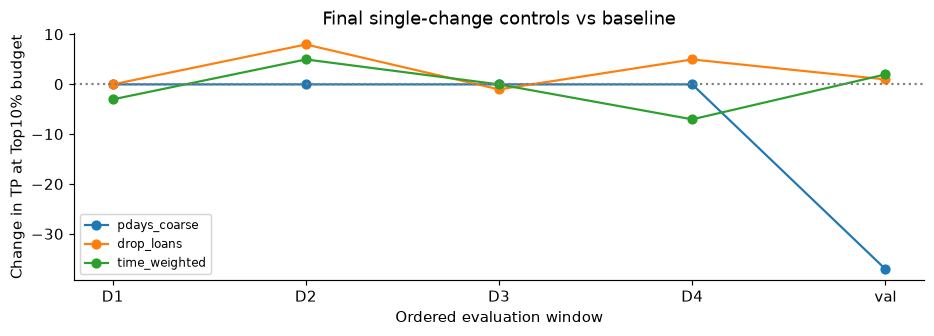

In [15]:
# Historical saved TP counts at a fixed Top10% budget.
variants=['baseline', 'pdays_coarse', 'drop_loans', 'time_weighted']
folds=['D1', 'D2', 'D3', 'D4', 'val']
pivot=pd.DataFrame([[29, 29, 29, 26], [19, 27, 19, 24], [17, 16, 17, 17], [63, 68, 63, 56], [172, 173, 135, 174]],index=folds,columns=['baseline', 'drop_loans', 'pdays_coarse', 'time_weighted'])
fig,ax=plt.subplots(figsize=(9,3.3))
for variant in variants[1:]:ax.plot(folds,pivot[variant]-pivot['baseline'],marker='o',label=variant)
ax.axhline(0,color='grey',ls=':');ax.set(ylabel='Change in TP at Top10% budget',xlabel='Ordered evaluation window',title='Final single-change controls vs baseline')
ax.legend(fontsize=8);finish(fig,'08_final_refinement')

### 最后四个单因素方案：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|drop_loans|val|top10|6178|0.1065|—|0.6606|0.2167|0.8495|0.2799|0.2629|0.2712|0.3353|0.0943|173|445|485|5075|
|pdays_coarse|val|top10|6178|0.1065|—|0.6296|0.1713|0.8372|0.2184|0.2052|0.2116|0.3421|0.0956|135|483|523|5037|
|time_weighted|val|top10|6178|0.1065|—|0.6645|0.2157|0.8498|0.2816|0.2644|0.2727|0.3333|0.0939|174|444|484|5076|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（52行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|baseline|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.4939|0.0671|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|drop_loans|D1|top10|4000|0.0655|—|0.4939|0.0671|0.8490|0.0725|0.1107|0.0876|0.2525|0.0621|29|371|233|3367|
|pdays_coarse|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|pdays_coarse|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|time_weighted|D1|fixed_0.5|4000|0.0655|0.5|0.5022|0.0697|0.9345|—|0.0000|0.0000|0.2512|0.0620|0|0|262|3738|
|time_weighted|D1|top10|4000|0.0655|—|0.5022|0.0697|0.8475|0.0650|0.0992|0.0785|0.2512|0.0620|26|374|236|3364|
|baseline|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|baseline|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5172|0.0622|0.9420|—|0.0000|0.0000|0.2215|0.0546|0|0|232|3768|
|drop_loans|D2|top10|4000|0.0580|—|0.5172|0.0622|0.8555|0.0675|0.1164|0.0854|0.2215|0.0546|27|373|205|3395|
|pdays_coarse|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|pdays_coarse|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|time_weighted|D2|fixed_0.5|4000|0.0580|0.5|0.5204|0.0625|0.9420|—|0.0000|0.0000|0.2219|0.0547|0|0|232|3768|
|time_weighted|D2|top10|4000|0.0580|—|0.5204|0.0625|0.8540|0.0600|0.1034|0.0759|0.2219|0.0547|24|376|208|3392|
|baseline|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|baseline|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.5024|0.0489|0.9515|—|0.0000|0.0000|0.1961|0.0464|0|0|194|3806|
|drop_loans|D3|top10|4000|0.0485|—|0.5024|0.0489|0.8595|0.0400|0.0825|0.0539|0.1961|0.0464|16|384|178|3422|
|pdays_coarse|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|pdays_coarse|D3|top10|4000|0.0485|—|0.4798|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|time_weighted|D3|fixed_0.5|4000|0.0485|0.5|0.4820|0.0468|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|time_weighted|D3|top10|4000|0.0485|—|0.4820|0.0468|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|baseline|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|baseline|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.5006|0.1164|0.8969|—|0.0000|0.0000|0.3517|0.0949|0|0|498|4333|
|drop_loans|D4|top10|4831|0.1031|—|0.5006|0.1164|0.8249|0.1405|0.1365|0.1385|0.3517|0.0949|68|416|430|3917|
|pdays_coarse|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|pdays_coarse|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|time_weighted|D4|fixed_0.5|4831|0.1031|0.5|0.4911|0.1067|0.8969|—|0.0000|0.0000|0.3520|0.0949|0|0|498|4333|
|time_weighted|D4|top10|4831|0.1031|—|0.4911|0.1067|0.8199|0.1157|0.1124|0.1141|0.3520|0.0949|56|428|442|3905|
|baseline|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6606|0.2167|0.8935|—|0.0000|0.0000|0.3353|0.0943|0|0|658|5520|
|pdays_coarse|val|fixed_0.5|6178|0.1065|0.5|0.6296|0.1713|0.8935|—|0.0000|0.0000|0.3421|0.0956|0|0|658|5520|
|time_weighted|val|fixed_0.5|6178|0.1065|0.5|0.6645|0.2157|0.8935|—|0.0000|0.0000|0.3333|0.0939|0|0|658|5520|
|baseline|D2|previous_window_F1|4000|0.0580|0.032257935|0.5233|0.0624|0.0670|0.0581|0.9914|0.1097|0.2217|0.0547|230|3730|2|38|
|pdays_coarse|D2|previous_window_F1|4000|0.0580|0.032257934|0.5233|0.0624|0.0670|0.0581|0.9914|0.1097|0.2217|0.0547|230|3730|2|38|
|drop_loans|D2|previous_window_F1|4000|0.0580|0.031406526|0.5172|0.0622|0.0610|0.0582|1.0000|0.1100|0.2215|0.0546|232|3756|0|12|
|time_weighted|D2|previous_window_F1|4000|0.0580|0.033223197|0.5204|0.0625|0.0688|0.0580|0.9871|0.1095|0.2219|0.0547|229|3722|3|46|
|baseline|D3|previous_window_F1|4000|0.0485|0.063964056|0.4799|0.0464|0.7208|0.0426|0.2216|0.0715|0.1964|0.0464|43|966|151|2840|
|pdays_coarse|D3|previous_window_F1|4000|0.0485|0.063964645|0.4798|0.0464|0.7208|0.0426|0.2216|0.0715|0.1964|0.0464|43|966|151|2840|
|drop_loans|D3|previous_window_F1|4000|0.0485|0.041884361|0.5024|0.0489|0.0757|0.0473|0.9433|0.0901|0.1961|0.0464|183|3686|11|120|
|time_weighted|D3|previous_window_F1|4000|0.0485|0.0660017|0.4820|0.0468|0.8095|0.0419|0.1340|0.0639|0.1964|0.0464|26|594|168|3212|
|baseline|D4|previous_window_F1|4831|0.1031|0.034532515|0.4990|0.1109|0.1174|0.1027|0.9779|0.1859|0.3519|0.0949|487|4253|11|80|
|pdays_coarse|D4|previous_window_F1|4831|0.1031|0.034532577|0.4990|0.1109|0.1174|0.1027|0.9779|0.1859|0.3519|0.0949|487|4253|11|80|
|drop_loans|D4|previous_window_F1|4831|0.1031|0.058404378|0.5006|0.1164|0.5643|0.1071|0.4398|0.1722|0.3517|0.0949|219|1826|279|2507|
|time_weighted|D4|previous_window_F1|4831|0.1031|0.035342672|0.4911|0.1067|0.1178|0.1025|0.9739|0.1854|0.3520|0.0949|485|4249|13|84|
|baseline|val|previous_window_F1|6178|0.1065|0.033314198|0.6593|0.2147|0.1131|0.1072|1.0000|0.1937|0.3354|0.0943|658|5479|0|41|
|pdays_coarse|val|previous_window_F1|6178|0.1065|0.033313945|0.6296|0.1713|0.1117|0.1071|1.0000|0.1934|0.3421|0.0956|658|5488|0|32|
|drop_loans|val|previous_window_F1|6178|0.1065|0.033436965|0.6606|0.2167|0.1133|0.1072|1.0000|0.1937|0.3353|0.0943|658|5478|0|42|
|time_weighted|val|previous_window_F1|6178|0.1065|0.034316042|0.6645|0.2157|0.1128|0.1072|1.0000|0.1936|0.3333|0.0939|658|5481|0|39|

</details>


- **删除贷款项：** val Top10由172到173；五窗3胜1平1负，但Top20由251到250，仅是小幅简化候选，不覆盖原冻结模型。
- **温和时间加权：** val多找到2个yes，但D1/D4少3/7个，五窗平均Top10 Precision略降，不默认采用。
- **pdays分箱：** 当前强正则联系LR中Top10由172降到135；success组少找到47个，nonexistent多10个，净少37。
  早期C=1的pdays分箱AP曾上升，说明编码收益依赖模型和有效正则；不是“分箱永远无效”。

早期训练前缀缺少有效历史类别，pdays方案在D1–D4几乎相同不能证明编码普遍等价。
删除贷款后nonexistent仍漏掉384个yes；现有改进没有解决大多数客户的组内区分问题。

## 11. Discussion and conclusions / 结论、局限与现实应用

**作业主结论。** 数据准备应由语义、训练分布与同模型对照共同检验。
共同unknown可放大关联；999与历史字段不能简单互换；高组内订购率不等于覆盖大量订购者；
标准化与删除列改变正则化几何，更多清理不必然提高预测能力。

**能力与边界。** 联系历史为已联系客户提供有限筛选价值，无法仅凭背景确定某人是否购买。
Precision、Recall、排序和概率质量回答不同问题；不平衡处理改变损失/概率尺度，不会创造新客户信息。
当前结果与信息不足、历史稀疏支持和跨期迁移共同存在相符，未量化三者各自因果贡献。

**严谨性限制。** 全量结构和test基础率曾被看过；后续方向是事后探索；val被反复使用；
相邻窗口共享训练历史、种子仅反映算法随机性。缺少日期、客户ID和标签成熟时间，不能证明真实时间/客户隔离。
Cramér’s V、系数及分组比例都是关联证据；没有营销随机对照，不能报告增量收益。
没有证明公平性满足任何标准：年龄、职业、学历可能影响名单，应监测分组选择率和错误，避免把群体关联当个体价值。

**面向现实的下一步。** 先补足客户ID、完整事件日期和预测时点可用的信息；采用带标签成熟间隔的滚动前向评估，
在过去窗口选择编码、校准和预算策略，最后在真正未见的未来批次确认。
监测基础率、分数与分组残差后再决定更新；近期加权和校准须另证，不应为了已知test比例强行调整。
业务若限制联系人数，固定预算比较Precision/Recall；有真实成本后再确定决策阈值，不能把F1当利润。

### Assignment alignment / 作业要求对应

| 教师要求 | 本草稿位置 |
|---|---|
| 数据画像、清理、转换及验证 | 1–4节 |
| 至少一个非显然问题与解释 | 共同缺失关联、历史字段语义、比例与覆盖、时间迁移 |
| 最少处理 vs 系统处理，同一种简单模型 | 4–6节，A/B/A_scaled及单因素对照 |
| 解释提升与退化，不以accuracy chasing为目标 | 5–10节保留失败结果与取舍 |
| 清晰代码、可重现流程和AI声明 | 可见Pipeline、CSV输入、已核验结果及本节声明 |
| ≤12分钟演示、成员贡献 | 小组自行完成，不能由本文件代替 |

### Contribution and AI declaration / 贡献与工具声明

| 成员姓名/学号 | 实际贡献 | 本人运行、理解和核对范围 |
|---|---|---|
| 待填写1 | 待填写 | 待确认 |
| 待填写2 | 待填写 | 待确认 |
| 待填写3 | 待填写 | 待确认 |
| 待填写4 | 待填写 | 待确认 |

工具使用草稿：Devin协助早期导入、EDA及准备决策；Codex协助代码、实验核查、图表与Notebook整理；
Grok提供审查建议。实际参与范围由小组确认。此次自动检查包括原件备份、核心拟合、历史数值复算和干净内核运行；
**不能代替成员对全部代码、理由和结论的理解与人工核对**，未预先声明所有成员已经完成。

依据：本地《Assignment Procedure.pdf》pp.1–3、5；数据说明来自UCI Bank Marketing原始字典；
课程Week1–4笔记用于数据准备、EDA和时间划分原则。
数据出处：[UCI数据记录](https://archive.ics.uci.edu/dataset/222/bank+marketing)、[DOI](https://doi.org/10.24432/C5K306)。

## Appendix A. Metrics and extended algorithms / 指标及扩展支线

| 指标 | 作用与解释 |
|---|---|
| Accuracy=(TP+TN)/N | 总体猜对比例；多数类占优时易掩盖低Recall |
| Precision=TP/(TP+FP) | 推荐名单里多少真订购；无人推荐时数学上未定义，表中按zero_division=0记0 |
| Recall=TP/(TP+FN) | 全部订购者找回多少 |
| F1 | Precision/Recall调和平均；不等于成本最优 |
| ROC-AUC | 随机正例得分高于随机负例的概率，平分计半；阈值不改变它 |
| AP | 按Recall增量加权的Precision；受基础率影响，不等同梯形PR-AUC |
| Brier / log loss | 概率质量，越低越好；log loss强惩罚自信错误，不含训练L2项 |
| Precision/Recall@K, lift | 固定预算下命中与覆盖；lift=Precision/该评价集基础率，不是增量收益 |
| ECE10 | 十等宽箱内预测均值与订购率偏差的加权均值；受分箱影响，不单独选模 |

**扩展算法边界：** 课程明确要求基本可解释模型。浅树属于该范围；RF、Balanced RF、HGB只作为已完成探索的附录记录，
不取代LR主实验，正式提交是否保留本附录应结合老师要求决定。
普通RF/加权RF/Balanced RF共用联系版信息和预处理；300棵树，min_samples_leaf=5，max_features=sqrt。
Balanced RF使用内部平衡抽样（all、replacement=True、bootstrap=False），与普通RF有多项机制差异。

### HGB扩展支线：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|val|top10|6178|0.1065|—|0.5907|0.1691|0.8378|0.2217|0.2082|0.2147|0.3468|0.0956|137|481|521|5039|
|personal_HGB_d2_l210|val|top10|6178|0.1065|—|0.5953|0.1721|0.8391|0.2282|0.2143|0.2210|0.3466|0.0957|141|477|517|5043|
|personal_HGB_d3_l21|val|top10|6178|0.1065|—|0.5916|0.1701|0.8398|0.2314|0.2173|0.2241|0.3469|0.0956|143|475|515|5045|
|personal_HGB_d3_l210|val|top10|6178|0.1065|—|0.5936|0.1711|0.8401|0.2330|0.2188|0.2257|0.3467|0.0956|144|474|514|5046|
|contact_HGB_d2_l21|val|top10|6178|0.1065|—|0.5906|0.1773|0.8375|0.2201|0.2067|0.2132|0.3387|0.0945|136|482|522|5038|
|contact_HGB_d2_l210|val|top10|6178|0.1065|—|0.5889|0.1711|0.8375|0.2201|0.2067|0.2132|0.3391|0.0947|136|482|522|5038|
|contact_HGB_d3_l21|val|top10|6178|0.1065|—|0.5954|0.1778|0.8394|0.2298|0.2158|0.2226|0.3380|0.0943|142|476|516|5044|
|contact_HGB_d3_l210|val|top10|6178|0.1065|—|0.5936|0.1761|0.8388|0.2265|0.2128|0.2194|0.3381|0.0944|140|478|518|5042|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（95行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5146|0.0703|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|personal_HGB_d2_l21|D1|top10|4000|0.0655|—|0.5146|0.0703|0.8510|0.0825|0.1260|0.0997|0.2526|0.0621|33|367|229|3371|
|personal_HGB_d2_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5091|0.0679|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_HGB_d2_l210|D1|top10|4000|0.0655|—|0.5091|0.0679|0.8485|0.0700|0.1069|0.0846|0.2523|0.0621|28|372|234|3366|
|personal_HGB_d3_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0697|0.9345|—|0.0000|0.0000|0.2539|0.0621|0|0|262|3738|
|personal_HGB_d3_l21|D1|top10|4000|0.0655|—|0.5129|0.0697|0.8520|0.0875|0.1336|0.1057|0.2539|0.0621|35|365|227|3373|
|personal_HGB_d3_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5023|0.0669|0.9345|—|0.0000|0.0000|0.2534|0.0621|0|0|262|3738|
|personal_HGB_d3_l210|D1|top10|4000|0.0655|—|0.5023|0.0669|0.8485|0.0700|0.1069|0.0846|0.2534|0.0621|28|372|234|3366|
|contact_HGB_d2_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5204|0.0706|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|contact_HGB_d2_l21|D1|top10|4000|0.0655|—|0.5204|0.0706|0.8510|0.0825|0.1260|0.0997|0.2520|0.0620|33|367|229|3371|
|contact_HGB_d2_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0671|0.9345|—|0.0000|0.0000|0.2522|0.0621|0|0|262|3738|
|contact_HGB_d2_l210|D1|top10|4000|0.0655|—|0.5129|0.0671|0.8470|0.0625|0.0954|0.0755|0.2522|0.0621|25|375|237|3363|
|contact_HGB_d3_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5199|0.0704|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|contact_HGB_d3_l21|D1|top10|4000|0.0655|—|0.5199|0.0704|0.8510|0.0825|0.1260|0.0997|0.2531|0.0621|33|367|229|3371|
|contact_HGB_d3_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5157|0.0691|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|contact_HGB_d3_l210|D1|top10|4000|0.0655|—|0.5157|0.0691|0.8505|0.0800|0.1221|0.0967|0.2526|0.0621|32|368|230|3370|
|personal_HGB_d2_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5071|0.0606|0.9420|—|0.0000|0.0000|0.2256|0.0550|0|0|232|3768|
|personal_HGB_d2_l21|D2|top10|4000|0.0580|—|0.5071|0.0606|0.8550|0.0650|0.1121|0.0823|0.2256|0.0550|26|374|206|3394|
|personal_HGB_d2_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5058|0.0601|0.9420|—|0.0000|0.0000|0.2252|0.0549|0|0|232|3768|
|personal_HGB_d2_l210|D2|top10|4000|0.0580|—|0.5058|0.0601|0.8555|0.0675|0.1164|0.0854|0.2252|0.0549|27|373|205|3395|
|personal_HGB_d3_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5048|0.0597|0.9420|—|0.0000|0.0000|0.2263|0.0550|0|0|232|3768|
|personal_HGB_d3_l21|D2|top10|4000|0.0580|—|0.5048|0.0597|0.8535|0.0575|0.0991|0.0728|0.2263|0.0550|23|377|209|3391|
|personal_HGB_d3_l210|D2|fixed_0.5|4000|0.0580|0.5|0.4947|0.0582|0.9420|—|0.0000|0.0000|0.2259|0.0550|0|0|232|3768|
|personal_HGB_d3_l210|D2|top10|4000|0.0580|—|0.4947|0.0582|0.8540|0.0600|0.1034|0.0759|0.2259|0.0550|24|376|208|3392|
|contact_HGB_d2_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0643|0.9420|—|0.0000|0.0000|0.2224|0.0548|0|0|232|3768|
|contact_HGB_d2_l21|D2|top10|4000|0.0580|—|0.5259|0.0643|0.8535|0.0575|0.0991|0.0728|0.2224|0.0548|23|377|209|3391|
|contact_HGB_d2_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5240|0.0629|0.9420|—|0.0000|0.0000|0.2225|0.0548|0|0|232|3768|
|contact_HGB_d2_l210|D2|top10|4000|0.0580|—|0.5240|0.0629|0.8530|0.0550|0.0948|0.0696|0.2225|0.0548|22|378|210|3390|
|contact_HGB_d3_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5069|0.0586|0.9420|—|0.0000|0.0000|0.2252|0.0551|0|0|232|3768|
|contact_HGB_d3_l21|D2|top10|4000|0.0580|—|0.5069|0.0586|0.8520|0.0500|0.0862|0.0633|0.2252|0.0551|20|380|212|3388|
|contact_HGB_d3_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5057|0.0591|0.9420|—|0.0000|0.0000|0.2241|0.0550|0|0|232|3768|
|contact_HGB_d3_l210|D2|top10|4000|0.0580|—|0.5057|0.0591|0.8500|0.0400|0.0690|0.0506|0.2241|0.0550|16|384|216|3384|
|personal_HGB_d2_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4706|0.0462|0.9515|—|0.0000|0.0000|0.1960|0.0463|0|0|194|3806|
|personal_HGB_d2_l21|D3|top10|4000|0.0485|—|0.4706|0.0462|0.8590|0.0375|0.0773|0.0505|0.1960|0.0463|15|385|179|3421|
|personal_HGB_d2_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4742|0.0451|0.9515|—|0.0000|0.0000|0.1957|0.0463|0|0|194|3806|
|personal_HGB_d2_l210|D3|top10|4000|0.0485|—|0.4742|0.0451|0.8585|0.0350|0.0722|0.0471|0.1957|0.0463|14|386|180|3420|
|personal_HGB_d3_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4518|0.0453|0.9515|—|0.0000|0.0000|0.1975|0.0464|0|0|194|3806|
|personal_HGB_d3_l21|D3|top10|4000|0.0485|—|0.4518|0.0453|0.8595|0.0400|0.0825|0.0539|0.1975|0.0464|16|384|178|3422|
|personal_HGB_d3_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4652|0.0462|0.9515|—|0.0000|0.0000|0.1962|0.0463|0|0|194|3806|
|personal_HGB_d3_l210|D3|top10|4000|0.0485|—|0.4652|0.0462|0.8600|0.0425|0.0876|0.0572|0.1962|0.0463|17|383|177|3423|
|contact_HGB_d2_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4907|0.0473|0.9515|—|0.0000|0.0000|0.1976|0.0466|0|0|194|3806|
|contact_HGB_d2_l21|D3|top10|4000|0.0485|—|0.4907|0.0473|0.8590|0.0375|0.0773|0.0505|0.1976|0.0466|15|385|179|3421|
|contact_HGB_d2_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4911|0.0472|0.9515|—|0.0000|0.0000|0.1974|0.0465|0|0|194|3806|
|contact_HGB_d2_l210|D3|top10|4000|0.0485|—|0.4911|0.0472|0.8600|0.0425|0.0876|0.0572|0.1974|0.0465|17|383|177|3423|
|contact_HGB_d3_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4908|0.0483|0.9515|—|0.0000|0.0000|0.1983|0.0467|0|0|194|3806|
|contact_HGB_d3_l21|D3|top10|4000|0.0485|—|0.4908|0.0483|0.8590|0.0375|0.0773|0.0505|0.1983|0.0467|15|385|179|3421|
|contact_HGB_d3_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4975|0.0476|0.9515|—|0.0000|0.0000|0.1978|0.0466|0|0|194|3806|
|contact_HGB_d3_l210|D3|top10|4000|0.0485|—|0.4975|0.0476|0.8605|0.0450|0.0928|0.0606|0.1978|0.0466|18|382|176|3424|
|personal_HGB_d2_l21|D4|fixed_0.5|4831|0.1031|0.5|0.6080|0.1648|0.8969|—|0.0000|0.0000|0.3545|0.0952|0|0|498|4333|
|personal_HGB_d2_l21|D4|top10|4831|0.1031|—|0.6080|0.1648|0.8352|0.1921|0.1867|0.1894|0.3545|0.0952|93|391|405|3942|
|personal_HGB_d2_l210|D4|fixed_0.5|4831|0.1031|0.5|0.6268|0.1778|0.8969|—|0.0000|0.0000|0.3547|0.0952|0|0|498|4333|
|personal_HGB_d2_l210|D4|top10|4831|0.1031|—|0.6268|0.1778|0.8377|0.2045|0.1988|0.2016|0.3547|0.0952|99|385|399|3948|
|personal_HGB_d3_l21|D4|fixed_0.5|4831|0.1031|0.5|0.5627|0.1302|0.8969|—|0.0000|0.0000|0.3563|0.0953|0|0|498|4333|
|personal_HGB_d3_l21|D4|top10|4831|0.1031|—|0.5627|0.1302|0.8249|0.1405|0.1365|0.1385|0.3563|0.0953|68|416|430|3917|
|personal_HGB_d3_l210|D4|fixed_0.5|4831|0.1031|0.5|0.5875|0.1488|0.8969|—|0.0000|0.0000|0.3549|0.0952|0|0|498|4333|
|personal_HGB_d3_l210|D4|top10|4831|0.1031|—|0.5875|0.1488|0.8319|0.1756|0.1707|0.1731|0.3549|0.0952|85|399|413|3934|
|contact_HGB_d2_l21|D4|fixed_0.5|4831|0.1031|0.5|0.4994|0.1223|0.8969|—|0.0000|0.0000|0.3520|0.0948|0|0|498|4333|
|contact_HGB_d2_l21|D4|top10|4831|0.1031|—|0.4994|0.1223|0.8203|0.1178|0.1145|0.1161|0.3520|0.0948|57|427|441|3906|
|contact_HGB_d2_l210|D4|fixed_0.5|4831|0.1031|0.5|0.4910|0.1173|0.8969|—|0.0000|0.0000|0.3525|0.0949|0|0|498|4333|
|contact_HGB_d2_l210|D4|top10|4831|0.1031|—|0.4910|0.1173|0.8187|0.1095|0.1064|0.1079|0.3525|0.0949|53|431|445|3902|
|contact_HGB_d3_l21|D4|fixed_0.5|4831|0.1031|0.5|0.4764|0.1067|0.8969|—|0.0000|0.0000|0.3537|0.0949|0|0|498|4333|
|contact_HGB_d3_l21|D4|top10|4831|0.1031|—|0.4764|0.1067|0.8191|0.1116|0.1084|0.1100|0.3537|0.0949|54|430|444|3903|
|contact_HGB_d3_l210|D4|fixed_0.5|4831|0.1031|0.5|0.4952|0.1084|0.8969|—|0.0000|0.0000|0.3524|0.0948|0|0|498|4333|
|contact_HGB_d3_l210|D4|top10|4831|0.1031|—|0.4952|0.1084|0.8207|0.1198|0.1165|0.1181|0.3524|0.0948|58|426|440|3907|
|personal_HGB_d2_l21|val|fixed_0.5|6178|0.1065|0.5|0.5907|0.1691|0.8935|—|0.0000|0.0000|0.3468|0.0956|0|0|658|5520|
|personal_HGB_d2_l210|val|fixed_0.5|6178|0.1065|0.5|0.5953|0.1721|0.8935|—|0.0000|0.0000|0.3466|0.0957|0|0|658|5520|
|personal_HGB_d3_l21|val|fixed_0.5|6178|0.1065|0.5|0.5916|0.1701|0.8935|—|0.0000|0.0000|0.3469|0.0956|0|0|658|5520|
|personal_HGB_d3_l210|val|fixed_0.5|6178|0.1065|0.5|0.5936|0.1711|0.8935|—|0.0000|0.0000|0.3467|0.0956|0|0|658|5520|
|contact_HGB_d2_l21|val|fixed_0.5|6178|0.1065|0.5|0.5906|0.1773|0.8935|—|0.0000|0.0000|0.3387|0.0945|0|0|658|5520|
|contact_HGB_d2_l210|val|fixed_0.5|6178|0.1065|0.5|0.5889|0.1711|0.8935|—|0.0000|0.0000|0.3391|0.0947|0|0|658|5520|
|contact_HGB_d3_l21|val|fixed_0.5|6178|0.1065|0.5|0.5954|0.1778|0.8935|—|0.0000|0.0000|0.3380|0.0943|0|0|658|5520|
|contact_HGB_d3_l210|val|fixed_0.5|6178|0.1065|0.5|0.5936|0.1761|0.8935|—|0.0000|0.0000|0.3381|0.0944|0|0|658|5520|
|personal_HGB_d2_l21|D4|same_window_SELECTION_ONLY|4831|0.1031|0.059577412|0.6080|0.1648|0.8868|0.3377|0.1024|0.1572|0.3545|0.0952|51|100|447|4233|
|personal_HGB_d2_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056264821|0.6268|0.1778|0.8849|0.3294|0.1124|0.1677|0.3547|0.0952|56|114|442|4219|
|personal_HGB_d3_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063264487|0.5875|0.1488|0.8884|0.3010|0.0622|0.1032|0.3549|0.0952|31|72|467|4261|
|contact_HGB_d2_l21|D4|same_window_SELECTION_ONLY|4831|0.1031|0.079726265|0.4994|0.1223|0.8953|0.3667|0.0221|0.0417|0.3520|0.0948|11|19|487|4314|
|contact_HGB_d2_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.075670849|0.4910|0.1173|0.8944|0.3125|0.0201|0.0377|0.3525|0.0949|10|22|488|4311|
|personal_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.16979007|0.5907|0.1691|0.8849|0.3037|0.0623|0.1034|0.3468|0.0956|41|94|617|5426|
|personal_HGB_d2_l21|val|previous_window_TRANSFER|6178|0.1065|0.059577412|0.5907|0.1691|0.5704|0.1279|0.5213|0.2054|0.3468|0.0956|343|2339|315|3181|
|personal_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.08842444|0.5953|0.1721|0.8762|0.3026|0.1246|0.1765|0.3466|0.0957|82|189|576|5331|
|personal_HGB_d2_l210|val|previous_window_TRANSFER|6178|0.1065|0.056264821|0.5953|0.1721|0.5283|0.1277|0.5881|0.2099|0.3466|0.0957|387|2643|271|2877|
|personal_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.099058156|0.5916|0.1701|0.8773|0.3000|0.1140|0.1652|0.3469|0.0956|75|175|583|5345|
|personal_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.32554274|0.5916|0.1701|0.8925|0.4062|0.0198|0.0377|0.3469|0.0956|13|19|645|5501|
|personal_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.099625881|0.5936|0.1711|0.8780|0.3049|0.1140|0.1659|0.3467|0.0956|75|171|583|5349|
|personal_HGB_d3_l210|val|previous_window_TRANSFER|6178|0.1065|0.063264487|0.5936|0.1711|0.6894|0.1464|0.3967|0.2138|0.3467|0.0956|261|1522|397|3998|
|contact_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.10620952|0.5906|0.1773|0.8789|0.3009|0.1033|0.1538|0.3387|0.0945|68|158|590|5362|
|contact_HGB_d2_l21|val|previous_window_TRANSFER|6178|0.1065|0.079726265|0.5906|0.1773|0.7781|0.1774|0.2979|0.2223|0.3387|0.0945|196|909|462|4611|
|contact_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.18140749|0.5906|0.1773|0.8903|0.4074|0.0669|0.1149|0.3387|0.0945|44|64|614|5456|
|contact_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.11762788|0.5889|0.1711|0.8815|0.3221|0.1018|0.1547|0.3391|0.0947|67|141|591|5379|
|contact_HGB_d2_l210|val|previous_window_TRANSFER|6178|0.1065|0.075670849|0.5889|0.1711|0.7120|0.1486|0.3602|0.2104|0.3391|0.0947|237|1358|421|4162|
|contact_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.16411052|0.5889|0.1711|0.8904|0.4112|0.0669|0.1150|0.3391|0.0947|44|63|614|5457|
|contact_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.11524085|0.5954|0.1778|0.8754|0.3056|0.1337|0.1860|0.3380|0.0943|88|200|570|5320|
|contact_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.20930004|0.5954|0.1778|0.8912|0.4079|0.0471|0.0845|0.3380|0.0943|31|45|627|5475|
|contact_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.11098352|0.5936|0.1761|0.8734|0.3000|0.1413|0.1921|0.3381|0.0944|93|217|565|5303|
|contact_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.17150682|0.5936|0.1761|0.8904|0.4112|0.0669|0.1150|0.3381|0.0944|44|63|614|5457|

</details>


RF支线未超过同信息范围联系LR的val Top10表现；BRF相对普通RF的三个种子变化为+6、−3、+4个命中，
不能称稳定改进。HGB在该受控范围内也未解决区分瓶颈。种子范围不是泛化置信区间。

## Appendix B. Optional atlas and evidence access / 可选全字段图与来源

可选图直接从当前CSV的train/val计算，不读取历史结果文件。年龄按5岁，计数按语义分组；连续宏观字段按train四分位点分组，并显式覆盖超出训练范围的值。
下方开关默认关闭以保持文件清爽；打开后重画每个字段的train/val组内比例与val组人数。
连续宏观值按train规则显示，age按5岁；duration仅为事后描述、不能进入模型。

In [16]:
def display_groups(field):
    if field=='age':
        return [pd.cut(d[field],np.arange(15,105,5),right=False).astype(str) for d in [train,val]]
    if field in ['campaign','previous']:
        return [d[field].map(lambda x:str(x) if x<4 else '4+').astype(str) for d in [train,val]]
    if field=='pdays':
        return [pd.cut(d[field],[-np.inf,0,7,30,998,np.inf],
                       labels=['0','1–7','8–30','31–998','999']).astype(str) for d in [train,val]]
    if pd.api.types.is_numeric_dtype(train[field]):
        inside=np.unique(train[field].quantile([.25,.5,.75]).to_numpy())
        bins=np.r_[-np.inf,inside,np.inf]
        return [pd.cut(d[field],bins).astype(str) for d in [train,val]]
    return [d[field].astype(str) for d in [train,val]]

if SHOW_ALL_20_FIELDS:
    for field in train.columns.drop('y'):
        series=display_groups(field);fig,axes=plt.subplots(1,2,figsize=(10,4))
        counts=[]
        for split,d,g in zip(['train','val'],[train,val],series):
            tab=pd.DataFrame({'group':g,'yes':d.y.eq('yes').astype(int)}).groupby('group',sort=True).yes.agg(['size','mean'])
            axes[0].plot(tab.index,tab['mean']*100,marker='o',label=split,color=COLORS[split])
            axes[0].axhline(d.y.eq('yes').mean()*100,color=COLORS[split],ls=':',alpha=.6)
            if split=='val':axes[1].bar(tab.index,tab['size'],color=COLORS[split])
        axes[0].set(title=field,xlabel='Group',ylabel='Yes rate (%)');axes[0].legend()
        axes[1].set(title='Validation group size',ylabel='N')
        for ax in axes:ax.tick_params(axis='x',rotation=70)
        finish(fig,'optional_'+field)
else:
    print('Optional 20-field plots are off; set SHOW_ALL_20_FIELDS=True to regenerate from CSV.')


Optional 20-field plots are off; set SHOW_ALL_20_FIELDS=True to regenerate from CSV.


**复现边界。** 本文件默认重新拟合8个核心/联系模型；扩展实验使用本地已完成预测重新核对后写入正文的结果表。
运行全部不重新搜索或重训数百个历史模型，正文表格也不会被新结果静默覆盖。全部扩展实验的从头重训工具仍保存在本地完整项目的 `repro/`，与这份只依赖原始CSV的提交阅读稿分开。

历史test已被多次查看；此处的测试表不能称为新的独立盲测。开发阶段各次试错仍按原协议区分，失败结果不删除。


### 完整指标如何解读

所有候选都补齐ROC-AUC、AP、Accuracy、Precision、Recall、F1、log loss、Brier和TN/FP/FN/TP。
Top10表可直接比较同一个窗口、同样联系人数下“找到多少人、误报多少人”；0.5表说明固定默认阈值的行为；原F1/Precision规则说明历史实际选择的取舍。
模型之间不能只凭Accuracy判断优劣，更不能跨不同基础率的窗口把Precision差异全归因于模型改进。
